# Phase 3 — Green onion quality and storage time from photographs of the plant alone

**Versión 2 (re-análisis desde las imágenes).** Responde a la revisión: las fotos se reprocesan para que el
modelo vea **solo la planta** (sin piso, paredes, objetos ni reflejos), con el **color corregido por sesión**
usando la mesa como referencia neutra y **sin tamaños absolutos** (no hay referencia de escala). Los modelos
se validan dejando fuera sesiones, días de captura, tiempos, genotipos y grupos de fotografía completos; el plan
de análisis se fijó **antes** de ver los resultados (`PLAN_ANALISIS_v2.md`, sección 0).

**Qué estima la foto, con los datos actuales.**
- **La clase visual del pseudotallo** (On-Grade, Minor defects, Major defects, Decay): es la única etiqueta
  propia de cada pseudotallo fotografiado.
- **La edad de la muestra** (días desde la cosecha), útil cuando no se conoce.
- **El GQI y la vida útil restante de la celda** genotipo × tiempo. Son etiquetas de celda: los pseudotallos
  fotografiados no son las plantas medidas en el laboratorio. Se evalúan por celda y siempre contra las
  referencias que solo usan los días de almacenamiento o el genotipo.

## Cómo está organizado

El notebook sigue **la explicación**, en el orden en que un lector la necesita: primero el material, luego el
proceso (qué ve el modelo, cómo se entrena y se prueba, dónde funciona) y al final el resultado de la fase. Cada
sección empieza diciendo **qué pregunta responde, qué paneles produce, por qué esos paneles van juntos y a qué figura
del artículo o del suplemento van**. Cada panel sale por separado, del mismo tamaño (1650 × 1650 px, cuadrado,
300 dpi), con letra grande y **sin letra de panel**, listo para diagramar; debajo se imprime su ubicación («Fig. 5, panel A»)
y su nota.

| Sección | Pregunta | Figuras del artículo | Suplemento |
|---|---|---|---|
| 1. Datos y diseño | ¿De dónde salen las fotos y las etiquetas? | — | Fig. S1 · detalle D1–D3 |
| 2. De la foto a la planta | ¿Qué ve el modelo? | **Fig. 5** (A–C) | detalle D4, D5, D14 |
| 3. Modelos y validación | ¿Qué se entrena y cómo se prueba? | **Fig. 6** (A–C) | Fig. S2B · detalle D10 |
| 4. Desempeño en cada protocolo | ¿Dónde funciona la foto y dónde no? | **Fig. 7** (A–D) | detalle D6–D9 |
| 5. Resultado de la fase | ¿Qué dice una foto de un genotipo nuevo? | **Fig. 8** (A–D) | Fig. S2A, S2C–E · detalle D11–D13 |
| 6. Qué mira el modelo | ¿Usa el tejido? | — | Fig. S3 |
| 7. Limitaciones y ensayo nuevo | ¿Qué no se puede afirmar? | — | — |
| 8. Tablas del artículo | ¿Qué números van al artículo? | — | **Tablas 1–3** (Material suplementario 6) |

Las Figs. 5–7 explican el proceso; la Fig. 8 es el resultado de la fase. Las tablas de detalle (D1–D14) salen en la sección donde se calculan y se resumen en las **tres tablas del artículo** (sección 8).

**Datos.** Todo lo que el notebook lee está en el repositorio, en `data/phase3/` (otra carpeta con la variable
`GREEN_ONION_DATA`): `dataset_final.csv` (16 396 fotos, etiquetas y rasgos de laboratorio de su celda),
`cache_embeddings_cnn.npz` y `cache/` (EXIF, tramos y resultados de la versión anterior, para compararla). Las
**cachés v2** están en `data/phase3/cache_v2/` (otra carpeta con `GREEN_ONION_V2`): `features_v2.npz`, `meta_v2.csv`,
`examples_v2.npz`, `fig5b_crops.npz`, `validation_v2.pkl.gz`, `ladder_v2.pkl`, `occlusion_v2.npz`; al final se
guarda `tables_v2.pkl`. El laboratorio es `data/Phase_2_Physicochemical.xlsx`. Las fotos (`GREEN_ONION_PHOTOS`) y
`crops.npy` (2,3 GB) solo se necesitan para rehacer las cachés con `scripts/phase3v2_*.py`; sin ellas el notebook
da los mismos números y figuras.

## 0. Configuración, datos y plan de análisis

In [1]:
from pathlib import Path
from io import BytesIO
import os, pickle, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Image, display, Markdown

# ---- recalcular (False = leer las cachés)
RUN_METADATA = False      # EXIF de las 16 396 fotos (necesita las fotos)
RUN_TRAMOS = False        # segmentación de pseudotallos (~2 min)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = Path(os.environ.get("GREEN_ONION_DATA", ROOT / "data" / "phase3"))
V2 = Path(os.environ.get("GREEN_ONION_V2", DATA / "cache_v2"))
PHOTOS = Path(os.environ.get("GREEN_ONION_PHOTOS", DATA / "photos"))
CACHE = DATA / "cache"
LAB_FILE = ROOT / "data" / "Phase_2_Physicochemical.xlsx"


def load_pickle(path):
    """Lee un .pkl o, si no está, su versión comprimida .pkl.gz (así va en el repositorio el más grande)."""
    path = Path(path)
    if path.exists():
        with open(path, "rb") as fh:
            return pickle.load(fh)
    import gzip
    with gzip.open(path.with_name(path.name + ".gz"), "rb") as fh:
        return pickle.load(fh)


# ---- estilo (el mismo de las Fases 1 y 2)
DAH = {1: 2, 2: 6, 3: 10, 4: 14}
DAH_COLOR = {2: "#1565C0", 6: "#5E9BD1", 10: "#F4A340", 14: "#C62828"}
CLASSES = ["On-Grade", "Minor defects", "Major defects", "Decay"]
CLASS_COLOR = dict(zip(CLASSES, ["#2E7D32", "#9CCC65", "#F9A825", "#8D4E2A"]))
MODEL_COLOR = {"CTD-GB v2": "#1F4E8C", "CNN-ridge": "#D97B00", "Ensemble": "#6A1B9A", "CNN-MTL (v1, full photo)": "#9E9E9E",
               "Trivial": "#BDBDBD", "DAH only": "#C62828", "Genotype only": "#7E57C2", "Genotype + DAH": "#2E7D32"}
INK, MUTED = "#000000", "#5F6B76"
PANEL = (5.5, 5.5)
FS = {"title": 22, "label": 20, "tick": 18, "value": 16, "legend": 15}
mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": FS["tick"], "axes.labelsize": FS["label"], "axes.titlesize": FS["title"],
    "xtick.labelsize": FS["tick"], "ytick.labelsize": FS["tick"],
    "legend.fontsize": FS["legend"], "legend.title_fontsize": FS["legend"],
    "axes.edgecolor": INK, "axes.linewidth": 1.2, "lines.linewidth": 2.4, "lines.markersize": 10,
    "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.width": 1.2, "ytick.major.width": 1.2, "xtick.major.size": 6, "ytick.major.size": 6,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 300, "figure.constrained_layout.use": True,
})


def panel(**kw):
    return plt.subplots(figsize=PANEL, **kw)


def mostrar(fig):
    """Muestra el panel a 300 dpi y tamaño fijo (1650 x 1650 px, cuadrado), sin recortar bordes."""
    buf = BytesIO()
    with mpl.rc_context({"savefig.bbox": "standard"}):
        fig.savefig(buf, format="png", dpi=300, facecolor="white")
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="png", width=650))


FIGID = {"id": ""}


def titulo(ax, ident):
    """ident = «5A» (Fig. 5, panel A del artículo) o «S1A» (Fig. S1, panel A). El panel sale sin letra (se pone al
    diagramar); la ubicación se imprime en la nota."""
    FIGID["id"] = ident


def nota(*lineas):
    fid = FIGID["id"]
    cabeza = f"Fig. {fid[:-1]}, panel {fid[-1]}" if fid else "Nota de la figura"
    print(cabeza + ":\n" + "\n".join("  · " + l for l in lineas))
    FIGID["id"] = ""


def leyenda_arriba(fig, ax, handles=None, ncol=2, **kw):
    """Leyenda en una franja reservada encima del panel (no tapa el título ni los datos)."""
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    else:
        labels = [h.get_label() for h in handles]
    kw = {"frameon": False, "columnspacing": 0.8, "handlelength": 1.2, "handletextpad": 0.4, **kw}
    fig.legend(handles, labels, loc="outside upper center", ncol=ncol, **kw)


# ---- fotos
df = pd.read_csv(DATA / "dataset_final.csv")
df["geno"] = df["genotipo"].astype(str).replace({"CUNSBRO048": "CUNSBR048"})   # mismo nombre que el laboratorio
df["folder"] = df["ruta"].str.rsplit("\\", n=1).str[0].str.split("\\").str[-3:].str.join("/")
df["class"] = df["calidad_idx"].map(dict(enumerate(CLASSES)))
df["block"] = df["geno"] + " · T" + df["tiempo"].astype(str)
print(f"{len(df):,} fotos · {df['geno'].nunique()} genotipos · {df['tiempo'].nunique()} tiempos · "
      f"{df['folder'].nunique()} carpetas (tiempo × clase × genotipo)")

# ---- laboratorio (la columna Experimento es la cosecha)
lab = pd.read_excel(LAB_FILE, sheet_name="Sheet1")
lab["Genotipo"] = lab["Genotipo"].astype(str)
print(f"laboratorio: {len(lab)} plantas · cosechas {sorted(int(x) for x in lab['Experimento'].unique())} · "
      f"{lab.groupby(['Genotipo', 'Tiempo']).size().min()}–{lab.groupby(['Genotipo', 'Tiempo']).size().max()} plantas por celda")

16,396 fotos · 10 genotipos · 4 tiempos · 160 carpetas (tiempo × clase × genotipo)


laboratorio: 406 plantas · cosechas [1, 2] · 10–11 plantas por celda


### Plan de análisis (fijado antes de ver los resultados)

El plan completo está en `PLAN_ANALISIS_v2.md` y se reproduce abajo, con los cambios posteriores y su motivo.
Lo esencial: modelos, hiperparámetros, protocolos, métricas, unidad de evaluación y referencias se fijaron
antes de procesar las imágenes y antes de entrenar; ningún resultado de prueba se usó para elegir nada.

In [2]:
plan = (V2.parent / "PLAN_ANALISIS_v2.md") if (V2.parent / "PLAN_ANALISIS_v2.md").exists() else (ROOT / "docs" / "PLAN_ANALISIS_v2.md")
display(Markdown(plan.read_text(encoding="utf-8")))

# Fase 3 v2 — plan de análisis fijado antes de ver resultados

Fecha de redacción: 9 nov 2026, antes de procesar las imágenes v2 y antes de entrenar ningún modelo v2.
Cualquier cambio posterior a este plan se anota al final, con fecha y motivo.

## 1. Datos y etiquetas

- 16 396 fotos, 160 carpetas (sesiones) = tiempo × clase × genotipo; cosecha 2; 10 genotipos; 4 tiempos.
- DAH = el tiempo de la carpeta (2, 6, 10, 14). Las fechas EXIF se usan solo para identificar el día de captura (8 días = grupo de fotografía × tiempo).
- Clase visual (On-Grade, Minor defects, Major defects, Decay): etiqueta de cada pseudotallo (carpeta); es la única etiqueta individual.
- GQI (cosecha 2, fórmula de la Fase 2) y vida útil restante (t50 en línea de la Fase 1, tope 14 d, menos DAH): etiquetas de celda genotipo × tiempo (40 valores). Se evalúan en la celda.

## 2. Procesamiento de las imágenes (igual para todas las fotos, sin mirar etiquetas)

1. Segmentación de la planta con la función ya publicada (`segment`), control de calidad automático y revisión visual de una muestra.
2. Corrección de color por sesión: ganancia por canal en RGB lineal que lleva la mediana de la mesa (gris oscuro, neutra) de la sesión a la mediana global de la mesa.
3. Recorte solo de la planta; todo lo de fuera de la máscara pasa a gris neutro. Piso, paredes y objetos desaparecen.
4. Alineación: eje mayor horizontal; el extremo más blanco (base del pseudotallo) a la izquierda.
5. Sin referencia de escala: la planta se normaliza a una longitud fija; no se usan tamaños absolutos en píxeles, solo proporciones.
6. Descriptores (≈100): color Lab (media, DE, percentiles), fracciones de color definidas a priori (verde, amarillo verdoso, amarillo, pardo, pálido, oscuro), perfil a lo largo del eje en 10 tramos (anchura relativa, L*, a*, b*), forma sin escala, textura (GLCM, LBP).
7. Embedding ResNet18 (ImageNet, congelada) del recorte alineado de 448 × 112 px, promedio de 4 volteos.

## 3. Modelos (hiperparámetros fijados aquí, no se ajustan con los datos de prueba)

- **M1 · CTD-GB v2**: descriptores → HistGradientBoosting (max_iter 300, learning_rate 0.05, max_depth 4, l2 1.0, min_samples_leaf 40).
- **M2 · CNN-ridge**: embedding ResNet18 estandarizado → Ridge (regresión) / regresión logística multinomial (clases); la regularización se elige por validación cruzada interna agrupada por la unidad del protocolo, solo con datos de entrenamiento.
- **Ensamble** (modelo principal): media simple de M1 y M2 (probabilidades en las clases).
- Entrenamiento con todas las fotos, ponderadas para que cada sesión pese lo mismo.
- **Con DAH conocido**: las mismas variantes con el DAH como entrada adicional (valor añadido de la foto).
- Comparación histórica: CNN-MTL de la versión anterior (foto completa), predicciones ya calculadas.

## 4. Variables respuesta y unidad de evaluación

| Salida | Unidad principal | Otras unidades |
|---|---|---|
| Clase visual | sesión (media de probabilidades) | foto, pseudotallo |
| DAH (edad de la muestra) | celda / muestra | foto, pseudotallo; curva según k pseudotallos |
| GQI | celda (40) | foto |
| Vida útil restante | celda (40) | foto; decisión |

## 5. Protocolos de validación

- P1 sesión (bloque genotipo × tiempo, 5 pliegues, 5 repeticiones con semillas 42–46).
- P1 día de captura (8 pliegues).
- P2 tiempo no visto (4 pliegues).
- **P3 genotipo no visto (10 pliegues) — resultado principal de generalización.**
- P4 grupo de fotografía: entrenar con el grupo A (5 genotipos fotografiados en sus propios días) y probar en el B, y al revés (genotipos y días de foto no vistos).
- Escalera de fuga: foto al azar, pseudotallo, sesión, bloque, día, P2, P3.

Referencias: trivial, solo DAH, solo genotipo, genotipo + DAH.

## 6. Métricas e inferencia

- Regresión: R², MAE; clases: exactitud, kappa ponderado cuadrático, exactitud ±1 clase.
- IC 95 % por bootstrap de conglomerados (2000): bloques en P1, P1 día y P2; genotipos en P3; en P4 no se calcula IC (2 pliegues), se reporta por grupo de fotografía.
- Diferencias pareadas (modelo − referencia) con IC por el mismo bootstrap: es la prueba de si la foto aporta.
- Conformal partido, α = 0.10, calibración agrupada por la unidad del protocolo.
- Decisión: rechazo = vida útil restante ≤ 0; matriz aceptado/rechazado, curvas de costo (FA/FR 1–10), regla por días, decisión con intervalo conformal.

## 7. Controles de atajo

- Comparación de la escalera de fuga v2 frente a la versión con foto completa.
- Oclusión sobre el recorte para ver qué partes de la planta usa M2.
- Validación del color de la cámara (crudo y corregido) frente al colorímetro, por celda.

## 8. Lo que no se hará

No se eligen hiperparámetros, protocolos, genotipos ni umbrales mirando los resultados de prueba. Todo resultado se reporta, también los negativos.

## Cambios posteriores al plan

Todos hechos el 9 nov 2026, **antes** de entrenar cualquier modelo v2 y sin ver ningún resultado de validación.

1. **Segmentación (paso 2.1).** La revisión visual de 44 fotos estratificadas por clase mostró que la función
   publicada `segment` fallaba: con un degradado de luz sobre la mesa dejaba la planta fuera; además metía
   cuñas del borde de la mesa y franjas de pared. Se reemplazó por `segment_v2` (fondo de la mesa modelado con
   una superficie cuadrática, envolvente convexa de la mesa, exclusión de sombras y reflejos, y selección del
   componente principal por color). Se revisó de nuevo en 32 fotos nuevas antes de procesar todas.
   Una primera corrida completa se detuvo en la sesión 28 porque la revisión de 32 recortes al azar y de los
   16 casos extremos mostró (i) plantas muy cercanas a la cámara que parten la mesa en dos (solo se tomaba una
   mitad) y (ii) objetos ajenos (lápiz, regla, ladrillos) sumados como fragmentos. Se corrigió: la mesa es la
   unión de las regiones oscuras y neutras grandes (≥ 15 % de la mayor); los fragmentos y el componente
   principal deben tener color de planta (≥ 30 % de píxeles con C\* ≥ 12 y tono 65–150°); en el 5 % exterior
   de la foto se quitan los píxeles pardos, anaranjados o rojos. Todo se reprocesó desde cero.
   Una segunda corrida se detuvo en la sesión 60: en la muestra al azar apareció **una tarjeta rotulada (fecha y
   genotipo) tomada como planta** y, en otra foto, **una bandeja de cebollas al fondo** sumada a la planta; también
   seguían entrando ladrillos de la pared en el borde de la mesa. Reglas finales: el componente principal se
   pondera por cercanía al centro de la foto; los fragmentos deben medir menos del doble del principal, no ser
   objetos compactos sin color de planta (solidez > 0,85), no tener el centro en el 5 % exterior de la foto ni
   estar sobre el borde de la mesa, y los pequeños deben estar a ≤ 4 % del ancho. Se verificó en los 9 casos
   problemáticos y en 48 fotos al azar estratificadas; se reprocesó todo desde cero.
2. **Orientación (paso 2.4).** «Extremo más blanco» se cambió por «extremo menos verde» (a\* > −6), porque la
   base podrida es parda y no blanca.
3. **Rejillas de regularización de M2**, no fijadas en el plan: Ridge α ∈ 10^[−2, 5] (15 valores), logística
   C ∈ 10^[−5, 0] (6 valores); pesos que igualan las sesiones.
4. **P4 (grupo de fotografía)**: la calibración conformal y la CV interna se separan por genotipo.
5. **Escalera de fuga**: los peldaños bloque, día, P2 y P3 son las mismas predicciones de la validación
   principal; solo foto al azar, pseudotallo y sesión se corren aparte.
6. **Control de calidad de la máscara** (sin etiquetas, antes de validar): una foto cuyo recorte mide menos del
   30 % del largo mediano de la planta se trata como fallo de segmentación y se excluye (1 de 4 123 fotos en la
   revisión de las primeras 40 sesiones). La revisión al azar de 48 recortes de la corrida final mostró 46
   limpios y 2 con un trozo de lápiz junto a la planta (se deja como limitación; es propio de la sesión).
7. **DINOv2** no se usó (requería descargar código externo); M2 usa solo ResNet18, como estaba en el plan.
8. **Terminología** (10 nov, después de los resultados; no cambia ningún análisis): los dos grupos de cinco
   genotipos fotografiados en días distintos, antes «lotes de captura», se llaman **grupos de fotografía**, y P4
   se describe como «genotipos y días de foto no vistos»; el producto evaluado, antes «lote», se llama **muestra**.


# 1. Datos y diseño — de dónde salen las fotos y las etiquetas

**Qué responde.** Cómo se tomaron las fotos (sesiones, días, grupos de fotografía), con qué se etiquetan y cuántos
pseudotallos hay. Prepara todo lo demás: aquí se definen el DAH, la vida útil restante, el GQI y la clase visual.

**Paneles y por qué van juntos** → **Fig. S1** (material suplementario). Los cuatro describen el material, no el
modelo: **A** balance de las cuatro clases en cada tiempo (por diseño); **B** fechas de foto según la cámara para los
dos grupos de fotografía; **C** GQI de la cosecha fotografiada frente al de la Fase 2; **D** GQI de cada planta dentro
de su celda (cuánto puede explicar, como máximo, un predictor que solo conoce la celda).

**Tablas de detalle:** D1 diseño de captura · D2 vida útil por genotipo · D3 pseudotallos; las tres se resumen en la **Tabla 1** del artículo (sección 8).

### 1.1 Diseño de captura

La fecha y hora de cada foto salen de sus metadatos EXIF (una sola cámara, Canon EOS Rebel T6). Cada
**carpeta** (tiempo × clase × genotipo) es una **sesión**: unas 100 fotos en ráfaga (0–1 s entre disparos),
tomadas en pocos minutos; las cuatro clases de un genotipo se fotografiaron seguidas el mismo día. Por eso
la unidad independiente no es la foto sino la sesión, y la validación debe dejar fuera sesiones completas
(sección 3). Las **clases están balanceadas por diseño** (~25 % cada una en cada genotipo y tiempo): son
categorías de defecto elegidas al fotografiar, no la frecuencia natural del deterioro.

In [3]:
def read_exif(paths):
    from PIL import Image as PILImage
    rows = []
    for p in paths:
        ex = PILImage.open(p).getexif(); sub = ex.get_ifd(0x8769)
        rows.append({"datetime": sub.get(36867) or ex.get(306), "exposure_s": sub.get(33434), "iso": sub.get(34855)})
    return pd.DataFrame(rows)


def photo_path(ruta):
    parts = Path(str(ruta).replace("\\", "/")).parts
    return PHOTOS.joinpath(*parts[parts.index("GreenOnionCap3") + 1:])


if RUN_METADATA:
    meta = read_exif([photo_path(r) for r in df["ruta"]])
    meta.insert(0, "ruta", df["ruta"]); meta.to_csv(CACHE / "photo_metadata.csv", index=False)
meta = pd.read_csv(CACHE / "photo_metadata.csv")
assert (meta["ruta"] == df["ruta"]).all()
df["shot_time"] = pd.to_datetime(meta["datetime"], format="%Y:%m:%d %H:%M:%S")
df["capture_day"] = df["shot_time"].dt.date
LOT_A = sorted(df.loc[df["capture_day"] == df["capture_day"].min(), "geno"].unique())
df["lot"] = np.where(df["geno"].isin(LOT_A), "A", "B")
df["day_group"] = df["lot"] + " · T" + df["tiempo"].astype(str)

sess = df.groupby(["tiempo", "class", "geno"]).agg(photos=("ruta", "size"), start=("shot_time", "min"),
                                                     end=("shot_time", "max"), day=("capture_day", "first"))
sess["minutes"] = (sess["end"] - sess["start"]).dt.total_seconds() / 60
t1 = df.groupby("lot")["shot_time"].transform("min").dt.normalize()
df["days_from_T1"] = (df["shot_time"].dt.normalize() - t1).dt.days
cap = (df.groupby(["lot", "tiempo"])
         .agg(genotypes=("geno", lambda s: ", ".join(sorted(s.unique()))), capture_date=("capture_day", "first"),
              days_from_T1=("days_from_T1", "first"), sessions=("folder", "nunique"), photos=("ruta", "size"))
         .reset_index())
cap.insert(2, "DAH (label)", cap["tiempo"].map(DAH))
TABLE_S5A = cap.rename(columns={"lot": "Photo group", "tiempo": "Time", "genotypes": "Genotypes",
                                "capture_date": "Capture date (EXIF)", "days_from_T1": "Days after T1",
                                "sessions": "Sessions", "photos": "Photos"})
print("Detail table D1 (→ Table 1). Capture design from the EXIF metadata of the photographs")
display(TABLE_S5A)
print(f"sesiones: {len(sess)} · fotos por sesión {sess['photos'].median():.0f} (rango {sess['photos'].min()}–{sess['photos'].max()}) · "
      f"duración mediana {sess['minutes'].median():.1f} min · cada sesión en un solo día: {bool((df.groupby('folder')['capture_day'].nunique() == 1).all())}")
print("Nota: los días después de T1 según la cámara no coinciden con 2, 6, 10 y 14 DAH en T2 y T3 (se usan los DAH de las carpetas).")

Detail table D1 (→ Table 1). Capture design from the EXIF metadata of the photographs


,Photo group,Time,DAH (label),Genotypes,Capture date (EXIF),Days after T1,Sessions,Photos
0,A,1,2,"91400028, 91400035, ANTSON013, CUNSBR048, NDSC...",2026-02-11,0,20,2044
1,A,2,6,"91400028, 91400035, ANTSON013, CUNSBR048, NDSC...",2026-02-13,2,20,2121
2,A,3,10,"91400028, 91400035, ANTSON013, CUNSBR048, NDSC...",2026-02-18,7,20,2040
3,A,4,14,"91400028, 91400035, ANTSON013, CUNSBR048, NDSC...",2026-02-23,12,20,2015
4,B,1,2,"91400070, 91400071, ANTSNC003, ANTSRO029, ANTS...",2026-02-25,0,20,2079
5,B,2,6,"91400070, 91400071, ANTSNC003, ANTSRO029, ANTS...",2026-03-03,6,20,2038
6,B,3,10,"91400070, 91400071, ANTSNC003, ANTSRO029, ANTS...",2026-03-04,7,20,2026
7,B,4,14,"91400070, 91400071, ANTSNC003, ANTSRO029, ANTS...",2026-03-09,12,20,2033


sesiones: 160 · fotos por sesión 101 (rango 61–200) · duración mediana 1.4 min · cada sesión en un solo día: True
Nota: los días después de T1 según la cámara no coinciden con 2, 6, 10 y 14 DAH en T2 y T3 (se usan los DAH de las carpetas).


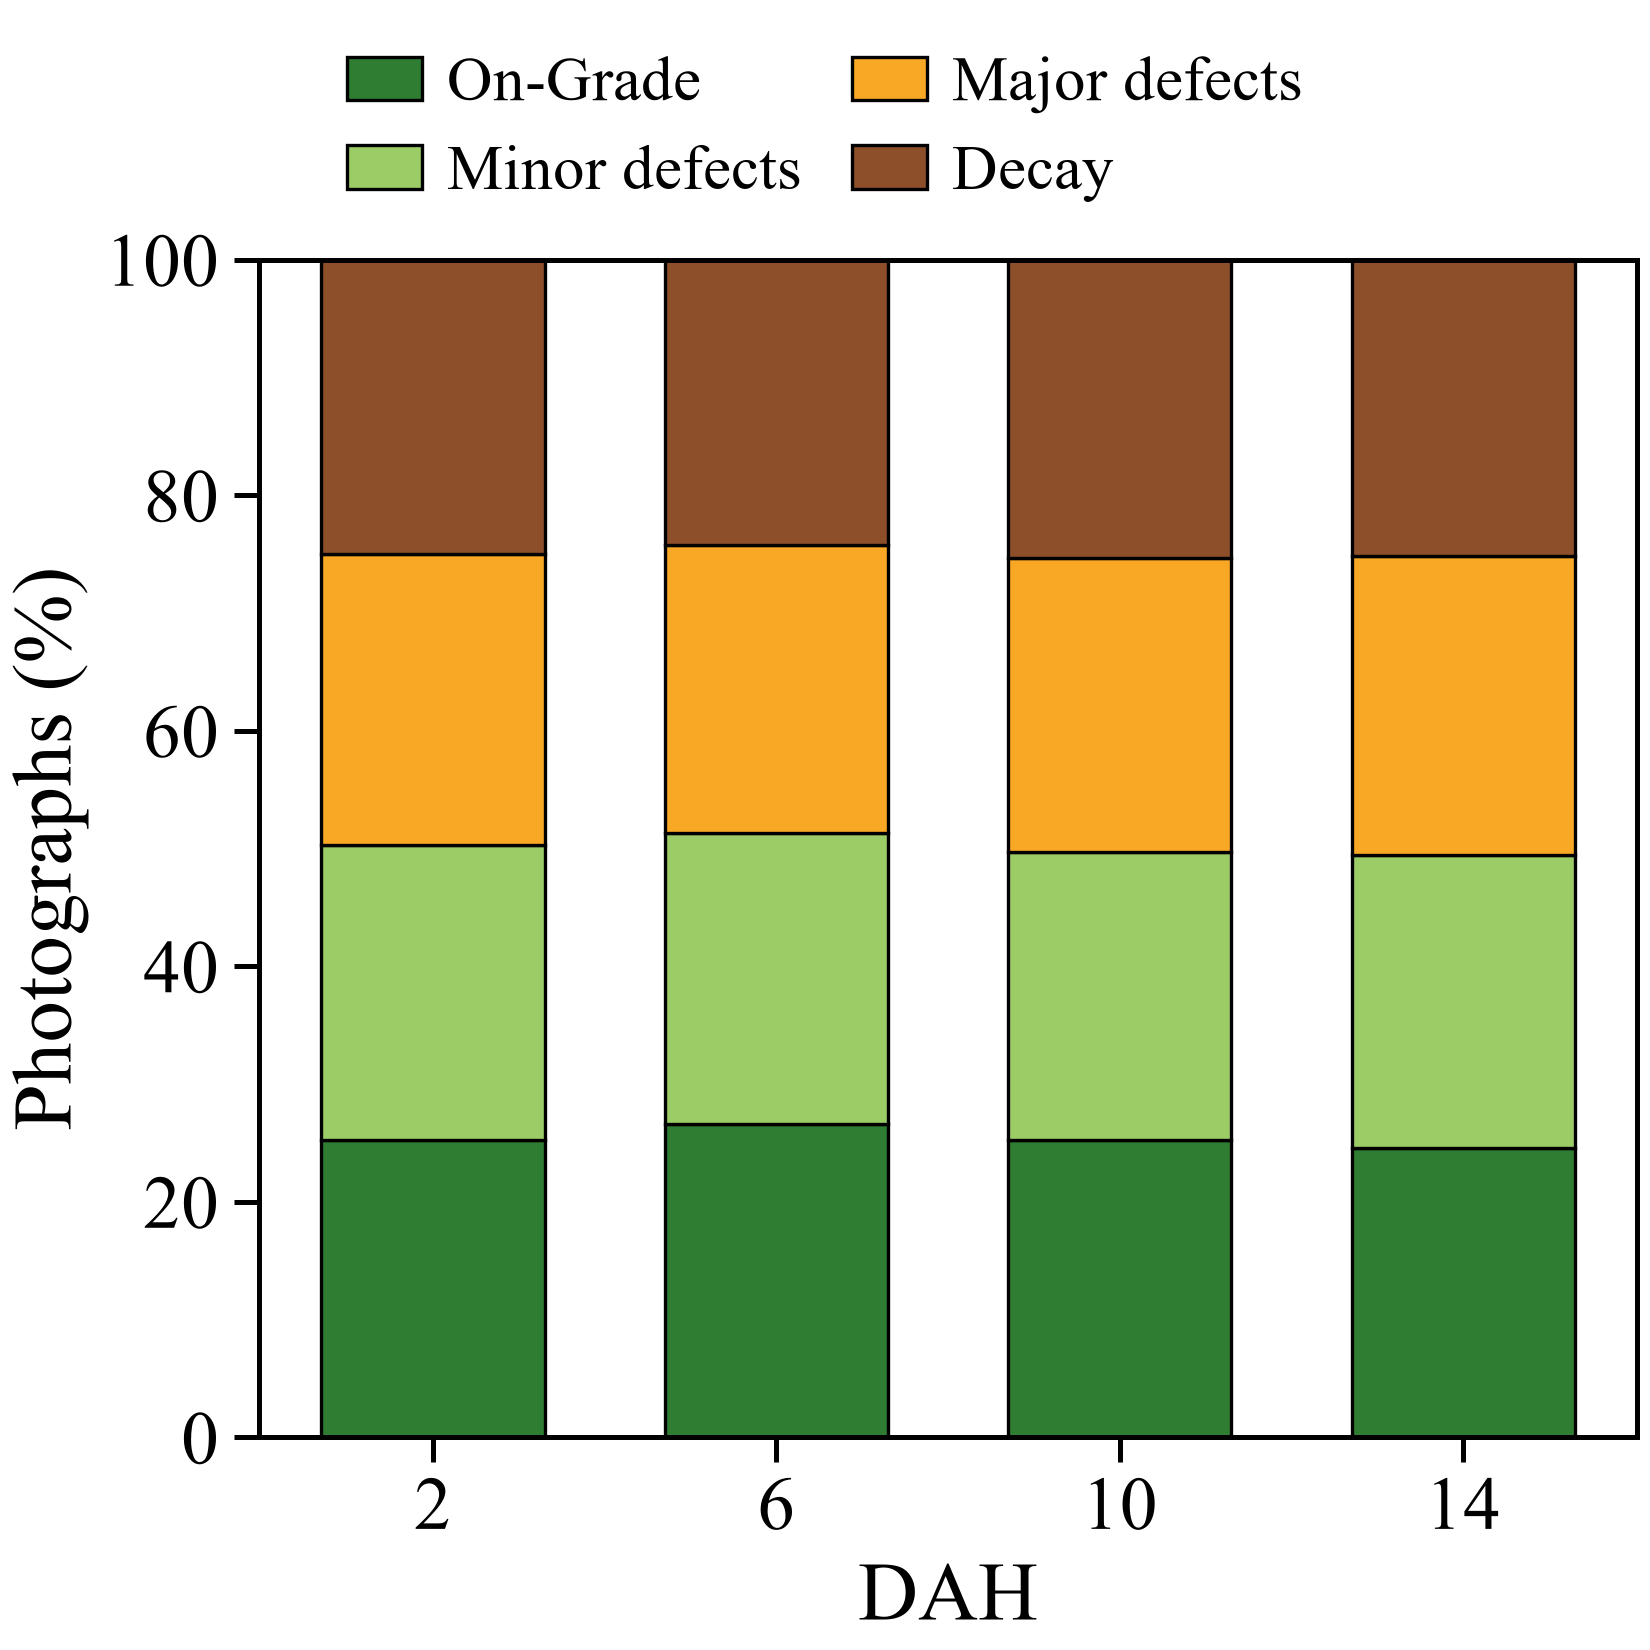

Fig. S1, panel A:
  · share of the four visual classes at each storage time (16,396 photographs)
  · each genotype has ~100 photographs per class at every time: the classes are balanced by design, not by the natural course of deterioration


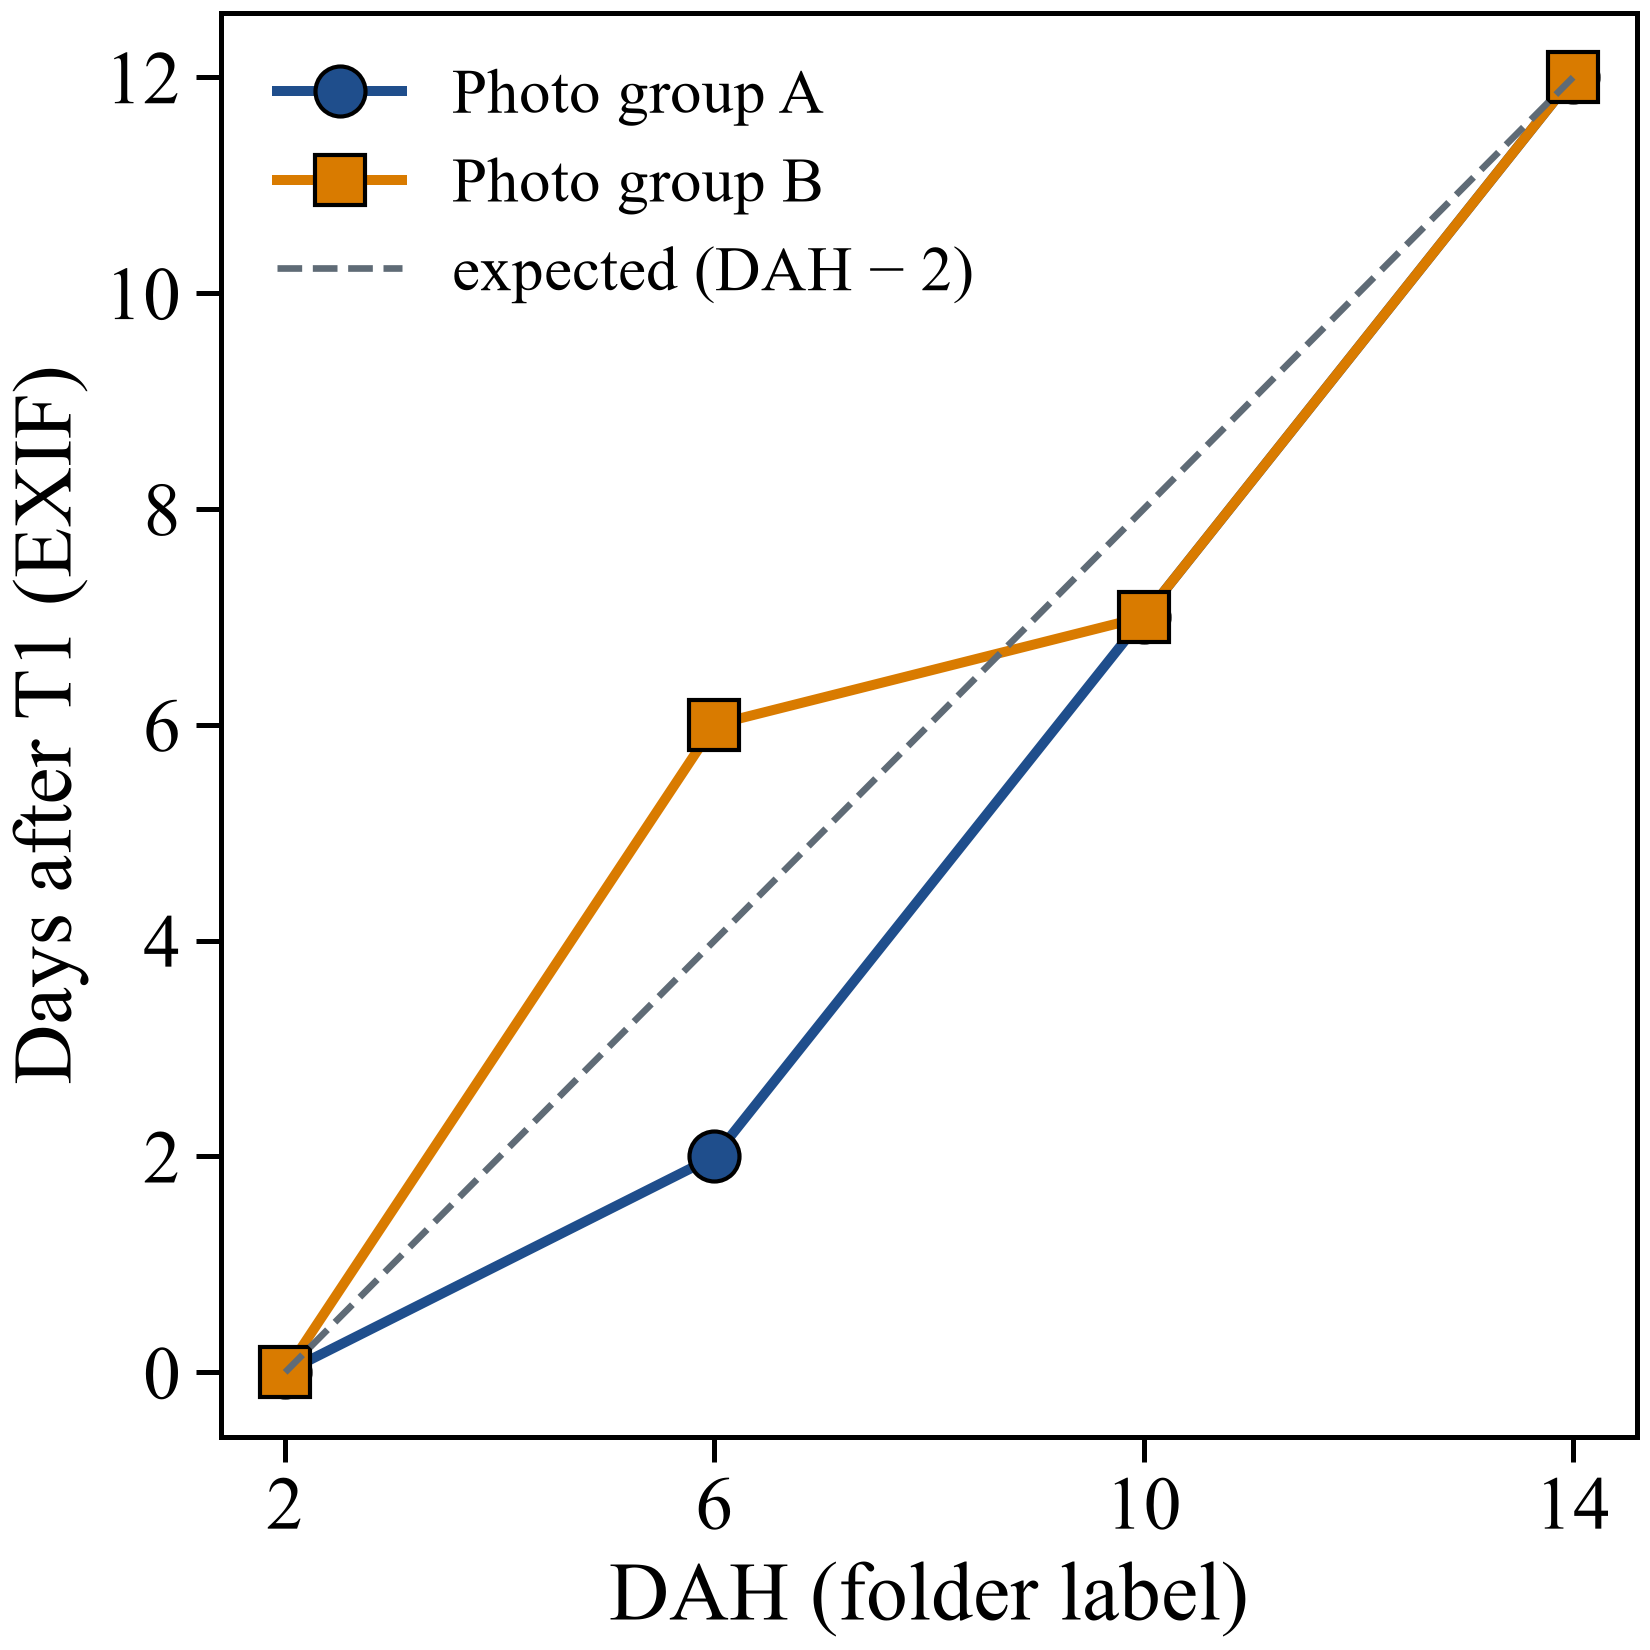

Fig. S1, panel B:
  · capture date of each storage time according to the camera clock, for the two photo groups (five genotypes each, photographed on their own days)
  · T4 agrees with 14 DAH, but T2 and T3 do not agree with 6 and 10 DAH; the folder labels (2, 6, 10, 14 DAH) are used


In [4]:
# ---- Fig. S1A: fotos por clase en cada tiempo (balance por diseño)
fig, ax = panel()
ct = pd.crosstab(df["tiempo"].map(DAH), df["class"])[CLASSES]
bottom = np.zeros(len(ct))
for c in CLASSES:
    ax.bar(range(len(ct)), 100 * ct[c] / ct.sum(1), bottom=bottom, color=CLASS_COLOR[c], edgecolor="black", lw=0.8, width=0.65, label=c)
    bottom += 100 * ct[c] / ct.sum(1)
ax.set_xticks(range(len(ct))); ax.set_xticklabels(ct.index); ax.set_xlabel("DAH"); ax.set_ylabel("Photographs (%)")
ax.set_ylim(0, 100)
leyenda_arriba(fig, ax, ncol=2)
titulo(ax, "S1A")
mostrar(fig)
nota(f"share of the four visual classes at each storage time ({len(df):,} photographs)",
     "each genotype has ~100 photographs per class at every time: the classes are balanced by design, not by the natural course of deterioration")

# ---- Fig. S1B: línea de tiempo de captura
fig, ax = panel()
for lot, mk in [("A", "o"), ("B", "s")]:
    s = df[df["lot"] == lot].groupby("tiempo")["shot_time"].min()
    x = (s.dt.normalize() - s.dt.normalize().min()).dt.days
    ax.plot(s.index.map(DAH), x, marker=mk, ms=12, color="#1F4E8C" if lot == "A" else "#D97B00", mec="black", label=f"Photo group {lot}")
ax.plot([2, 14], [0, 12], ls="--", color=MUTED, lw=1.6, label="expected (DAH − 2)")
ax.set_xticks([2, 6, 10, 14]); ax.set_xlabel("DAH (folder label)"); ax.set_ylabel("Days after T1 (EXIF)")
ax.legend(loc="upper left", frameon=False)
titulo(ax, "S1B")
mostrar(fig)
nota("capture date of each storage time according to the camera clock, for the two photo groups (five genotypes each, photographed on their own days)",
     "T4 agrees with 14 DAH, but T2 and T3 do not agree with 6 and 10 DAH; the folder labels (2, 6, 10, 14 DAH) are used")

### 1.2 Relación con el laboratorio

El laboratorio midió **10 plantas por genotipo × tiempo** en dos cosechas (5 + 5; columna `Experimento`),
de forma destructiva. Las fotos son de la **cosecha 2**, pero de otros pseudotallos, que se mezclaron al
fotografiar: no hay identificador común entre una foto y una planta del laboratorio. **El único enlace
posible es la celda genotipo × tiempo (de la cosecha 2)**. El GQI de cada foto es el GQI de su celda,
calculado con la fórmula de la Fase 2 sobre las 5 plantas de la cosecha 2.

Dos consecuencias que se reportan:
- **Techo de lo que se puede predecir por pseudotallo.** Dentro de una celda las plantas difieren; la
  fracción de la varianza del GQI de una planta que explica su celda es el máximo que alcanza cualquier
  predictor que solo conozca la celda.
- **Efecto de la cosecha.** Si las dos cosechas difieren, usar el promedio de ambas para etiquetar fotos de
  la cosecha 2 introduce un error sistemático.

In [5]:
V = {"L": "Pseudosteam length (cm)", "D": "Pseudosteam Diameter (cm)", "h": "Pseudosteam Hue",
     "hl": "Leave Hue", "F": "Firmness (N)"}
W_GQI = np.array([74.5, 72.5, 75, 73, 84]); W_GQI = W_GQI / W_GQI.sum()     # importancia del consumidor (Fase 2)


def gqi(m):
    """GQI de la Fase 2 (mismos límites, óptimos y pesos)."""
    u = np.column_stack([np.clip((m[V["L"]] - 15) / 15, 0, 1), np.clip((m[V["D"]] - 5) / 18, 0, 1),
                         np.exp(-(m[V["h"]] - 102.9) ** 2 / (2 * 16 ** 2)),
                         np.exp(-np.minimum(0, m[V["hl"]] - 124.1) ** 2 / (2 * 5.2 ** 2)),
                         np.clip(1 - (m[V["F"]] - 3) / 27, 0, 1)])
    return 100 * (u * W_GQI).sum(1)


def cells(sub):
    return sub.groupby(["Genotipo", "Tiempo"])[list(V.values())].mean()


G = pd.DataFrame({"GQI harvest 2": gqi(cells(lab[lab["Experimento"] == 2])),
                  "GQI harvest 1": gqi(cells(lab[lab["Experimento"] == 1])),
                  "GQI both harvests (Phase 2)": gqi(cells(lab))}, index=cells(lab).index)
lab["GQI_plant"] = gqi(lab)
pl = lab.dropna(subset=["GQI_plant"])
within = pl.groupby(["Genotipo", "Tiempo"])["GQI_plant"].transform(lambda s: s - s.mean())
ceiling = 1 - within.var(ddof=0) / pl["GQI_plant"].var(ddof=0)
d21 = G["GQI harvest 2"] - G["GQI both harvests (Phase 2)"]
print(f"plantas con GQI calculable: {len(pl)} de {len(lab)} (faltan variables en {len(lab) - len(pl)})")
print(f"DE del GQI entre plantas de una misma celda: {np.sqrt(within.var(ddof=0)):.1f} puntos (DE total {pl['GQI_plant'].std(ddof=0):.1f})")
print(f"techo: la celda explica {100 * ceiling:.0f} % de la varianza del GQI de una planta")
print(f"cosecha 2 − ambas cosechas: media {d21.mean():.1f}, rango {d21.min():.1f} a {d21.max():.1f} puntos; "
      f"r(cosecha 1, cosecha 2) = {np.corrcoef(G['GQI harvest 1'], G['GQI harvest 2'])[0, 1]:.2f}")
df["gqi"] = [G.loc[k, "GQI harvest 2"] for k in zip(df["geno"], df["tiempo"])]

plantas con GQI calculable: 377 de 406 (faltan variables en 29)
DE del GQI entre plantas de una misma celda: 7.6 puntos (DE total 15.2)
techo: la celda explica 75 % de la varianza del GQI de una planta
cosecha 2 − ambas cosechas: media -3.1, rango -16.2 a 7.2 puntos; r(cosecha 1, cosecha 2) = 0.84


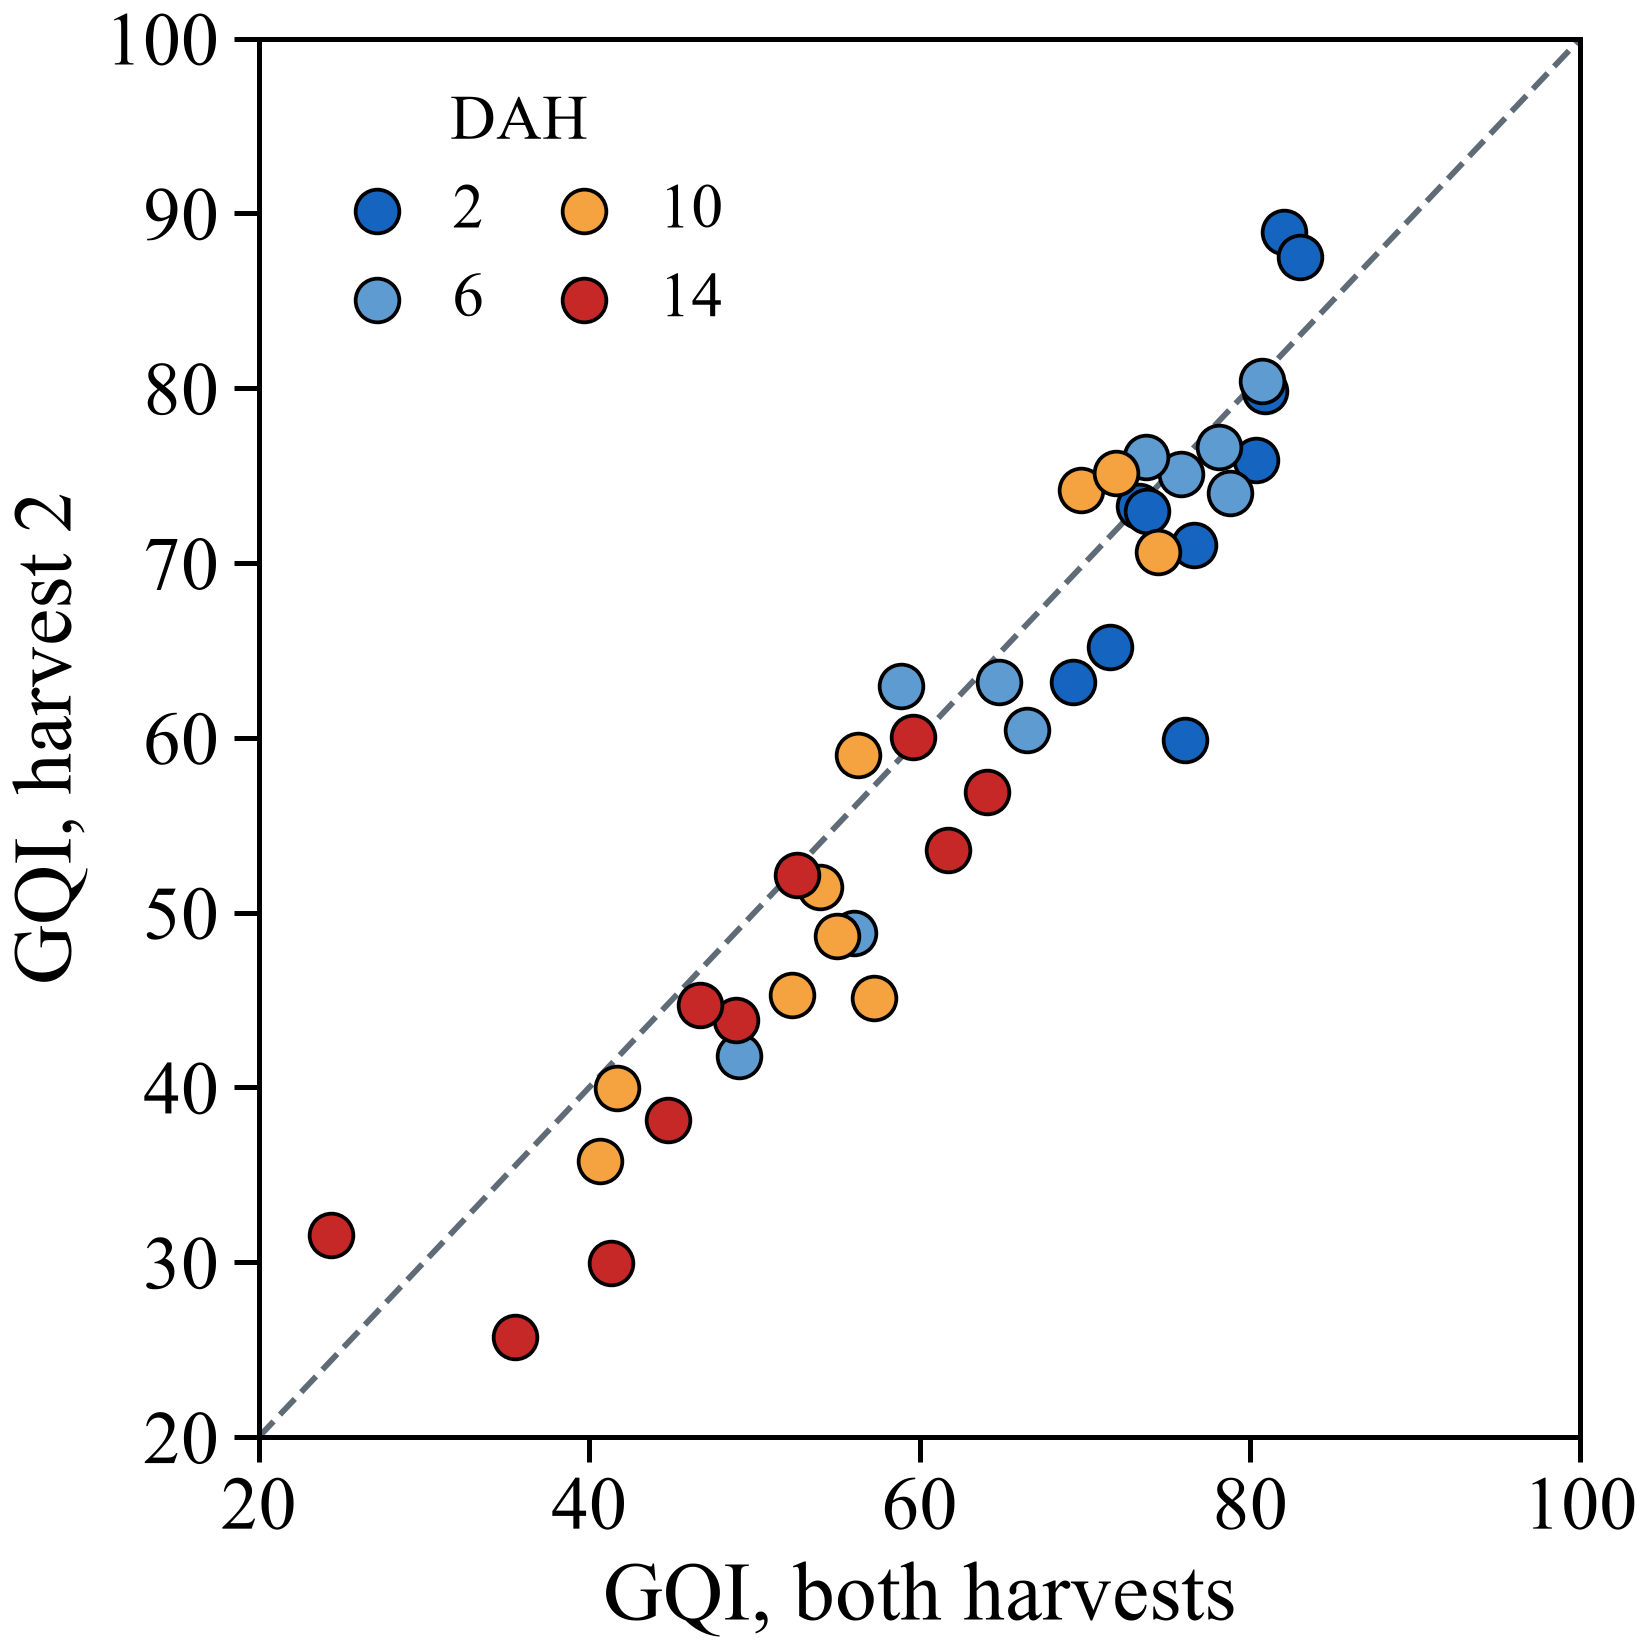

Fig. S1, panel C:
  · GQI of each genotype × time cell computed with the five plants of harvest 2 (the harvest that was photographed) against the GQI of Phase 2 (both harvests, ten plants)
  · difference: mean -3.1 points, range -16.2 to 7.2; the photographs are labelled with the harvest-2 GQI


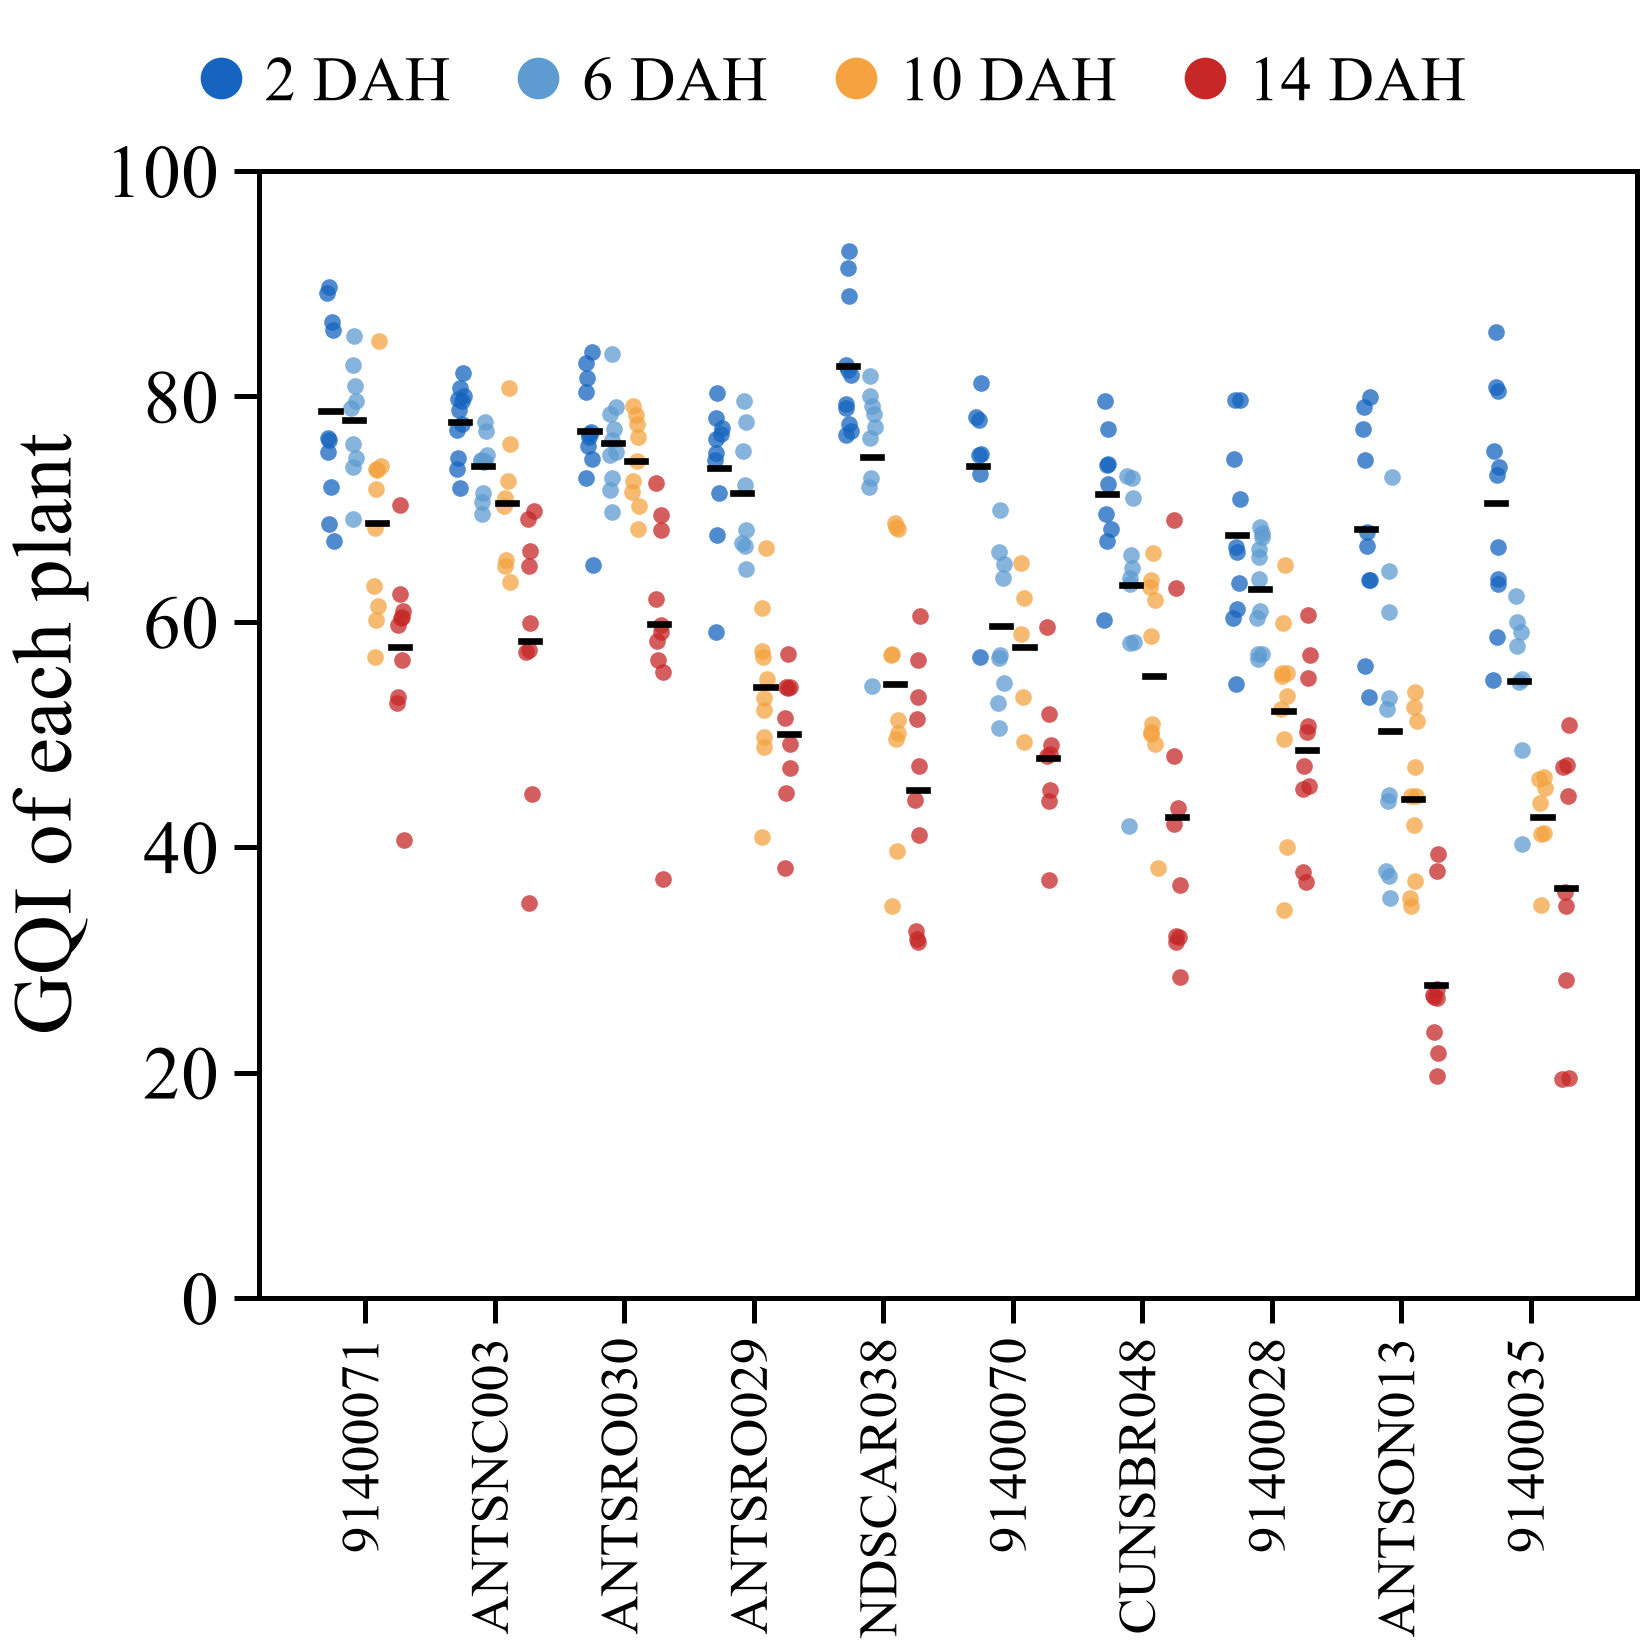

Fig. S1, panel D:
  · GQI of the 377 plants with the five variables measured (both harvests), by genotype and storage time; line = cell mean
  · within-cell SD = 7.6 points: knowing the cell explains at most 75 % of the variance of a plant's GQI


In [6]:
# ---- Fig. S1C: GQI de la cosecha 2 frente al de ambas cosechas
fig, ax = panel()
for t, d in DAH.items():
    s = G.xs(t, level="Tiempo")
    ax.scatter(s["GQI both harvests (Phase 2)"], s["GQI harvest 2"], s=110, color=DAH_COLOR[d], edgecolor="black",
               lw=0.9, label=f"{d}", zorder=3)
ax.plot([20, 100], [20, 100], ls="--", color=MUTED, lw=1.4)
ax.set_xlim(20, 100); ax.set_ylim(20, 100)
ax.set_xlabel("GQI, both harvests"); ax.set_ylabel("GQI, harvest 2")
ax.legend(title="DAH", loc="upper left", frameon=False, ncol=2, columnspacing=0.6, handletextpad=0.2)
titulo(ax, "S1C")
mostrar(fig)
nota("GQI of each genotype × time cell computed with the five plants of harvest 2 (the harvest that was photographed) "
     "against the GQI of Phase 2 (both harvests, ten plants)",
     f"difference: mean {d21.mean():.1f} points, range {d21.min():.1f} to {d21.max():.1f}; the photographs are labelled with the harvest-2 GQI")

# ---- Fig. S1D: GQI de cada planta dentro de su celda
fig, ax = panel()
order = G["GQI harvest 2"].groupby(level="Genotipo").mean().sort_values(ascending=False).index
xs = {g: i for i, g in enumerate(order)}
jit = np.random.default_rng(1)
for (g, t), sub in pl.groupby(["Genotipo", "Tiempo"]):
    x = xs[g] + (t - 2.5) * 0.18
    ax.scatter(x + jit.uniform(-0.03, 0.03, len(sub)), sub["GQI_plant"], s=16, color=DAH_COLOR[DAH[t]], alpha=0.75, lw=0)
    ax.plot([x - 0.07, x + 0.07], [sub["GQI_plant"].mean()] * 2, color="black", lw=1.6)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=13)
ax.set_ylabel("GQI of each plant"); ax.set_ylim(0, 100)
leyenda_arriba(fig, ax, handles=[Line2D([0], [0], marker="o", ls="", color=DAH_COLOR[d], ms=9, label=f"{d} DAH") for d in DAH.values()],
               ncol=4, handletextpad=0.1)
titulo(ax, "S1D")
mostrar(fig)
nota(f"GQI of the {len(pl)} plants with the five variables measured (both harvests), by genotype and storage time; line = cell mean",
     f"within-cell SD = {np.sqrt(within.var(ddof=0)):.1f} points: knowing the cell explains at most {100 * ceiling:.0f} % "
     "of the variance of a plant's GQI")

### 1.3 Variables respuesta

- **Tiempo desde la cosecha** (DAH: 2, 6, 10, 14), la etiqueta de la carpeta.
- **Vida útil del genotipo**: t50 de la encuesta en línea de la Fase 1 (supervivencia con censura por
  intervalo; Hough et al., 2003). Los valores por encima de 14 d se truncan en 14 d, el último tiempo
  observado. La encuesta presencial no se usa: da «< 2 d» o «> 14 d» en 7 de los 10 genotipos.
- **Vida útil restante** = vida útil del genotipo − DAH; **rechazo** = vida útil restante < 0, es decir,
  DAH mayor que la vida útil del genotipo. Con el tope de 14 d, ANTSRO029 y ANTSNC003 (t50 > 14 d) no se
  rechazan en ningún tiempo evaluado: a 14 DAH su vida útil restante es 0, no negativa.
- **GQI** de la celda (cosecha 2).
- **Clase visual** del pseudotallo (4 clases de defecto, balanceadas por diseño): la **única etiqueta propia
  de cada pseudotallo** fotografiado.

Por construcción, la vida útil restante y el GQI son **iguales para todas las fotos de una celda**: hay 40
valores distintos para 16 396 fotos. Conociendo el genotipo y el DAH, la vida útil restante se obtiene sin
error; ese es el techo trivial contra el que se compara la foto (sección 4).

In [7]:
SL_ONLINE = {"CUNSBR048": 12.80, "91400070": 10.14, "ANTSNC003": 15.35, "91400028": 12.31, "NDSCAR038": 5.96,
             "91400035": 5.37, "ANTSON013": 6.29, "ANTSRO029": 14.14, "91400071": 8.38, "ANTSRO030": 11.29}
SL_CI = {"CUNSBR048": "9.8–>14", "91400070": "7.1–>14", "ANTSNC003": "10.9–>14", "91400028": "8.5–>14",
         "NDSCAR038": "4.6–7.4", "91400035": "4.3–6.5", "ANTSON013": "4.8–7.6", "ANTSRO029": "9.1–>14",
         "91400071": "7.0–10.0", "ANTSRO030": "9.6–>14"}
df["sl"] = df["geno"].map(SL_ONLINE).clip(upper=14.0)
df["rsl"] = df["sl"] - df["dah"]
df["reject"] = (df["rsl"] < 0).astype(int)
sl_used = pd.Series(SL_ONLINE).clip(upper=14.0)
TABLE_S5B = pd.DataFrame({"Genotype": list(SL_ONLINE), "t50 online (d)": list(SL_ONLINE.values()),
                          "95% CI (d)": [SL_CI[g] for g in SL_ONLINE], "Shelf life used (d)": sl_used.values,
                          "Rejected from (DAH)": [min([d for d in DAH.values() if d > s], default=np.nan) for s in sl_used.values]})
TABLE_S5B = TABLE_S5B.sort_values("Shelf life used (d)").reset_index(drop=True)
print("Detail table D2 (→ Table 1). Shelf life of each genotype (Phase 1, online survey, survival analysis) used to define the remaining shelf life")
display(TABLE_S5B.round(2))
print(f"valores distintos por foto: vida útil restante {df['rsl'].nunique()}, GQI {df['gqi'].nunique()} · "
      f"fotos «rechazadas» (vida útil restante < 0): {100 * df['reject'].mean():.1f} %")

Detail table D2 (→ Table 1). Shelf life of each genotype (Phase 1, online survey, survival analysis) used to define the remaining shelf life


,Genotype,t50 online (d),95% CI (d),Shelf life used (d),Rejected from (DAH)
0,91400035,5.37,4.3–6.5,5.37,6.0
1,NDSCAR038,5.96,4.6–7.4,5.96,6.0
2,ANTSON013,6.29,4.8–7.6,6.29,10.0
3,91400071,8.38,7.0–10.0,8.38,10.0
4,91400070,10.14,7.1–>14,10.14,14.0
5,ANTSRO030,11.29,9.6–>14,11.29,14.0
6,91400028,12.31,8.5–>14,12.31,14.0
7,CUNSBR048,12.80,9.8–>14,12.80,14.0
8,ANTSRO029,14.14,9.1–>14,14.00,NaN
9,ANTSNC003,15.35,10.9–>14,14.00,NaN


valores distintos por foto: vida útil restante 36, GQI 40 · fotos «rechazadas» (vida útil restante < 0): 35.1 %


### 1.4 Pseudotallos

El identificador del pseudotallo **no se registró al fotografiar**. Dentro de cada carpeta, un mismo
pseudotallo se fotografía varias veces seguidas; cada cambio de arreglo corresponde a **otro pseudotallo**
en otra condición (confirmado por quien tomó las fotos). La versión anterior partía la secuencia cada vez
que dos fotos seguidas diferían más de 4 veces la mediana (distancia coseno de los embeddings) y producía
conteos muy desiguales. Aquí cada carpeta se segmenta en **tramos contiguos** con agrupamiento jerárquico
de Ward restringido a fotos vecinas en el orden de disparo (umbral 1,0); cada tramo es un pseudotallo.

Un pseudotallo nunca aparece en dos carpetas, de modo que la validación que deja fuera sesiones completas
(sección 3) no depende de esta identificación; los tramos se usan para contar individuos, para promediar
las fotos de cada pseudotallo y para medir cuánto inflaba la partición anterior (sección 3.2).

In [8]:
from sklearn.cluster import AgglomerativeClustering
from scipy.sparse import diags

emb = np.load(DATA / "cache_embeddings_cnn.npz")["X"].astype(np.float32)
unit = emb / np.linalg.norm(emb, axis=1, keepdims=True)
shot = df["ruta"].str.extract(r"IMG_(\d+)")[0].astype(int).to_numpy()


def old_units(mult=4):
    """Identificación anterior: nuevo pseudotallo si la distancia coseno a la foto previa > mult × mediana."""
    dist = np.full(len(df), np.nan); order = {}
    for name, idx in df.groupby("folder").groups.items():
        idx = np.asarray(idx); idx = idx[np.argsort(shot[idx])]; order[name] = idx
        dist[idx[1:]] = 1 - np.sum(unit[idx[:-1]] * unit[idx[1:]], axis=1)
    thr = np.nanmedian(dist) * mult; lab_ = np.empty(len(df), dtype=object)
    for name, idx in order.items():
        b = 0
        for k, r in enumerate(idx):
            if k and dist[r] > thr:
                b += 1
            lab_[r] = f"{name}__{b}"
    return lab_


def tramo_units(thr=1.0):
    """Tramos contiguos: Ward con conectividad de secuencia (solo se unen fotos vecinas en el orden de disparo)."""
    lab_ = np.empty(len(df), dtype=object)
    for name, idx in df.groupby("folder").groups.items():
        idx = np.asarray(idx); idx = idx[np.argsort(shot[idx])]; n = len(idx)
        cl = AgglomerativeClustering(n_clusters=None, distance_threshold=thr, linkage="ward",
                                     connectivity=diags([1.0, 1.0], [-1, 1], shape=(n, n))).fit(unit[idx]).labels_
        run = np.cumsum([0] + [int(cl[k] != cl[k - 1]) for k in range(1, n)])
        lab_[idx] = [f"{name}__{v}" for v in run]
    return lab_


df["unit_old"] = old_units()
if RUN_TRAMOS:
    pd.DataFrame({"ruta": df["ruta"], "tramo": tramo_units()}).to_csv(CACHE / "tramos.csv", index=False)
tr = pd.read_csv(CACHE / "tramos.csv"); assert (tr["ruta"] == df["ruta"]).all()
df["pseudostem"] = tr["tramo"].to_numpy()
assert (df.groupby("pseudostem")["folder"].nunique() == 1).all()     # ningún pseudotallo cruza carpetas
rows = []
for name, col in [("Previous method (4 × median jump)", "unit_old"), ("Contiguous runs (this study)", "pseudostem")]:
    size = df.groupby(col).size(); t_of = df.groupby(col)["tiempo"].first()
    per_folder = df.groupby("folder")[col].nunique()
    r = {"Method": name}
    r.update({f"{d} DAH": int(df.loc[df["tiempo"] == t, col].nunique()) for t, d in DAH.items()})
    r.update({"Per session, median (range)": f"{per_folder.median():.0f} ({per_folder.min()}–{per_folder.max()})",
              "Single-photo units at 2 DAH (%)": round(100 * (size[t_of == 1] == 1).mean(), 1)})
    rows.append(r)
TABLE_S5C = pd.DataFrame(rows)
print("Detail table D3 (→ Table 1). Pseudostems identified in the photographs")
display(TABLE_S5C)

Detail table D3 (→ Table 1). Pseudostems identified in the photographs


,Method,2 DAH,6 DAH,10 DAH,14 DAH,"Per session, median (range)",Single-photo units at 2 DAH (%)
0,Previous method (4 × median jump),580,232,207,192,5 (2–53),34.0
1,Contiguous runs (this study),273,258,240,225,6 (3–14),0.0


# 2. De la foto a la planta — qué ve el modelo

**Qué responde.** Qué parte de cada foto llega a los modelos y cómo se hace comparable entre sesiones. Es la respuesta
directa a la crítica del atajo: en la versión anterior el fondo identificaba la sesión (tabla D14).

**Paneles y por qué van juntos.**
- **Fig. 5** (artículo, primer paso del proceso): **A** foto original con la máscara de la planta; **B** lo que recibe
  la red (recortes alineados de un genotipo en los 4 tiempos y las 4 clases); **C** color de la mesa por sesión antes y
  después de la corrección. Juntos muestran que el modelo ve solo la planta y que la exposición queda igualada.
- El acuerdo de la cámara con el colorímetro va en las notas de la **Tabla 1** (detalle D5; sin figura: serían los mismos ocho números).

**Tablas de detalle:** D14 control con solo el fondo (versión anterior; va a la Tabla 3a) · D4 control de calidad de la
segmentación · D5 cámara frente a colorímetro (estas dos, en las notas de la Tabla 1).

### 2.1 Planta sola

La revisión mostró que el fondo de las fotos (piso, paredes, objetos, luz) codificaba la sesión y, con ella,
el tiempo y la clase (aprendizaje por atajos; Geirhos et al., 2020). En la versión 2 **el modelo nunca ve el
fondo**. Cada foto se procesa igual, sin mirar su etiqueta (`scripts/phase3v2_images.py`):

1. **Mesa.** A 384 px, la mesa es la unión de las regiones oscuras y neutras grandes que tocan el centro de la
   foto (una planta cercana a la cámara puede partirla en dos). Su color se modela con una **superficie
   cuadrática** en L\*, a\*, b\* (ajuste robusto), que sigue el degradado de la luz. La extensión de la mesa es
   la **envolvente convexa** de esa región (la mesa es un rectángulo en perspectiva), reducida 4 px para no
   tocar su borde.
2. **Planta.** Píxeles dentro de la mesa que se apartan del fondo modelado (ΔE > 20), excepto **sombras**
   (más oscuras que la mesa y sin color) y **reflejos** (sin color y menos de 28 unidades de L\* más claros
   que la mesa).
3. **Limpieza.** El componente principal es el de mayor tamaño × cercanía al centro de la foto entre los que
   tienen color de planta (≥ 30 % de píxeles con croma ≥ 12 y tono entre 65° y 150°, verde a amarillo) y no están
   pegados al borde de la mesa ni al marco. Se le suman en cadena los fragmentos cercanos con color de planta que
   no son objetos compactos (tarjetas, papeles, lápices), no están sobre el borde de la mesa (ladrillos de la
   pared) ni en el 5 % exterior de la foto, y miden menos del doble del principal (una bandeja de cebollas al
   fondo queda fuera). Paredes, tableros y reflejos son grises; en el 5 % exterior de la foto se quitan además
   los píxeles pardos, anaranjados o rojos pegados a una punta.
4. **Máscara fina** a 1/4 de la resolución original, dentro de la zona de la máscara gruesa.
5. **Alineación y escala.** El eje mayor de la planta se pone horizontal y la base (el extremo menos verde) a
   la izquierda. Como no hay referencia de escala (las fotos se tomaron a distintas distancias), **la planta se
   lleva a una longitud fija** (640 px): ningún descriptor depende del tamaño absoluto.
6. **Recorte para la red.** La planta sobre gris neutro (todo lo de fuera de la máscara), con relleno hasta 4:1
   y reducida a 448 × 112 px.

La segmentación de la versión anterior (una sola región de color uniforme) fallaba cuando la luz formaba un
degradado sobre la mesa y dejaba cuñas del borde de la mesa y de la pared dentro de la máscara; por eso se
reemplazó. La segmentación se revisó visualmente, antes de entrenar ningún modelo, en fotos de prueba
estratificadas por clase y en muestras al azar y casos extremos de dos corridas previas, que se detuvieron al
encontrar una tarjeta rotulada, una bandeja de cebollas al fondo y ladrillos de la pared dentro de la máscara
(cambios anotados en el plan).
Limitaciones: las raíces finas y las puntas de hoja muy delgadas y secas (grises) no siempre quedan dentro de
la máscara, y en pocas sesiones con la pared muy cerca pueden quedar trozos pequeños de ladrillo pegados a la
punta de una hoja. Como la validación deja fuera sesiones completas, un objeto propio de una sesión no puede
pasar del entrenamiento a la prueba.

**Por qué se quita el fondo.** En la versión anterior, un modelo que veía **solo el fondo** (lo que queda fuera de la
máscara: mesa, piso, paredes, luz) predecía el tiempo de almacenamiento casi sin error cuando había fotos de la misma
sesión en entrenamiento, y seguía muy por encima del azar con el bloque genotipo × tiempo fuera (las cuatro sesiones del mismo genotipo y día); solo con el día de captura fuera caía al
azar (tabla D14). El fondo identificaba la sesión y, con ella, el tiempo: era un atajo. En la versión 2 el fondo no
llega a ningún modelo.

In [9]:
BGM = load_pickle(CACHE / "background_models.pkl")
yb = {"time": df["tiempo"].to_numpy(), "class": df["calidad_idx"].to_numpy(), "genotype": pd.factorize(df["geno"])[0]}
rows = []
for fname, flab in [("background colour", "Colour statistics of the background"), ("environment embedding", "ResNet18 embedding of the scene without the plant")]:
    for t, tl, chance in [("time", "Storage time", 0.25), ("class", "Visual class", 0.25), ("genotype", "Genotype", 0.10)]:
        r = {"Background features": flab, "Target": tl, "Chance": chance}
        for sc, sl in [("photo", "Random photographs"), ("session", "Genotype × time block left out"), ("day", "Capture day left out")]:
            r[sl] = float(np.mean(BGM["pred"][(fname, sc, t)] == yb[t]))
        rows.append(r)
TABLE_S14 = pd.DataFrame(rows).round(2)
print("Detail table D14 (→ Table 3a). Accuracy of models that see only the background of the photographs (outside the plant mask), previous version")
display(TABLE_S14)

Detail table D14 (→ Table 3a). Accuracy of models that see only the background of the photographs (outside the plant mask), previous version


,Background features,Target,Chance,Random photographs,Genotype × time block left out,Capture day left out
0,Colour statistics of the background,Storage time,0.25,0.97,0.61,0.09
1,Colour statistics of the background,Visual class,0.25,0.90,0.30,0.28
2,Colour statistics of the background,Genotype,0.10,0.93,0.05,0.14
3,ResNet18 embedding of the scene without the plant,Storage time,0.25,0.67,0.47,0.10
4,ResNet18 embedding of the scene without the plant,Visual class,0.25,0.49,0.28,0.27
5,ResNet18 embedding of the scene without the plant,Genotype,0.10,0.48,0.07,0.13


In [10]:
meta2 = pd.read_csv(V2 / "meta_v2.csv")
assert (meta2["ruta"].to_numpy() == df["ruta"].to_numpy()).all()
F2 = np.load(V2 / "features_v2.npz", allow_pickle=True)
DESC = pd.DataFrame(F2["D"], columns=[str(c) for c in F2["names"]])
EMB = F2["E"]
CROPS = np.load(V2 / "crops.npy", mmap_mode="r") if (V2 / "crops.npy").exists() else None   # 2,3 GB: solo donde se procesaron las fotos
OK = meta2["ok"].to_numpy(bool)
q = meta2.assign(DAH=df["tiempo"].map(DAH), Class=df["class"])
TABLE_S6A = (q.groupby(["DAH", "Class"], sort=False)
               .agg(Photos=("ruta", "size"), **{"Plant found (%)": ("ok", lambda s: 100 * s.mean()),
                    "Plant length, median (px at 1/4 scale)": ("plant_len_px", "median"),
                    "Height / length, median": ("plant_h_over_len", "median"),
                    "Flipped to put the base on the left (%)": ("flipped", lambda s: 100 * s.mean())})
               .reindex(CLASSES, level="Class").round(2))
print("Detail table D4 (→ Table 1). Image processing: photographs in which the plant was found and properties of the aligned plant")
display(TABLE_S6A)
print(f"planta encontrada en {OK.sum():,} de {len(OK):,} fotos ({100 * OK.mean():.2f} %); "
      f"sesiones con alguna foto sin planta: {meta2.loc[~OK, 'ruta'].str.rsplit(chr(92), n=1).str[0].nunique()}")

Detail table D4 (→ Table 1). Image processing: photographs in which the plant was found and properties of the aligned plant


Photos  Plant found (%)  \
DAH Class                                    
2   On-Grade         1040           100.00   
    Minor defects    1035           100.00   
    Major defects    1016           100.00   
    Decay            1032            99.90   
6   On-Grade         1108           100.00   
    Minor defects    1025            99.71   
    Major defects    1019           100.00   
    Decay            1007           100.00   
10  On-Grade         1026           100.00   
    Minor defects     996           100.00   
    Major defects    1013           100.00   
    Decay            1031           100.00   
14  On-Grade          996           100.00   
    Minor defects    1007           100.00   
    Major defects    1027            99.61   
    Decay            1018           100.00   

                   Plant length, median (px at 1/4 scale)  \
DAH Class                                                   
2   On-Grade                                       931.72   
    Minor defects                                  950.68   
    Major defects                                  922.30   
    Decay                                          883.48   
6   On-Grade                                       864.50   
    Minor defects                                  831.00   
    Major defects                                  777.00   
    Decay                                          835.00   
10  On-Grade                                       745.00   
    Minor defects                                  793.00   
    Major defects                                  695.00   
    Decay                                          840.00   
14  On-Grade                                       833.00   
    Minor defects                                  790.00   
    Major defects                                  778.00   
    Decay                                          811.00   

                   Height / length, median  \
DAH Class                                    
2   On-Grade                          0.45   
    Minor defects                     0.44   
    Major defects                     0.41   
    Decay                             0.48   
6   On-Grade                          0.37   
    Minor defects                     0.46   
    Major defects                     0.49   
    Decay                             0.52   
10  On-Grade                          0.60   
    Minor defects                     0.53   
    Major defects                     0.61   
    Decay                             0.51   
14  On-Grade                          0.52   
    Minor defects                     0.49   
    Major defects                     0.42   
    Decay                             0.45   

                   Flipped to put the base on the left (%)  
DAH Class                                                   
2   On-Grade                                         62.40  
    Minor defects                                    54.40  
    Major defects                                    55.12  
    Decay                                            66.86  
6   On-Grade                                         49.91  
    Minor defects                                    58.90  
    Major defects                                    55.25  
    Decay                                            55.31  
10  On-Grade                                         66.18  
    Minor defects                                    66.37  
    Major defects                                    60.51  
    Decay                                            61.11  
14  On-Grade                                         58.13  
    Minor defects                                    54.32  
    Major defects                                    62.90  
    Decay                                            50.39

planta encontrada en 16,388 de 16,396 fotos (99.95 %); sesiones con alguna foto sin planta: 3


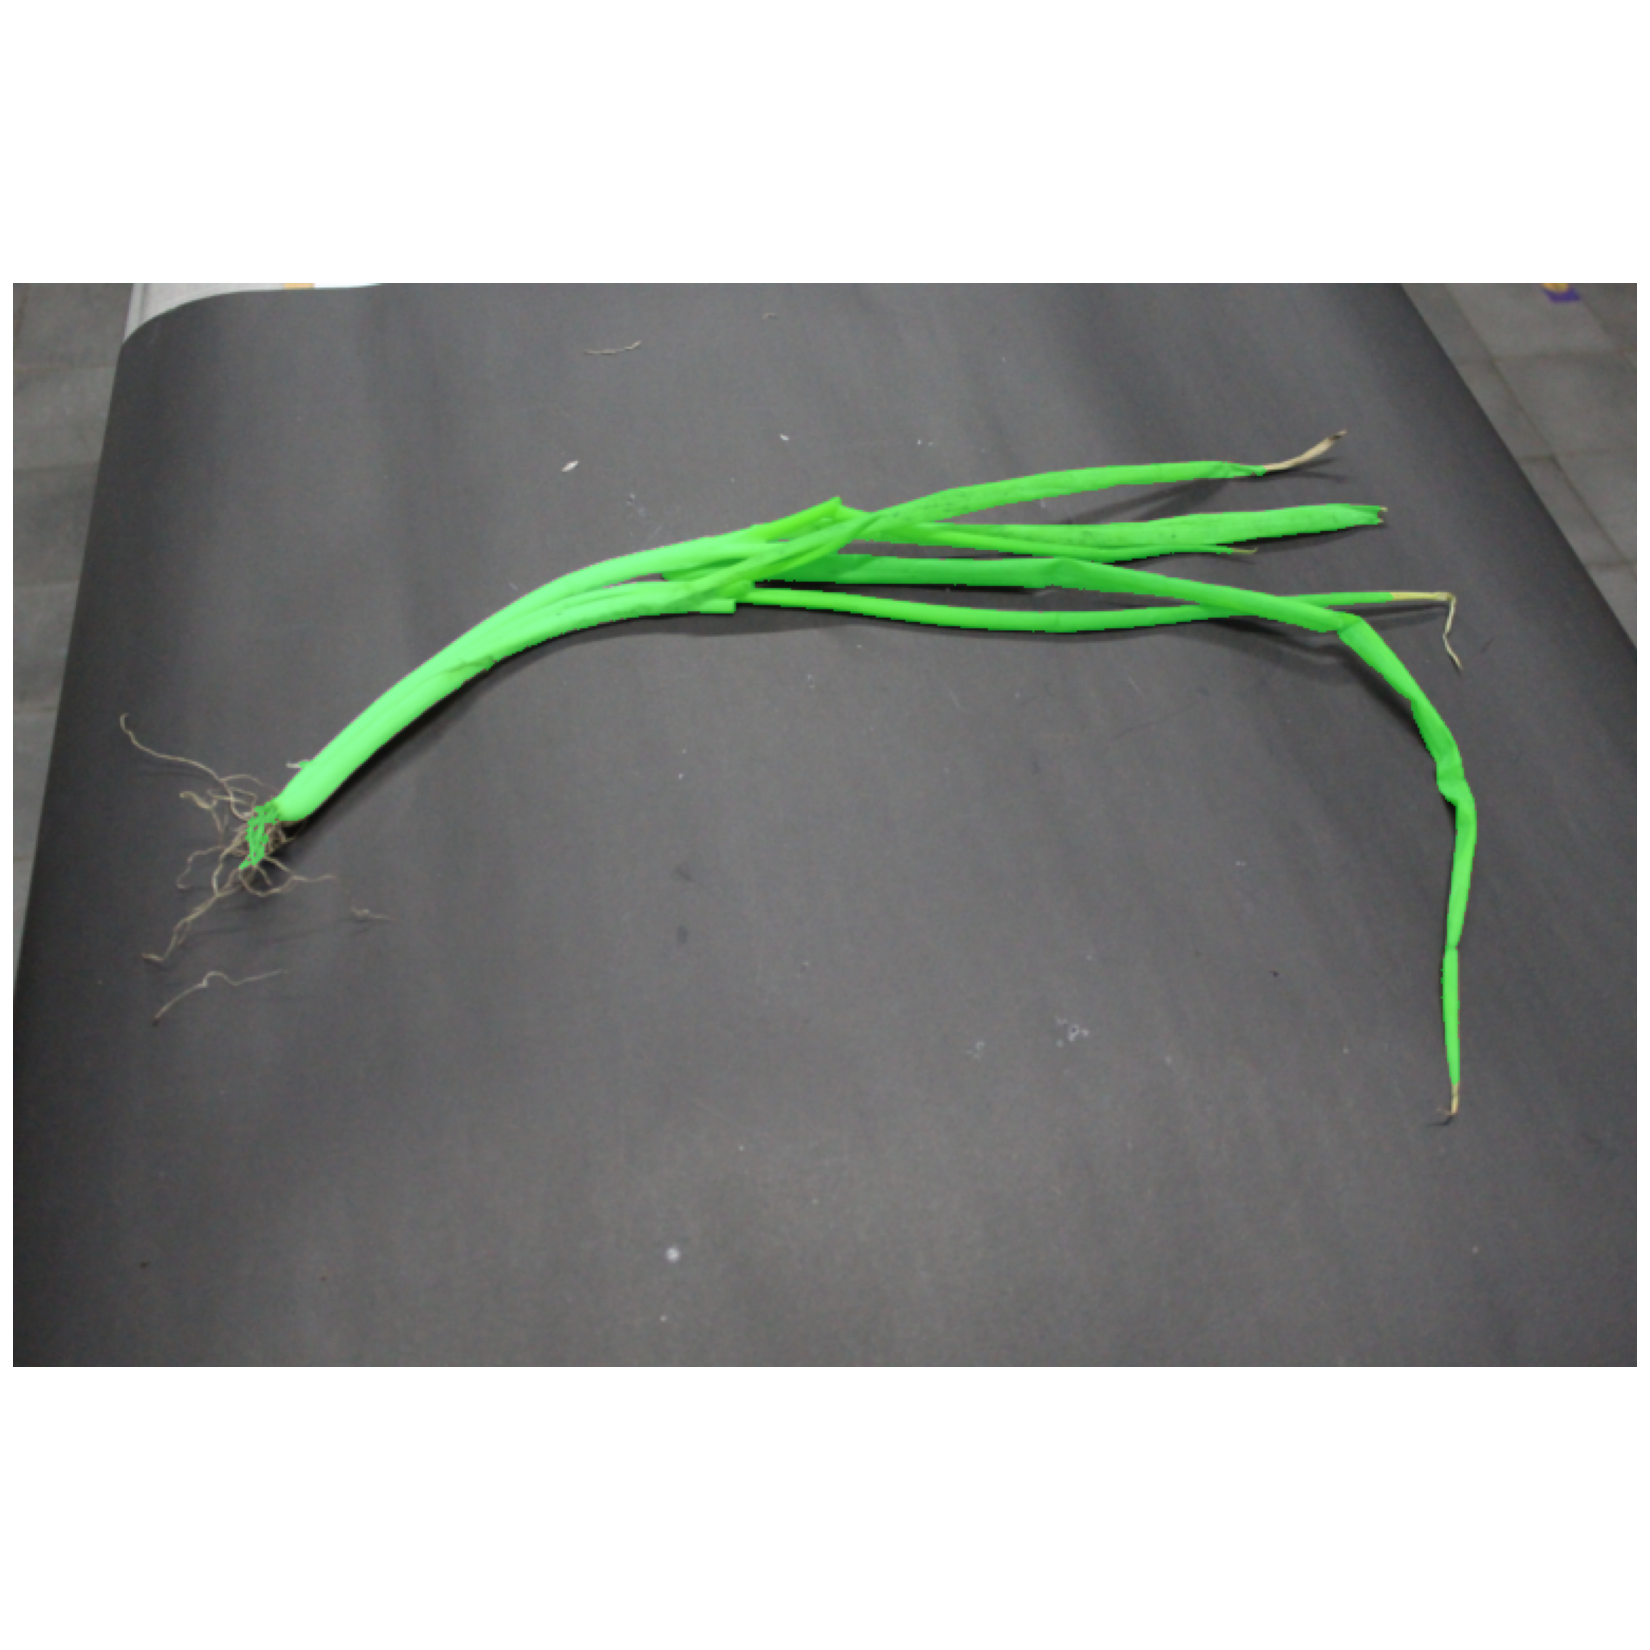

Fig. 5, panel A:
  · photograph of ANTSRO030 at 2 DAH (On-Grade) with the plant mask in green
  · everything outside the mask (table, floor, walls, objects, reflections, shadows) is discarded before any feature is computed


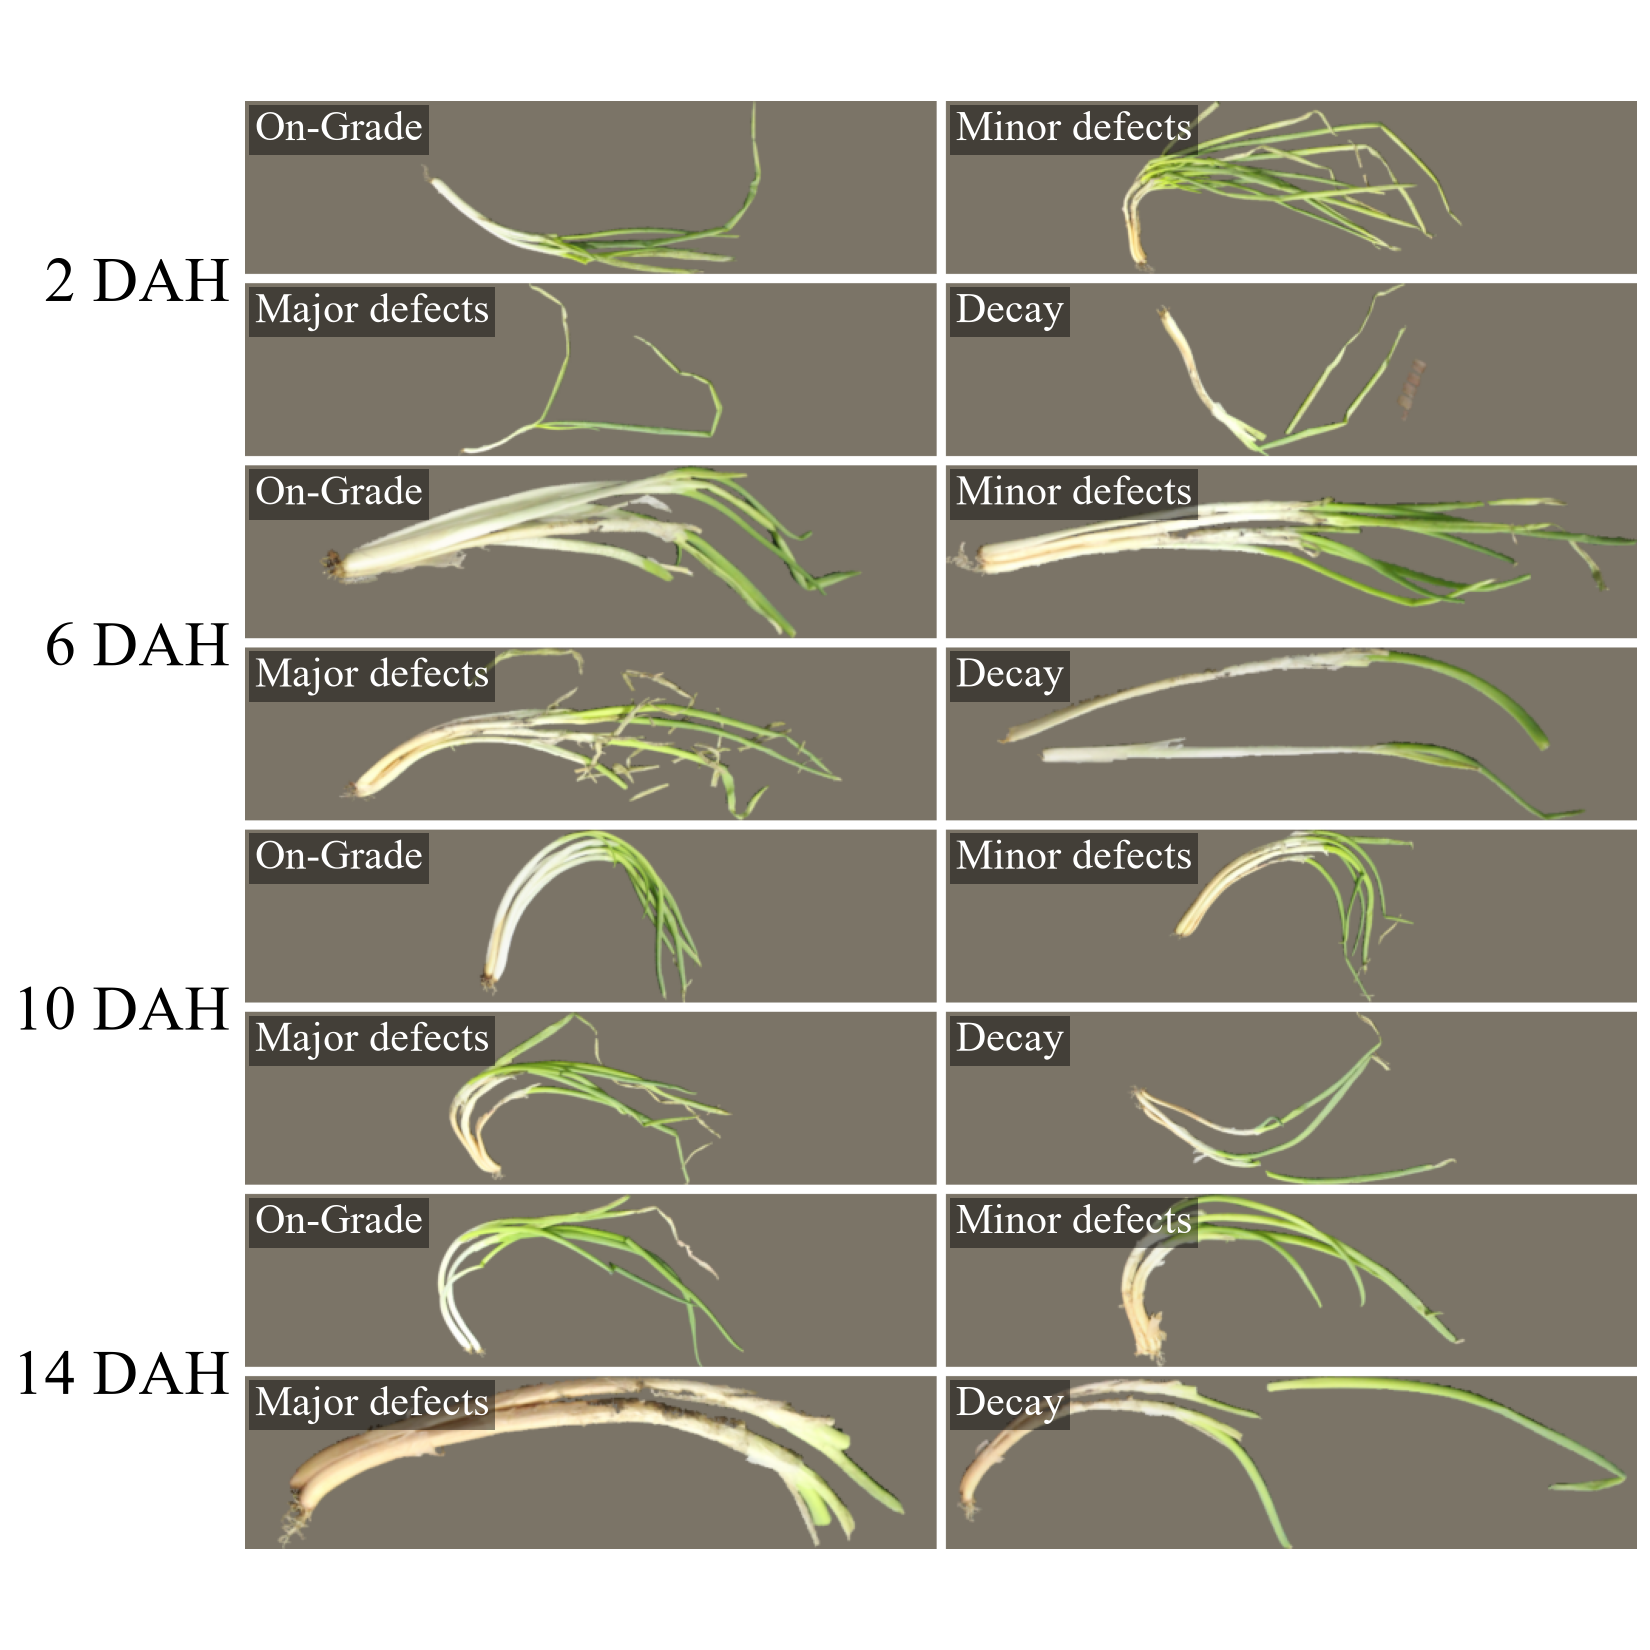

Fig. 5, panel B:
  · what the network receives: aligned crops of ANTSRO030 at the four storage times and the four visual classes (one photograph each)
  · plant on neutral grey, base on the left, length normalised; 448 × 112 px


In [11]:
# ---- Fig. 5A y Fig. S2A: foto original con la máscara
EX = np.load(V2 / "examples_v2.npz", allow_pickle=True)
for k, tag in [(0, "5A")]:
    fig, ax = panel()
    img = EX["orig"][k].astype(float) / 255
    m = EX["mask"][k]
    over = img.copy(); over[m] = 0.55 * over[m] + 0.45 * np.array([0.0, 1.0, 0.2])
    ax.imshow(over); ax.axis("off")
    titulo(ax, tag)
    mostrar(fig)
    i = int(EX["idx"][k])
    nota(f"photograph of {df['geno'].iloc[i]} at {df['dah'].iloc[i]} DAH ({df['class'].iloc[i]}) with the plant mask in green",
         "everything outside the mask (table, floor, walls, objects, reflections, shadows) is discarded before any feature is computed")

# ---- Fig. 5B: recortes alineados de un genotipo (4 DAH × 4 clases)
fig, ax = panel()
g_ex = str(EX["genotype"])
canvas = np.full((8 * 112 + 7 * 6, 2 * 448 + 6, 3), 255, np.uint8)
FIG5B = {} if CROPS is not None else dict(np.load(V2 / "fig5b_crops.npz"))   # los 16 recortes de este panel
used = {}
for r, (t, d) in enumerate(DAH.items()):
    for c, cl in enumerate(CLASSES):
        cand = np.flatnonzero((df["geno"] == g_ex).to_numpy() & (df["tiempo"] == t).to_numpy() & (df["class"] == cl).to_numpy() & OK)
        i = cand[len(cand) // 2]
        y = (2 * r + c // 2) * 118; x = (c % 2) * 454
        used[str(i)] = np.asarray(CROPS[i]) if CROPS is not None else FIG5B[str(i)]
        canvas[y:y + 112, x:x + 448] = used[str(i)]
if CROPS is not None:
    np.savez_compressed(V2 / "fig5b_crops.npz", **used)   # para dibujar el panel sin crops.npy
ax.imshow(canvas); ax.set_xticks([])
for r in range(4):
    for c, cl in enumerate(CLASSES):
        ax.text((c % 2) * 454 + 6, (2 * r + c // 2) * 118 + 6, cl, fontsize=10, color="white", va="top", ha="left",
                bbox=dict(facecolor="black", alpha=0.45, pad=1.5, lw=0))
ax.set_yticks([(2 * r + 1) * 118 - 3 for r in range(4)]); ax.set_yticklabels([f"{d} DAH" for d in DAH.values()], fontsize=15)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
titulo(ax, "5B")
mostrar(fig)
nota(f"what the network receives: aligned crops of {g_ex} at the four storage times and the four visual classes (one photograph each)",
     "plant on neutral grey, base on the left, length normalised; 448 × 112 px")

### 2.2 Corrección de color por sesión

No hubo carta de color en las tomas (recomendación para el ensayo nuevo). La **mesa**, gris oscura y presente
en todas las fotos, se usa como referencia neutra: para cada sesión se calcula la mediana del color de la mesa
(sin la planta) en RGB lineal y una **ganancia por canal** que la lleva a un gris de referencia fijo (0,135 en
los tres canales). La misma ganancia se aplica a todas las fotos de la sesión (corrección de von Kries por
sesión, como pidió la revisión). Así se igualan el balance de blancos y la exposición entre sesiones.

La prueba externa es el **colorímetro** del laboratorio (cosecha 2): si la cámara mide el color del tejido, la
media por celda del color de la **base** de la planta alineada (30 % izquierdo ≈ pseudotallo) y de la **punta**
(30 % derecho ≈ hojas) debería seguir a la del colorímetro en el pseudotallo y en la hoja.

In [12]:
def lab_of_linear(rgb):
    M = np.array([[0.412453, 0.357580, 0.180423], [0.212671, 0.715160, 0.072169], [0.019334, 0.119193, 0.950227]])
    t = (np.asarray(rgb, float) @ M.T) / np.array([0.95047, 1.0, 1.08883])
    f = np.where(t > 0.008856, np.cbrt(t), 7.787 * t + 16 / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)


tab_raw = lab_of_linear(meta2[["tab_R", "tab_G", "tab_B"]].to_numpy(float))
gains = meta2[["gain_R", "gain_G", "gain_B"]].to_numpy(float)
tab_cor = lab_of_linear(meta2[["tab_R", "tab_G", "tab_B"]].to_numpy(float) * gains)
TS = pd.DataFrame({"folder": df["folder"], "day": df["day_group"], "L raw": tab_raw[:, 0], "a raw": tab_raw[:, 1], "b raw": tab_raw[:, 2],
                   "L cor": tab_cor[:, 0], "a cor": tab_cor[:, 1], "b cor": tab_cor[:, 2],
                   "gR": gains[:, 0], "gG": gains[:, 1], "gB": gains[:, 2]})
share = {}
for ver in ["raw", "cor"]:
    for ch in "Lab":
        v = TS[f"{ch} {ver}"]; share[(ver, ch)] = TS.groupby("folder")[f"{ch} {ver}"].transform("mean").var() / v.var()
SESS = TS.groupby("folder").agg(day=("day", "first"), L=("L raw", "median"), a=("a raw", "median"), b=("b raw", "median"),
                                Lc=("L cor", "median"), ac=("a cor", "median"), bc=("b cor", "median"),
                                gR=("gR", "first"), gG=("gG", "first"), gB=("gB", "first"))
print(f"ganancias por sesión: R {SESS['gR'].min():.2f}–{SESS['gR'].max():.2f}, G {SESS['gG'].min():.2f}–{SESS['gG'].max():.2f}, "
      f"B {SESS['gB'].min():.2f}–{SESS['gB'].max():.2f}")
print("color de la mesa por sesión (mediana), rango antes → después: " + ", ".join(
    f"{ch}* {SESS[ch].max() - SESS[ch].min():.1f} → {SESS[ch + 'c'].max() - SESS[ch + 'c'].min():.1f}" for ch in "Lab"))
print("fracción de la varianza del color de la mesa (por foto) que se debe a la sesión, antes / después: " + ", ".join(
    f"{ch}* {share[('raw', ch)]:.2f} / {share[('cor', ch)]:.2f}" for ch in "Lab"))

# colorímetro (cosecha 2) frente a la cámara: base ≈ pseudotallo, punta ≈ hoja
colo = lab[lab["Experimento"] == 2].groupby(["Genotipo", "Tiempo"])[["Pseudosteam Luminosity", "Pseudosteam Hue", "Leave luminosity", "Leave Hue"]].mean()
camc = DESC[[c for c in DESC.columns if c.startswith(("raw_", "cor_"))]].assign(Genotipo=df["geno"], Tiempo=df["tiempo"])[OK]
camc = camc.groupby(["Genotipo", "Tiempo"]).mean()
JJ = camc.join(colo, how="inner")
rows = []
for name, cam_, ref in [("Pseudostem L*", "base_L", "Pseudosteam Luminosity"), ("Pseudostem hue", "base_hue", "Pseudosteam Hue"),
                        ("Leaf L*", "tip_L", "Leave luminosity"), ("Leaf hue", "tip_hue", "Leave Hue")]:
    rows.append({"Attribute (camera region)": f"{name} ({'base' if 'base' in cam_ else 'tip'})",
                 "r, raw camera": np.corrcoef(JJ[f"raw_{cam_}"], JJ[ref])[0, 1],
                 "r, corrected camera": np.corrcoef(JJ[f"cor_{cam_}"], JJ[ref])[0, 1]})
TABLE_S6B = pd.DataFrame(rows).round(2)
print(f"\nDetail table D5 (→ Table 1). Correlation over the {len(JJ)} genotype × time cells between the camera colour of the aligned plant "
      "(base ≈ pseudostem, tip ≈ leaves) and the colorimeter (harvest 2), before and after the per-session correction")
display(TABLE_S6B)

ganancias por sesión: R 0.79–1.56, G 0.78–1.56, B 0.76–1.52
color de la mesa por sesión (mediana), rango antes → después: L* 13.3 → 0.2, a* 1.8 → 1.7, b* 3.5 → 3.2
fracción de la varianza del color de la mesa (por foto) que se debe a la sesión, antes / después: L* 0.44 / 0.03, a* 0.57 / 0.38, b* 0.43 / 0.24

Detail table D5 (→ Table 1). Correlation over the 40 genotype × time cells between the camera colour of the aligned plant (base ≈ pseudostem, tip ≈ leaves) and the colorimeter (harvest 2), before and after the per-session correction


,Attribute (camera region),"r, raw camera","r, corrected camera"
0,Pseudostem L* (base),0.65,0.49
1,Pseudostem hue (base),0.82,0.80
2,Leaf L* (tip),0.79,0.71
3,Leaf hue (tip),0.68,0.73


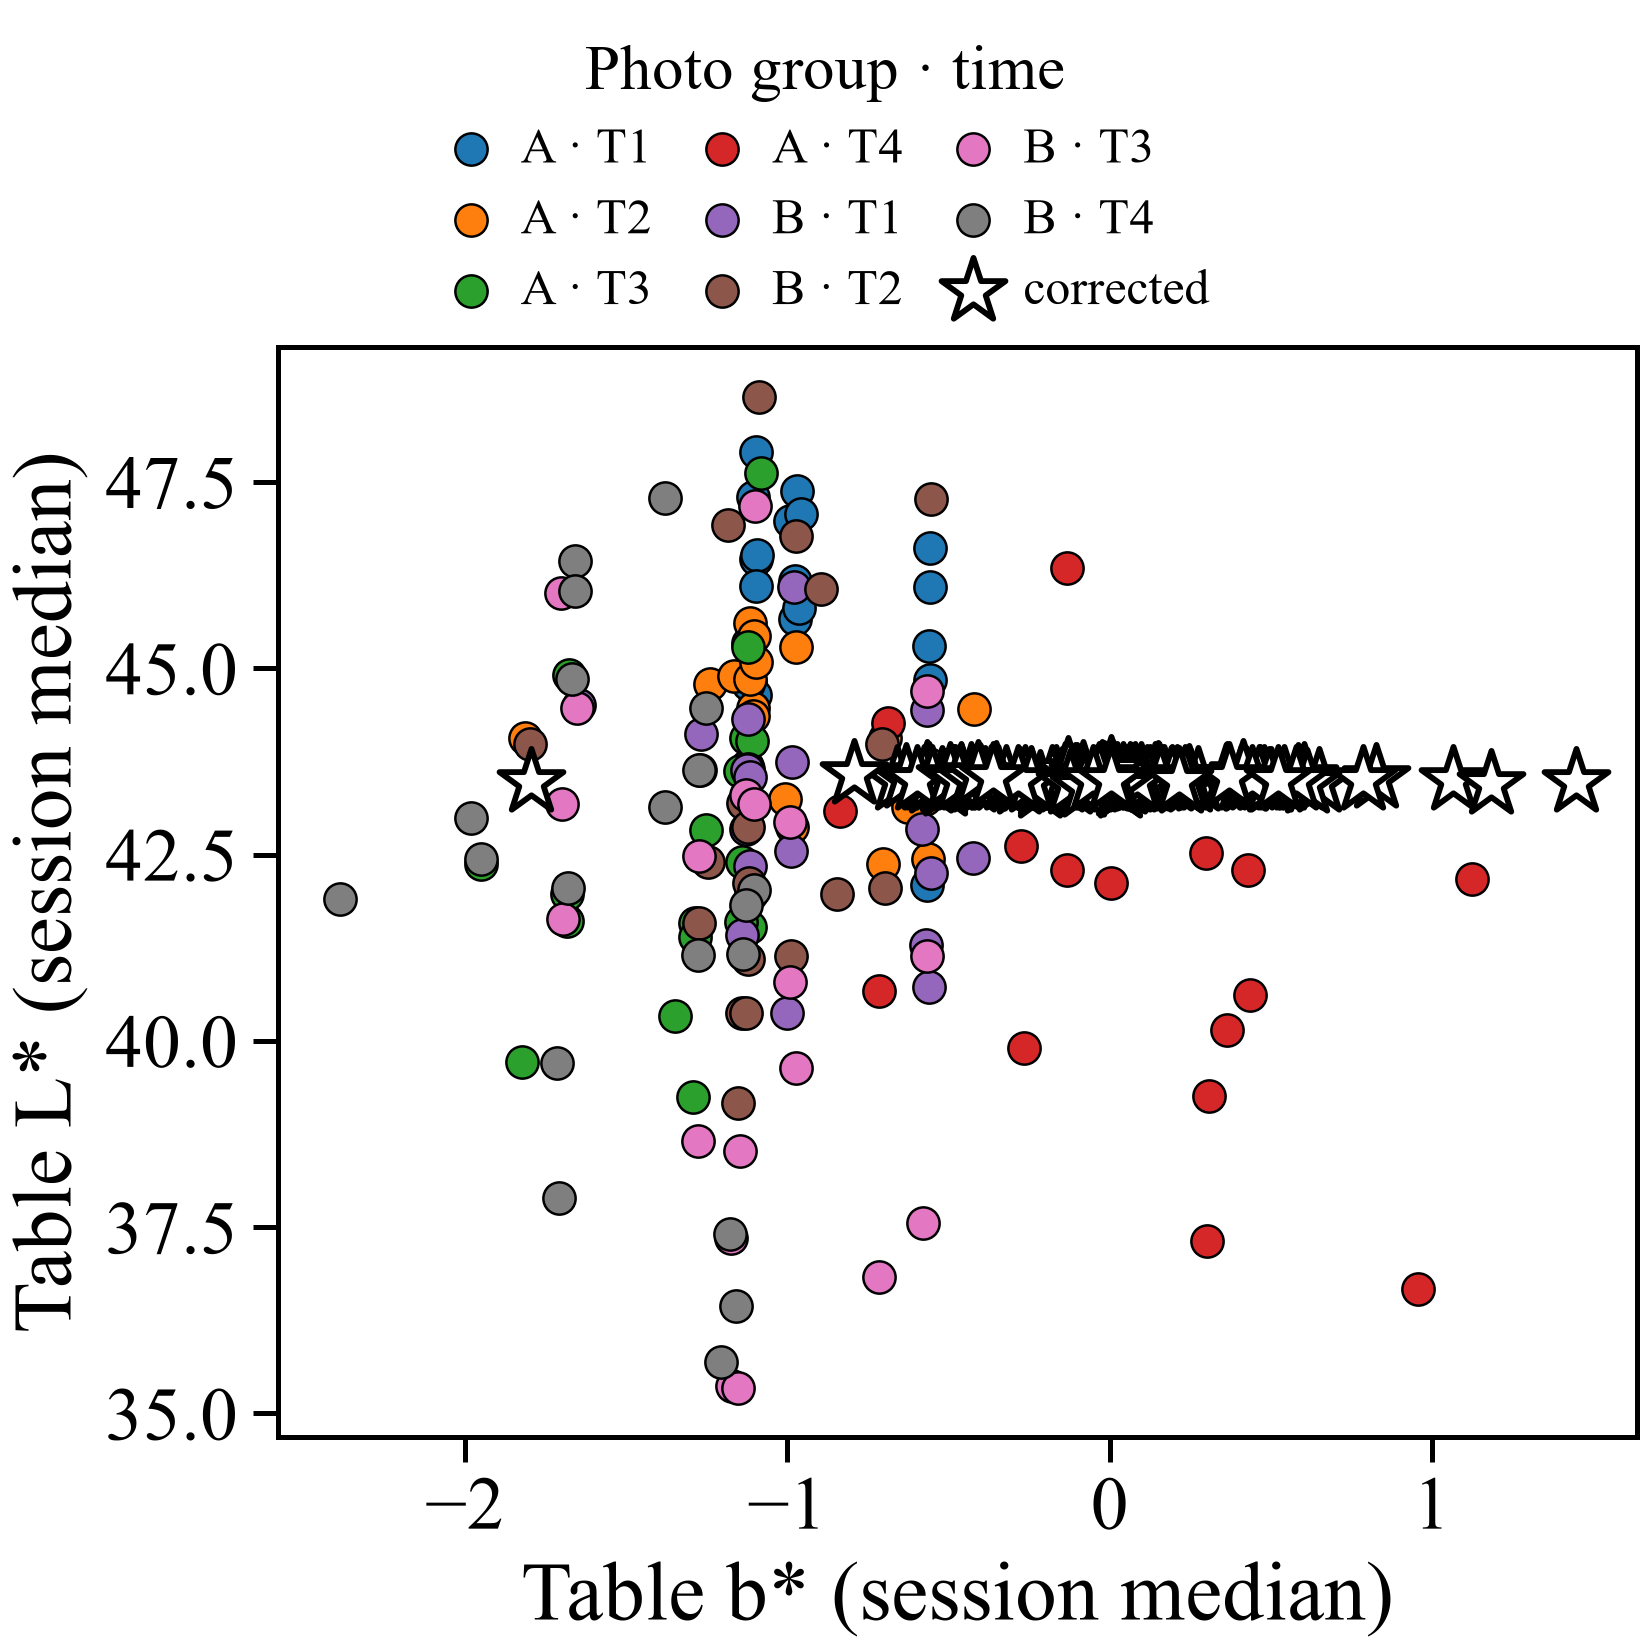

Fig. 5, panel C:
  · colour of the table (neutral reference present in every photograph) in each of the 160 sessions before correction, coloured by capture day; stars = the same sessions after the per-session correction
  · range between sessions before → after: L* 13.3 → 0.2, a* 1.8 → 1.7, b* 3.5 → 3.2 (the sessions differed mainly in lightness, i.e. exposure; their white balance already differed little)
  · share of the per-photo table colour variance due to the session before correction: L* 0.44, a* 0.57, b* 0.43


In [13]:
# ---- Fig. 5C: color de la mesa por sesión, antes y después de corregir
fig, ax = panel()
days_ = sorted(SESS["day"].unique()); cmap = plt.get_cmap("tab10")
for i, dname in enumerate(days_):
    s = SESS[SESS["day"] == dname]
    ax.scatter(s["b"], s["L"], s=60, color=cmap(i), edgecolor="black", lw=0.6, label=dname)
ax.scatter(SESS["bc"], SESS["Lc"], s=260, marker="*", color="white", edgecolor="black", lw=1.4, zorder=4, label="corrected")
ax.set_xlabel("Table b* (session median)"); ax.set_ylabel("Table L* (session median)")
leyenda_arriba(fig, ax, ncol=3, fontsize=12, title="Photo group · time")
titulo(ax, "5C")
mostrar(fig)
nota("colour of the table (neutral reference present in every photograph) in each of the 160 sessions before correction, coloured by "
     "capture day; stars = the same sessions after the per-session correction",
     "range between sessions before → after: " + ", ".join(f"{ch}* {SESS[ch].max() - SESS[ch].min():.1f} → {SESS[ch + 'c'].max() - SESS[ch + 'c'].min():.1f}" for ch in "Lab") +
     " (the sessions differed mainly in lightness, i.e. exposure; their white balance already differed little)",
     "share of the per-photo table colour variance due to the session before correction: " +
     ", ".join(f"{ch}* {share[('raw', ch)]:.2f}" for ch in "Lab"))

**Lectura.** Entre sesiones, la mesa cambiaba sobre todo en **luminosidad** (exposición): la sesión explicaba
cerca de la mitad de la varianza de su L\*, y la corrección lo deja casi en cero. El balance de blancos ya
variaba poco (b\* en un rango de unas 3 unidades). Con la planta bien segmentada y separada en base y punta, la
cámara **sigue al colorímetro** en las 40 celdas (tabla D5), mucho mejor que en la versión anterior (r de
−0,25 a 0,56 con toda la planta y la segmentación anterior). La corrección por sesión **no mejora** ese acuerdo
(en L\* lo reduce), de modo que no se puede afirmar que corrija el color del tejido: iguala la exposición entre
sesiones, que es lo que se buscaba para que la luz de cada día no sirva de atajo. Sin carta de color no hay una
referencia mejor; queda como recomendación para el ensayo nuevo.

### 2.3 Descriptores y embedding

**Descriptores (M1).** Calculados sobre la planta alineada, corregida y llevada a 640 px de largo; ninguno
depende del tamaño absoluto:

| Grupo | n | Qué mide |
|---|---|---|
| Color | 25 | media, DE y percentiles 10/50/90 de L\*, a\*, b\*, croma y tono de toda la planta |
| Fracciones de color | 6 | proporción de la planta verde, amarillo verdosa, amarilla, parda, pálida y oscura (umbrales fijados a priori) |
| Perfil base → punta | 40 | en 10 tramos a lo largo del eje: anchura relativa, L\*, a\*, b\* |
| Forma sin escala | 7 | área / largo², alto / largo, solidez, extensión, n.º de componentes, extremos del esqueleto, largo del esqueleto / largo |
| Textura | 21 | GLCM (contraste, disimilitud, homogeneidad, energía, correlación a 1 y 3 px), histograma LBP uniforme, gradiente medio |

**Embedding (M2).** ResNet18 preentrenada en ImageNet y congelada (He et al., 2016) sobre el recorte de
448 × 112 px; vector de 512 dimensiones, promedio de los cuatro volteos (original, horizontal, vertical y ambos)
para que no importe hacia dónde quedó la planta.

In [14]:
groups = {"Colour": [c for c in DESC.columns if c.split("_")[0] in ("L", "a", "b", "C", "h")],
          "Colour fractions": [c for c in DESC.columns if c.startswith("frac_")],
          "Base-to-tip profile": [c for c in DESC.columns if c.startswith("prof")],
          "Scale-free shape": ["area_over_len2", "height_over_len", "solidity", "extent", "n_components", "n_endpoints", "skeleton_over_len"],
          "Texture": [c for c in DESC.columns if c.startswith(("glcm", "lbp", "grad"))]}
print({k: len(v) for k, v in groups.items()}, "· total de descriptores del modelo:", sum(len(v) for v in groups.values()),
      "· embedding:", EMB.shape[1])

{'Colour': 25, 'Colour fractions': 6, 'Base-to-tip profile': 40, 'Scale-free shape': 7, 'Texture': 21} · total de descriptores del modelo: 99 · embedding: 512


# 3. Modelos y validación — qué se entrena y cómo se prueba

**Qué responde.** Qué modelos se usan, qué salidas estiman, en qué unidad se evalúa cada una y qué queda fuera en cada
protocolo de validación; y por qué no se valida con fotos al azar.

**Paneles y por qué van juntos.**
- **Fig. 6** (artículo, segundo paso del proceso): **A** flujo de la foto a las salidas; **B** qué queda en prueba en
  cada protocolo sobre la grilla genotipo × tiempo; **C** escalera de fuga del DAH (versión anterior frente a la nueva).
  A y B explican el diseño; C lo justifica: con fotos al azar el desempeño se infla por las ráfagas del mismo pseudotallo.
- **Fig. S2B** (suplemento): la misma escalera para la clase visual.

**Tabla de detalle:** D10 escalera de fuga completa (va a la Tabla 3a, sección 8).

### 3.1 Modelos y protocolos

| | CTD-GB v2 (M1) | CNN-ridge (M2) | Ensemble (principal) |
|---|---|---|---|
| Entrada | 99 descriptores sin escala de la planta alineada y corregida | embedding ResNet18 (512) del recorte de la planta | — |
| Modelo | gradient boosting por histogramas (300 iteraciones, tasa 0,05, profundidad 4, L2 = 1, ≥ 40 fotos por hoja) | Ridge (salidas continuas) y regresión logística multinomial (clase), sobre el embedding estandarizado | media de M1 y M2 (probabilidades en la clase) |
| Ajuste | fijo (plan) | la regularización se elige por validación cruzada interna agrupada (4 pliegues) con datos de entrenamiento | fijo |

- Un modelo por salida: **DAH**, **vida útil restante**, **GQI** y **clase visual**. Ninguna variable de
  laboratorio entra como predictor. Cada sesión pesa lo mismo en el entrenamiento.
- **Con DAH conocido**: las mismas variantes con el DAH como entrada adicional, para medir cuánto añade la foto
  cuando la edad de la muestra se conoce.
- **Referencias** (usan los metadatos verdaderos, no la foto): *trivial* (media de entrenamiento; en la clase,
  la proporción de entrenamiento), *solo DAH* (regresión lineal; en la clase, la proporción de clases en ese
  tiempo), *solo genotipo* y *genotipo + DAH* (en un genotipo no visto queda solo el DAH).
- **Versión anterior** (comparación): CTD-GB v1 (descriptores con la segmentación anterior) y CNN-MTL v1
  (foto completa, con fondo), con sus predicciones ya calculadas en los mismos protocolos P1–P3.

| Protocolo | Qué queda fuera completo en cada pliegue | Pregunta |
|---|---|---|
| P1 · sesión | el bloque genotipo × tiempo (las 4 sesiones del mismo genotipo y día); 5 pliegues, 5 repeticiones | ¿funciona con sesiones que el modelo no vio? |
| P1 · día de captura | el día de captura (5 genotipos); 8 pliegues | ¿y si cambia todo el día (luz, montaje)? |
| P2 · tiempo no visto | un tiempo de almacenamiento; 4 pliegues | ¿extrapola a un tiempo no visto? |
| **P3 · genotipo no visto** | un genotipo; 10 pliegues | **¿generaliza a un material nuevo?** (resultado principal) |
| P4 · genotipos y días de foto no vistos | un grupo de fotografía: 5 genotipos fotografiados en sus propios días; 2 pliegues | ¿generaliza a genotipos nuevos fotografiados en días nuevos? |

**Unidades de evaluación** (fijadas en el plan). La clase es de cada pseudotallo y se evalúa por **sesión**
(media de las probabilidades de sus fotos), además de por foto y por pseudotallo. El DAH, la vida útil
restante y el GQI son de la celda y se evalúan por **celda** (media de las predicciones de sus fotos, 40
celdas), además de por foto. **IC del 95 %** por bootstrap de conglomerados (2000 remuestreos): bloques
genotipo × tiempo en P1, P1 día y P2; genotipos en P3. En P4 (dos grupos de fotografía) no hay IC. Las **diferencias
pareadas** frente a *solo DAH* usan los mismos remuestreos.

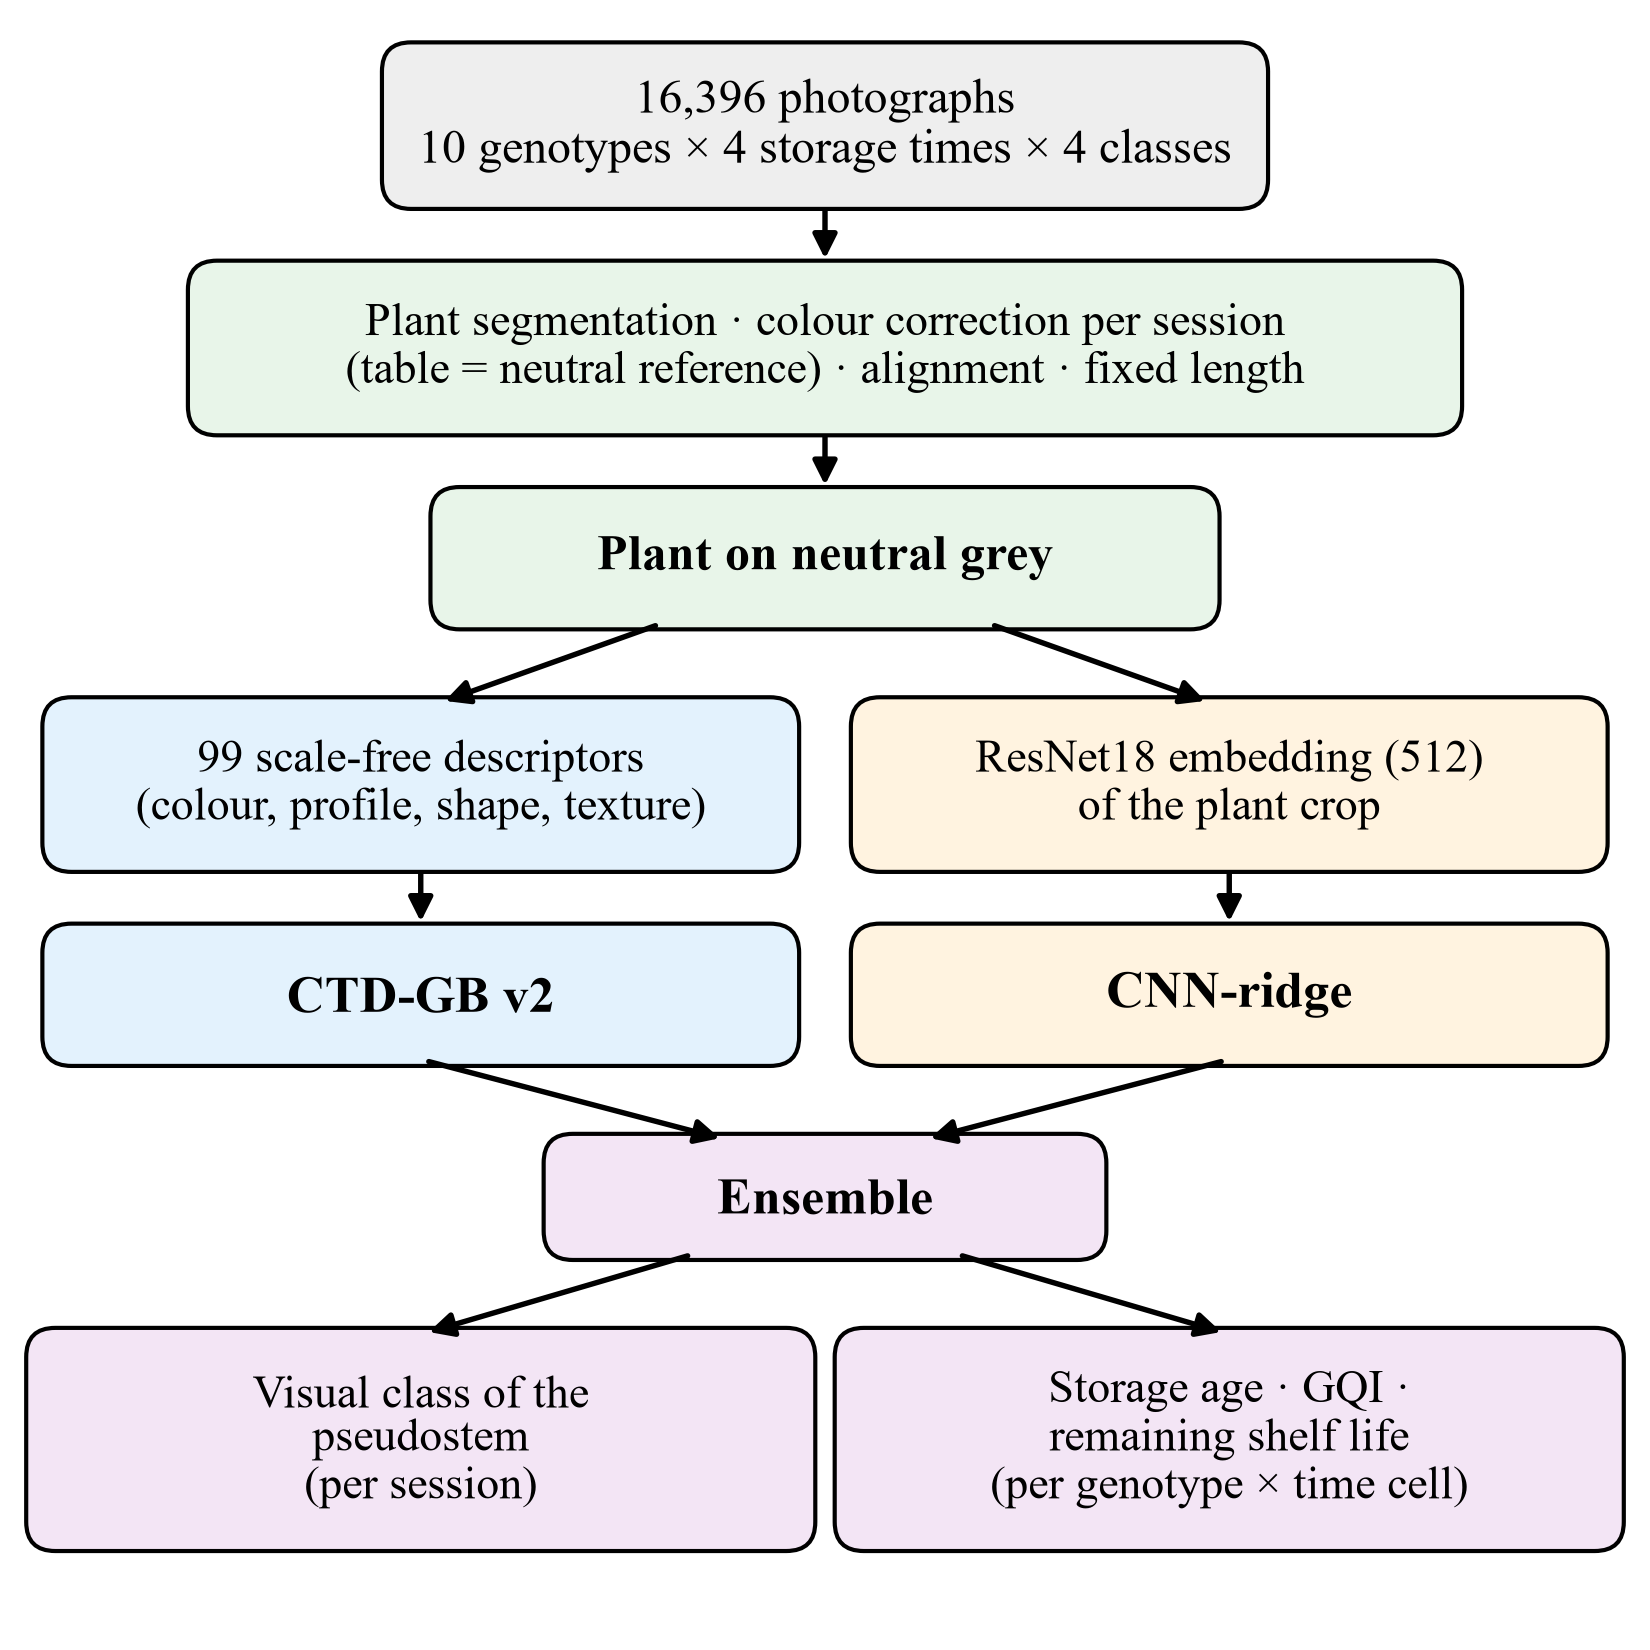

Fig. 6, panel A:
  · workflow of Phase 3: the models never see the background; each output is evaluated in its own unit
  · CTD-GB v2 = gradient boosting on the descriptors; CNN-ridge = ridge / multinomial logistic regression on the frozen ResNet18 embedding; Ensemble = mean of both (probabilities for the class)


In [15]:
# ---- Fig. 6A: flujo de la Fase 3 (esquema)
from matplotlib.patches import FancyBboxPatch, Rectangle

fig = plt.figure(figsize=PANEL, layout=None); ax = fig.add_axes([0.01, 0.01, 0.98, 0.98]); ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")


def caja(x, y, w, h, texto, fc, fs=12, negrita=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.18", fc=fc, ec="black", lw=1.0))
    ax.text(x + w / 2, y + h / 2, texto, ha="center", va="center", fontsize=fs, fontweight="bold" if negrita else "normal", linespacing=1.15)


def flecha(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=1.3, color="black", mutation_scale=12))


caja(2.3, 8.85, 5.4, 0.95, f"{len(df):,} photographs\n10 genotypes × 4 storage times × 4 classes", "#EEEEEE", fs=11.5)
flecha(5, 8.85, 5, 8.45)
caja(1.1, 7.45, 7.8, 1.0, "Plant segmentation · colour correction per session\n(table = neutral reference) · alignment · fixed length", "#E8F5E9", fs=11)
flecha(5, 7.45, 5, 7.05)
caja(2.6, 6.25, 4.8, 0.8, "Plant on neutral grey", "#E8F5E9", fs=12, negrita=True)
flecha(4.0, 6.25, 2.6, 5.75); flecha(6.0, 6.25, 7.4, 5.75)
caja(0.2, 4.75, 4.6, 1.0, "99 scale-free descriptors\n(colour, profile, shape, texture)", "#E3F2FD", fs=11)
caja(5.2, 4.75, 4.6, 1.0, "ResNet18 embedding (512)\nof the plant crop", "#FFF3E0", fs=11)
flecha(2.5, 4.75, 2.5, 4.35); flecha(7.5, 4.75, 7.5, 4.35)
caja(0.2, 3.55, 4.6, 0.8, "CTD-GB v2", "#E3F2FD", fs=12.5, negrita=True)
caja(5.2, 3.55, 4.6, 0.8, "CNN-ridge", "#FFF3E0", fs=12.5, negrita=True)
flecha(2.5, 3.55, 4.4, 3.05); flecha(7.5, 3.55, 5.6, 3.05)
caja(3.3, 2.35, 3.4, 0.7, "Ensemble", "#F3E5F5", fs=12.5, negrita=True)
flecha(4.2, 2.35, 2.5, 1.85); flecha(5.8, 2.35, 7.5, 1.85)
caja(0.1, 0.55, 4.8, 1.3, "Visual class of the\npseudostem\n(per session)", "#F3E5F5", fs=11)
caja(5.1, 0.55, 4.8, 1.3, "Storage age · GQI ·\nremaining shelf life\n(per genotype × time cell)", "#F3E5F5", fs=11)
FIGID["id"] = "6A"
mostrar(fig)
nota("workflow of Phase 3: the models never see the background; each output is evaluated in its own unit",
     "CTD-GB v2 = gradient boosting on the descriptors; CNN-ridge = ridge / multinomial logistic regression on the frozen ResNet18 "
     "embedding; Ensemble = mean of both (probabilities for the class)")

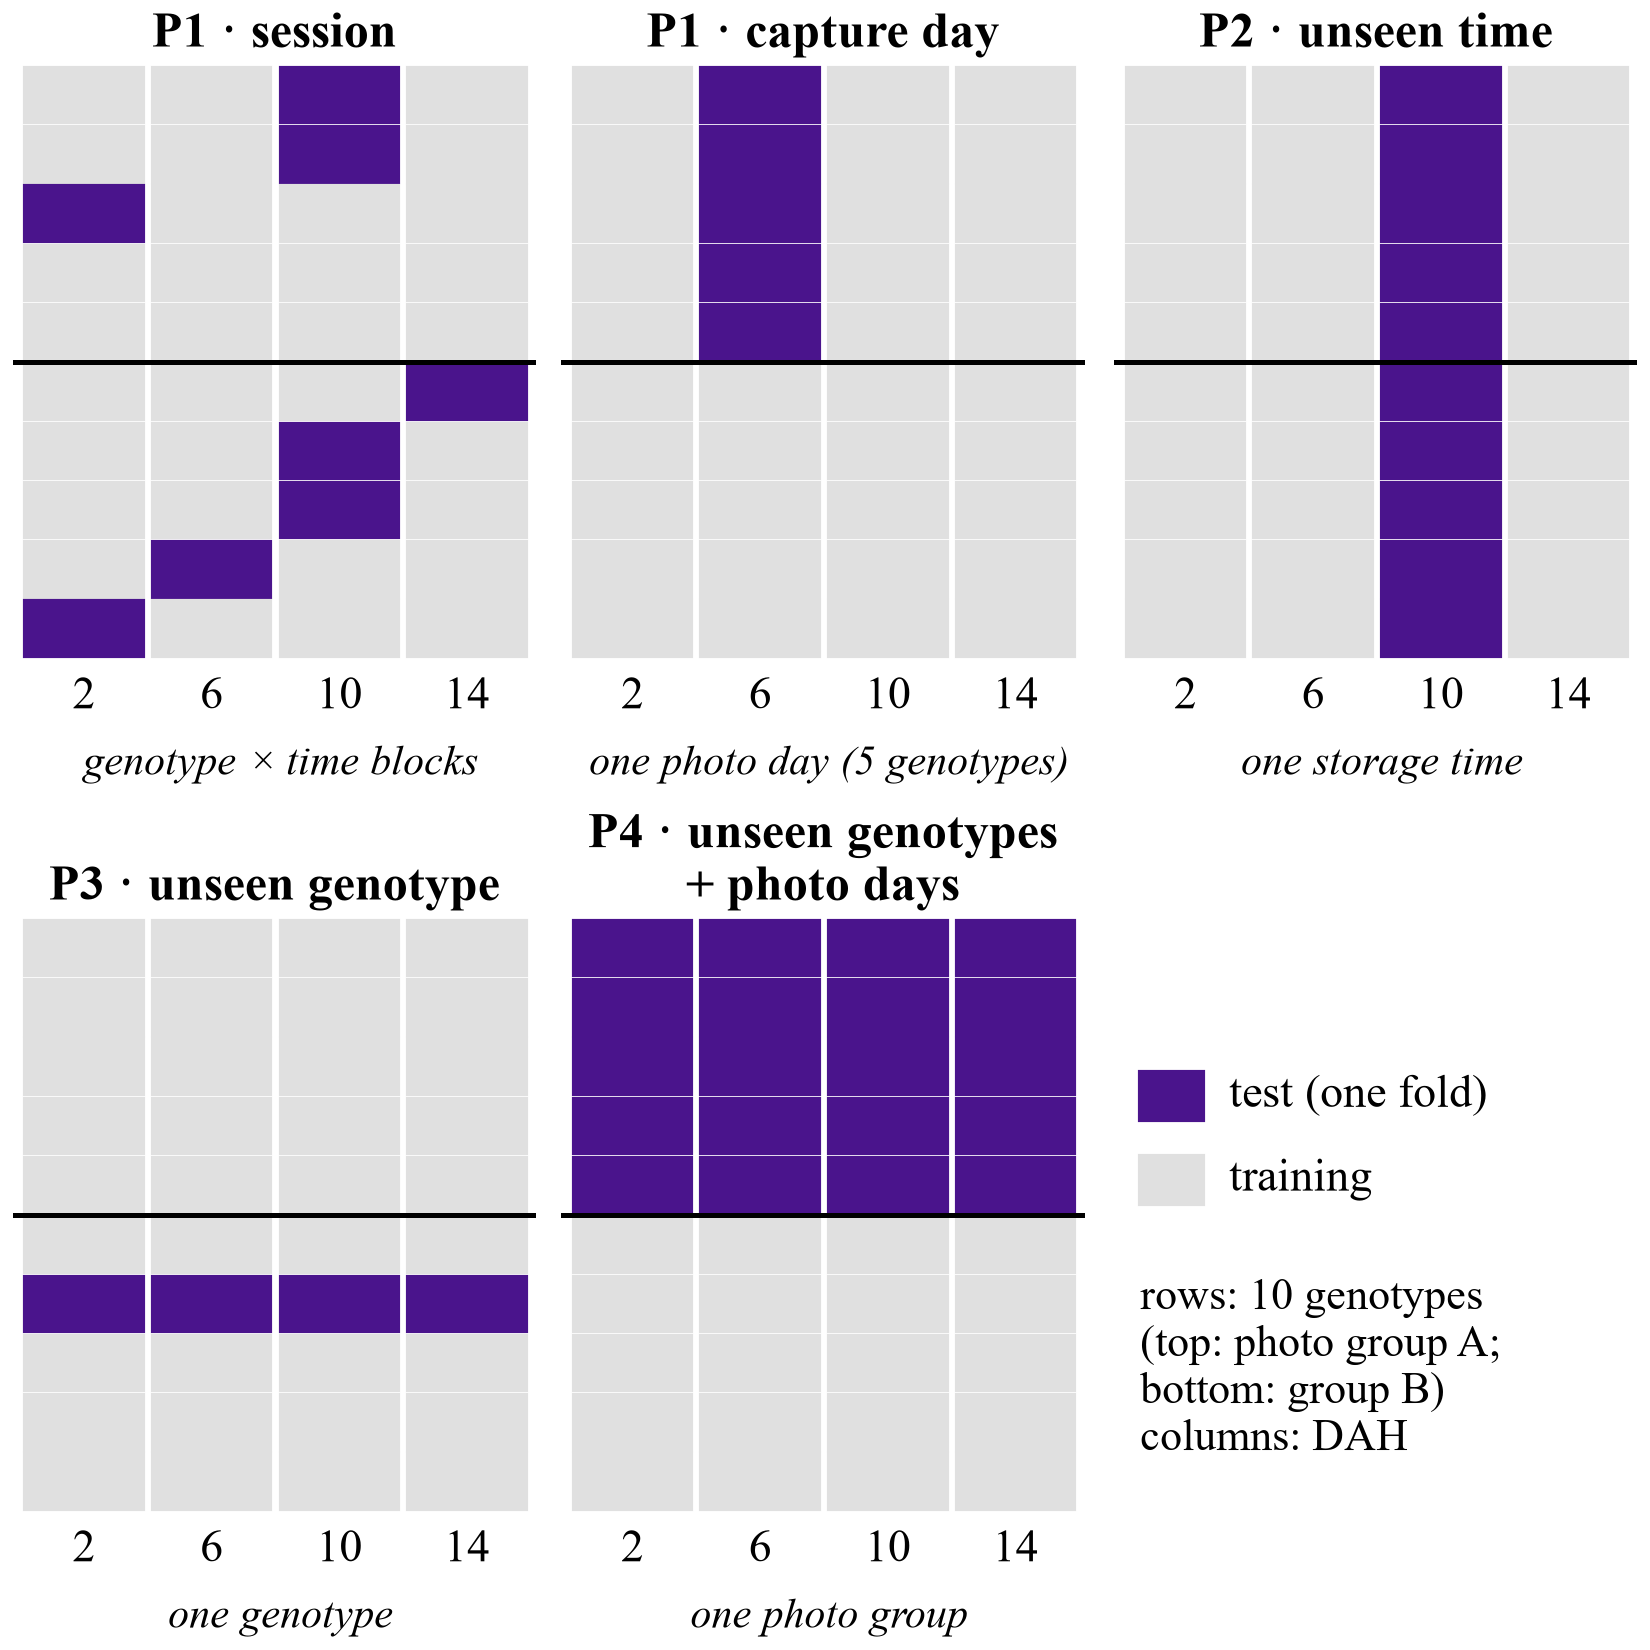

Fig. 6, panel B:
  · cells of the 10 genotypes × 4 storage times grid that are in the test set of one fold (dark) under each protocol
  · photo group A = 91400028, 91400035, ANTSON013, CUNSBR048, NDSCAR038; group B = 91400070, 91400071, ANTSNC003, ANTSRO029, ANTSRO030; P1 · session shows one of its five random folds


In [16]:
# ---- Fig. 6B: qué queda en prueba en cada protocolo (esquema sobre la grilla genotipo × tiempo)
GROUP_A = list(LOT_A); GROUP_B = sorted(set(df["geno"]) - set(GROUP_A)); GG = GROUP_A + GROUP_B
rng_s = np.random.default_rng(3)
p1 = np.zeros((10, 4), bool); p1.flat[rng_s.choice(40, 8, replace=False)] = True
dd = np.zeros((10, 4), bool); dd[:5, 1] = True
p2 = np.zeros((10, 4), bool); p2[:, 2] = True
p3 = np.zeros((10, 4), bool); p3[6, :] = True
p4 = np.zeros((10, 4), bool); p4[:5, :] = True
PROT = [("P1 · session", p1, "genotype × time blocks"), ("P1 · capture day", dd, "one photo day (5 genotypes)"),
        ("P2 · unseen time", p2, "one storage time"), ("P3 · unseen genotype", p3, "one genotype"),
        ("P4 · unseen genotypes\n+ photo days", p4, "one photo group")]
fig, axs = plt.subplots(2, 3, figsize=PANEL, layout=None)
for axx, (name, m, sub) in zip(axs.ravel(), PROT):
    for i in range(10):
        for j in range(4):
            axx.add_patch(Rectangle((j, 9 - i), 0.92, 0.92, color="#4A148C" if m[i, j] else "#E0E0E0"))
    axx.axhline(5 - 0.04, color="black", lw=1.2)
    axx.set_xlim(-0.1, 4); axx.set_ylim(-0.1, 10)
    axx.set_xticks([0.46, 1.46, 2.46, 3.46]); axx.set_xticklabels(["2", "6", "10", "14"], fontsize=11)
    axx.set_yticks([]); axx.tick_params(length=0)
    for sp in axx.spines.values():
        sp.set_visible(False)
    axx.set_title(name, fontsize=12, fontweight="bold", pad=4)
    axx.text(2, -2.0, sub, ha="center", fontsize=10, style="italic")
axx = axs.ravel()[5]; axx.axis("off")
axx.add_patch(Rectangle((0.05, 0.66), 0.12, 0.08, color="#4A148C", transform=axx.transAxes))
axx.text(0.22, 0.70, "test (one fold)", transform=axx.transAxes, va="center", fontsize=11)
axx.add_patch(Rectangle((0.05, 0.52), 0.12, 0.08, color="#E0E0E0", transform=axx.transAxes))
axx.text(0.22, 0.56, "training", transform=axx.transAxes, va="center", fontsize=11)
axx.text(0.05, 0.40, "rows: 10 genotypes\n(top: photo group A;\nbottom: group B)\ncolumns: DAH", transform=axx.transAxes, va="top", fontsize=10.5)
fig.subplots_adjust(left=0.03, right=0.98, top=0.92, bottom=0.08, wspace=0.25, hspace=0.55)
FIGID["id"] = "6B"
mostrar(fig)
nota("cells of the 10 genotypes × 4 storage times grid that are in the test set of one fold (dark) under each protocol",
     f"photo group A = {', '.join(GROUP_A)}; group B = {', '.join(GROUP_B)}; P1 · session shows one of its five random folds")

In [17]:
VAL2 = load_pickle(V2 / "validation_v2.pkl")
vd = VAL2["df"]
assert (vd["ruta"].to_numpy() == df["ruta"].to_numpy()).all()
assert np.allclose(vd["gqi_e2"].to_numpy(), df["gqi"].to_numpy()) and np.allclose(vd["rsl"].to_numpy(), df["rsl"].to_numpy())
OKV = np.asarray(VAL2["ok"], bool)
VAL1 = load_pickle(CACHE / "validation.pkl")          # versión anterior (P1, P1_day, P2, P3)
SCH = ["P1", "P1_day", "P2", "P3", "P4_lot"]
SCHEME_LABEL = {"P1": "P1 · session", "P1_day": "P1 · capture day", "P2": "P2 · unseen time", "P3": "P3 · unseen genotype",
                "P4_lot": "P4 · unseen genotypes and photo days"}
XT = ["P1\nsession", "P1\ncapture\nday", "P2\nunseen\ntime", "P3\nunseen\ngenotype", "P4\nunseen\ngenotypes\n+ days"]
NAME = {"Ens": "Ensemble", "M1": "CTD-GB v2", "M2": "CNN-ridge"}
OUTPUTS = {"dah": "Days after harvest (d)", "rsl": "Remaining shelf life (d)", "gqi_e2": "GQI"}
REFS = ["Trivial", "DAH only", "Genotype only", "Genotype + DAH"]
for k, S in VAL2["schemes"].items():
    qq = S["q"]
    print(f"{k}: {len(qq)} pliegues · regularización elegida (mediana): Ridge DAH α = {qq['alpha|dah'].median():.0f}, "
          f"GQI α = {qq['alpha|gqi_e2'].median():.0f}, logística C = {qq['alpha|class'].median():.0e}")

CELL, SESSION, PSEUDO, GENO = (vd[c].to_numpy() for c in ["block", "session", "pseudo", "geno"])
YC = vd["calidad_idx"].to_numpy()
B = 2000


def cl_of(sc, geno, block):
    return geno if sc.startswith(("P3", "P4")) else block


def wboot(K, seed):
    return np.random.default_rng(seed).multinomial(K, np.full(K, 1 / K), size=B).astype(float)


def unit_means(v, unit, mask):
    """Media por unidad (celda, sesión o pseudotallo) de un vector o matriz de predicciones, solo con fotos válidas."""
    s = pd.DataFrame(np.asarray(v, float).reshape(len(unit), -1)[mask]).groupby(unit[mask]).mean()
    return s


def reg_level(sc, P, key, t, level, mask=None):
    """(y, p, conglomerado) por foto o por celda para la salida t."""
    mask = OKV & np.isfinite(P[key]) if mask is None else mask
    y = vd[t].to_numpy(float)
    if level == "photo":
        return y[mask], P[key][mask], cl_of(sc, GENO, CELL)[mask]
    pm = unit_means(P[key], CELL, mask)[0]
    ym = pd.Series(y[mask]).groupby(CELL[mask]).mean().loc[pm.index]
    g = pd.Series(GENO[mask]).groupby(CELL[mask]).first().loc[pm.index]
    return ym.to_numpy(), pm.to_numpy(), cl_of(sc, g.to_numpy(), pm.index.to_numpy())


def reg_stats(y, p, cl, Wb, pref=None):
    """R² y MAE con IC por conglomerados; con pref, también la diferencia pareada (p − pref)."""
    k = pd.factorize(cl)[0]
    S = lambda v: np.bincount(k, weights=np.asarray(v, float), minlength=Wb.shape[1])
    n, sy, syy = S(np.ones_like(y)), S(y), S(y ** 2)
    def r2(sse, w): return 1 - (w @ sse) / ((w @ syy) - (w @ sy) ** 2 / (w @ n))
    def mae(sae, w): return (w @ sae) / (w @ n)
    one = np.ones((1, Wb.shape[1]))
    sse, sae = S((y - p) ** 2), S(np.abs(y - p))
    out = {"R2": r2(sse, one)[0], "R2_ci": np.nanpercentile(r2(sse, Wb), [2.5, 97.5]),
           "MAE": mae(sae, one)[0], "MAE_ci": np.nanpercentile(mae(sae, Wb), [2.5, 97.5])}
    if pref is not None:
        sse0, sae0 = S((y - pref) ** 2), S(np.abs(y - pref))
        d = r2(sse, Wb) - r2(sse0, Wb); dm = mae(sae, Wb) - mae(sae0, Wb)
        out.update({"dR2": r2(sse, one)[0] - r2(sse0, one)[0], "dR2_ci": np.nanpercentile(d, [2.5, 97.5]),
                    "dMAE": mae(sae, one)[0] - mae(sae0, one)[0], "dMAE_ci": np.nanpercentile(dm, [2.5, 97.5])})
    return out


QW = np.array([[(i - j) ** 2 / 9 for j in range(4)] for i in range(4)]).ravel()


def class_stats(sc, P, key, level, mask=None, labels=False):
    """Exactitud, kappa ponderado cuadrático y exactitud ±1 clase por foto, pseudotallo o sesión, con IC."""
    pr = P[key]
    if labels:                     # la versión anterior guardó la clase predicha, no probabilidades
        pr = np.eye(4)[np.asarray(pr, int)]
    mask = OKV & np.isfinite(pr).all(1) if mask is None else mask
    unit = {"photo": np.arange(len(vd)), "pseudo": PSEUDO, "session": SESSION}[level]
    pm = unit_means(pr, unit, mask)
    yt = pd.Series(YC[mask]).groupby(unit[mask]).first().loc[pm.index].to_numpy()
    g = pd.Series(GENO[mask]).groupby(unit[mask]).first().loc[pm.index].to_numpy()
    b = pd.Series(CELL[mask]).groupby(unit[mask]).first().loc[pm.index].to_numpy()
    yp = pm.to_numpy().argmax(1)
    cl = cl_of(sc, g, b); k, u = pd.factorize(cl)
    Wb = wboot(len(u), 7)
    one = np.ones((1, len(u)))
    Ocl = np.zeros((len(u), 16)); np.add.at(Ocl, (k, yt * 4 + yp), 1)        # matriz de confusión de cada conglomerado
    Acl = np.bincount(k, weights=(np.abs(yt - yp) <= 1).astype(float), minlength=len(u))
    def stats(w):
        O = w @ Ocl; tot = O.sum(1, keepdims=True)
        acc = O[:, [0, 5, 10, 15]].sum(1) / tot[:, 0]
        adj = (w @ Acl) / tot[:, 0]
        O4 = O.reshape(-1, 4, 4); E = (O4.sum(2)[:, :, None] * O4.sum(1)[:, None, :] / tot[:, :, None]).reshape(-1, 16)
        kap = 1 - (O @ QW) / (E @ QW)
        return acc, kap, adj
    a1, k1, j1 = stats(one); ab, kb, jb = stats(Wb)
    pc = lambda v: np.nanpercentile(v, [2.5, 97.5])
    return {"acc": a1[0], "acc_ci": pc(ab), "qwk": k1[0], "qwk_ci": pc(kb), "adj": j1[0], "adj_ci": pc(jb), "n": len(yt),
            "cm": pd.crosstab(pd.Categorical(yt, range(4)), pd.Categorical(yp, range(4)), dropna=False).to_numpy()}


fmt = lambda v, ci, d=2: f"{v:.{d}f} [{ci[0]:.{d}f}, {ci[1]:.{d}f}]"
fmt_no_ci = lambda v, d=2: f"{v:.{d}f}"
print("listo")

P3: 10 pliegues · regularización elegida (mediana): Ridge DAH α = 100, GQI α = 100, logística C = 1e-04
P4_lot: 2 pliegues · regularización elegida (mediana): Ridge DAH α = 174, GQI α = 174, logística C = 1e-04
P1_day: 8 pliegues · regularización elegida (mediana): Ridge DAH α = 208, GQI α = 100, logística C = 1e-04
P2: 4 pliegues · regularización elegida (mediana): Ridge DAH α = 66, GQI α = 100, logística C = 1e-04
P1: 5 pliegues · regularización elegida (mediana): Ridge DAH α = 100, GQI α = 100, logística C = 1e-04
P1#43: 5 pliegues · regularización elegida (mediana): Ridge DAH α = 32, GQI α = 100, logística C = 1e-04
P1#44: 5 pliegues · regularización elegida (mediana): Ridge DAH α = 100, GQI α = 100, logística C = 1e-04
P1#45: 5 pliegues · regularización elegida (mediana): Ridge DAH α = 100, GQI α = 100, logística C = 1e-04
P1#46: 5 pliegues · regularización elegida (mediana): Ridge DAH α = 32, GQI α = 100, logística C = 1e-04
listo


### 3.2 Por qué se valida con unidades completas: escalera de fuga

Control recomendado por Kapoor y Narayanan (2023) y Roberts et al. (2017): el **mismo modelo** se valida con
particiones cada vez más estrictas, desde la foto al azar (sin agrupar) hasta el genotipo no visto. La caída
entre la foto al azar y las particiones por sesión mide cuánto del desempeño venía de reconocer la sesión. Se
compara la versión anterior (CTD-GB v1, segmentación anterior) con la versión 2 (planta sola, color corregido):
si el procesamiento quitó el atajo, la caída debe ser menor.

In [18]:
LAD2 = load_pickle(V2 / "ladder_v2.pkl")
assert (LAD2["df"]["ruta"].to_numpy() == df["ruta"].to_numpy()).all()
LAD1 = load_pickle(CACHE / "leakage_ladder.pkl")
LADDER = [("Random photo", "photo", "photo"), ("Pseudostem", "pseudo", "tramo"), ("Session", "session", "folder"),
          ("Block (genotype × time)", "P1", "block"), ("Capture day", "P1_day", "day"), ("Unseen time (P2)", "P2", "P2_time"),
          ("Unseen genotype (P3)", "P3", "P3_genotype")]
y_dah, y_gqi = vd["dah"].to_numpy(float), vd["gqi_e2"].to_numpy(float)
r2 = lambda y, p: 1 - np.nansum((y - p) ** 2) / np.nansum((y - np.nanmean(y)) ** 2)
rows = []
for lab_, k2, k1 in LADDER:
    P2_ = LAD2["schemes"][k2]["pred"] if k2 in LAD2["schemes"] else VAL2["schemes"][k2]["pred"]
    P1_ = LAD1["pred"][k1]
    m = OKV & np.isfinite(P2_["Ens|dah"])
    rows.append({"Partition": lab_,
                 "R² DAH, v1": r2(y_dah, P1_["CTD-GB|dah"]), "R² DAH, v2": r2(y_dah[m], P2_["Ens|dah"][m]),
                 "R² GQI, v1": r2(y_gqi, P1_["CTD-GB|gqi_e2"]), "R² GQI, v2": r2(y_gqi[m], P2_["Ens|gqi_e2"][m]),
                 "Accuracy, v1": np.mean(P1_["CTD-GB|class"] == YC), "Accuracy, v2": np.mean(P2_["Ens|class"][m].argmax(1) == YC[m])})
TABLE_S7D = pd.DataFrame(rows).round(2)
print("Detail table D10 (→ Table 3a). The same models validated with partitions from ungrouped (random photograph) to unseen genotype, per photograph; "
      "v1 = CTD-GB with the previous segmentation, v2 = Ensemble on the plant alone")
display(TABLE_S7D)
gap = lambda c: TABLE_S7D.loc[0, c] - TABLE_S7D.loc[2, c]
print("caída de la foto al azar a la sesión: " + ", ".join(f"{c}: {gap(c):.2f}" for c in TABLE_S7D.columns[1:]))

Detail table D10 (→ Table 3a). The same models validated with partitions from ungrouped (random photograph) to unseen genotype, per photograph; v1 = CTD-GB with the previous segmentation, v2 = Ensemble on the plant alone


,Partition,"R² DAH, v1","R² DAH, v2","R² GQI, v1","R² GQI, v2","Accuracy, v1","Accuracy, v2"
0,Random photo,0.90,0.86,0.90,0.85,0.94,0.96
1,Pseudostem,0.73,0.77,0.74,0.76,0.68,0.79
2,Session,0.58,0.63,0.62,0.63,0.42,0.44
3,Block (genotype × time),0.47,0.56,0.55,0.56,0.49,0.50
4,Capture day,0.14,0.29,0.33,0.46,0.48,0.47
5,Unseen time (P2),-0.25,-0.05,0.26,0.46,0.49,0.48
6,Unseen genotype (P3),0.50,0.59,0.48,0.45,0.48,0.52


caída de la foto al azar a la sesión: R² DAH, v1: 0.32, R² DAH, v2: 0.23, R² GQI, v1: 0.28, R² GQI, v2: 0.22, Accuracy, v1: 0.52, Accuracy, v2: 0.52


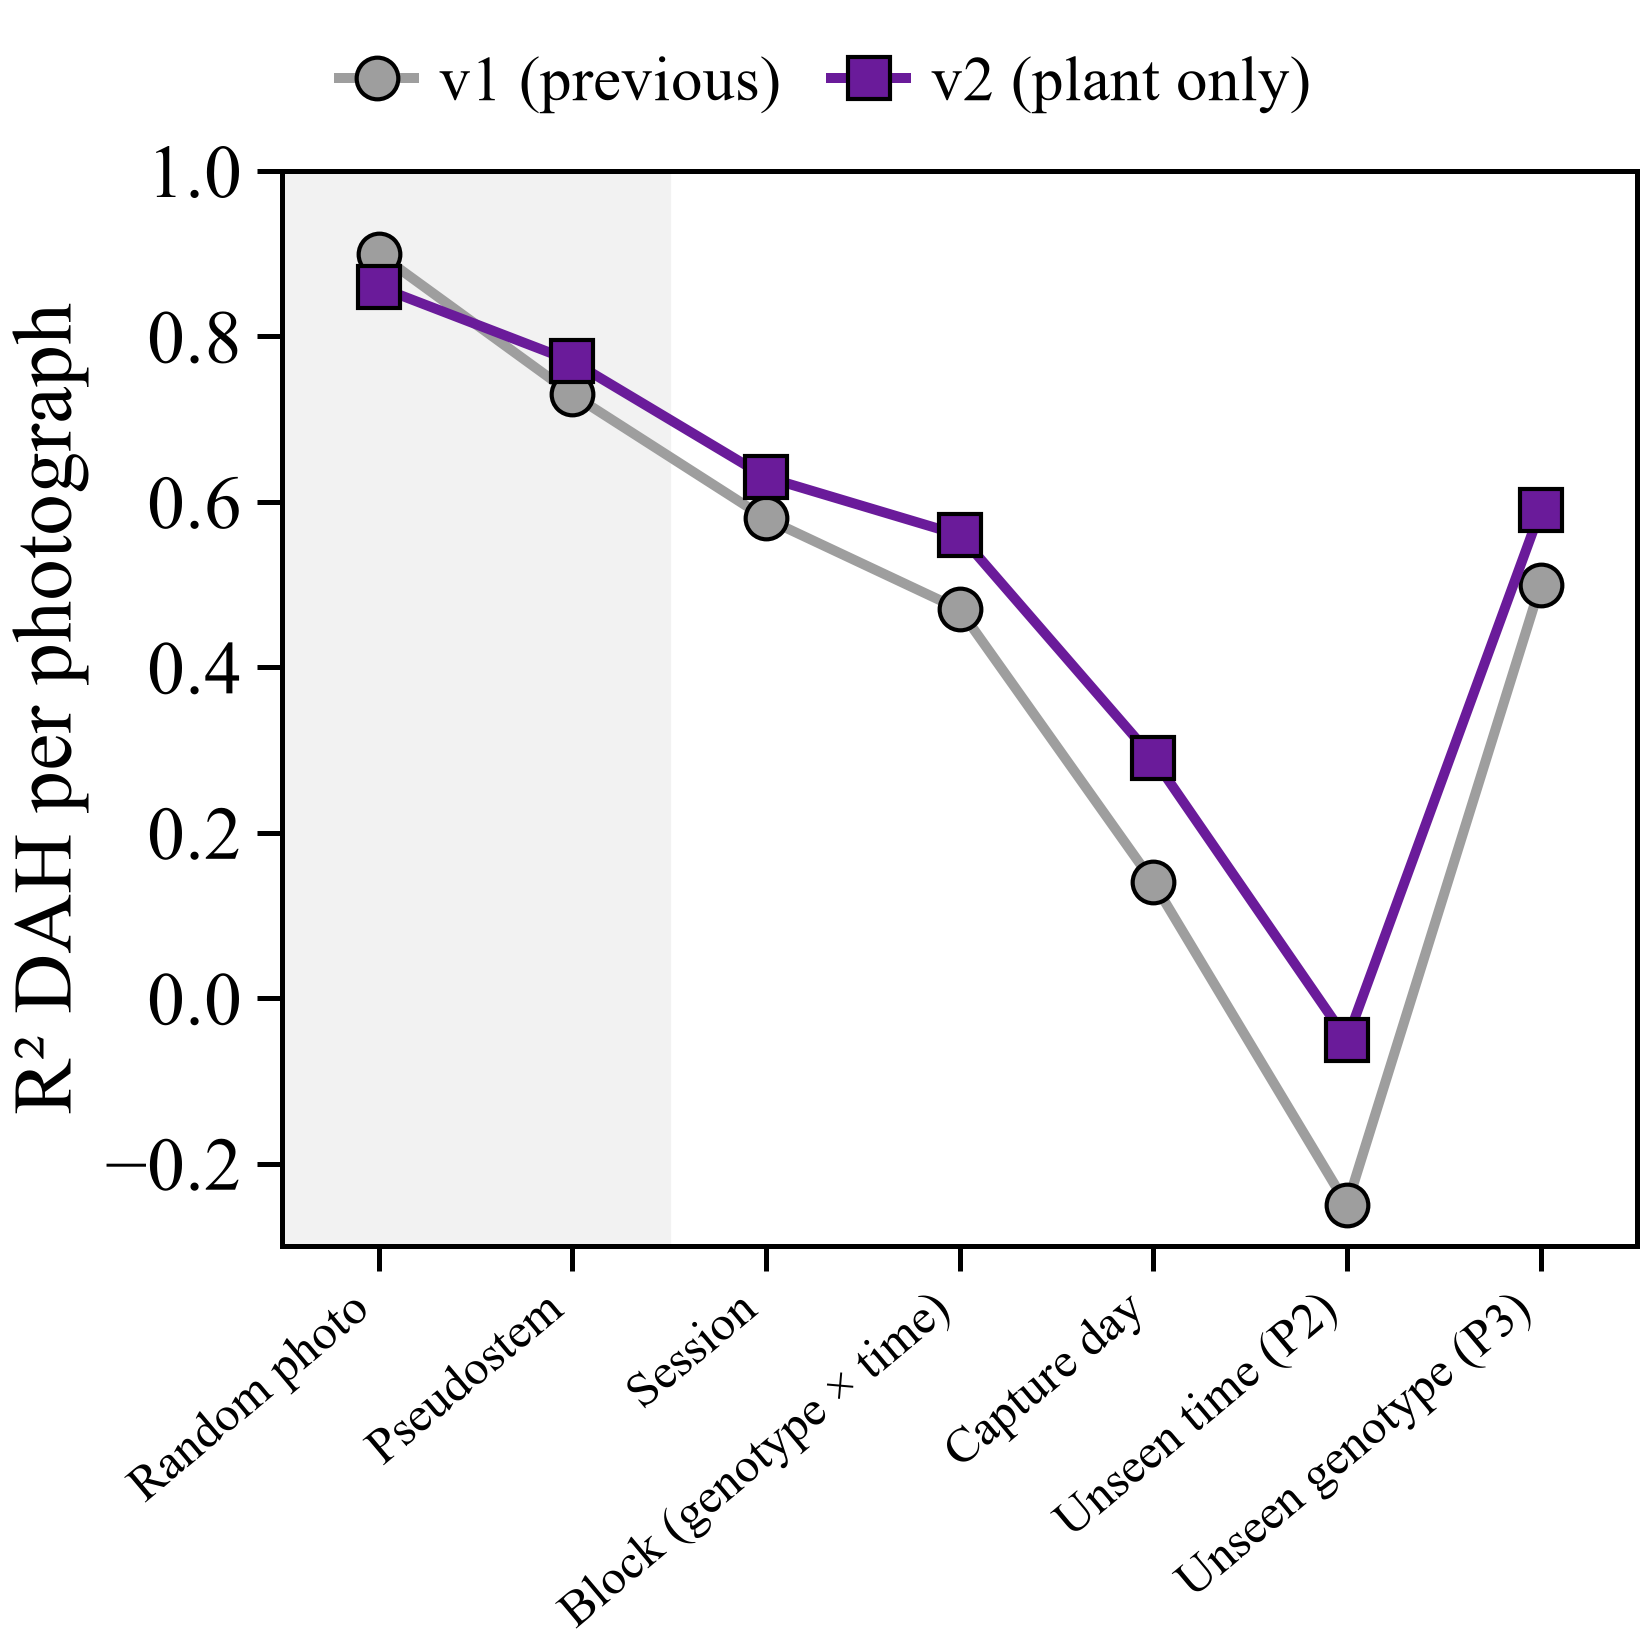

Fig. 6, panel C:
  · the same model validated with partitions of increasing strictness; grey band = partitions that leave other photographs of the same session in training
  · the drop from the grey band to the session-level partitions is the part of the performance that came from recognising the session


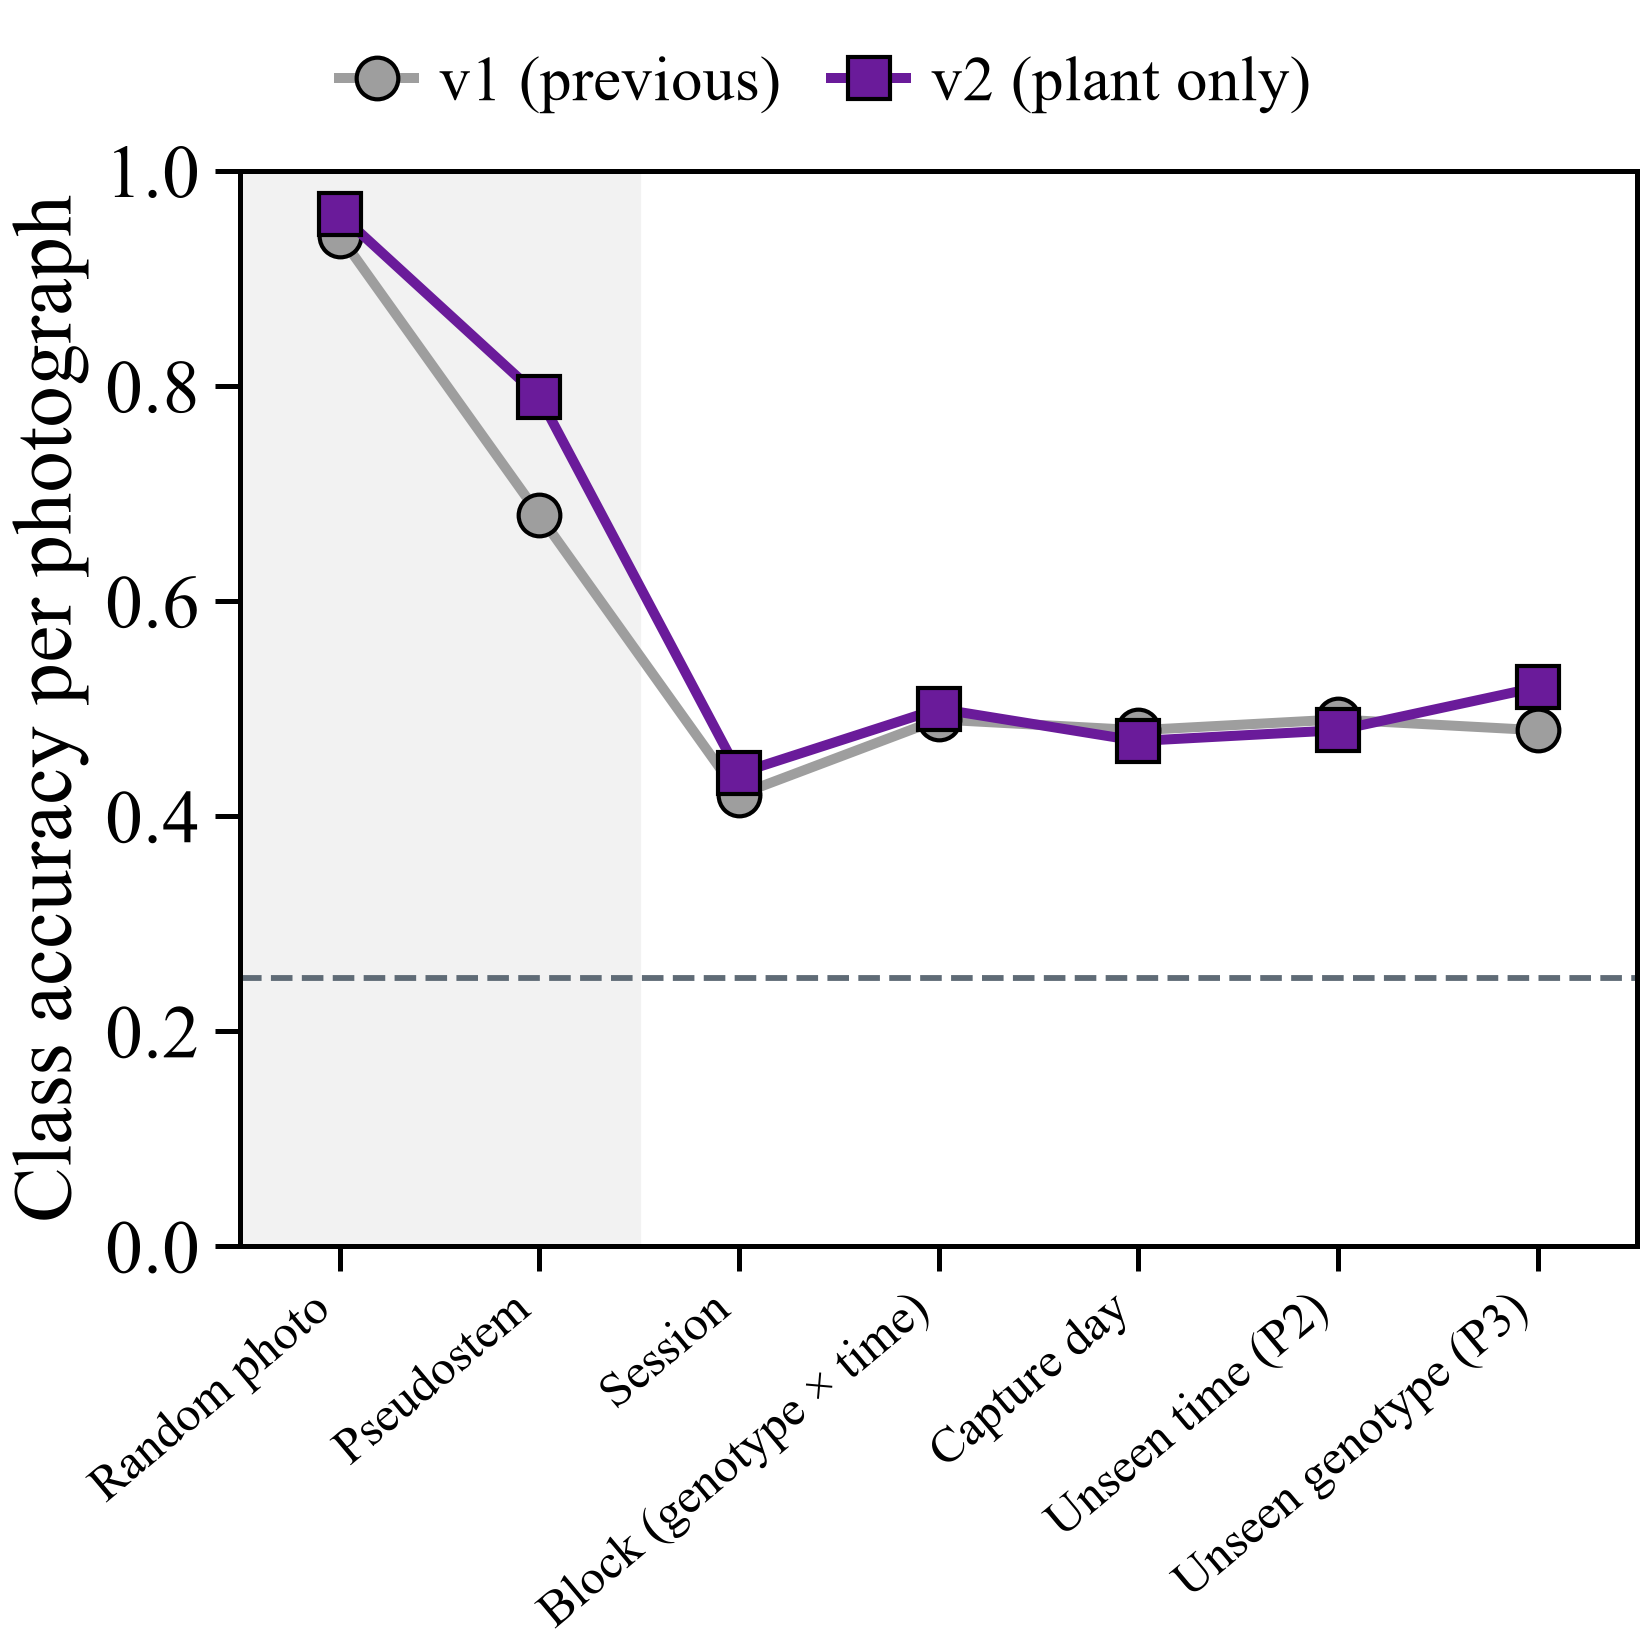

Fig. S2, panel B:
  · the same model validated with partitions of increasing strictness; grey band = partitions that leave other photographs of the same session in training
  · the drop from the grey band to the session-level partitions is the part of the performance that came from recognising the session


In [19]:
# ---- Fig. S2B (clase) y Fig. 6C (DAH): escalera de fuga, v1 frente a v2
for tag, (c1, c2, ylab) in [("6C", ("R² DAH, v1", "R² DAH, v2", "R² DAH per photograph")),
                             ("S2B", ("Accuracy, v1", "Accuracy, v2", "Class accuracy per photograph"))]:
    fig, ax = panel()
    x = np.arange(len(LADDER))
    ax.plot(x, TABLE_S7D[c1], marker="o", color="#9E9E9E", mec="black", ms=10, label="v1 (previous)")
    ax.plot(x, TABLE_S7D[c2], marker="s", color=MODEL_COLOR["Ensemble"], mec="black", ms=10, label="v2 (plant only)")
    ax.axvspan(-0.5, 1.5, color="#F2F2F2", zorder=0)
    if "Accuracy" in c1:
        ax.axhline(0.25, color=MUTED, ls="--", lw=1.4)
    ax.set_xticks(x); ax.set_xticklabels([l[0] for l in LADDER], rotation=40, ha="right", fontsize=12)
    ax.set_ylabel(ylab); ax.set_ylim(0 if "Accuracy" in c1 else -0.3, 1.0); ax.set_xlim(-0.5, len(LADDER) - 0.5)
    leyenda_arriba(fig, ax, ncol=2)
    titulo(ax, tag)
    mostrar(fig)
    nota("the same model validated with partitions of increasing strictness; grey band = partitions that leave other photographs of the same "
         "session in training",
         "the drop from the grey band to the session-level partitions is the part of the performance that came from recognising the session")

**Lectura.** Con la foto al azar el modelo acierta casi siempre (exactitud 0,96; R² del DAH 0,86) porque en
entrenamiento hay otras fotos casi idénticas del mismo pseudotallo; al dejar fuera sesiones completas cae a
0,44 y 0,63. Esa caída no es el fondo (que ya no está), sino las **ráfagas de fotos del mismo pseudotallo**: por
eso todas las métricas del artículo se dan con sesiones, días, tiempos, genotipos o grupos de fotografía completos fuera, nunca
con fotos al azar. Frente a la versión anterior, la planta sola **pierde menos** al pasar a particiones más
estrictas en el DAH (caída del R² de la foto al azar a la sesión 0,23 frente a 0,32) y su R² del DAH es más alto
en todos los peldaños por sesión, día, tiempo y genotipo (con el día de captura fuera, 0,29 frente a 0,14). En el
GQI, la versión 2 es más alta con el día de captura o el tiempo fuera (0,46 frente a 0,33 y 0,26) y parecida en los
demás peldaños; en la clase por foto las dos versiones quedan parecidas (0,44–0,52).

# 4. Desempeño en cada protocolo — dónde funciona la foto y dónde no

**Qué responde.** Cuánto acierta la foto en cada salida cuando quedan fuera sesiones, días de foto, tiempos,
genotipos o grupos de fotografía completos, comparada con lo que se obtiene solo con los metadatos.

**Paneles y por qué van juntos** → **Fig. 7** (artículo, tercer paso del proceso). Los cuatro comparten el eje x (los
cinco protocolos, de más fácil a más difícil) para leerlos de un vistazo: **A** clase visual por sesión; **B** edad de la
muestra (DAH) por celda; **C** GQI por celda; **D** vida útil restante por celda. Cada salida va con sus referencias.

**Tablas de detalle:** D6 validación completa · D7 diferencias frente a solo DAH · D8 versión anterior frente a la
nueva · D9 estabilidad de P1. D6, D7 y D9 se resumen en la **Tabla 2** del artículo (sección 8).

### 4.1 Validación completa y figuras por protocolo

**Tabla D6**: cada salida en su unidad de evaluación, los tres modelos y las cuatro referencias, en los cinco
protocolos. La **Tabla 2** del artículo (sección 8) la resume junto con las diferencias frente a solo DAH (D7). P3
(genotipo no visto) es el resultado de generalización.

In [20]:
REG_ROWS = [("Ens", "Ensemble"), ("M1", "CTD-GB v2"), ("M2", "CNN-ridge")] + [(r, r) for r in REFS]
CLS_ROWS = [("Ens", "Ensemble"), ("M1", "CTD-GB v2"), ("M2", "CNN-ridge"), ("Trivial", "Trivial"), ("DAH only", "DAH only"),
            ("Genotype only", "Genotype only")]
RES = []          # todas las métricas en formato largo
for sc in SCH:
    P = VAL2["schemes"][sc]["pred"]
    for level in ["cell", "photo"]:
        Wcache = {}
        for t in OUTPUTS:
            for key, name in REG_ROWS + [("Ens+DAH", "Ensemble + DAH"), ("M1+DAH", "CTD-GB v2 + DAH"), ("M2+DAH", "CNN-ridge + DAH")]:
                kk = f"{key}|{t}"
                if kk not in P:
                    continue
                y, p, cl = reg_level(sc, P, kk, t, level, mask=OKV & np.isfinite(P[f"Ens|{t}"]))
                yr, pr_, _ = reg_level(sc, P, f"DAH only|{t}", t, level, mask=OKV & np.isfinite(P[f"Ens|{t}"]))
                K = len(np.unique(cl))
                Wb = Wcache.setdefault(K, wboot(K, 11))
                s = reg_stats(y, p, cl, Wb, pref=pr_)
                RES.append({"scheme": sc, "level": level, "output": t, "model": name, **s})
    for level in ["session", "pseudo", "photo"]:
        for key, name in CLS_ROWS + [("Ens+DAH", "Ensemble + DAH")]:
            if f"{key}|class" in P:
                s = class_stats(sc, P, f"{key}|class", level)
                RES.append({"scheme": sc, "level": level, "output": "class", "model": name, **s})
RES = pd.DataFrame(RES)


def cellfmt(r, metric):
    if r["scheme"] == "P4_lot":
        return fmt_no_ci(r[metric])
    return fmt(r[metric], r[f"{metric}_ci"])


rows = []
for t, lab_ in [("dah", "DAH (sample age), per cell"), ("rsl", "Remaining shelf life, per cell"), ("gqi_e2", "GQI, per cell")]:
    for _, name in REG_ROWS:
        x = RES[(RES.level == "cell") & (RES.output == t) & (RES.model == name)].set_index("scheme")
        if name in ("DAH only", "Genotype + DAH") and t == "dah":
            continue
        rows.append({"Output (unit)": lab_, "Model / reference": name, "Metric": "R²",
                     **{SCHEME_LABEL[s]: cellfmt(x.loc[s].to_dict() | {"scheme": s}, "R2") for s in SCH}})
for metric, mname in [("acc", "accuracy"), ("qwk", "weighted κ")]:
    for _, name in CLS_ROWS:
        x = RES[(RES.level == "session") & (RES.output == "class") & (RES.model == name)].set_index("scheme")
        rows.append({"Output (unit)": "Visual class, per session", "Model / reference": name, "Metric": mname,
                     **{SCHEME_LABEL[s]: cellfmt(x.loc[s].to_dict() | {"scheme": s}, metric) for s in SCH}})
TABLE_1 = pd.DataFrame(rows)
print("Detail table D6 (→ Table 2). Validation of the photo models (plant only) and of the references that use only the metadata, with sessions (P1), capture days, "
      "storage times (P2), genotypes (P3) and groups of genotypes photographed on other days (P4) left out; 95% CI by cluster bootstrap (blocks in P1–P2, genotypes in P3; "
      "none in P4, two photo groups); chance accuracy = 0.25, chance κ = 0")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(TABLE_1)

Detail table D6 (→ Table 2). Validation of the photo models (plant only) and of the references that use only the metadata, with sessions (P1), capture days, storage times (P2), genotypes (P3) and groups of genotypes photographed on other days (P4) left out; 95% CI by cluster bootstrap (blocks in P1–P2, genotypes in P3; none in P4, two photo groups); chance accuracy = 0.25, chance κ = 0


,Output (unit),Model / reference,Metric,P1 · session,P1 · capture day,P2 · unseen time,P3 · unseen genotype,P4 · unseen genotypes and photo days
0,"DAH (sample age), per cell",Ensemble,R²,"0.68 [0.57, 0.75]","0.41 [0.29, 0.48]","0.06 [-0.09, 0.13]","0.71 [0.63, 0.78]",0.48
1,"DAH (sample age), per cell",CTD-GB v2,R²,"0.73 [0.61, 0.80]","0.46 [0.32, 0.54]","0.12 [-0.05, 0.21]","0.76 [0.69, 0.82]",0.53
2,"DAH (sample age), per cell",CNN-ridge,R²,"0.60 [0.48, 0.68]","0.32 [0.18, 0.41]","-0.03 [-0.20, 0.06]","0.62 [0.53, 0.70]",0.39
3,"DAH (sample age), per cell",Trivial,R²,"-0.04 [-0.19, -0.01]","-0.31 [-0.50, -0.31]","-0.78 [-1.04, -0.78]","0.00 [0.00, 0.00]",0.00
4,"DAH (sample age), per cell",Genotype only,R²,"-0.69 [-1.14, -0.43]","-0.78 [-1.03, -0.77]","-0.78 [-1.03, -0.77]","-0.00 [-0.00, -0.00]",-0.00
5,"Remaining shelf life, per cell",Ensemble,R²,"0.62 [0.47, 0.70]","0.52 [0.38, 0.58]","0.36 [0.19, 0.44]","0.61 [0.52, 0.63]",0.31
6,"Remaining shelf life, per cell",CTD-GB v2,R²,"0.68 [0.52, 0.76]","0.59 [0.46, 0.67]","0.45 [0.29, 0.55]","0.67 [0.59, 0.71]",0.39
7,"Remaining shelf life, per cell",CNN-ridge,R²,"0.53 [0.34, 0.62]","0.40 [0.25, 0.47]","0.22 [0.01, 0.32]","0.51 [0.40, 0.55]",0.16
8,"Remaining shelf life, per cell",Trivial,R²,"-0.11 [-0.27, -0.06]","-0.23 [-0.40, -0.21]","-0.52 [-0.74, -0.46]","-0.08 [-0.28, -0.06]",-0.23
9,"Remaining shelf life, per cell",DAH only,R²,"0.62 [0.41, 0.72]","0.60 [0.37, 0.72]","0.66 [0.47, 0.76]","0.59 [0.44, 0.71]",0.44


In [21]:
# ---- Tabla D7: valor añadido de la foto frente a «solo DAH» (diferencias pareadas, por celda)
rows = []
for t in ["rsl", "gqi_e2"]:
    for name in ["Ensemble", "CTD-GB v2", "CNN-ridge", "Ensemble + DAH", "Genotype + DAH"]:
        x = RES[(RES.level == "cell") & (RES.output == t) & (RES.model == name)].set_index("scheme")
        rows.append({"Output": OUTPUTS[t], "Model": name,
                     **{SCHEME_LABEL[s]: (fmt_no_ci(x.loc[s, "dR2"]) if s == "P4_lot" else fmt(x.loc[s, "dR2"], x.loc[s, "dR2_ci"])) for s in SCH}})
TABLE_S7A = pd.DataFrame(rows)
print("Detail table D7 (→ Table 2). Difference in R² per cell against the DAH-only reference (model − DAH only), paired cluster bootstrap; "
      "an interval above 0 means the photograph adds information beyond the storage days")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(TABLE_S7A)

# ---- Tabla D8: por foto, comparable con la versión anterior
rows = []
for t in OUTPUTS:
    for name in ["Ensemble", "CTD-GB v2", "CNN-ridge", "DAH only"]:
        x = RES[(RES.level == "photo") & (RES.output == t) & (RES.model == name)].set_index("scheme")
        rows.append({"Output": OUTPUTS[t], "Model": name, **{SCHEME_LABEL[s]: f"{x.loc[s, 'R2']:.2f}" for s in SCH}})
    for v1name in ["CTD-GB", "CNN-MTL"]:
        r = {"Output": OUTPUTS[t], "Model": f"{v1name} (v1)"}
        for s in SCH:
            if s in VAL1["schemes"]:
                y = vd[t].to_numpy(float); p = VAL1["schemes"][s]["pred"][f"{v1name}|{t}"]
                r[SCHEME_LABEL[s]] = f"{1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2):.2f}"
            else:
                r[SCHEME_LABEL[s]] = "—"
        rows.append(r)
for name in ["Ensemble", "CTD-GB v2", "CNN-ridge"]:
    x = RES[(RES.level == "photo") & (RES.output == "class") & (RES.model == name)].set_index("scheme")
    rows.append({"Output": "Visual class (accuracy)", "Model": name, **{SCHEME_LABEL[s]: f"{x.loc[s, 'acc']:.2f}" for s in SCH}})
for v1name in ["CTD-GB", "CNN-MTL"]:
    rows.append({"Output": "Visual class (accuracy)", "Model": f"{v1name} (v1)",
                 **{SCHEME_LABEL[s]: (f"{np.mean(VAL1['schemes'][s]['pred'][f'{v1name}|class'] == YC):.2f}" if s in VAL1["schemes"] else "—") for s in SCH}})
TABLE_S7B = pd.DataFrame(rows)
print("Detail table D8 (→ notebook only). Per-photograph R² and class accuracy of the version-2 models (plant only) and of the version-1 models "
      "(CTD-GB v1: previous segmentation; CNN-MTL v1: whole photograph with background), same protocols")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(TABLE_S7B)

# ---- Tabla D9: estabilidad entre las 5 repeticiones de P1
rows = []
reps = [k for k in VAL2["schemes"] if k == "P1" or k.startswith("P1#")]
for t in OUTPUTS:
    v = []
    for k in reps:
        P = VAL2["schemes"][k]["pred"]
        y, p, cl = reg_level("P1", P, f"Ens|{t}", t, "cell")
        v.append(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))
    rows.append({"Output (Ensemble, per cell)": OUTPUTS[t] + " — R²", "Mean": np.mean(v), "SD": np.std(v, ddof=1), "Min": np.min(v), "Max": np.max(v)})
v = [class_stats("P1", VAL2["schemes"][k]["pred"], "Ens|class", "session")["acc"] for k in reps]
rows.append({"Output (Ensemble, per cell)": "Visual class — accuracy per session", "Mean": np.mean(v), "SD": np.std(v, ddof=1), "Min": np.min(v), "Max": np.max(v)})
TABLE_S7C = pd.DataFrame(rows).round(3)
print(f"Detail table D9 (→ Table 2). Stability of P1 over {len(reps)} random partitions of the genotype × time blocks (seeds 42–46)")
display(TABLE_S7C)

Detail table D7 (→ Table 2). Difference in R² per cell against the DAH-only reference (model − DAH only), paired cluster bootstrap; an interval above 0 means the photograph adds information beyond the storage days


,Output,Model,P1 · session,P1 · capture day,P2 · unseen time,P3 · unseen genotype,P4 · unseen genotypes and photo days
0,Remaining shelf life (d),Ensemble,"0.01 [-0.11, 0.16]","-0.08 [-0.22, 0.10]","-0.31 [-0.49, -0.12]","0.02 [-0.12, 0.15]",-0.13
1,Remaining shelf life (d),CTD-GB v2,"0.06 [-0.06, 0.22]","-0.01 [-0.13, 0.18]","-0.21 [-0.37, -0.04]","0.09 [-0.06, 0.23]",-0.05
2,Remaining shelf life (d),CNN-ridge,"-0.09 [-0.23, 0.07]","-0.20 [-0.36, -0.01]","-0.45 [-0.65, -0.25]","-0.08 [-0.25, 0.05]",-0.27
3,Remaining shelf life (d),Ensemble + DAH,"0.11 [0.05, 0.21]","0.09 [0.03, 0.18]","0.01 [-0.11, 0.15]","0.11 [0.01, 0.21]",0.02
4,Remaining shelf life (d),Genotype + DAH,"0.38 [0.28, 0.59]","0.40 [0.28, 0.63]","0.34 [0.24, 0.53]","0.00 [0.00, 0.00]",0.00
5,GQI,Ensemble,"0.20 [0.05, 0.43]","0.30 [0.11, 0.63]","0.11 [-0.07, 0.38]","0.20 [0.02, 0.43]",0.35
6,GQI,CTD-GB v2,"0.25 [0.11, 0.47]","0.33 [0.13, 0.66]","0.16 [-0.02, 0.41]","0.22 [0.02, 0.47]",0.42
7,GQI,CNN-ridge,"0.11 [-0.04, 0.35]","0.25 [0.06, 0.58]","0.04 [-0.15, 0.31]","0.14 [-0.01, 0.35]",0.25
8,GQI,Ensemble + DAH,"0.23 [0.13, 0.40]","0.29 [0.18, 0.49]","0.18 [0.04, 0.41]","0.23 [0.09, 0.41]",0.25
9,GQI,Genotype + DAH,"0.29 [0.14, 0.48]","0.48 [0.27, 0.78]","0.31 [0.15, 0.53]","0.00 [0.00, 0.00]",0.00


Detail table D8 (→ notebook only). Per-photograph R² and class accuracy of the version-2 models (plant only) and of the version-1 models (CTD-GB v1: previous segmentation; CNN-MTL v1: whole photograph with background), same protocols


,Output,Model,P1 · session,P1 · capture day,P2 · unseen time,P3 · unseen genotype,P4 · unseen genotypes and photo days
0,Days after harvest (d),Ensemble,0.56,0.29,-0.05,0.59,0.33
1,Days after harvest (d),CTD-GB v2,0.56,0.26,-0.08,0.59,0.31
2,Days after harvest (d),CNN-ridge,0.42,0.17,-0.19,0.44,0.19
3,Days after harvest (d),DAH only,1.00,1.00,1.00,1.00,1.00
4,Days after harvest (d),CTD-GB (v1),0.39,0.11,-0.32,0.49,—
5,Days after harvest (d),CNN-MTL (v1),0.41,-0.26,-0.22,0.55,—
6,Remaining shelf life (d),Ensemble,0.51,0.40,0.25,0.50,0.17
7,Remaining shelf life (d),CTD-GB v2,0.52,0.42,0.28,0.51,0.21
8,Remaining shelf life (d),CNN-ridge,0.34,0.22,0.05,0.33,-0.04
9,Remaining shelf life (d),DAH only,0.61,0.59,0.66,0.58,0.43


Detail table D9 (→ Table 2). Stability of P1 over 5 random partitions of the genotype × time blocks (seeds 42–46)

,"Output (Ensemble, per cell)",Mean,SD,Min,Max
0,Days after harvest (d) — R²,0.680,0.019,0.666,0.713
1,Remaining shelf life (d) — R²,0.646,0.031,0.612,0.693
2,GQI — R²,0.661,0.011,0.651,0.676
3,Visual class — accuracy per session,0.541,0.021,0.512,0.569


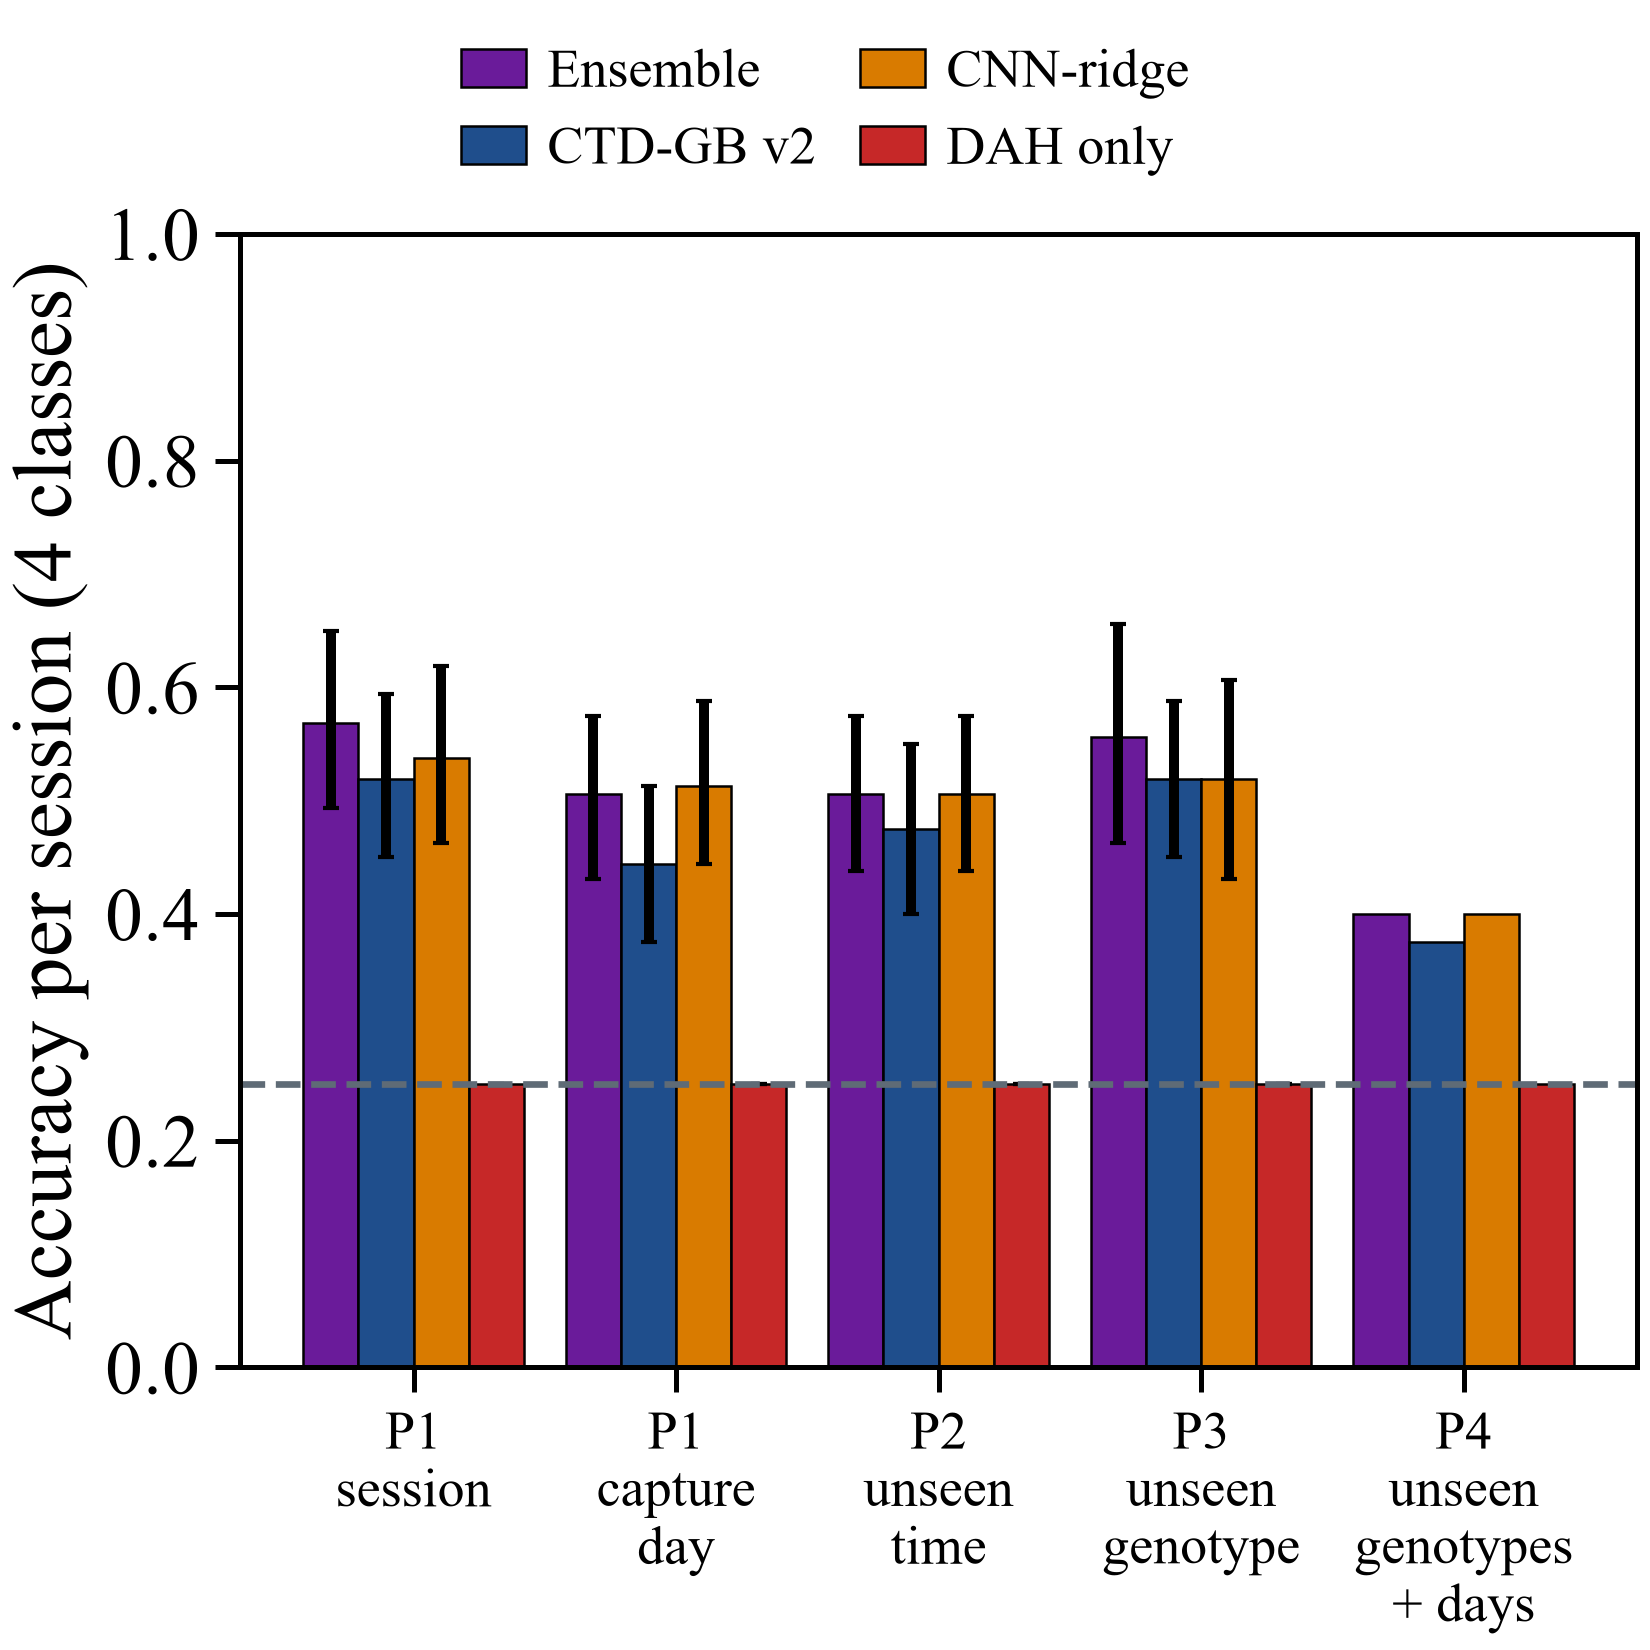

Fig. 7, panel A:
  · accuracy of the four visual classes per session (mean class probabilities of its photographs; 160 sessions); dashed line = chance (0.25)
  · the classes are balanced by design within every genotype and time, so the storage days alone stay at chance (DAH only)


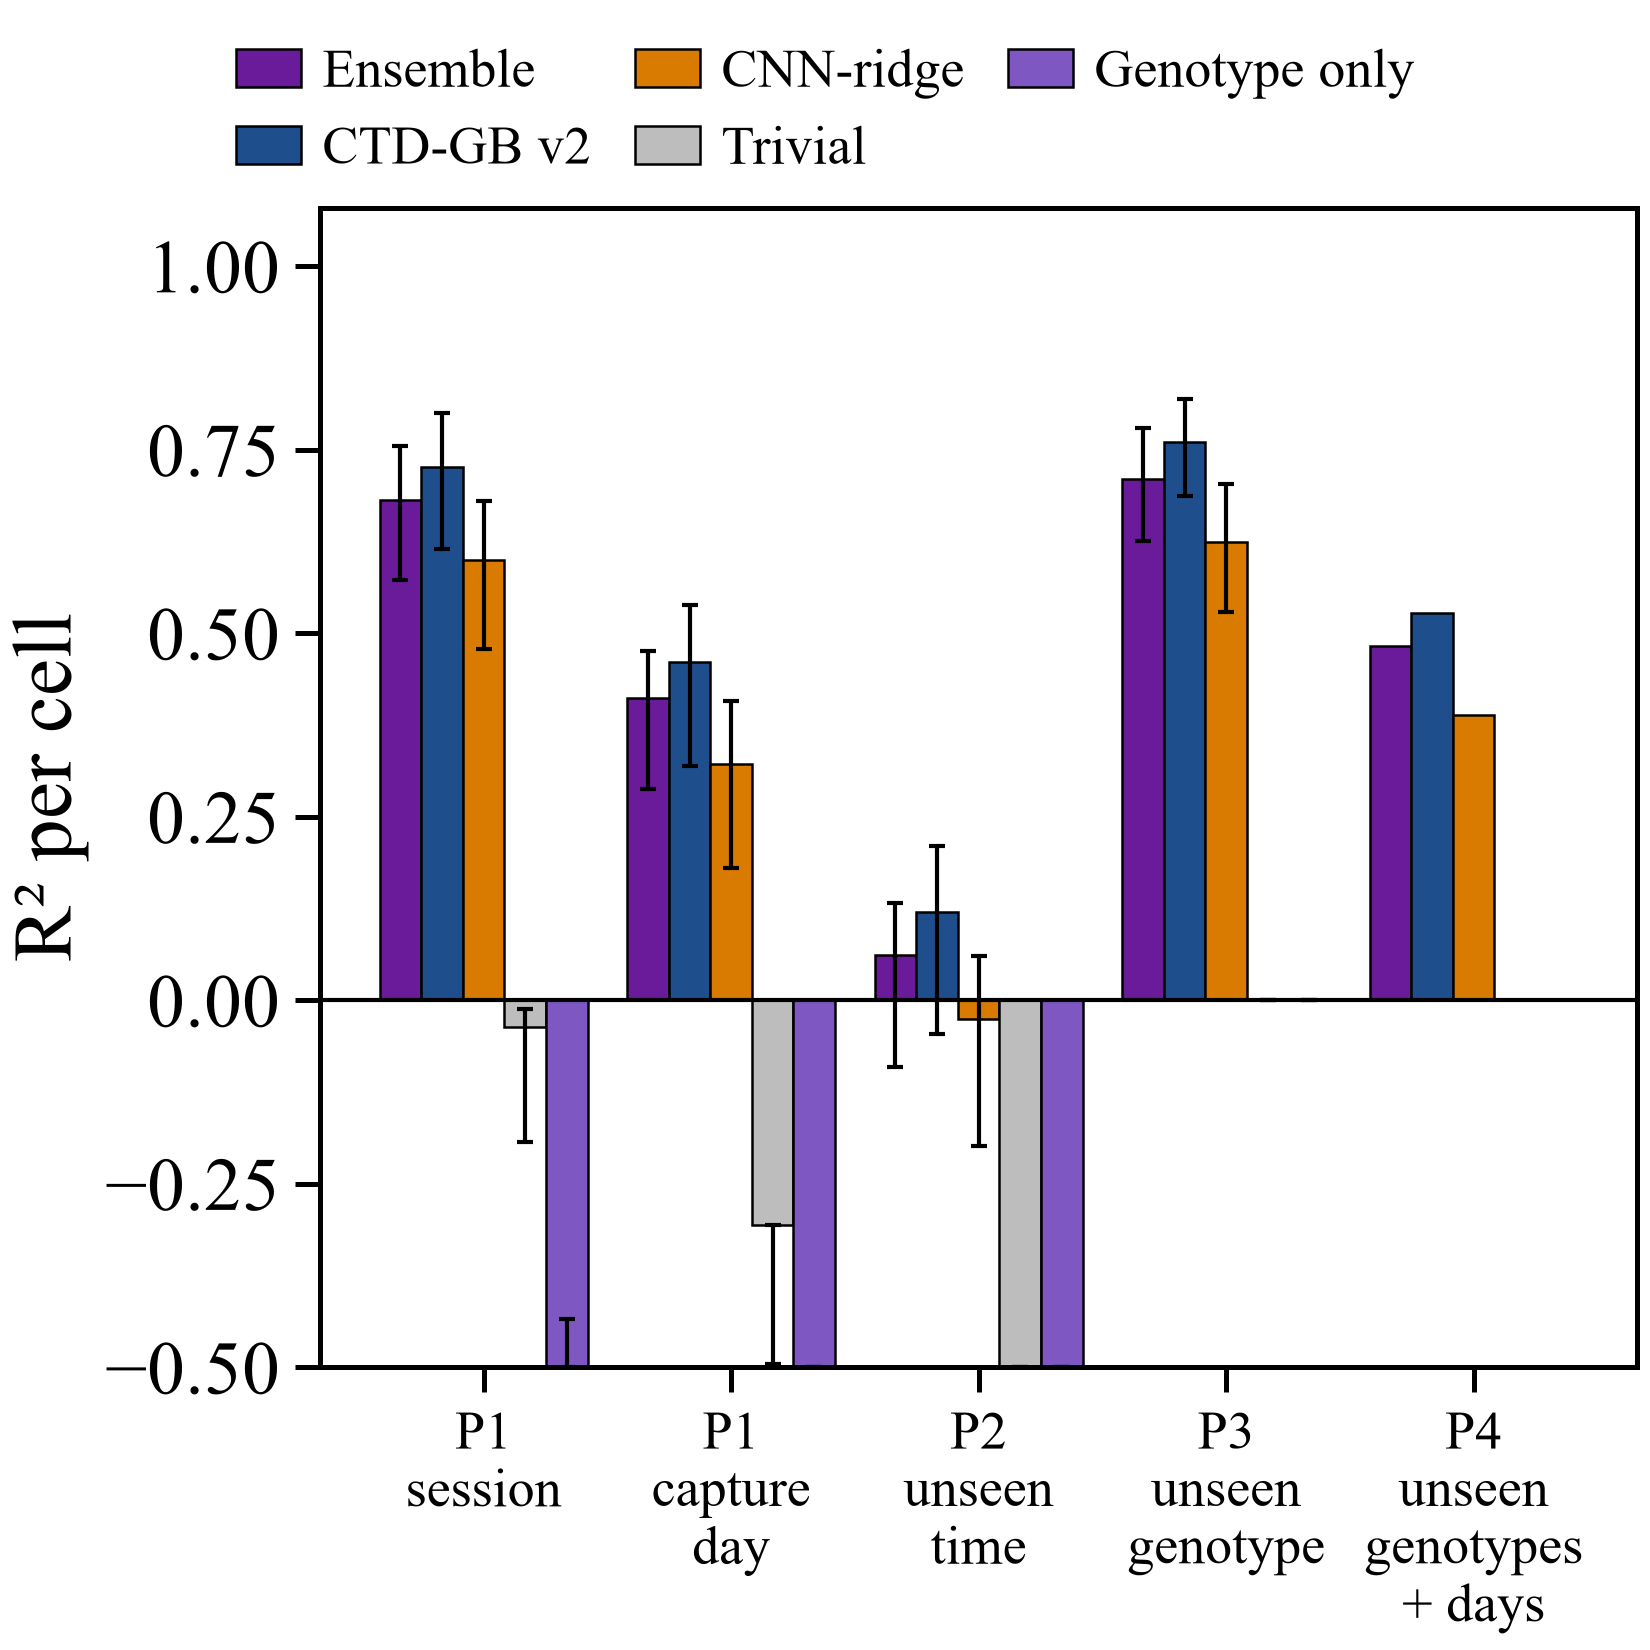

Fig. 7, panel B:
  · Days after harvest (d): R² over the 40 genotype × time cells (mean prediction of the photographs of each cell) for the photo models and the metadata references, under each protocol
  · whiskers = 95% CI by cluster bootstrap (no CI in P4: two photo groups); values below −0.5 are cut at −0.5
  · DAH-only and genotype + DAH are the answer itself for this output and are not shown


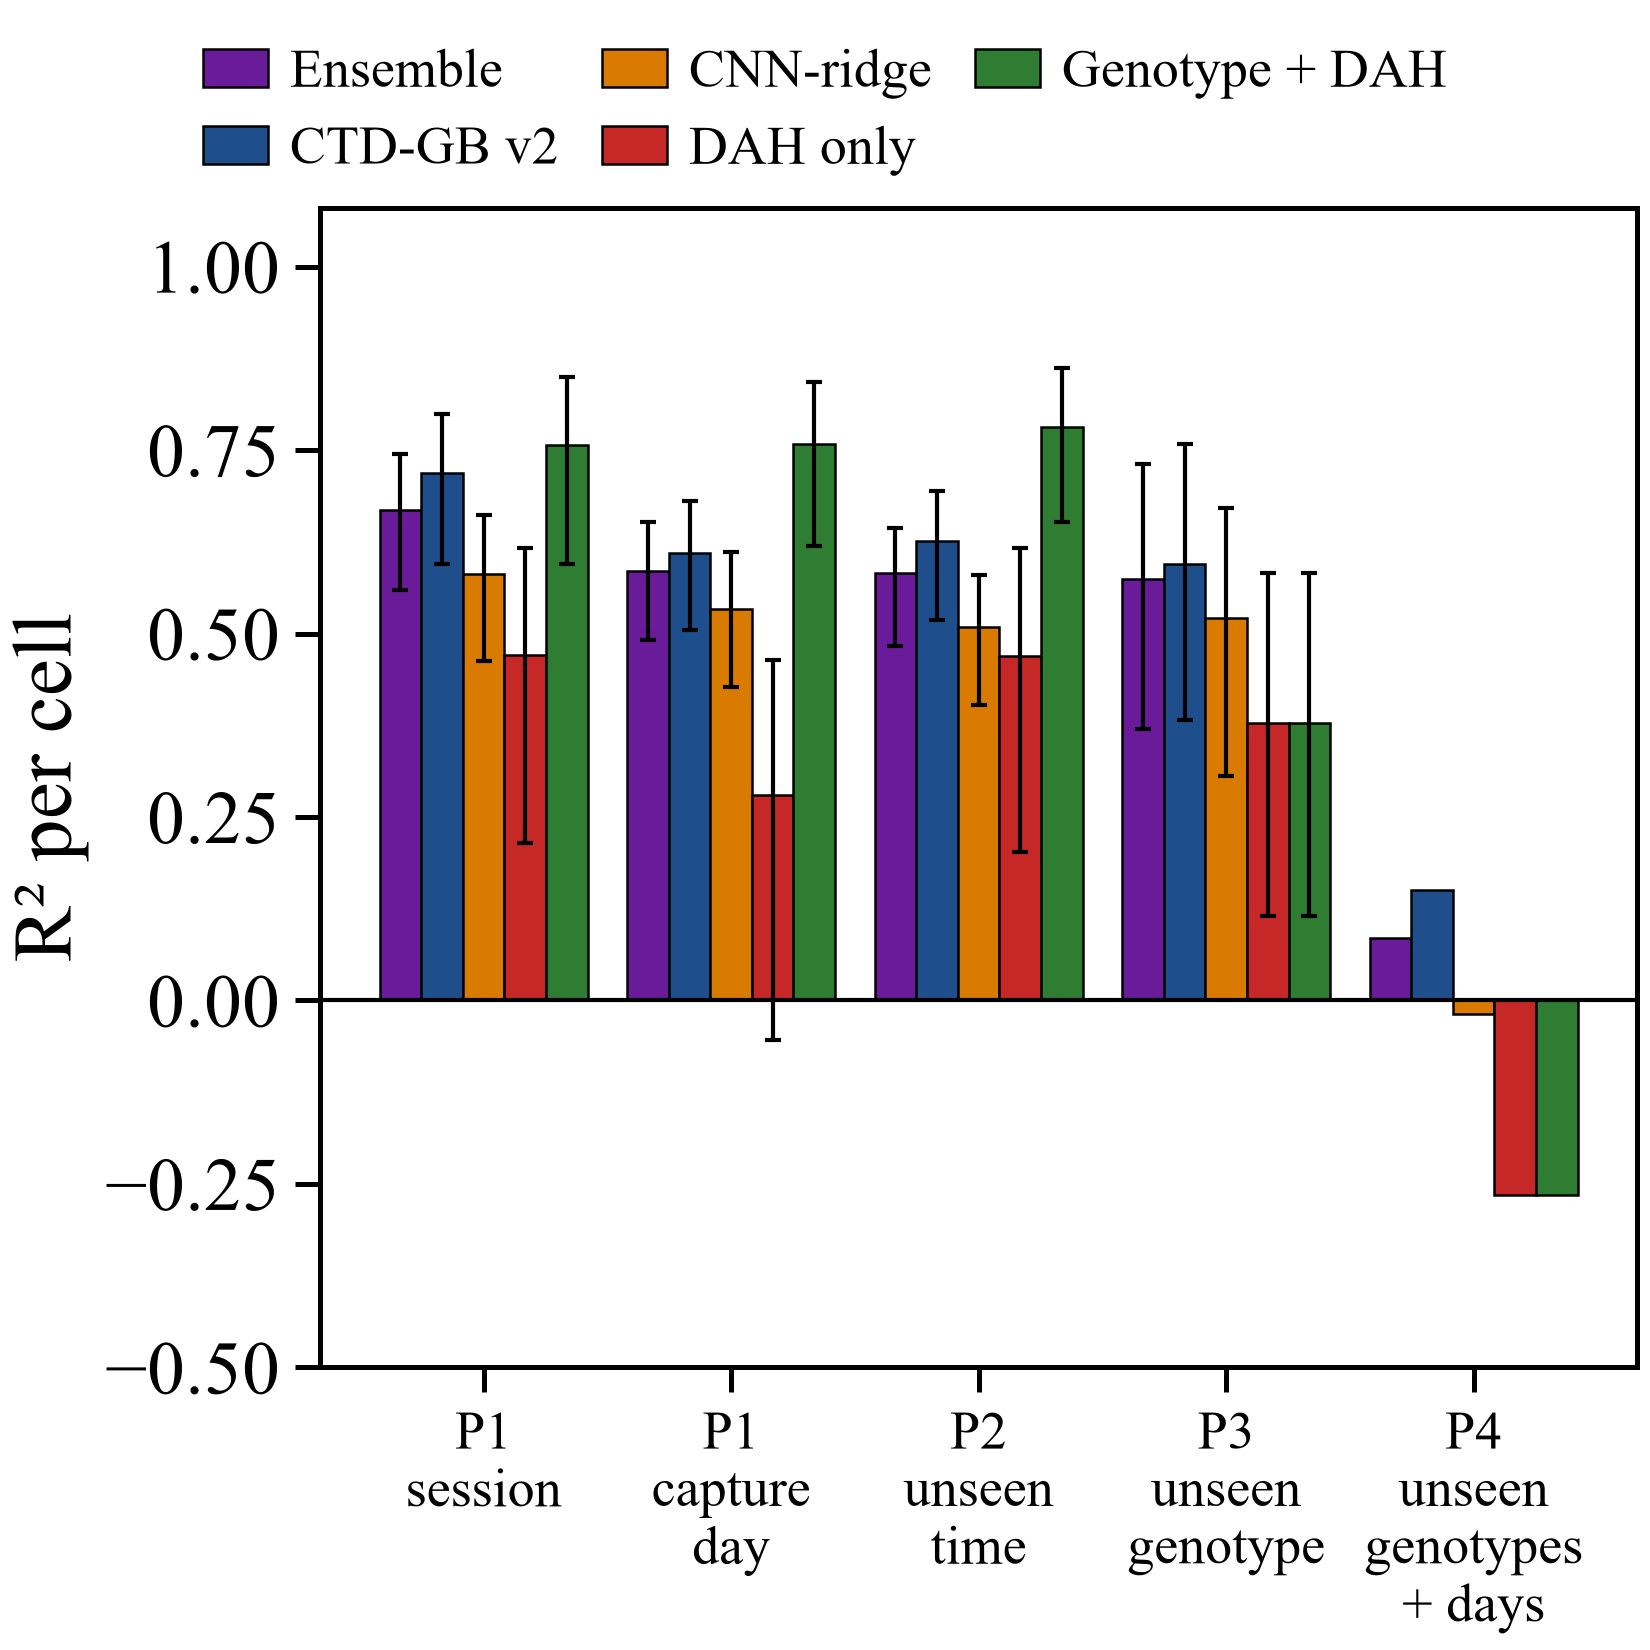

Fig. 7, panel C:
  · GQI: R² over the 40 genotype × time cells (mean prediction of the photographs of each cell) for the photo models and the metadata references, under each protocol
  · whiskers = 95% CI by cluster bootstrap (no CI in P4: two photo groups); values below −0.5 are cut at −0.5
  · genotype + DAH = the best a model can do from the metadata alone (in P3 and P4 the genotype is unseen, so it equals DAH only)


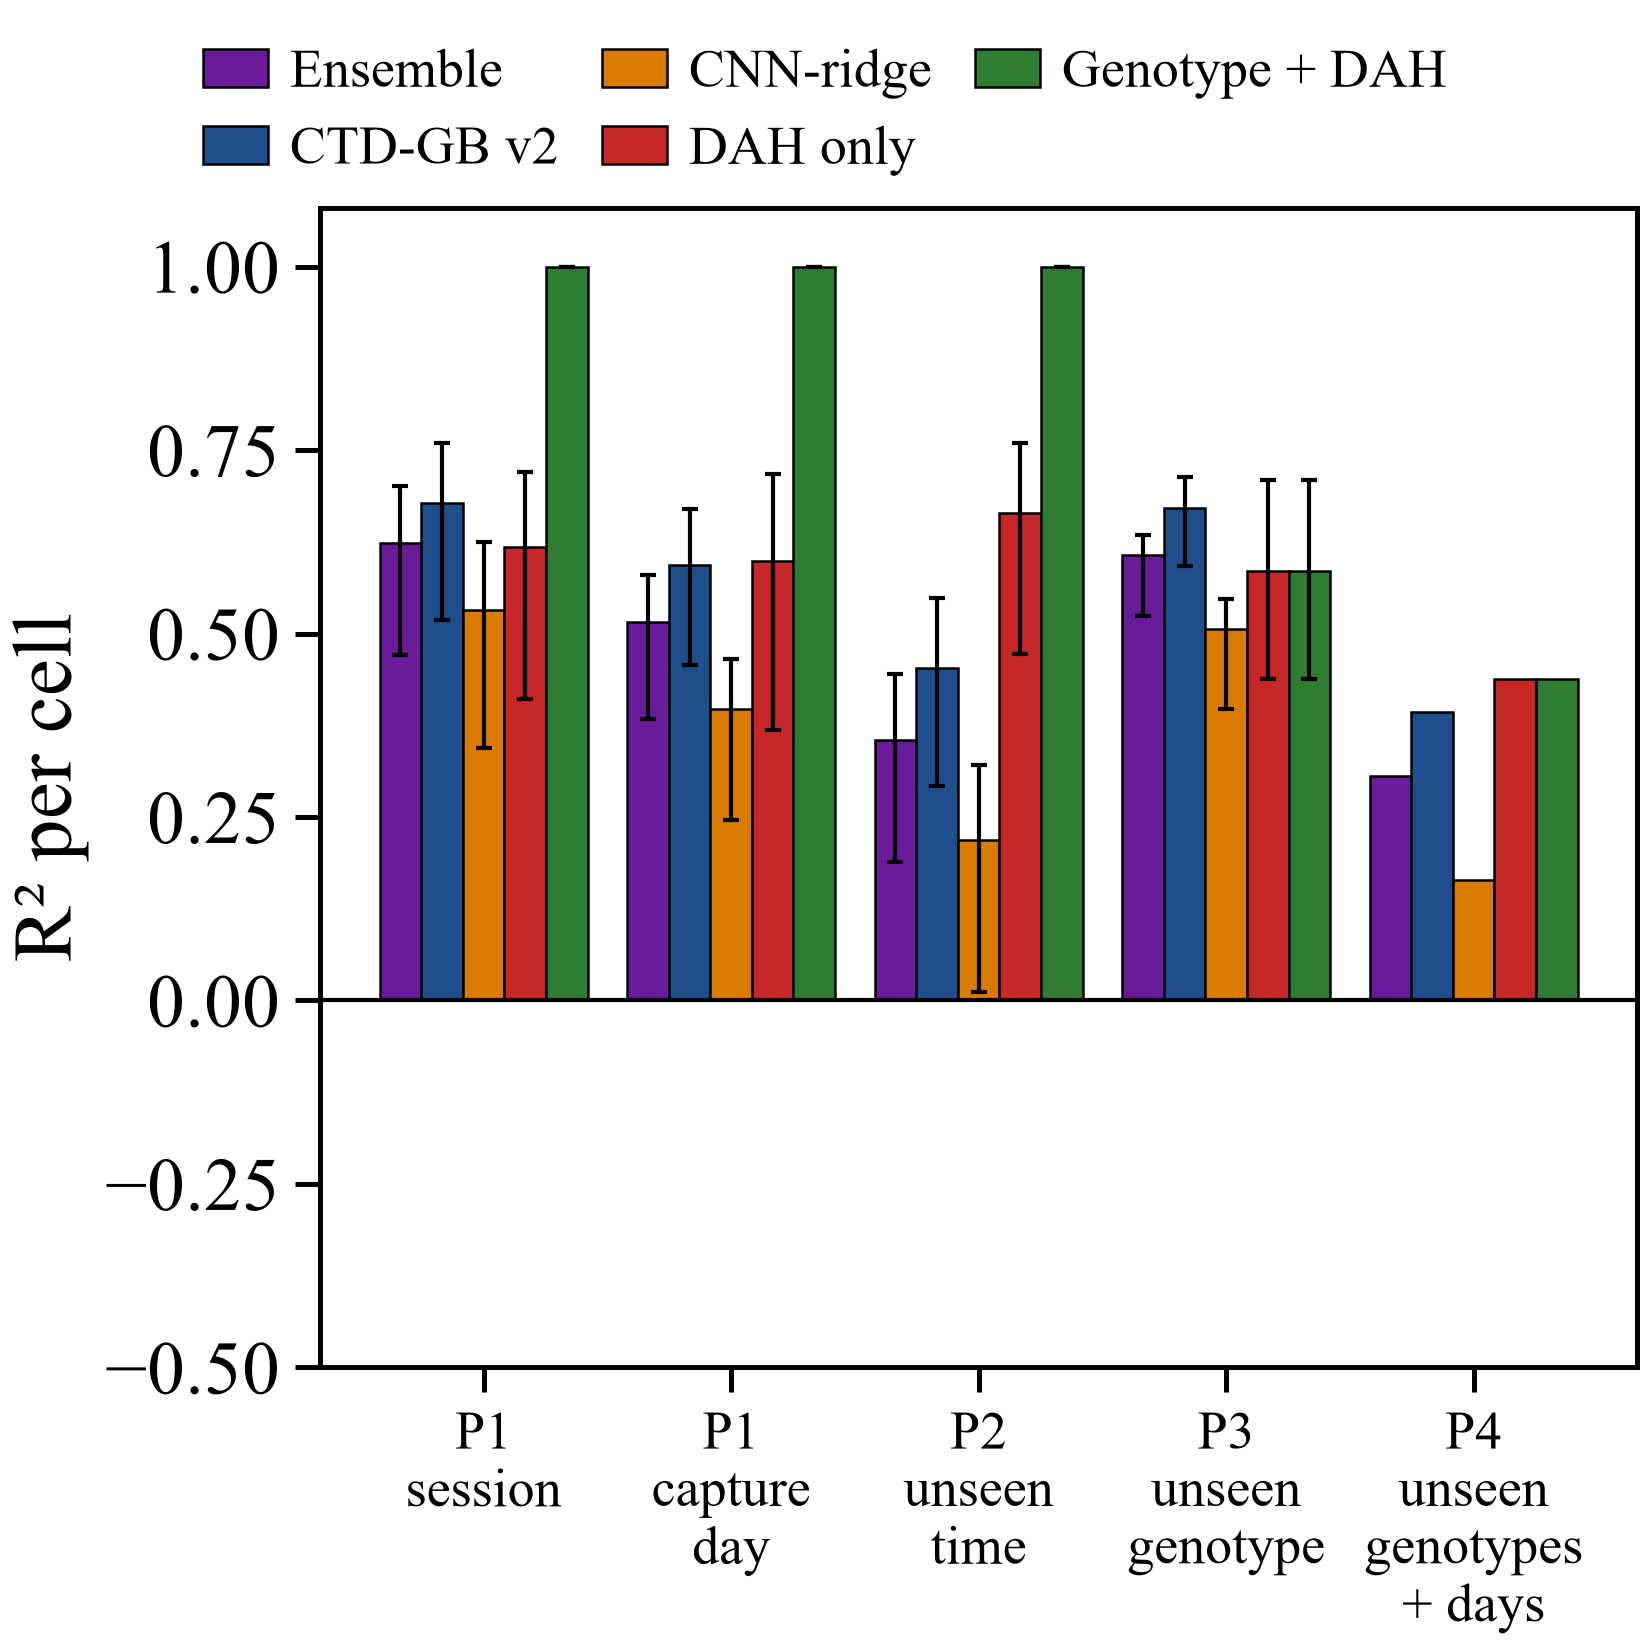

Fig. 7, panel D:
  · Remaining shelf life (d): R² over the 40 genotype × time cells (mean prediction of the photographs of each cell) for the photo models and the metadata references, under each protocol
  · whiskers = 95% CI by cluster bootstrap (no CI in P4: two photo groups); values below −0.5 are cut at −0.5
  · genotype + DAH = remaining shelf life by construction (R² = 1 when the genotype is known)


In [22]:
# ---- Fig. 7A: clase visual por sesión
fig, ax = panel()
SHOWC = ["Ensemble", "CTD-GB v2", "CNN-ridge", "DAH only"]; w = 0.84 / len(SHOWC)
for i, m in enumerate(SHOWC):
    x = RES[(RES.level == "session") & (RES.output == "class") & (RES.model == m)].set_index("scheme").reindex(SCH)
    pos = np.arange(len(SCH)) + (i - (len(SHOWC) - 1) / 2) * w
    lo = np.array([c[0] for c in x["acc_ci"]]); hi = np.array([c[1] for c in x["acc_ci"]]); lo[-1] = hi[-1] = np.nan
    ax.bar(pos, x["acc"], w, color=MODEL_COLOR[m], edgecolor="black", lw=0.6, label=m)
    ax.errorbar(pos, x["acc"], yerr=[x["acc"] - lo, hi - x["acc"]], fmt="none", ecolor="black", capsize=2)
ax.axhline(0.25, color=MUTED, ls="--", lw=1.6)
ax.set_xticks(range(len(SCH))); ax.set_xticklabels(XT, fontsize=13)
ax.set_ylabel("Accuracy per session (4 classes)"); ax.set_ylim(0, 1)
leyenda_arriba(fig, ax, ncol=2, fontsize=13)
titulo(ax, "7A")
mostrar(fig)
nota("accuracy of the four visual classes per session (mean class probabilities of its photographs; 160 sessions); dashed line = chance (0.25)",
     "the classes are balanced by design within every genotype and time, so the storage days alone stay at chance (DAH only)")

# ---- Fig. 7B (DAH), 7D (vida útil restante), 7C (GQI): R² por celda en cada protocolo
SHOW_BY = {"dah": ["Ensemble", "CTD-GB v2", "CNN-ridge", "Trivial", "Genotype only"],
           "rsl": ["Ensemble", "CTD-GB v2", "CNN-ridge", "DAH only", "Genotype + DAH"],
           "gqi_e2": ["Ensemble", "CTD-GB v2", "CNN-ridge", "DAH only", "Genotype + DAH"]}
for tag, t in [("7B", "dah"), ("7C", "gqi_e2"), ("7D", "rsl")]:
    fig, ax = panel()
    SHOW = SHOW_BY[t]; w = 0.84 / len(SHOW)
    for i, m in enumerate(SHOW):
        x = RES[(RES.level == "cell") & (RES.output == t) & (RES.model == m)].set_index("scheme").reindex(SCH)
        pos = np.arange(len(SCH)) + (i - (len(SHOW) - 1) / 2) * w
        v = x["R2"].clip(lower=-0.5).to_numpy()
        lo = np.array([c[0] if isinstance(c, np.ndarray) else np.nan for c in x["R2_ci"]]); hi = np.array([c[1] if isinstance(c, np.ndarray) else np.nan for c in x["R2_ci"]])
        lo[-1] = hi[-1] = np.nan
        ax.bar(pos, v, w, color=MODEL_COLOR[m], edgecolor="black", lw=0.6, label=m)
        ax.errorbar(pos, v, yerr=[np.clip(v - np.clip(lo, -0.5, None), 0, None), np.clip(np.clip(hi, -0.5, None) - v, 0, None)],
                    fmt="none", ecolor="black", elinewidth=1.0, capsize=2)
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks(range(len(SCH))); ax.set_xticklabels(XT, fontsize=13)
    ax.set_ylabel("R² per cell"); ax.set_ylim(-0.5, 1.08)
    leyenda_arriba(fig, ax, ncol=3, fontsize=13)
    titulo(ax, tag)
    mostrar(fig)
    nota(f"{OUTPUTS[t]}: R² over the 40 genotype × time cells (mean prediction of the photographs of each cell) for the photo models "
         "and the metadata references, under each protocol",
         "whiskers = 95% CI by cluster bootstrap (no CI in P4: two photo groups); values below −0.5 are cut at −0.5",
         ("DAH-only and genotype + DAH are the answer itself for this output and are not shown" if t == "dah" else
          "genotype + DAH = remaining shelf life by construction (R² = 1 when the genotype is known)" if t == "rsl" else
          "genotype + DAH = the best a model can do from the metadata alone (in P3 and P4 the genotype is unseen, so it equals DAH only)"))

**Lectura de la Tabla 2 y la Fig. 7.**

- **Clase visual** (la única etiqueta del pseudotallo). La foto de la planta sola acierta la clase de la sesión
  en 51–57 % de los casos en P1, P1 por día, P2 y **P3 (0,56 [0,46, 0,66]; κ ponderado 0,57)**, frente a 0,25
  del azar; los metadatos (días, genotipo) se quedan en el azar porque las clases están balanceadas en cada
  genotipo y tiempo. Con **genotipos y días de foto no vistos (P4)** baja a 0,40 (κ 0,16): la generalización a genotipos nuevos
  fotografiados en otros días es más débil.
- **Edad de la muestra (DAH).** R² por celda 0,68 en P1 y **0,71 en P3**: la foto estima los días desde la cosecha
  en genotipos no vistos. Cae a 0,41 cuando queda fuera el día de captura completo y a 0,48 con genotipos y días de
  foto no vistos; con un tiempo no visto (P2) no extrapola (≈ 0). Con este diseño el día de captura coincide con el
  tiempo dentro de cada grupo de fotografía, así que la parte que se pierde al dejar fuera el día no se puede atribuir ni a la
  luz ni al deterioro.
- **Vida útil restante.** La foto sola **no supera** a saber los días (diferencia frente a *solo DAH* cercana a
  0 en P1 y P3, tabla D7); es lo esperable con una etiqueta de celda que es la vida útil del genotipo menos
  el DAH. **Con el DAH conocido, la foto sí añade** (+0,09 a +0,11 de R² con IC por encima de 0 en P1, P1 por
  día y P3), porque aporta parte de la información del genotipo.
- **GQI.** Es donde la foto aporta más: R² por celda 0,57 en P3 frente a 0,38 de *solo DAH* (diferencia
  +0,20 [0,02, 0,43]); +0,30 en P1 por día. Con genotipos y días de foto no vistos el R² es bajo (0,08), aunque sigue por encima
  de *solo DAH* (−0,27).
- **Frente a la versión anterior** (tabla D8, por foto) la planta sola es más robusta justo donde la versión
  anterior fallaba: con el día de captura fuera, R² del DAH 0,29 frente a 0,11 (CTD-GB v1) y −0,26 (CNN-MTL v1);
  vida útil restante 0,40 frente a 0,26 y −0,38; GQI 0,46 frente a 0,29 y −0,04. La exactitud de la clase por
  foto es parecida (0,47–0,52 frente a 0,44–0,49).
- **Estabilidad.** Entre las cinco particiones de P1 la DE del R² por celda es ≤ 0,03 (tabla D9).
- **Modelos.** CTD-GB v2 rinde algo mejor que el ensamble en las salidas continuas (p. ej., DAH en P3: 0,76
  frente a 0,71) y CNN-ridge en el κ de la clase cuando queda fuera el día de captura o el tiempo (0,53 y 0,57
  frente a 0,48 y 0,45); el ensamble se mantiene como modelo principal porque así se
  fijó en el plan antes de ver los resultados.

# 5. Resultado de la fase — lo que dice una foto de un genotipo que el modelo nunca vio

**Qué responde.** El resultado que se recuerda de la Fase 3: con un genotipo que no estuvo en el entrenamiento (P3),
qué se puede saber desde la foto de la planta y qué significa para aceptar o rechazar una muestra.

**Paneles y por qué van juntos** → **Fig. 8** (artículo, resultado de la fase). Todos en P3: **A** clase visual
(matriz de confusión en % de cada fila); **B** edad de la muestra predicha frente a observada; **C** GQI predicho frente
a observado junto a lo que daría saber solo los días; **D** decisión de aceptar o rechazar frente a la regla por días.
A–C dicen qué sabe la foto; D, para qué sirve.

**Suplemento (Fig. S2):** **A** error según cuántos pseudotallos de la muestra se fotografían; **C** decisión con
genotipos conocidos (P1); **D–E** curvas de costo en P1 y P3. **Tablas de detalle:** D11 número de pseudotallos ·
D12 decisiones · D13 cobertura de los intervalos conformales (se resumen en la Tabla 3b y su nota, sección 8).

### 5.1 Clase, edad y GQI con un genotipo no visto

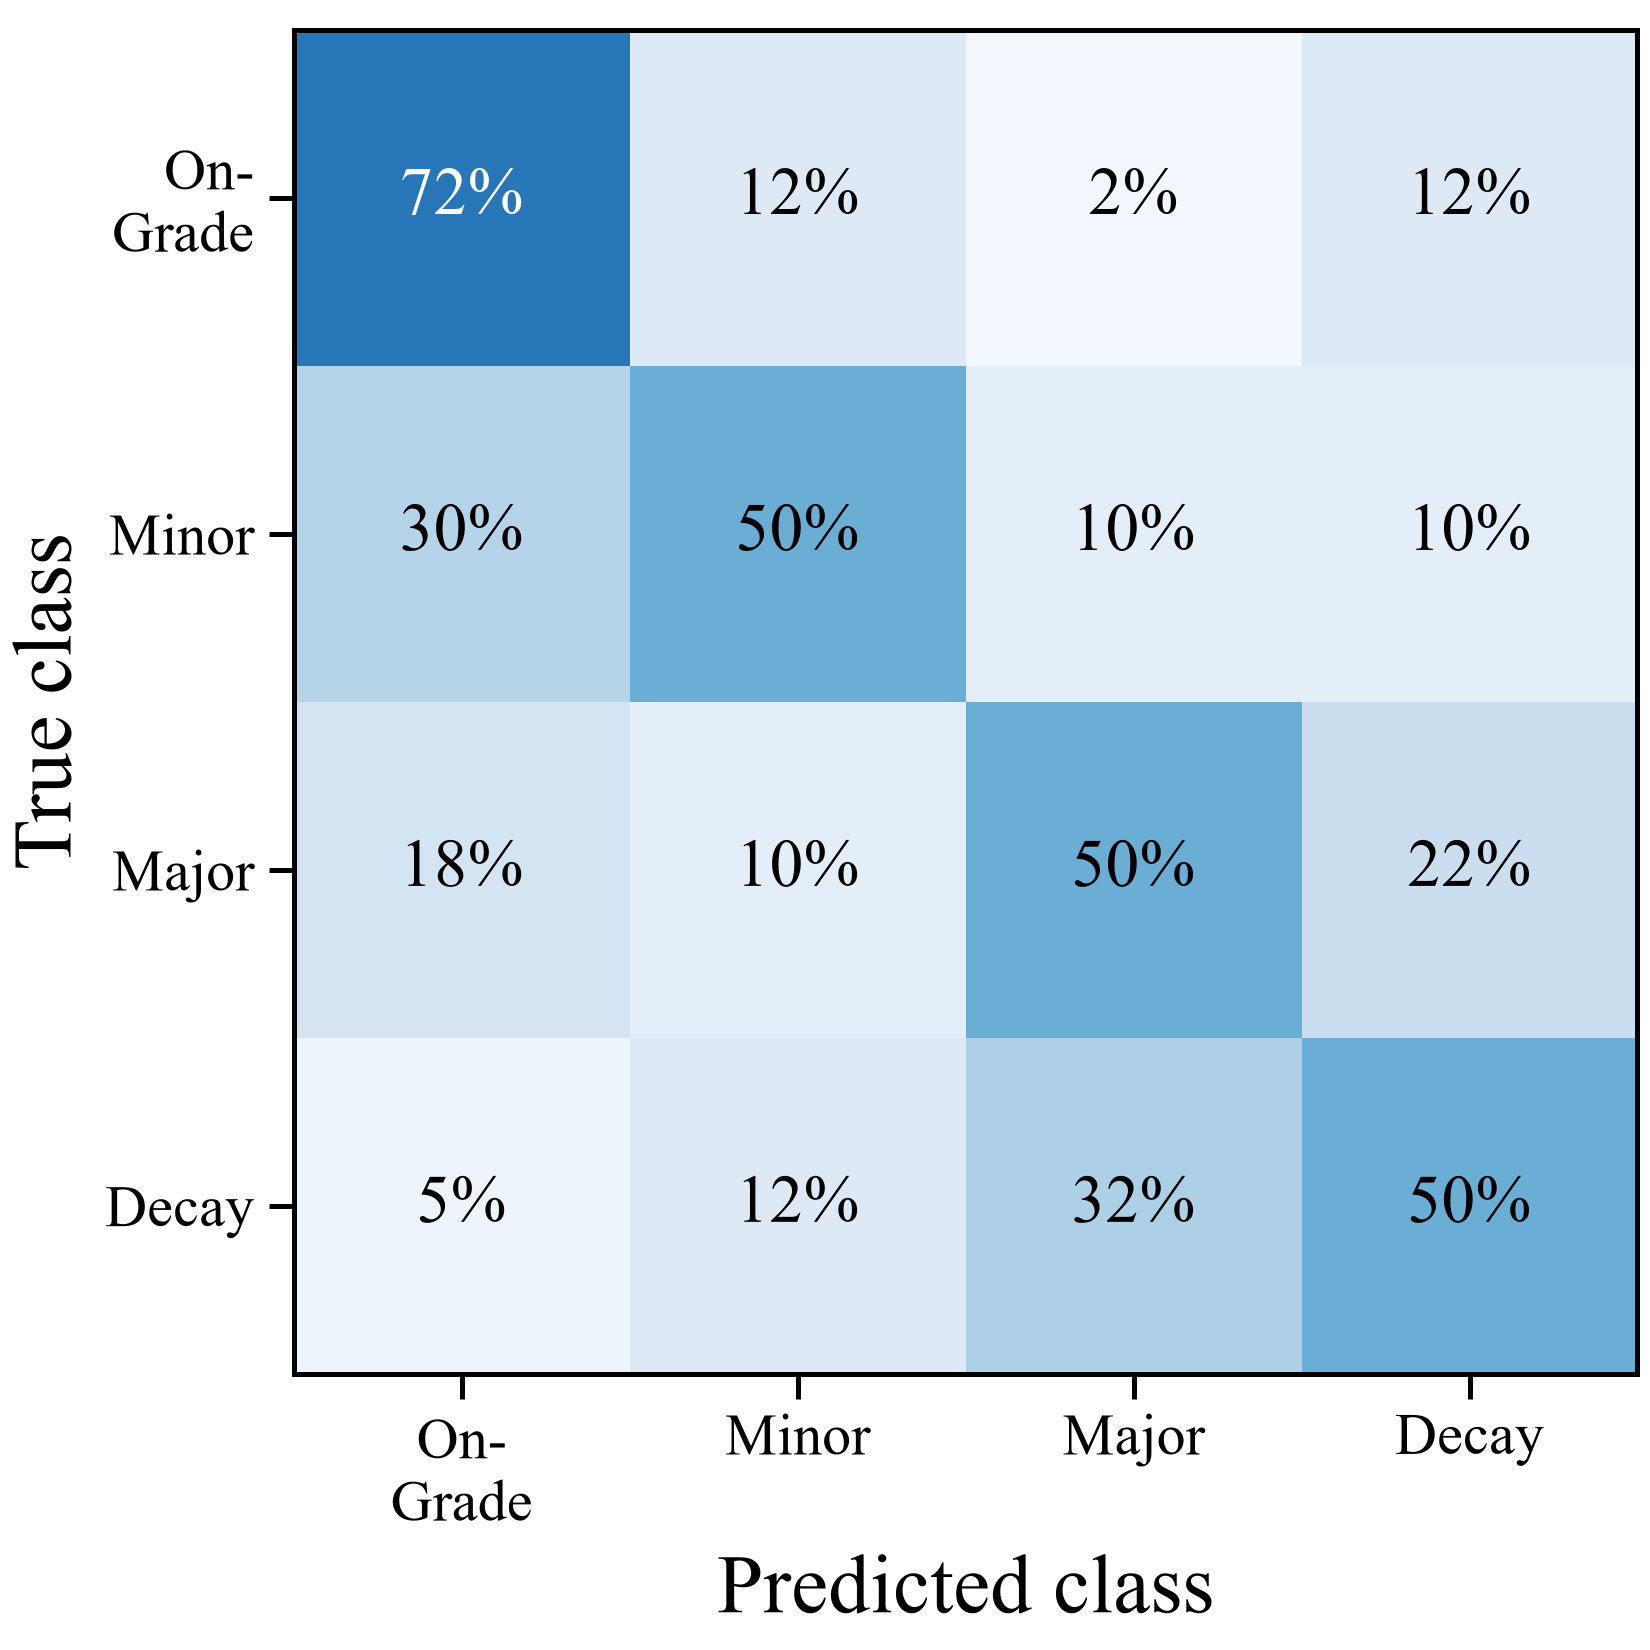

Fig. 8, panel A:
  · P3 (genotype not seen in training): share of the sessions of each true visual class assigned to each predicted class (Ensemble); n = 40 sessions per class (160 sessions, 16,388 photographs); per pseudostem and per photograph the shares are almost the same
  · accuracy 0.56 [0.46, 0.66]; quadratic-weighted κ 0.57 [0.41, 0.73]; within one class 0.85 [0.77, 0.93]


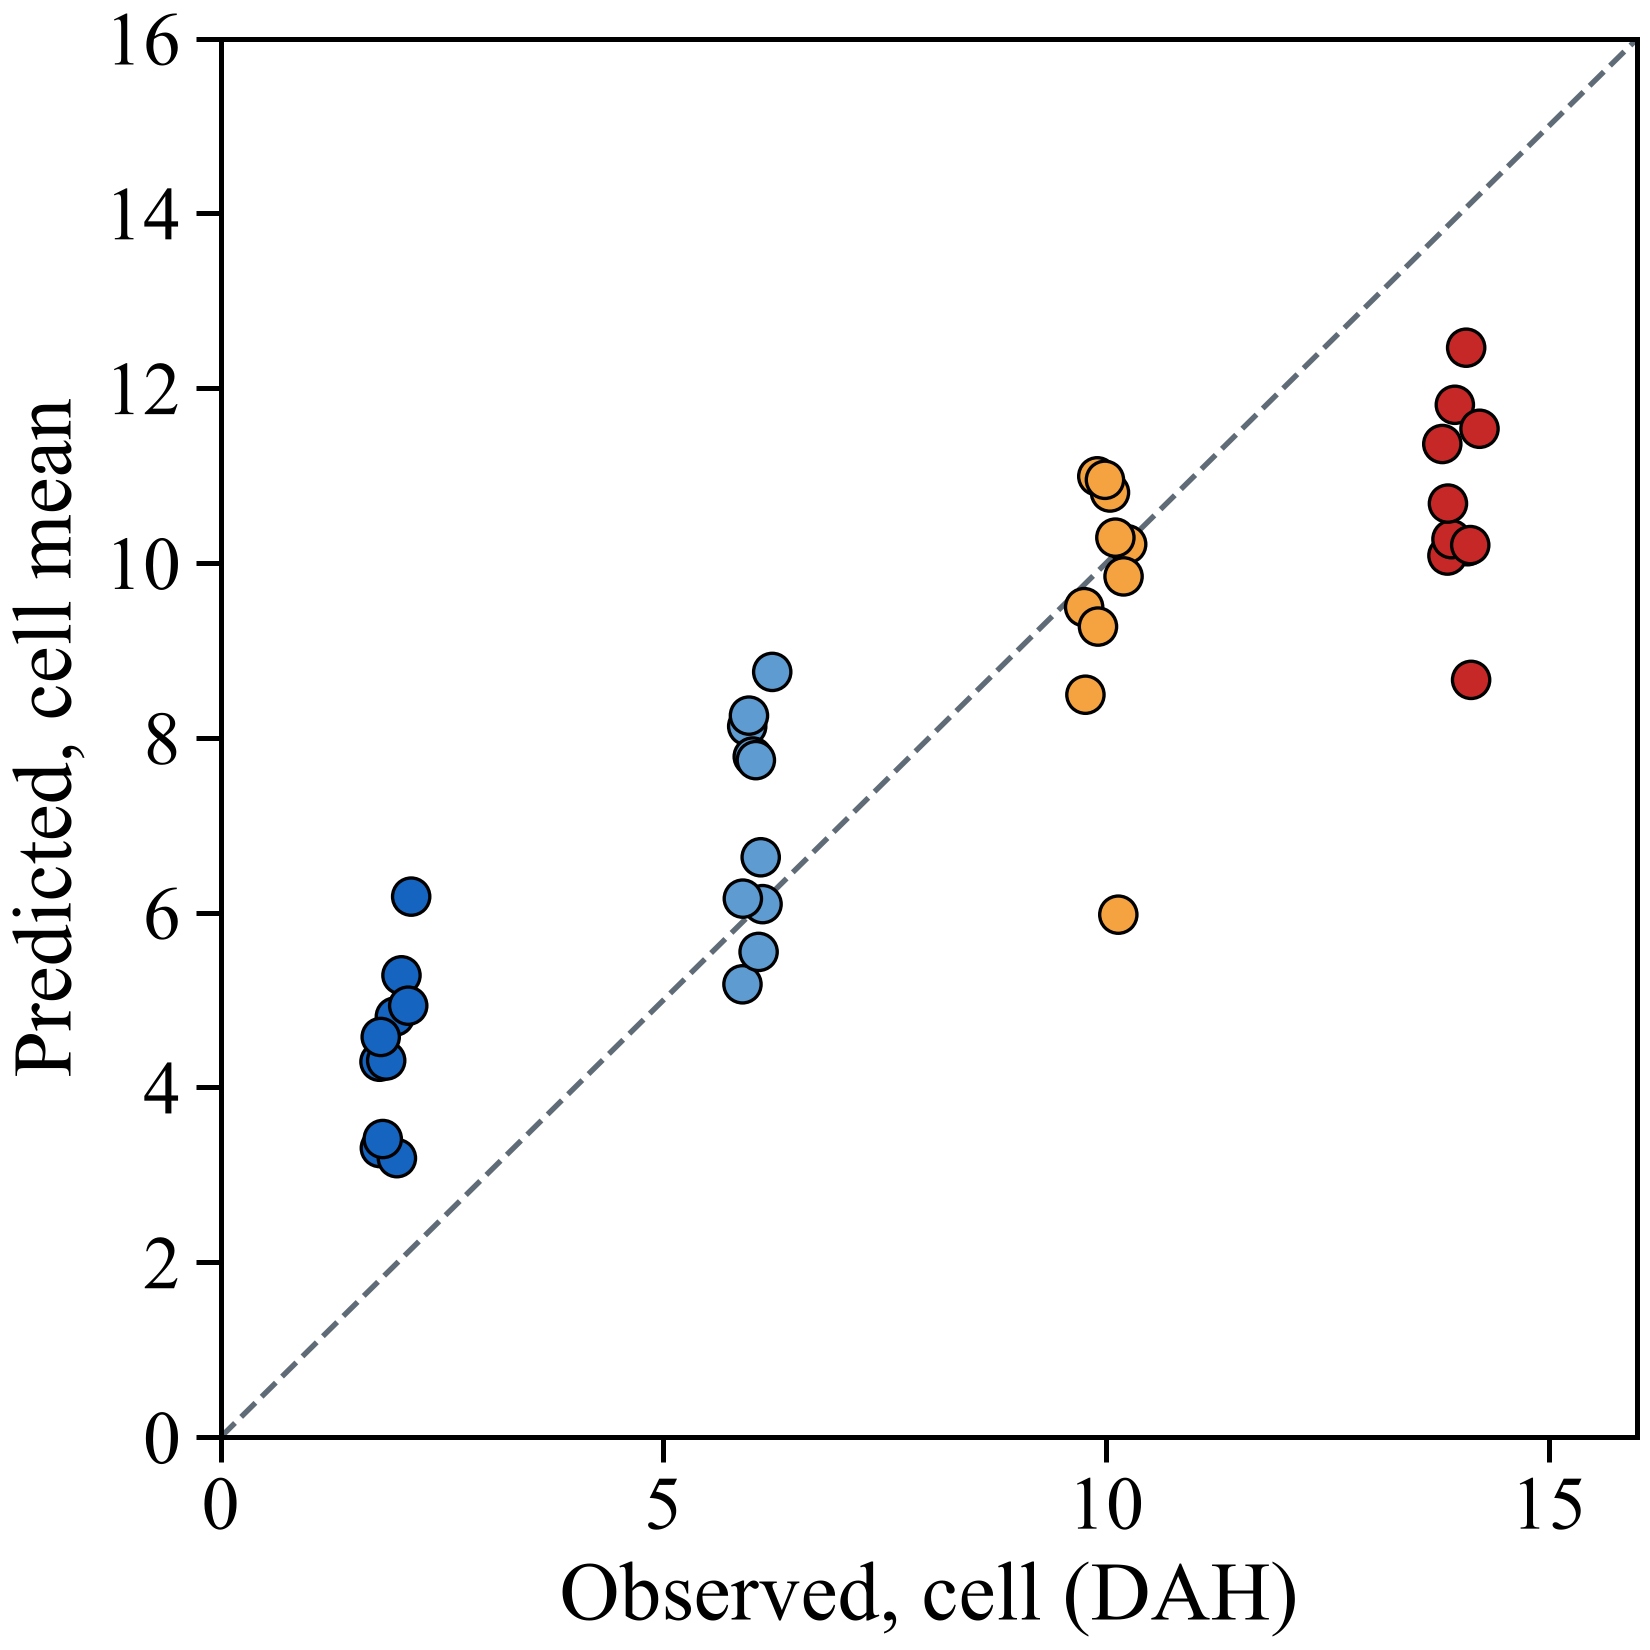

Fig. 8, panel B:
  · P3 (genotype not seen in training): mean prediction of the photographs of each genotype × time cell against the observed value; colour = DAH
  · R² per cell: Ensemble 0.71 [0.63, 0.78]


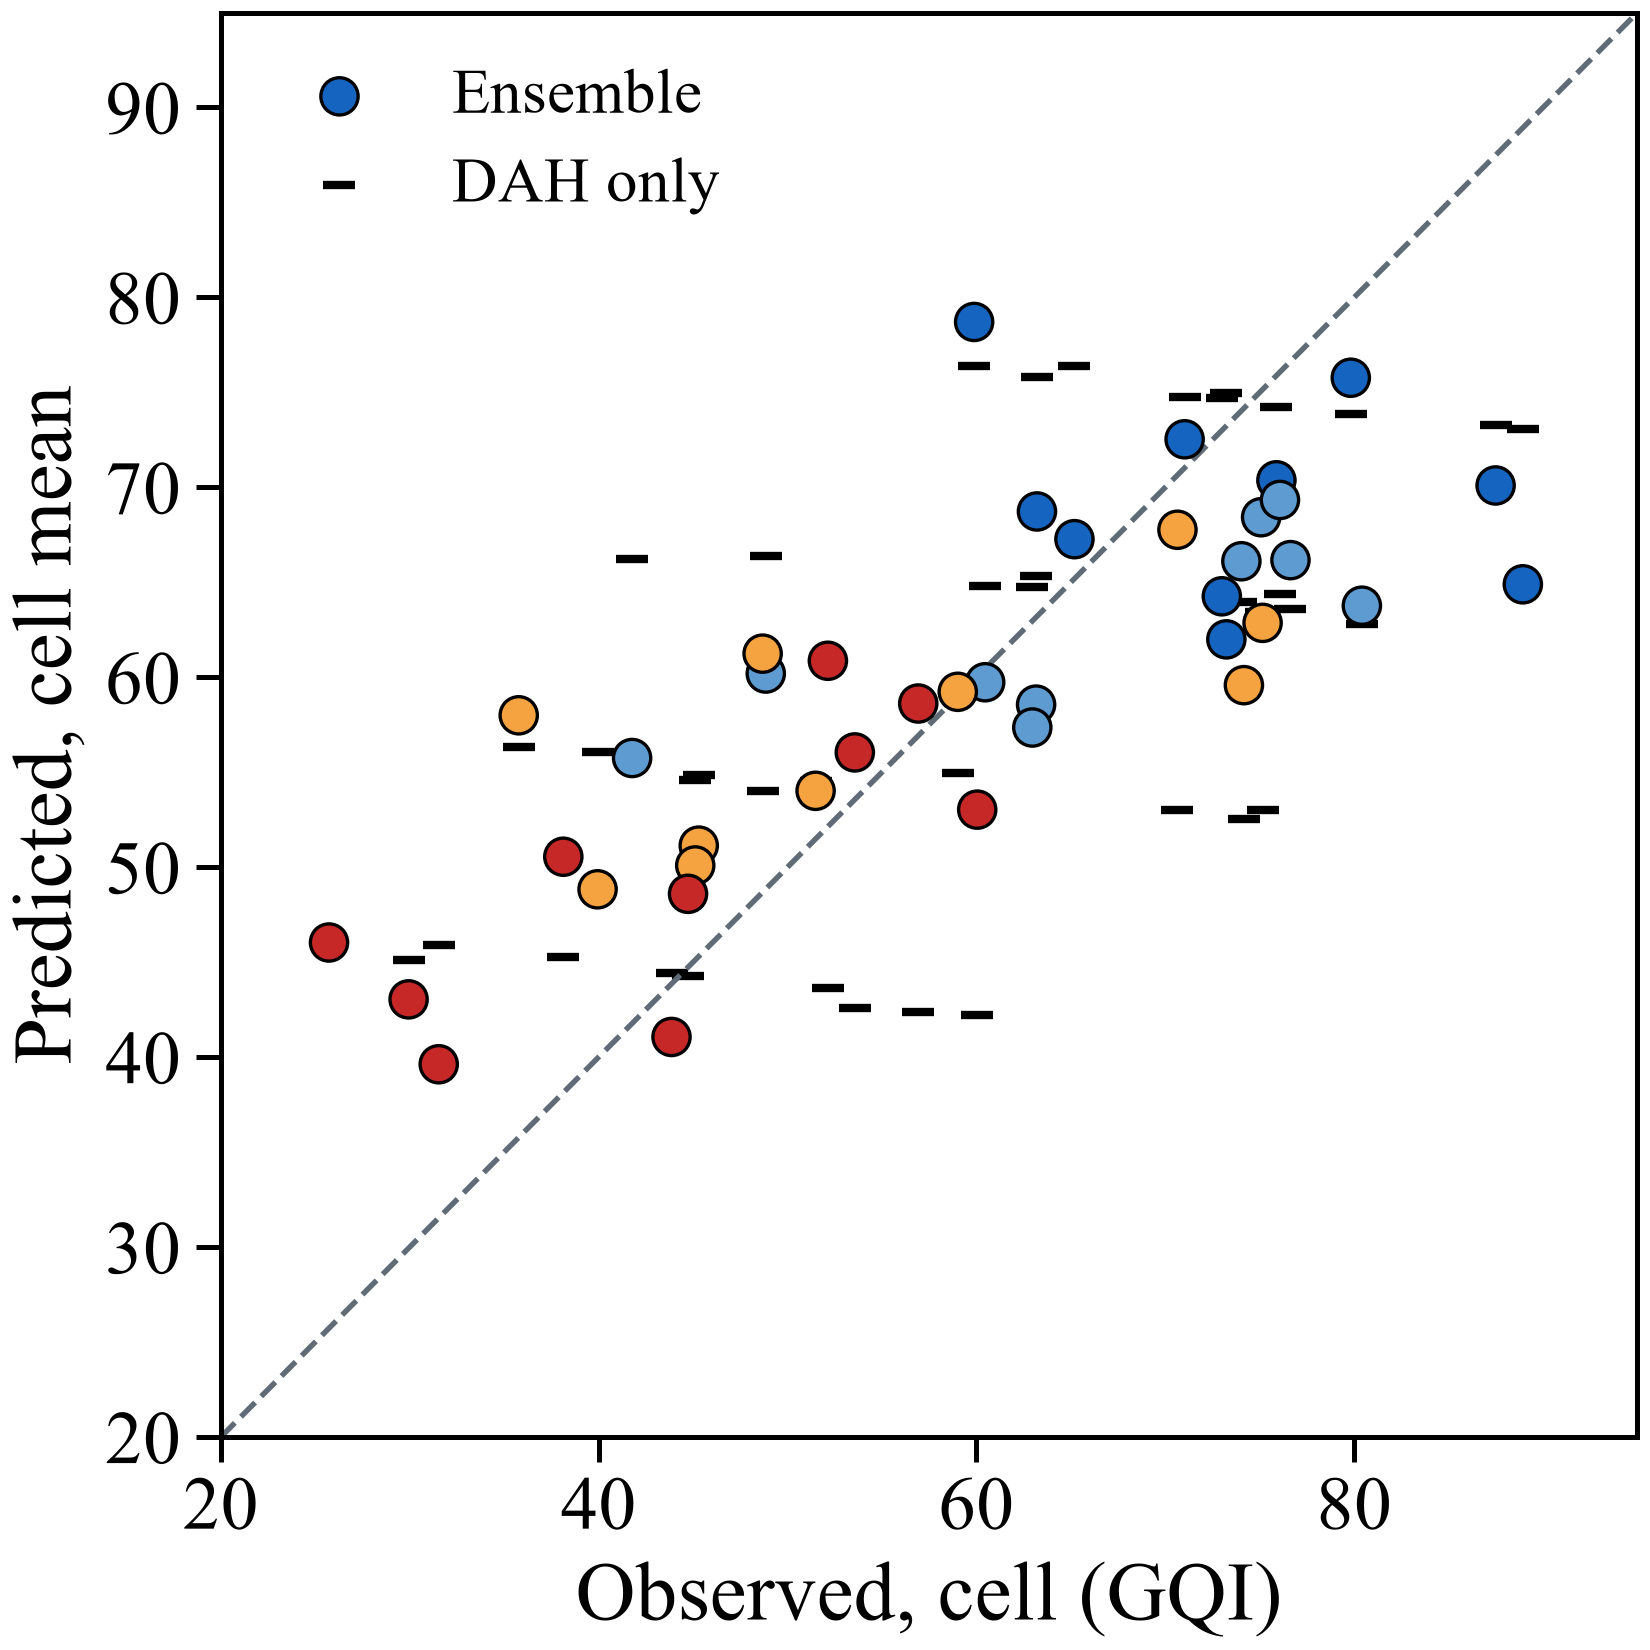

Fig. 8, panel C:
  · P3 (genotype not seen in training): mean prediction of the photographs of each genotype × time cell against the observed value; colour = DAH
  · R² per cell: Ensemble 0.57 [0.37, 0.73]; DAH only 0.38 [0.12, 0.58]


In [23]:
# ---- Fig. 8A: P3 — matriz de confusión de la clase (Ensemble, por sesión, en % de cada fila)
fig, ax = panel()
cs = class_stats("P3", VAL2["schemes"]["P3"]["pred"], "Ens|class", "session")
cm = cs["cm"] / cs["cm"].sum(1, keepdims=True)
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{100 * cm[i, j]:.0f}%", ha="center", va="center", fontsize=16, color="white" if cm[i, j] > 0.55 else "black")
short = ["On-\nGrade", "Minor", "Major", "Decay"]
ax.set_xticks(range(4)); ax.set_xticklabels(short, fontsize=14); ax.set_yticks(range(4)); ax.set_yticklabels(short, fontsize=14)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
titulo(ax, "8A")
mostrar(fig)
nota("P3 (genotype not seen in training): share of the sessions of each true visual class assigned to each predicted class (Ensemble); "
     f"n = 40 sessions per class ({cs['n']} sessions, 16,388 photographs); per pseudostem and per photograph the shares are almost the same",
     f"accuracy {fmt(cs['acc'], cs['acc_ci'])}; quadratic-weighted κ {fmt(cs['qwk'], cs['qwk_ci'])}; within one class {fmt(cs['adj'], cs['adj_ci'])}")

# ---- Fig. 8B (DAH) y 8C (GQI): P3 — predicción por celda frente a lo observado
for tag, t, lim in [("8B", "dah", (0, 16)), ("8C", "gqi_e2", (20, 95))]:
    fig, ax = panel()
    P = VAL2["schemes"]["P3"]["pred"]
    y, p, _ = reg_level("P3", P, f"Ens|{t}", t, "cell")
    yr, pr_, _ = reg_level("P3", P, f"DAH only|{t}", t, "cell", mask=OKV & np.isfinite(P[f"Ens|{t}"]))
    cells_ = unit_means(P[f"Ens|{t}"], CELL, OKV & np.isfinite(P[f"Ens|{t}"])).index
    dah_c = pd.Series(vd["dah"].to_numpy()).groupby(CELL).first().loc[cells_].to_numpy()
    jit = np.random.default_rng(3).uniform(-0.25, 0.25, len(y)) if t == "dah" else 0
    ax.scatter(y + jit, p, s=80, c=[DAH_COLOR[int(d)] for d in dah_c], edgecolor="black", lw=0.8, zorder=3, label="Ensemble")
    if t != "dah":
        ax.scatter(yr, pr_, s=60, marker="_", color="black", lw=2, zorder=2, label="DAH only")
    ax.plot(lim, lim, ls="--", color=MUTED, lw=1.3)
    ax.set_xlim(*lim); ax.set_ylim(*lim)
    ax.set_xlabel(f"Observed, cell ({'DAH' if t == 'dah' else 'GQI'})"); ax.set_ylabel("Predicted, cell mean")
    if t != "dah":
        ax.legend(loc="upper left", frameon=False)
    titulo(ax, tag)
    mostrar(fig)
    s = RES[(RES.scheme == "P3") & (RES.level == "cell") & (RES.output == t)].set_index("model")
    nota(f"P3 (genotype not seen in training): mean prediction of the photographs of each genotype × time cell against the observed value; colour = DAH",
         f"R² per cell: Ensemble {fmt(s.loc['Ensemble', 'R2'], s.loc['Ensemble', 'R2_ci'])}" +
         ("" if t == "dah" else f"; DAH only {fmt(s.loc['DAH only', 'R2'], s.loc['DAH only', 'R2_ci'])}"))

**Lectura de la Fig. 8A–C.** Los errores de clase en genotipos no vistos son sobre todo entre clases
vecinas (85 % de las sesiones caen en la clase correcta o en una contigua). Por celda, la edad estimada sigue
el orden de los cuatro tiempos, con el sesgo típico de regresión hacia la media en los extremos (2 y 14 DAH).
El GQI predicho sigue al observado mejor que la regla por días, que asigna el mismo valor a todos los genotipos
de un tiempo.

### 5.2 Aceptar o rechazar con incertidumbre

La decisión práctica es **aceptar** (vender) o **rechazar** una muestra: se rechaza cuando la vida útil restante
predicha es < 0. El **falso aceptado** vende un producto que el consumidor rechazaría (riesgo del
consumidor); el **falso rechazo** descarta un producto aceptable (riesgo del productor). Se compara con:
- la **regla fija por días**: rechazar si los días desde la cosecha superan la mediana de la vida útil de los
  10 genotipos (no necesita ni el genotipo ni la foto);
- *solo DAH* y, como techo, *genotipo + DAH* (requiere conocer el genotipo).

**Intervalos conformales del 90 %** (calibración partida; Angelopoulos y Bates, arXiv:2107.07511): en cada
pliegue, un modelo se entrena con el 85 % de las unidades del entrenamiento y el radio es el cuantil
⌈(n+1)(1−α)⌉/n de los errores absolutos en el 15 % restante, separado por la misma unidad que el protocolo
deja fuera (sesiones, días, genotipos o grupos de fotografía). Con el intervalo, la foto **acepta** solo si todo el intervalo
está por encima de 0, **rechaza** solo si está por debajo y, si cruza el 0, **decide la regla por días**.

**Costos.** No hay una razón de costos publicada para la cebolla de rama. El falso rechazo vale el producto
descartado: en Corabastos (Bogotá) el kilo de cebolla junca osciló entre \$1.458 (SIPSA-DANE, 14 oct 2026) y
\$5.833 (SIPSA-DANE, 3 jul 2026). El falso aceptado vale al menos lo mismo más la pérdida de confianza del
comprador. Por eso no se fija una razón: se trazan **curvas de costo** (Drummond y Holte, 2006) para razones
falso aceptado / falso rechazo de 1 a 10.

In [24]:
SL_MED = float(np.median(pd.Series(SL_ONLINE).clip(upper=14.0)))
REJ = (vd["rsl"].to_numpy() < 0).astype(int)
print(f"regla fija por días: rechazar si DAH > {SL_MED:.1f} d · fotos que deberían rechazarse: {100 * REJ.mean():.1f} %")

# cobertura y ancho de los intervalos conformales
rows = []
for sc in SCH:
    P, Qd = VAL2["schemes"][sc]["pred"], VAL2["schemes"][sc]["q"].set_index("fold")
    for t in OUTPUTS:
        for key, name in [("Ens", "Ensemble"), ("M1", "CTD-GB v2"), ("M2", "CNN-ridge"), ("DAH only", "DAH only")]:
            c = P[f"cc_{key}|{t}"]; qv = Qd[f"{key}|{t}"].reindex(P["fold"]).to_numpy(); y = vd[t].to_numpy(float)
            m = OKV & np.isfinite(c)
            if name == "DAH only" and t == "dah":
                continue                      # predice el propio DAH: intervalo de ancho 0
            rows.append({"Protocol": SCHEME_LABEL[sc], "Output": OUTPUTS[t], "Model": name,
                         "Coverage (target 0.90)": np.mean(np.abs(y[m] - c[m]) <= qv[m]), "Mean width": np.mean(2 * qv[m])})
TABLE_S8B = pd.DataFrame(rows).round(2)


def decisions(sc):
    P, Qd = VAL2["schemes"][sc]["pred"], VAL2["schemes"][sc]["q"].set_index("fold")
    days = (vd["dah"].to_numpy() > SL_MED).astype(int)
    out = {"Days rule": days}
    for key, name in [("Ens", "Ensemble"), ("Ens+DAH", "Ensemble + DAH"), ("DAH only", "DAH only"), ("Genotype + DAH", "Genotype + DAH")]:
        out[name] = (P[f"{key}|rsl"] < 0).astype(int)
    c = P["cc_Ens|rsl"]; qv = Qd["Ens|rsl"].reindex(P["fold"]).to_numpy()
    acc_, rej_ = c - qv >= 0, c + qv < 0
    out["Ensemble + conformal"] = np.where(rej_, 1, np.where(acc_, 0, days))
    return out, 1 - (acc_ | rej_)[OKV].mean()


RULES = ["Days rule", "Ensemble", "Ensemble + conformal", "Ensemble + DAH", "Genotype + DAH"]
rows = []
for sc in SCH:
    dec, unsure = decisions(sc)
    cl = cl_of(sc, GENO, CELL)[OKV]; k, u = pd.factorize(cl); Wb = wboot(len(u), 13); one = np.ones((1, len(u)))
    for name in RULES + ["DAH only"]:
        d = dec[name][OKV]; r = REJ[OKV]
        tp, tn, fa, fr = (d == 1) & (r == 1), (d == 0) & (r == 0), (d == 0) & (r == 1), (d == 1) & (r == 0)
        S = lambda v: np.bincount(k, weights=v.astype(float), minlength=len(u))
        sens = lambda w: (w @ S(tp)) / (w @ S(r == 1)); spec = lambda w: (w @ S(tn)) / (w @ S(r == 0))
        rows.append({"Protocol": SCHEME_LABEL[sc], "Decision rule": name,
                     "Accepted, acceptable (%)": 100 * tn.mean(), "Accepted, should reject (%)": 100 * fa.mean(),
                     "Rejected, should reject (%)": 100 * tp.mean(), "Rejected, acceptable (%)": 100 * fr.mean(),
                     "Sensitivity [95% CI]": fmt(sens(one)[0], np.nanpercentile(sens(Wb), [2.5, 97.5])),
                     "Specificity [95% CI]": fmt(spec(one)[0], np.nanpercentile(spec(Wb), [2.5, 97.5])),
                     "Uncertain → days rule (%)": round(100 * unsure, 1) if name == "Ensemble + conformal" else "",
                     "_fa": fa.mean(), "_fr": fr.mean(), "_sc": sc})
DEC = pd.DataFrame(rows)
TABLE_S8A = DEC.drop(columns=["_fa", "_fr", "_sc"]).round(1)
print(f"Detail table D12 (→ Table 3b). Accept / reject decisions against the truth (remaining shelf life < 0 = reject); days rule = reject if DAH > {SL_MED:.1f} d; "
      "sensitivity = share of rejectable photographs that are rejected; 95% CI by cluster bootstrap")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(TABLE_S8A)
print("\nDetail table D13 (→ Table 3b). Empirical coverage and mean width of the 90% split-conformal prediction intervals (test photographs)")
with pd.option_context("display.width", 250):
    display(TABLE_S8B.pivot_table(index=["Output", "Model"], columns="Protocol", values=["Coverage (target 0.90)", "Mean width"]).round(2))

regla fija por días: rechazar si DAH > 10.7 d · fotos que deberían rechazarse: 35.1 %
Detail table D12 (→ Table 3b). Accept / reject decisions against the truth (remaining shelf life < 0 = reject); days rule = reject if DAH > 10.7 d; sensitivity = share of rejectable photographs that are rejected; 95% CI by cluster bootstrap


,Protocol,Decision rule,"Accepted, acceptable (%)","Accepted, should reject (%)","Rejected, should reject (%)","Rejected, acceptable (%)",Sensitivity [95% CI],Specificity [95% CI],Uncertain → days rule (%)
0,P1 · session,Days rule,59.8,15.5,19.6,5.0,"0.56 [0.27, 0.83]","0.92 [0.81, 1.00]",
1,P1 · session,Ensemble,55.7,12.6,22.5,9.2,"0.64 [0.47, 0.80]","0.86 [0.77, 0.94]",
2,P1 · session,Ensemble + conformal,59.7,15.5,19.6,5.2,"0.56 [0.27, 0.83]","0.92 [0.81, 1.00]",83.1
3,P1 · session,Ensemble + DAH,54.4,9.5,25.6,10.4,"0.73 [0.51, 0.92]","0.84 [0.71, 0.94]",
4,P1 · session,Genotype + DAH,64.9,0.0,35.1,0.0,"1.00 [1.00, 1.00]","1.00 [1.00, 1.00]",
5,P1 · session,DAH only,52.4,13.0,22.2,12.5,"0.63 [0.34, 0.89]","0.81 [0.64, 0.95]",
6,P1 · capture day,Days rule,59.8,15.5,19.6,5.0,"0.56 [0.27, 0.83]","0.92 [0.81, 1.00]",
7,P1 · capture day,Ensemble,55.2,13.3,21.8,9.7,"0.62 [0.48, 0.75]","0.85 [0.77, 0.92]",
8,P1 · capture day,Ensemble + conformal,59.9,15.5,19.6,5.0,"0.56 [0.27, 0.83]","0.92 [0.81, 1.00]",86.6
9,P1 · capture day,Ensemble + DAH,53.1,8.5,26.6,11.7,"0.76 [0.54, 0.95]","0.82 [0.69, 0.93]",



Detail table D13 (→ Table 3b). Empirical coverage and mean width of the 90% split-conformal prediction intervals (test photographs)


Coverage (target 0.90)                                                                                               Mean width                                                     \
Protocol                                 P1 · capture day P1 · session P2 · unseen time P3 · unseen genotype P4 · unseen genotypes and photo days P1 · capture day P1 · session P2 · unseen time P3 · unseen genotype   
Output                   Model                                                                                                                                                                                          
Days after harvest (d)   CNN-ridge                   0.65         0.84             0.61                 0.89                                 0.81            10.37        10.53            11.31                11.35   
                         CTD-GB v2                   0.71         0.92             0.61                 0.87                                 0.84            10.65        10.74            10.60                 9.26   
                         Ensemble                    0.62         0.89             0.57                 0.89                                 0.82             9.41         9.78             9.84                 9.52   
GQI                      CNN-ridge                   0.88         0.87             0.84                 0.91                                 0.65            46.92        38.41            40.08                45.54   
                         CTD-GB v2                   0.87         0.90             0.85                 0.88                                 0.63            44.26        38.03            38.52                37.59   
                         DAH only                    0.93         0.90             0.95                 0.70                                 0.45            46.62        39.48            37.65                37.91   
                         Ensemble                    0.85         0.86             0.85                 0.89                                 0.64            42.33        33.47            36.50                38.63   
Remaining shelf life (d) CNN-ridge                   0.80         0.84             0.77                 0.88                                 0.79            15.21        13.41            12.91                15.07   
                         CTD-GB v2                   0.79         0.91             0.74                 0.91                                 0.90            13.10        13.49            10.85                13.28   
                         DAH only                    0.85         0.82             0.82                 0.40                                 0.30            10.47         9.69             8.87                 6.93   
                         Ensemble                    0.76         0.86             0.71                 0.90                                 0.81            12.81        12.16            10.50                12.80   

                                                                         
Protocol                           P4 · unseen genotypes and photo days  
Output                   Model                                           
Days after harvest (d)   CNN-ridge                                11.16  
                         CTD-GB v2                                10.91  
                         Ensemble                                 10.17  
GQI                      CNN-ridge                                43.46  
                         CTD-GB v2                                39.04  
                         DAH only                                 30.69  
                         Ensemble                                 40.63  
Remaining shelf life (d) CNN-ridge                                14.57  
                         CTD-GB v2                                14.42  
                         DAH only                                  3.57  
                         Ensemble 

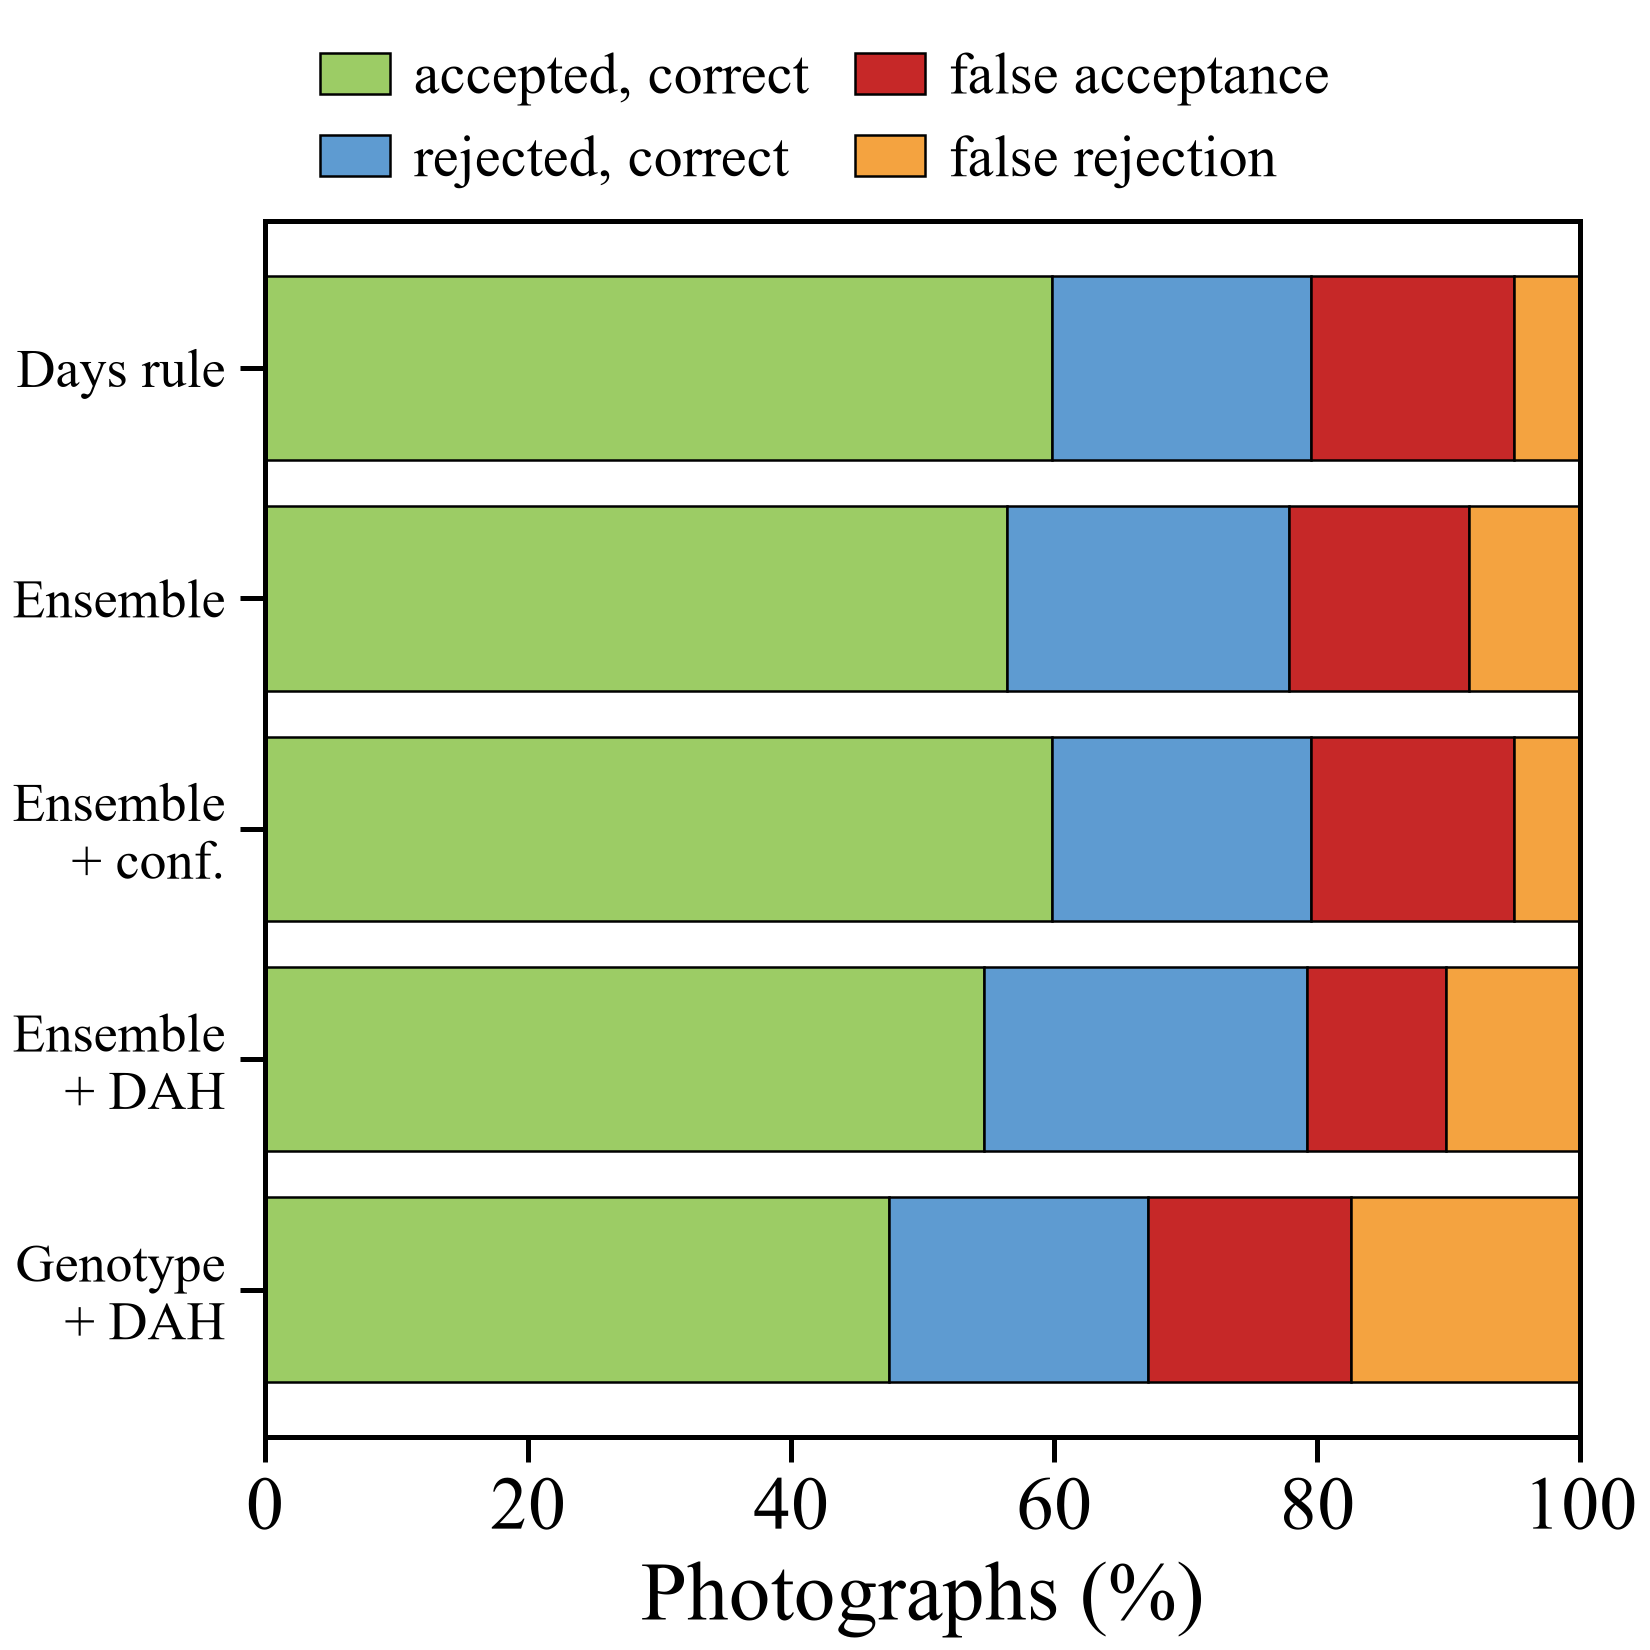

Fig. 8, panel D:
  · P3 · unseen genotype: outcome of the accept / reject decision for each rule (truth: remaining shelf life < 0 → reject)
  · days rule = reject if more than 10.7 days after harvest; '+ conf.' = the photograph decides only when its 90% conformal interval does not cross 0, otherwise the days rule decides; '+ DAH' = photograph and known storage days; genotype + DAH = ceiling


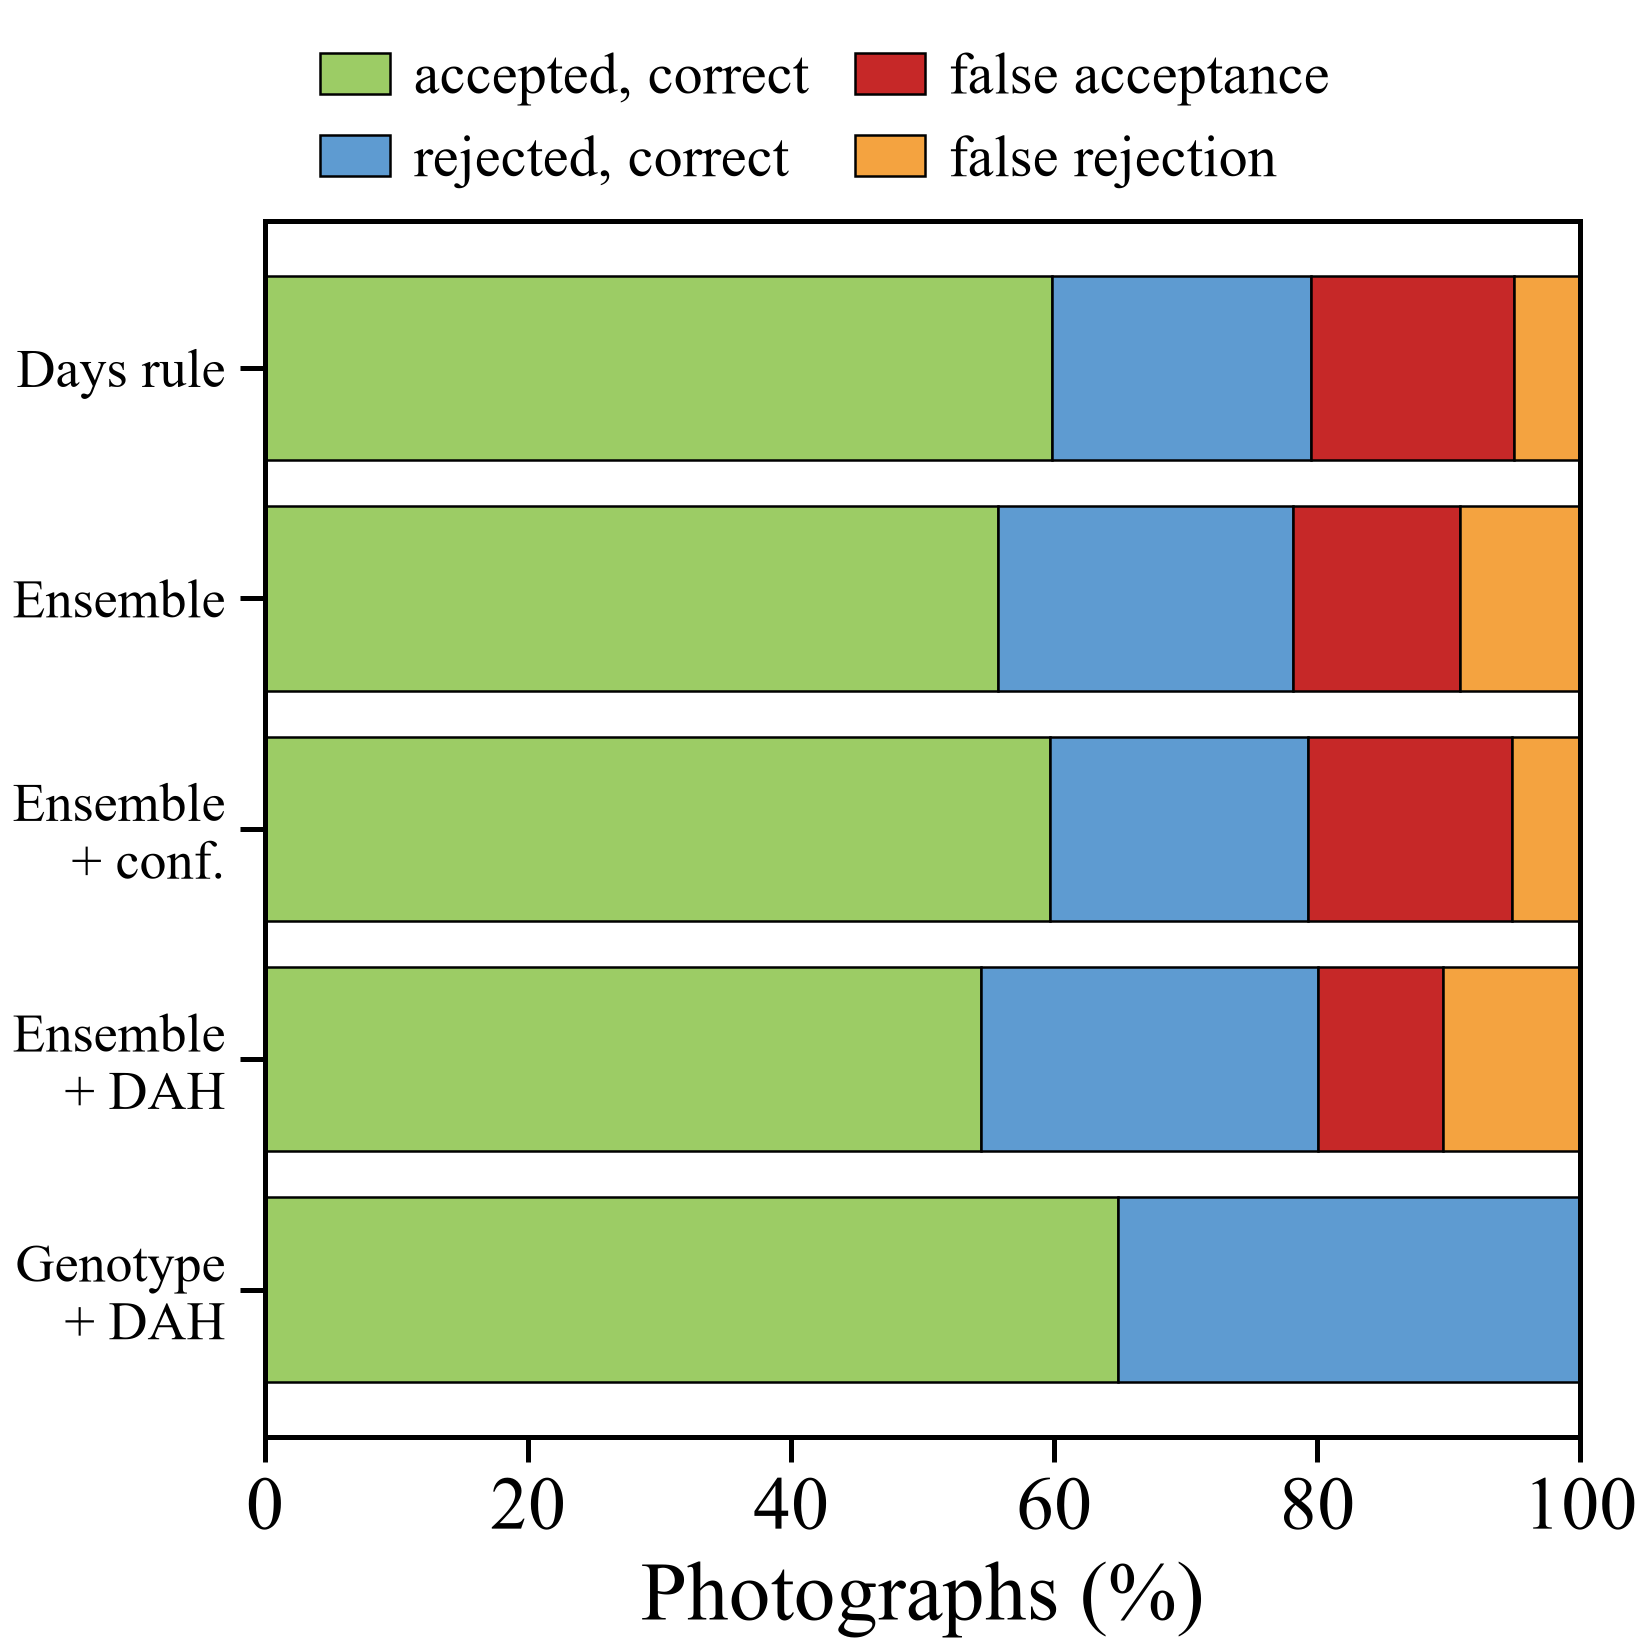

Fig. S2, panel C:
  · P1 · session: outcome of the accept / reject decision for each rule (truth: remaining shelf life < 0 → reject)
  · days rule = reject if more than 10.7 days after harvest; '+ conf.' = the photograph decides only when its 90% conformal interval does not cross 0, otherwise the days rule decides; '+ DAH' = photograph and known storage days; genotype + DAH = ceiling


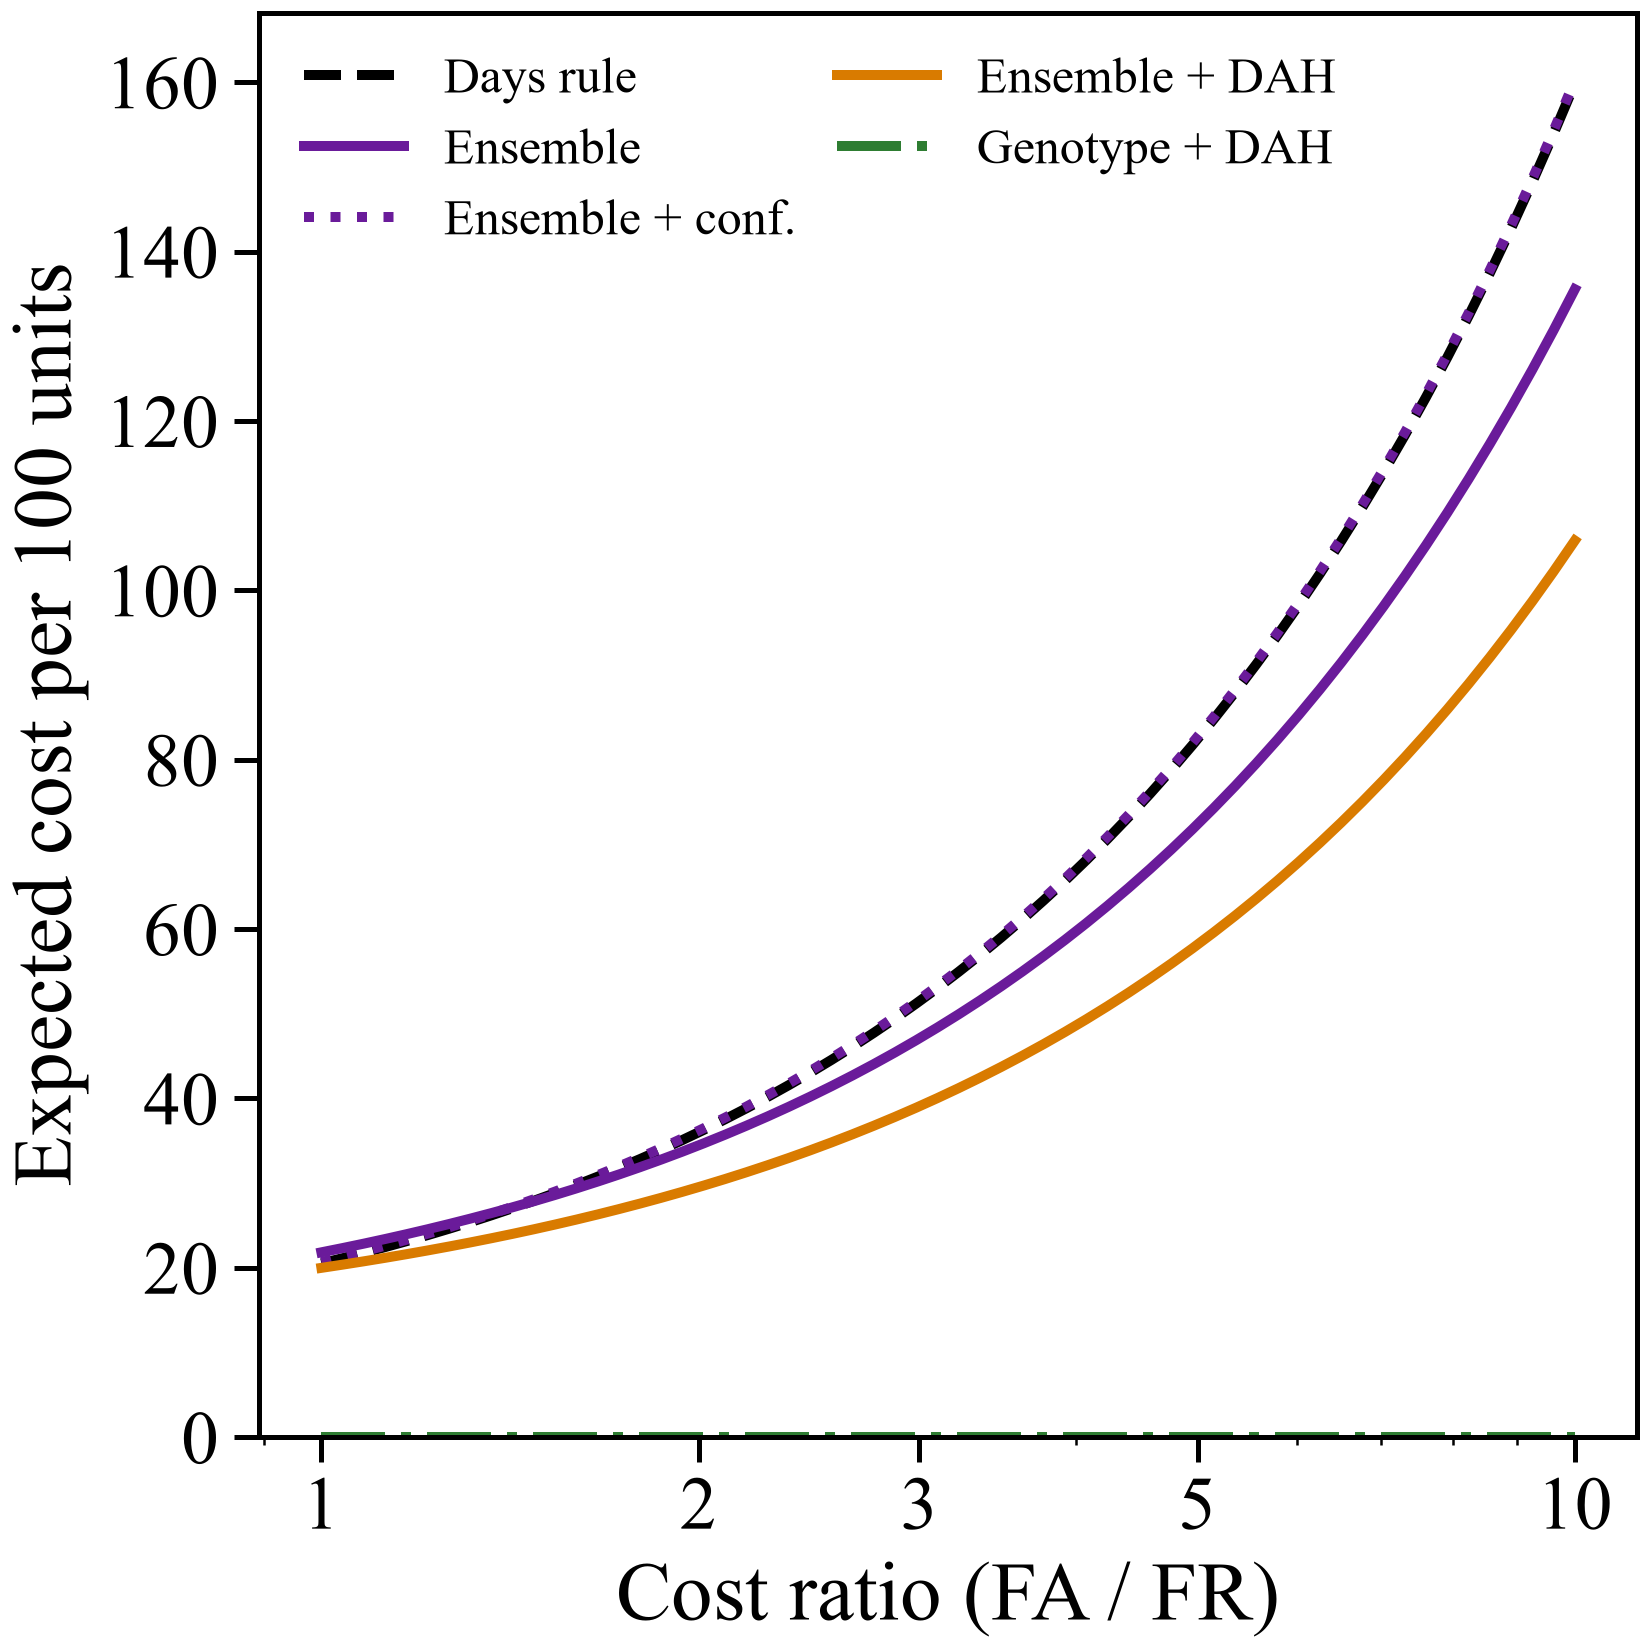

Fig. S2, panel D:
  · P1 · session: expected cost of each decision rule for cost ratios from 1 to 10 (Drummond and Holte, 2006), per 100 units of product (cost of a false rejection = value of one unit); FA = false acceptance, FR = false rejection
  · one unit = the value of the product discarded; wholesale price of green onion in Corabastos ranged from COP 1,458 to 5,833 per kg (SIPSA-DANE, 2025–2026); a rule is better where its line is lower


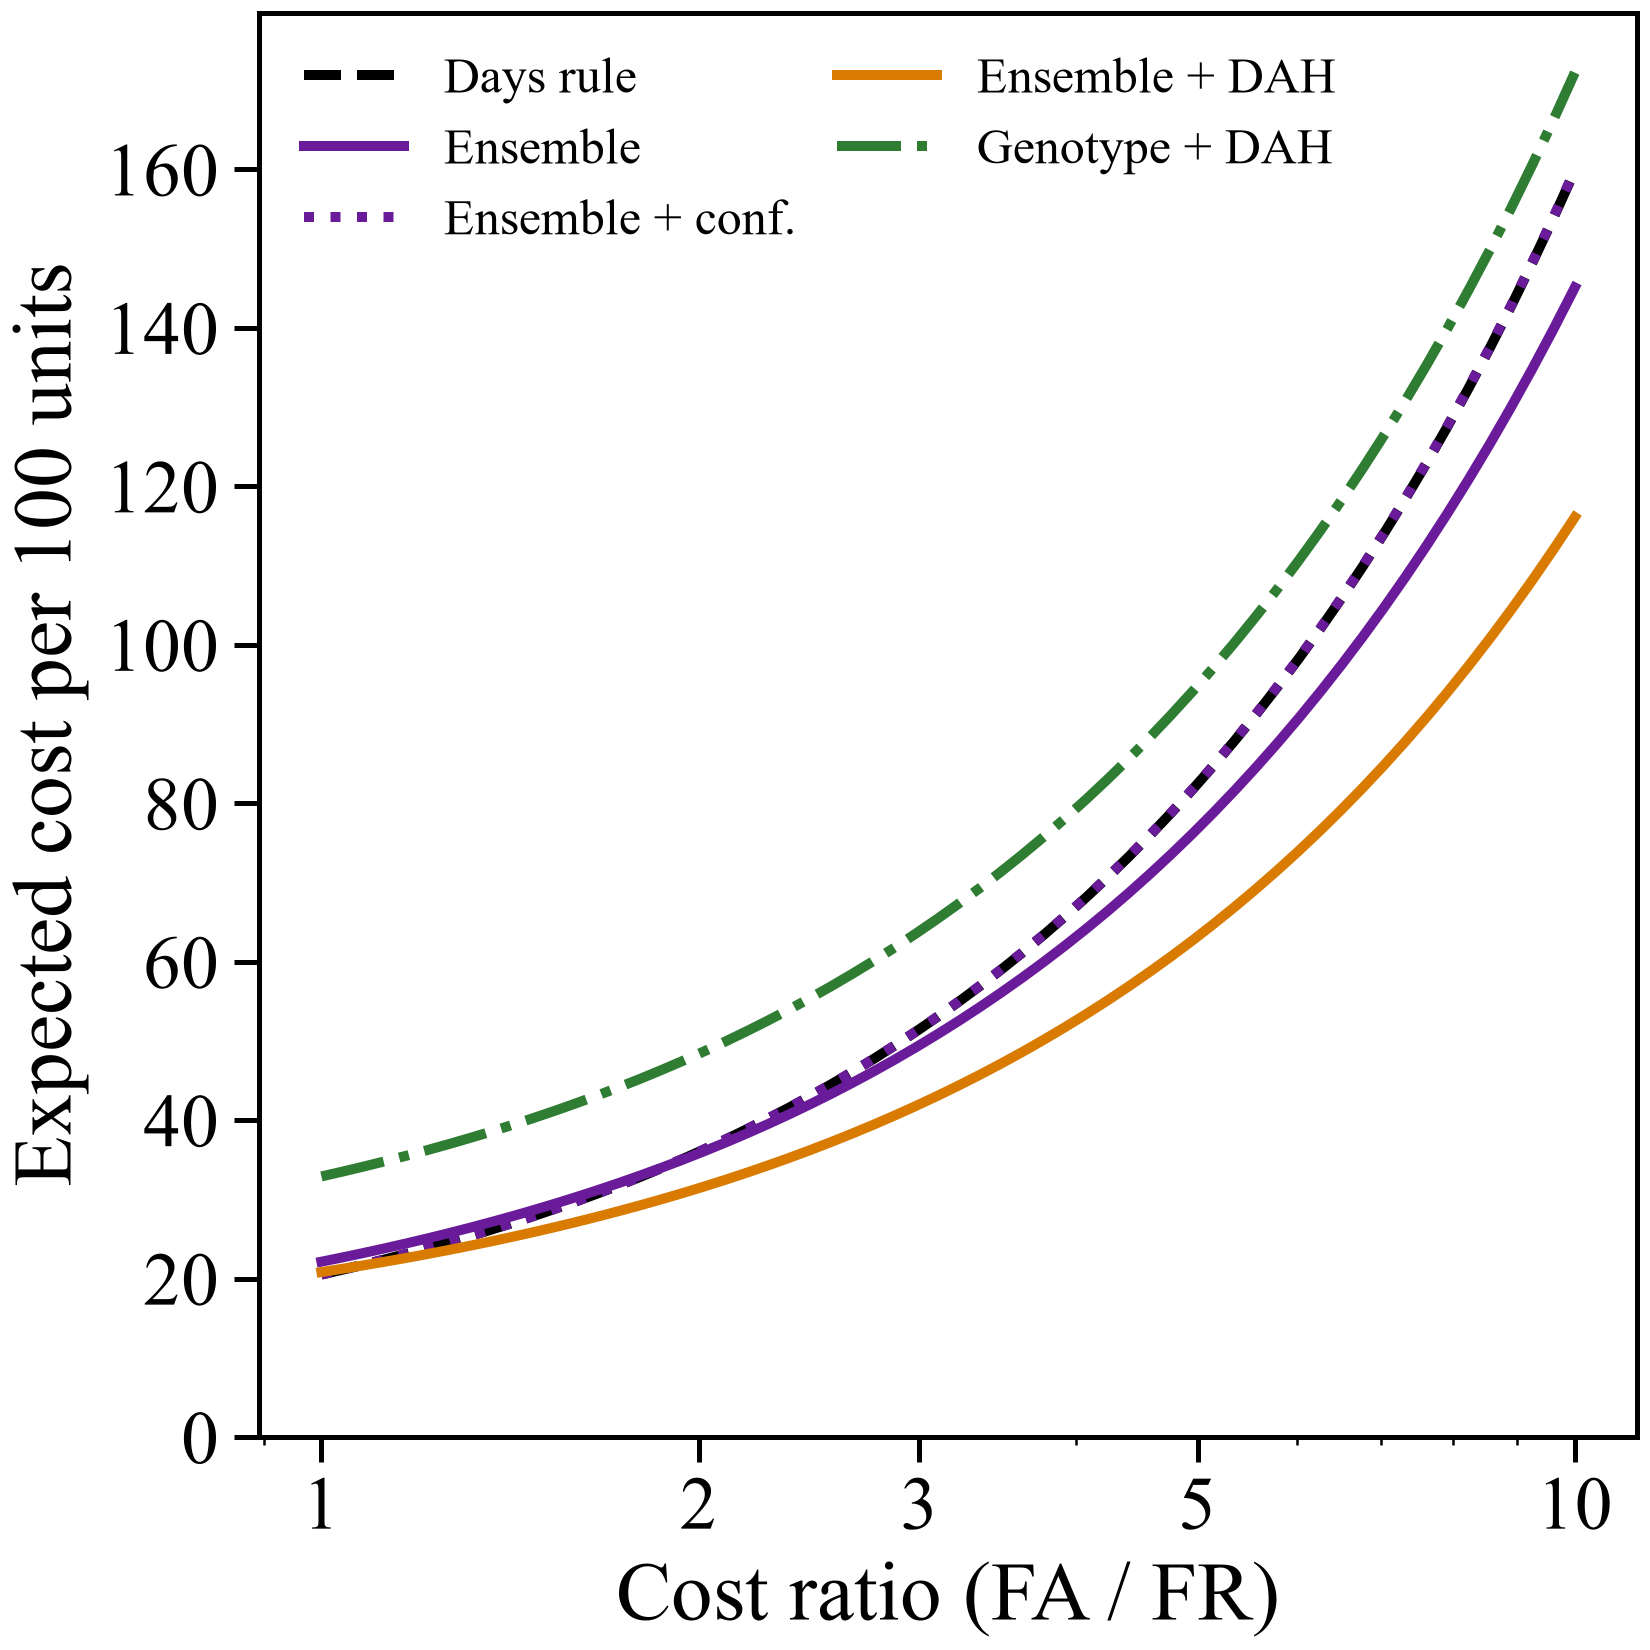

Fig. S2, panel E:
  · P3 · unseen genotype: expected cost of each decision rule for cost ratios from 1 to 10 (Drummond and Holte, 2006), per 100 units of product (cost of a false rejection = value of one unit); FA = false acceptance, FR = false rejection
  · one unit = the value of the product discarded; wholesale price of green onion in Corabastos ranged from COP 1,458 to 5,833 per kg (SIPSA-DANE, 2025–2026); a rule is better where its line is lower


In [25]:
# ---- Fig. S2C (P1) y Fig. 8D (P3): resultado de la decisión
OUTCOME = [("Accepted, acceptable (%)", "#9CCC65", "accepted, correct"), ("Rejected, should reject (%)", "#5E9BD1", "rejected, correct"),
           ("Accepted, should reject (%)", "#C62828", "false acceptance"), ("Rejected, acceptable (%)", "#F4A340", "false rejection")]
SHORT = ["Days rule", "Ensemble", "Ensemble\n+ conf.", "Ensemble\n+ DAH", "Genotype\n+ DAH"]
for tag, sc in [("8D", "P3"), ("S2C", "P1")]:
    fig, ax = panel()
    x = DEC[DEC._sc == sc].set_index("Decision rule").reindex(RULES)
    left = np.zeros(len(RULES))
    for col, c, lab_ in OUTCOME:
        ax.barh(range(len(RULES)), x[col], left=left, color=c, edgecolor="black", lw=0.6, label=lab_)
        left += x[col].to_numpy()
    ax.set_yticks(range(len(RULES))); ax.set_yticklabels(SHORT, fontsize=13); ax.invert_yaxis()
    ax.set_xlabel("Photographs (%)"); ax.set_xlim(0, 100)
    leyenda_arriba(fig, ax, ncol=2, fontsize=14)
    titulo(ax, tag)
    mostrar(fig)
    nota(f"{SCHEME_LABEL[sc]}: outcome of the accept / reject decision for each rule (truth: remaining shelf life < 0 → reject)",
         f"days rule = reject if more than {SL_MED:.1f} days after harvest; '+ conf.' = the photograph decides only when its 90% conformal "
         "interval does not cross 0, otherwise the days rule decides; '+ DAH' = photograph and known storage days; genotype + DAH = ceiling")

# ---- Fig. S2D (P1) y S3E (P3): curvas de costo
ratio = np.logspace(0, 1, 60)
STY = {"Days rule": ("#000000", "--"), "Ensemble": (MODEL_COLOR["Ensemble"], "-"), "Ensemble + conformal": (MODEL_COLOR["Ensemble"], ":"),
       "Ensemble + DAH": ("#D97B00", "-"), "Genotype + DAH": (MODEL_COLOR["Genotype + DAH"], "-.")}
for tag, sc in [("S2D", "P1"), ("S2E", "P3")]:
    fig, ax = panel()
    x = DEC[DEC._sc == sc].set_index("Decision rule")
    for name in RULES:
        c, ls = STY[name]
        ax.plot(ratio, 100 * (ratio * x.loc[name, "_fa"] + x.loc[name, "_fr"]), color=c, ls=ls, lw=2.4, label=SHORT[RULES.index(name)].replace("\n", " "))
    ax.set_xscale("log"); ax.set_xticks([1, 2, 3, 5, 10]); ax.set_xticklabels([1, 2, 3, 5, 10])
    ax.set_xlabel("Cost ratio (FA / FR)"); ax.set_ylabel("Expected cost per 100 units"); ax.set_ylim(bottom=0)
    ax.legend(loc="upper left", frameon=False, fontsize=12, ncol=2, columnspacing=0.8)
    titulo(ax, tag)
    mostrar(fig)
    nota(f"{SCHEME_LABEL[sc]}: expected cost of each decision rule for cost ratios from 1 to 10 (Drummond and Holte, 2006), per 100 units "
         "of product (cost of a false rejection = value of one unit); FA = false acceptance, FR = false rejection",
         "one unit = the value of the product discarded; wholesale price of green onion in Corabastos ranged from COP 1,458 to 5,833 per kg "
         "(SIPSA-DANE, 2025–2026); a rule is better where its line is lower")

**Lectura.** La regla por días deja pasar el 15,5 % de las fotos que deberían rechazarse y rechaza el 5,0 %
que todavía es aceptable: las de ANTSRO029 y ANTSNC003 a 14 DAH, cuya vida útil supera los 14 d (especificidad
0,92). La foto sola cambia poco el balance (en P3: 13,7 % de falsos aceptados y 8,5 % de falsos rechazos).
**La foto junto con el DAH** baja los falsos aceptados a 10,6 % en genotipos no vistos, a cambio de 10,2 % de
falsos rechazos, y es la regla de menor costo esperado cuando un falso aceptado cuesta más que un falso rechazo
(razón > 1,1; Fig. S2E), que es el caso previsto. Los intervalos conformales
del 90 % son **anchos** (≈ ±5 d para el DAH y ±6 d para la vida útil restante): la foto solo queda segura del
lado correcto del 0 en 11–17 % de las fotos y el resto lo decide la regla por días, de modo que la versión
conformal coincide casi con la regla por días. La cobertura se cumple cuando la calibración imita bien la
prueba (P1 por sesión y P3: 0,84–0,92) y suele quedar por debajo de 0,90 con un día, un tiempo o un grupo de fotografía nuevos
(0,57–0,90), porque esas condiciones no estaban representadas en la calibración.

### 5.3 Muestra: varios pseudotallos

En la práctica se fotografían **varios pseudotallos de una muestra**. Con las predicciones de P3 (genotipo no
visto), se promedian las fotos de cada pseudotallo y se toman al azar *k* pseudotallos de cada celda (300
sorteos sin reemplazo); el error de la muestra es el de la media de esos *k*. Las celdas tienen las cuatro clases
en proporciones iguales (diseño), así que la muestra simulada tiene ese mismo balance.

In [26]:
KS = [1, 2, 3, 5, 8, 12, 16]
P = VAL2["schemes"]["P3"]["pred"]
lotcurve = {}
for t in ["dah", "gqi_e2"]:
    m = OKV & np.isfinite(P[f"Ens|{t}"])
    ps = pd.DataFrame({"cell": CELL[m], "pseudo": PSEUDO[m], "p": P[f"Ens|{t}"][m], "y": vd[t].to_numpy()[m]}).groupby("pseudo").agg(
        cell=("cell", "first"), p=("p", "mean"), y=("y", "first"))
    rng = np.random.default_rng(5); err = {k: [] for k in KS}
    for c, s in ps.groupby("cell"):
        for k in KS:
            if k > len(s):
                continue
            draws = np.array([rng.choice(s["p"].to_numpy(), k, replace=False).mean() for _ in range(300)])
            err[k].append(np.mean(np.abs(draws - s["y"].iloc[0])))
    lotcurve[t] = pd.Series({k: np.mean(v) for k, v in err.items() if v})
    pseudos_per_cell = ps.groupby("cell").size()
ref = {t: RES[(RES.scheme == "P3") & (RES.level == "cell") & (RES.output == t)].set_index("model")["MAE"] for t in ["dah", "gqi_e2"]}
TABLE_LOT = pd.DataFrame({f"MAE {OUTPUTS[t]}": lotcurve[t] for t in lotcurve}).rename_axis("pseudostems per sample (k)").round(2)
print(f"pseudotallos por celda: mediana {pseudos_per_cell.median():.0f} (rango {pseudos_per_cell.min()}–{pseudos_per_cell.max()})")
print("Detail table D11 (→ Table 3). P3 (genotype not seen in training): mean absolute error of the sample estimate (Ensemble) when k pseudostems of the "
      "sample are photographed (photographs of each pseudostem averaged; 300 random draws per cell)")
display(TABLE_LOT)
print(f"referencias P3 (MAE por celda): DAH trivial {ref['dah']['Trivial']:.2f} d · GQI solo DAH {ref['gqi_e2']['DAH only']:.2f} · "
      f"GQI trivial {ref['gqi_e2']['Trivial']:.2f}")

pseudotallos por celda: mediana 25 (rango 16–36)
Detail table D11 (→ Table 3). P3 (genotype not seen in training): mean absolute error of the sample estimate (Ensemble) when k pseudostems of the sample are photographed (photographs of each pseudostem averaged; 300 random draws per cell)


,MAE Days after harvest (d),MAE GQI
pseudostems per sample (k),,
1,2.30,9.65
2,2.18,9.14
3,2.12,9.03
5,2.09,8.90
8,2.07,8.82
12,2.06,8.78
16,2.05,8.76


referencias P3 (MAE por celda): DAH trivial 4.00 d · GQI solo DAH 10.98 · GQI trivial 14.46


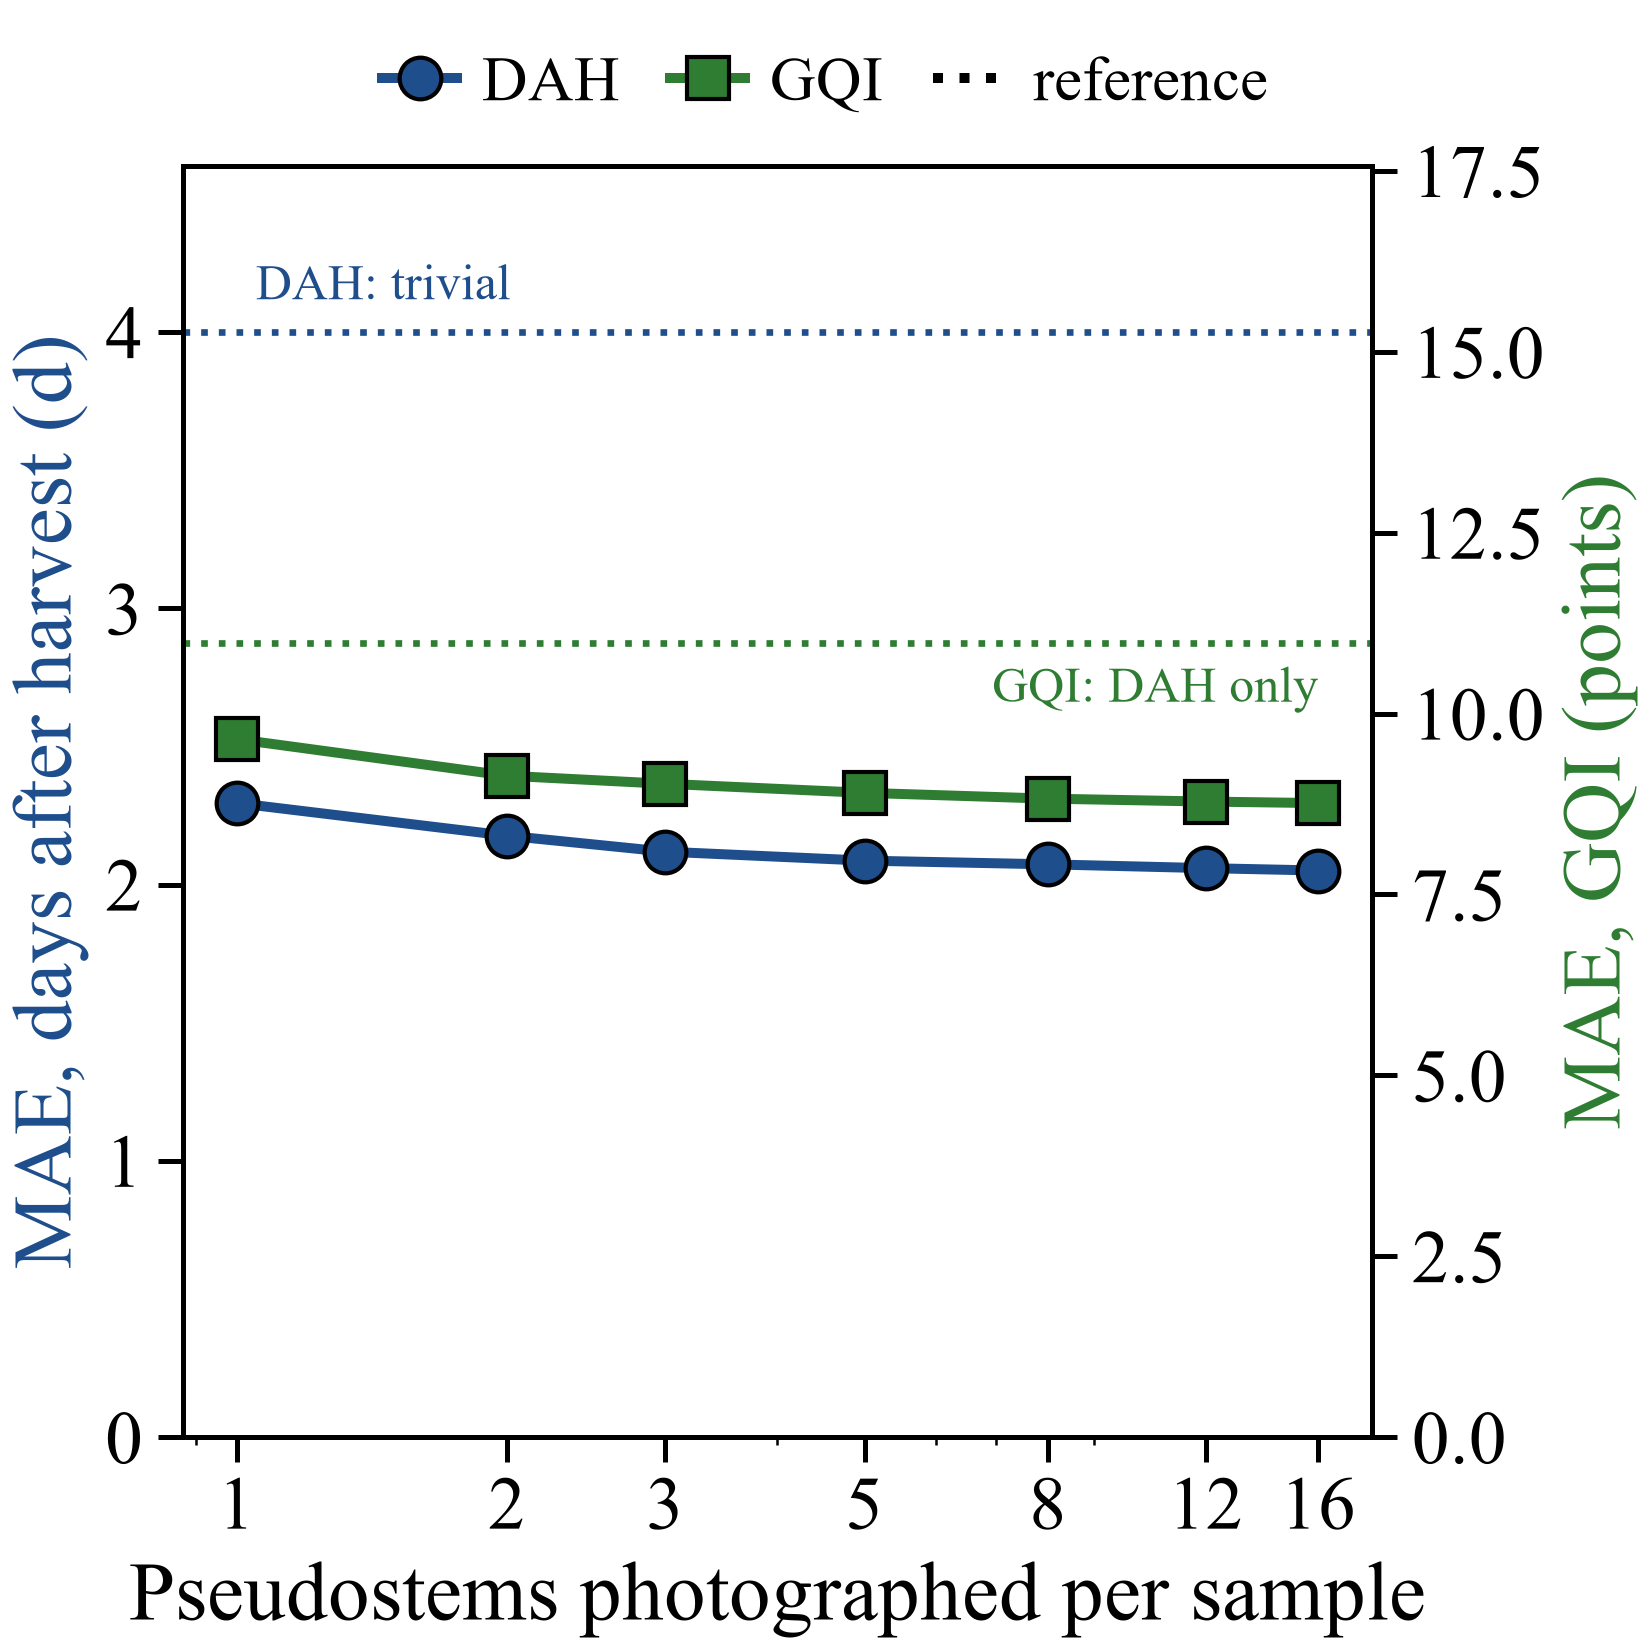

Fig. S2, panel A:
  · P3 (genotype not seen in training): mean absolute error of the sample estimate when k pseudostems of the sample are photographed (Ensemble; photographs of each pseudostem averaged; 300 random draws per cell)
  · dotted lines = references per cell: DAH, trivial (always the mean DAH); GQI, DAH only (requires knowing the storage days)


In [27]:
# ---- Fig. S2A: error de la muestra según el número de pseudotallos fotografiados
fig, ax = panel()
ax.plot(lotcurve["dah"].index, lotcurve["dah"].to_numpy(), marker="o", color="#1F4E8C", mec="black", label="Days after harvest (d)")
ax.axhline(ref["dah"]["Trivial"], color="#1F4E8C", ls=":", lw=1.6)
ax2 = ax.twinx()
ax2.plot(lotcurve["gqi_e2"].index, lotcurve["gqi_e2"].to_numpy(), marker="s", color="#2E7D32", mec="black", label="GQI (points)")
ax2.axhline(ref["gqi_e2"]["DAH only"], color="#2E7D32", ls=":", lw=1.6)
ax.set_xscale("log"); ax.set_xticks(KS); ax.set_xticklabels(KS)
ax.set_xlabel("Pseudostems photographed per sample"); ax.set_ylabel("MAE, days after harvest (d)", color="#1F4E8C")
ax2.set_ylabel("MAE, GQI (points)", color="#2E7D32")
ax.set_ylim(0, 1.15 * ref["dah"]["Trivial"]); ax2.set_ylim(0, 1.6 * ref["gqi_e2"]["DAH only"])
ax.text(1.05, ref["dah"]["Trivial"] * 1.02, "DAH: trivial", color="#1F4E8C", fontsize=12, va="bottom")
ax2.text(16, ref["gqi_e2"]["DAH only"] * 0.97, "GQI: DAH only", color="#2E7D32", fontsize=12, va="top", ha="right")
leyenda_arriba(fig, ax, handles=[Line2D([0], [0], color="#1F4E8C", marker="o", mec="black", label="DAH"),
                                 Line2D([0], [0], color="#2E7D32", marker="s", mec="black", label="GQI"),
                                 Line2D([0], [0], color="black", ls=":", label="reference")], ncol=3)
titulo(ax, "S2A")
mostrar(fig)
nota("P3 (genotype not seen in training): mean absolute error of the sample estimate when k pseudostems of the sample are photographed (Ensemble; "
     "photographs of each pseudostem averaged; 300 random draws per cell)",
     "dotted lines = references per cell: DAH, trivial (always the mean DAH); GQI, DAH only (requires knowing the storage days)")

**Lectura.** Fotografiar más pseudotallos de la muestra reduce poco el error (DAH: de 2,3 d con uno a 2,05 d con
16; GQI: de 9,7 a 8,8 puntos), frente a 4,0 d de la referencia trivial para el DAH y 11,0 puntos de *solo DAH*
para el GQI. El error que queda es sobre todo **sistemático por celda** (un genotipo no visto se estima con un
sesgo), no ruido entre pseudotallos; con 5 pseudotallos ya se obtiene casi todo el beneficio.

# 6. Qué mira el modelo

**Qué responde.** Si, sin fondo, lo que cambia la estimación está sobre el tejido de la planta.

**Paneles y por qué van juntos** → **Fig. S3** (suplemento): **A–H** ocho mapas de oclusión de fotos de prueba (dos por
tiempo, genotipos no vistos); **I** importancia media por décimo del recorte. Van al suplemento porque confirman, pero no
cambian, el resultado de la Fig. 8.

### 6.1 Oclusión

Como el modelo solo recibe la planta sobre gris neutro, el fondo ya no puede aportar. La pregunta que queda
es **qué partes de la planta** usa. Para el modelo de red (M2) se tapa el recorte con un cuadro gris de
28 × 28 px (paso de 14 px) y se mide cuánto cambia la estimación de los días desde la cosecha; el modelo se
reentrena sin el genotipo de la foto, como en P3. Además, en 120 fotos de prueba al azar se tapa cada décimo
del recorte (de la base a la punta) y se reparte la importancia entre los décimos.

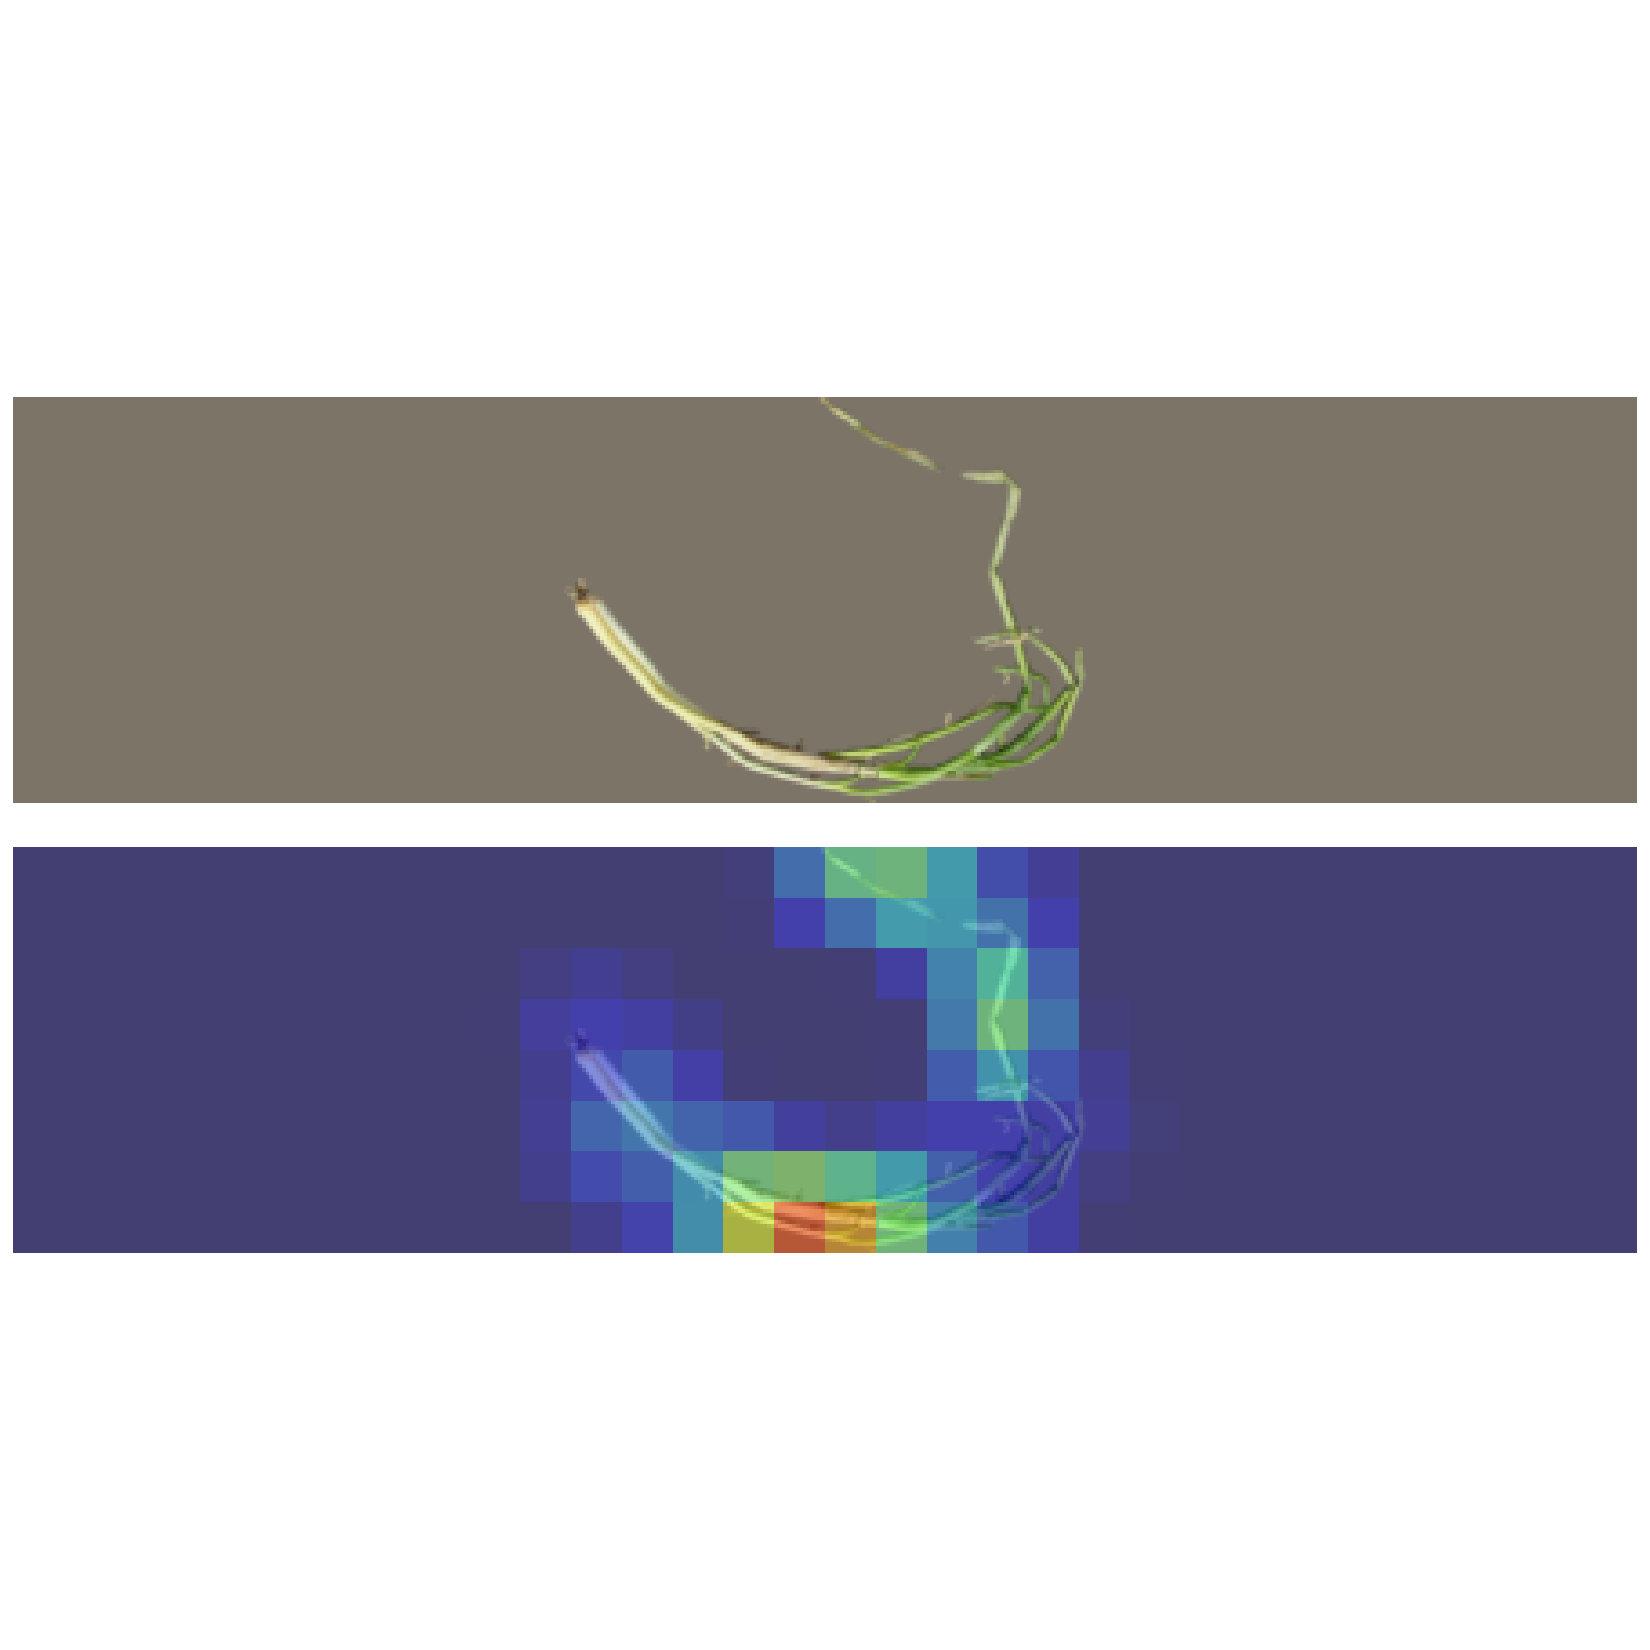

Fig. S3, panel A:
  · test photograph of CUNSBR048 at 2 DAH (Decay); CNN-ridge estimate 6.2 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


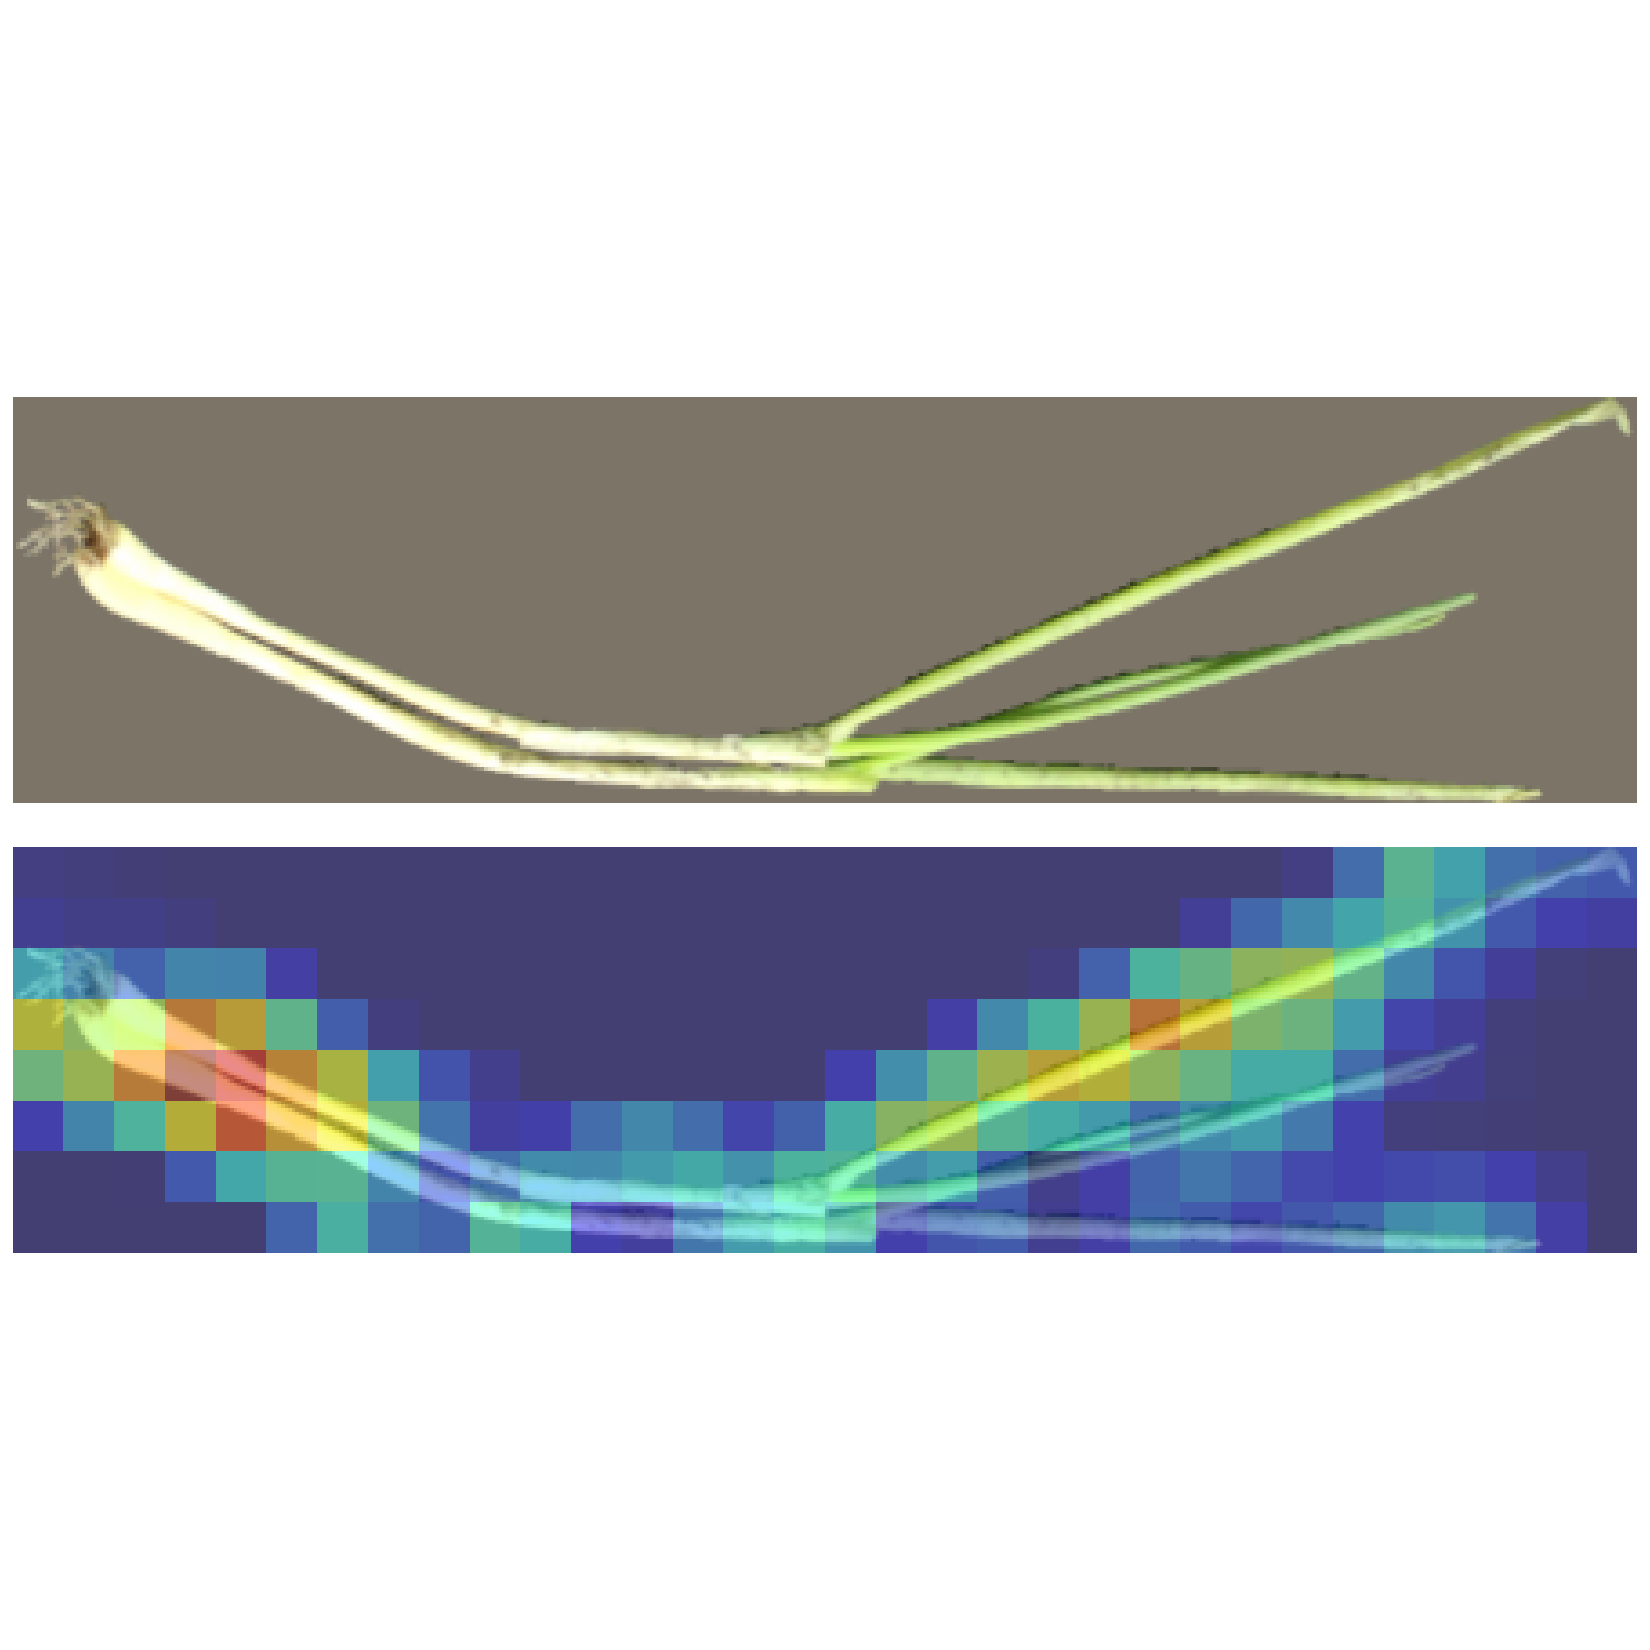

Fig. S3, panel B:
  · test photograph of ANTSRO029 at 2 DAH (Major defects); CNN-ridge estimate 1.7 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


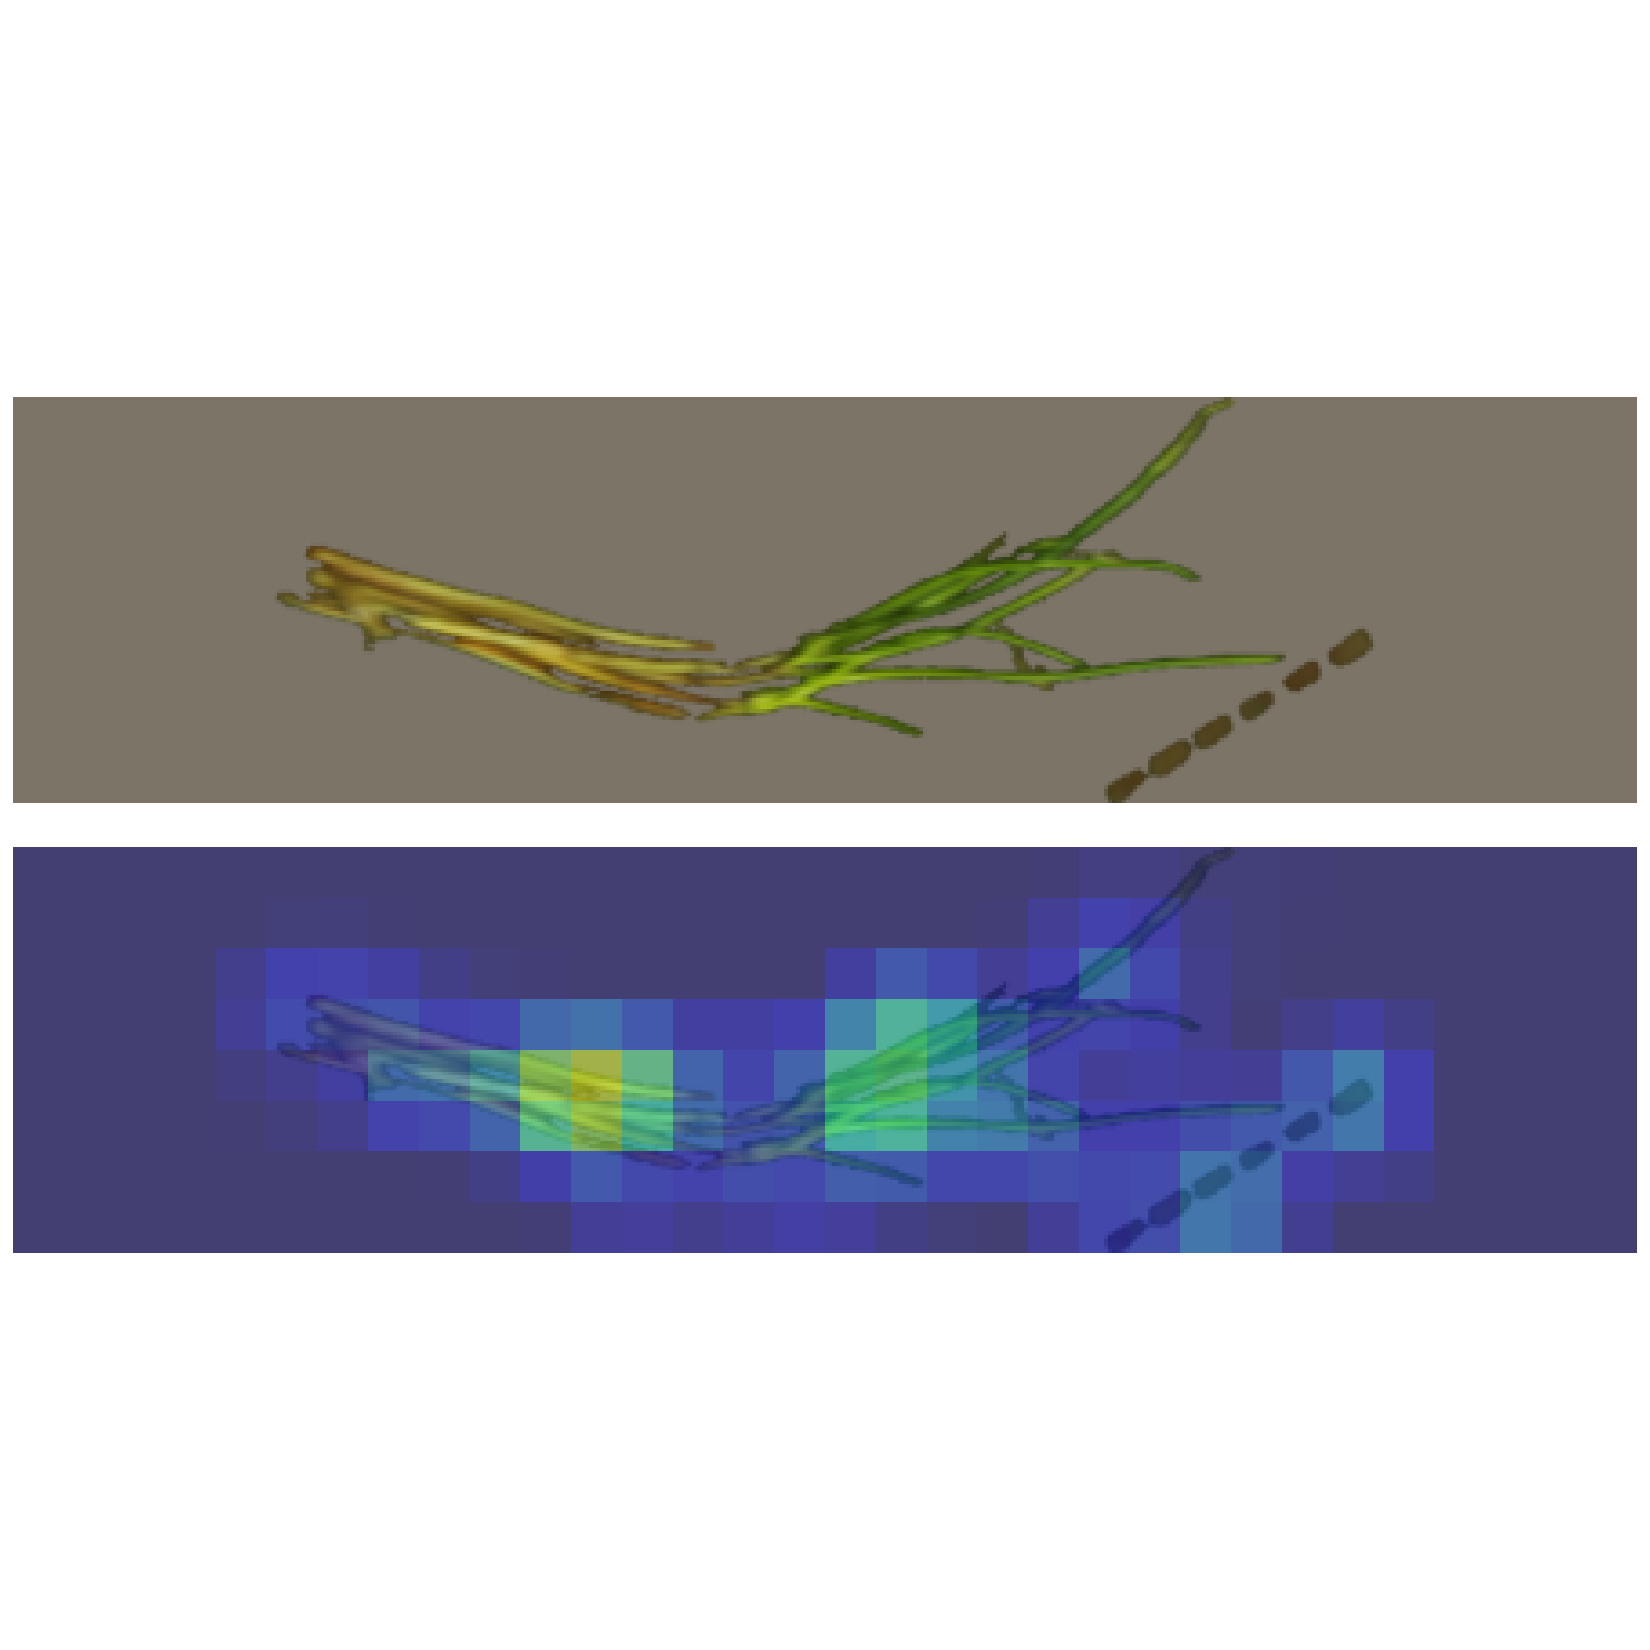

Fig. S3, panel C:
  · test photograph of CUNSBR048 at 6 DAH (Minor defects); CNN-ridge estimate 1.9 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


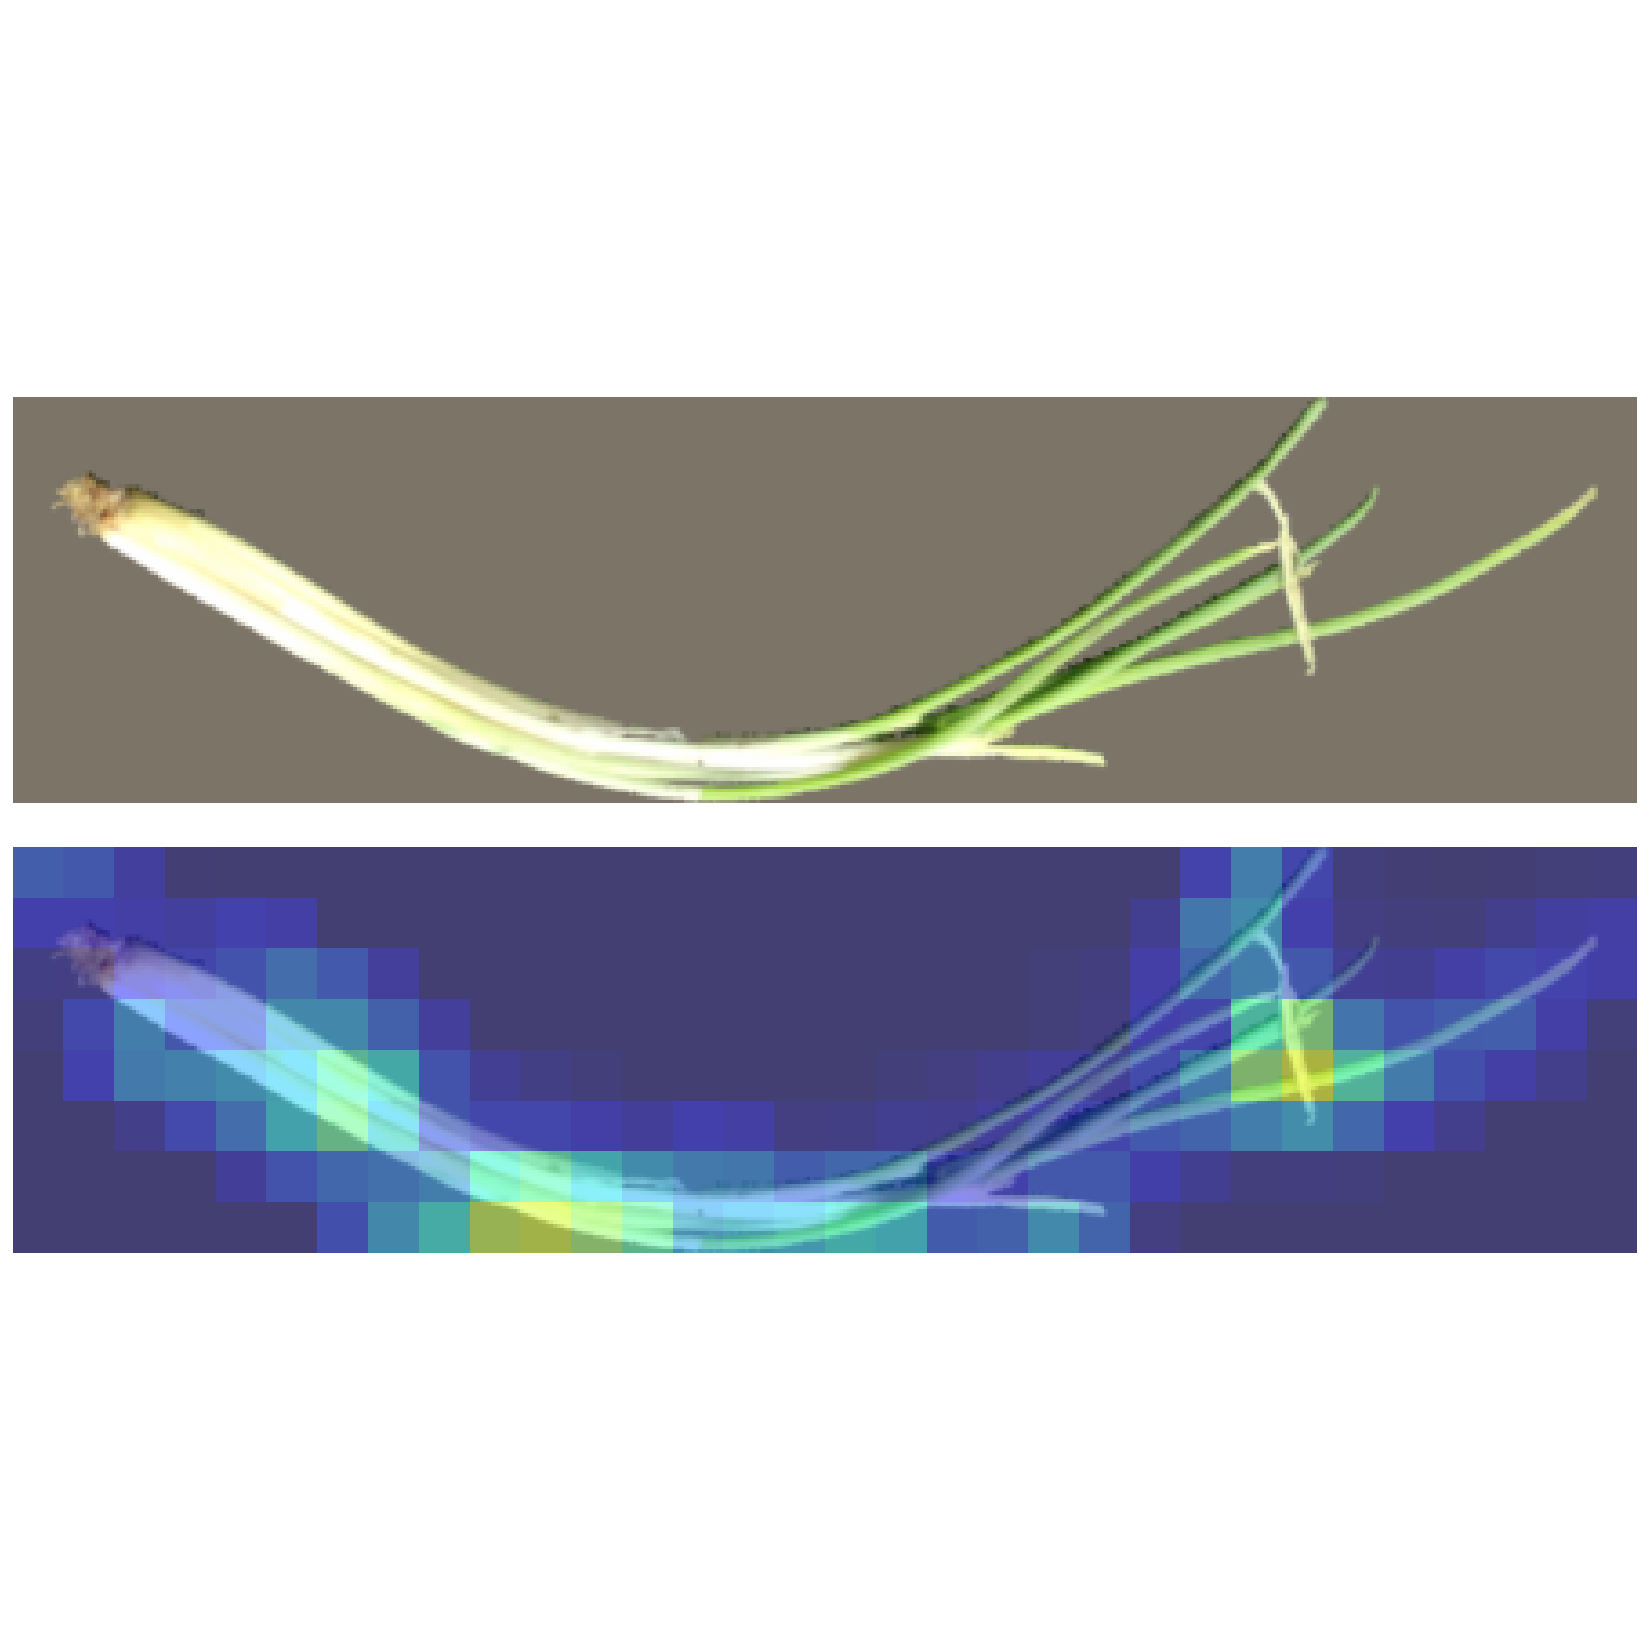

Fig. S3, panel D:
  · test photograph of ANTSRO029 at 6 DAH (On-Grade); CNN-ridge estimate 4.9 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


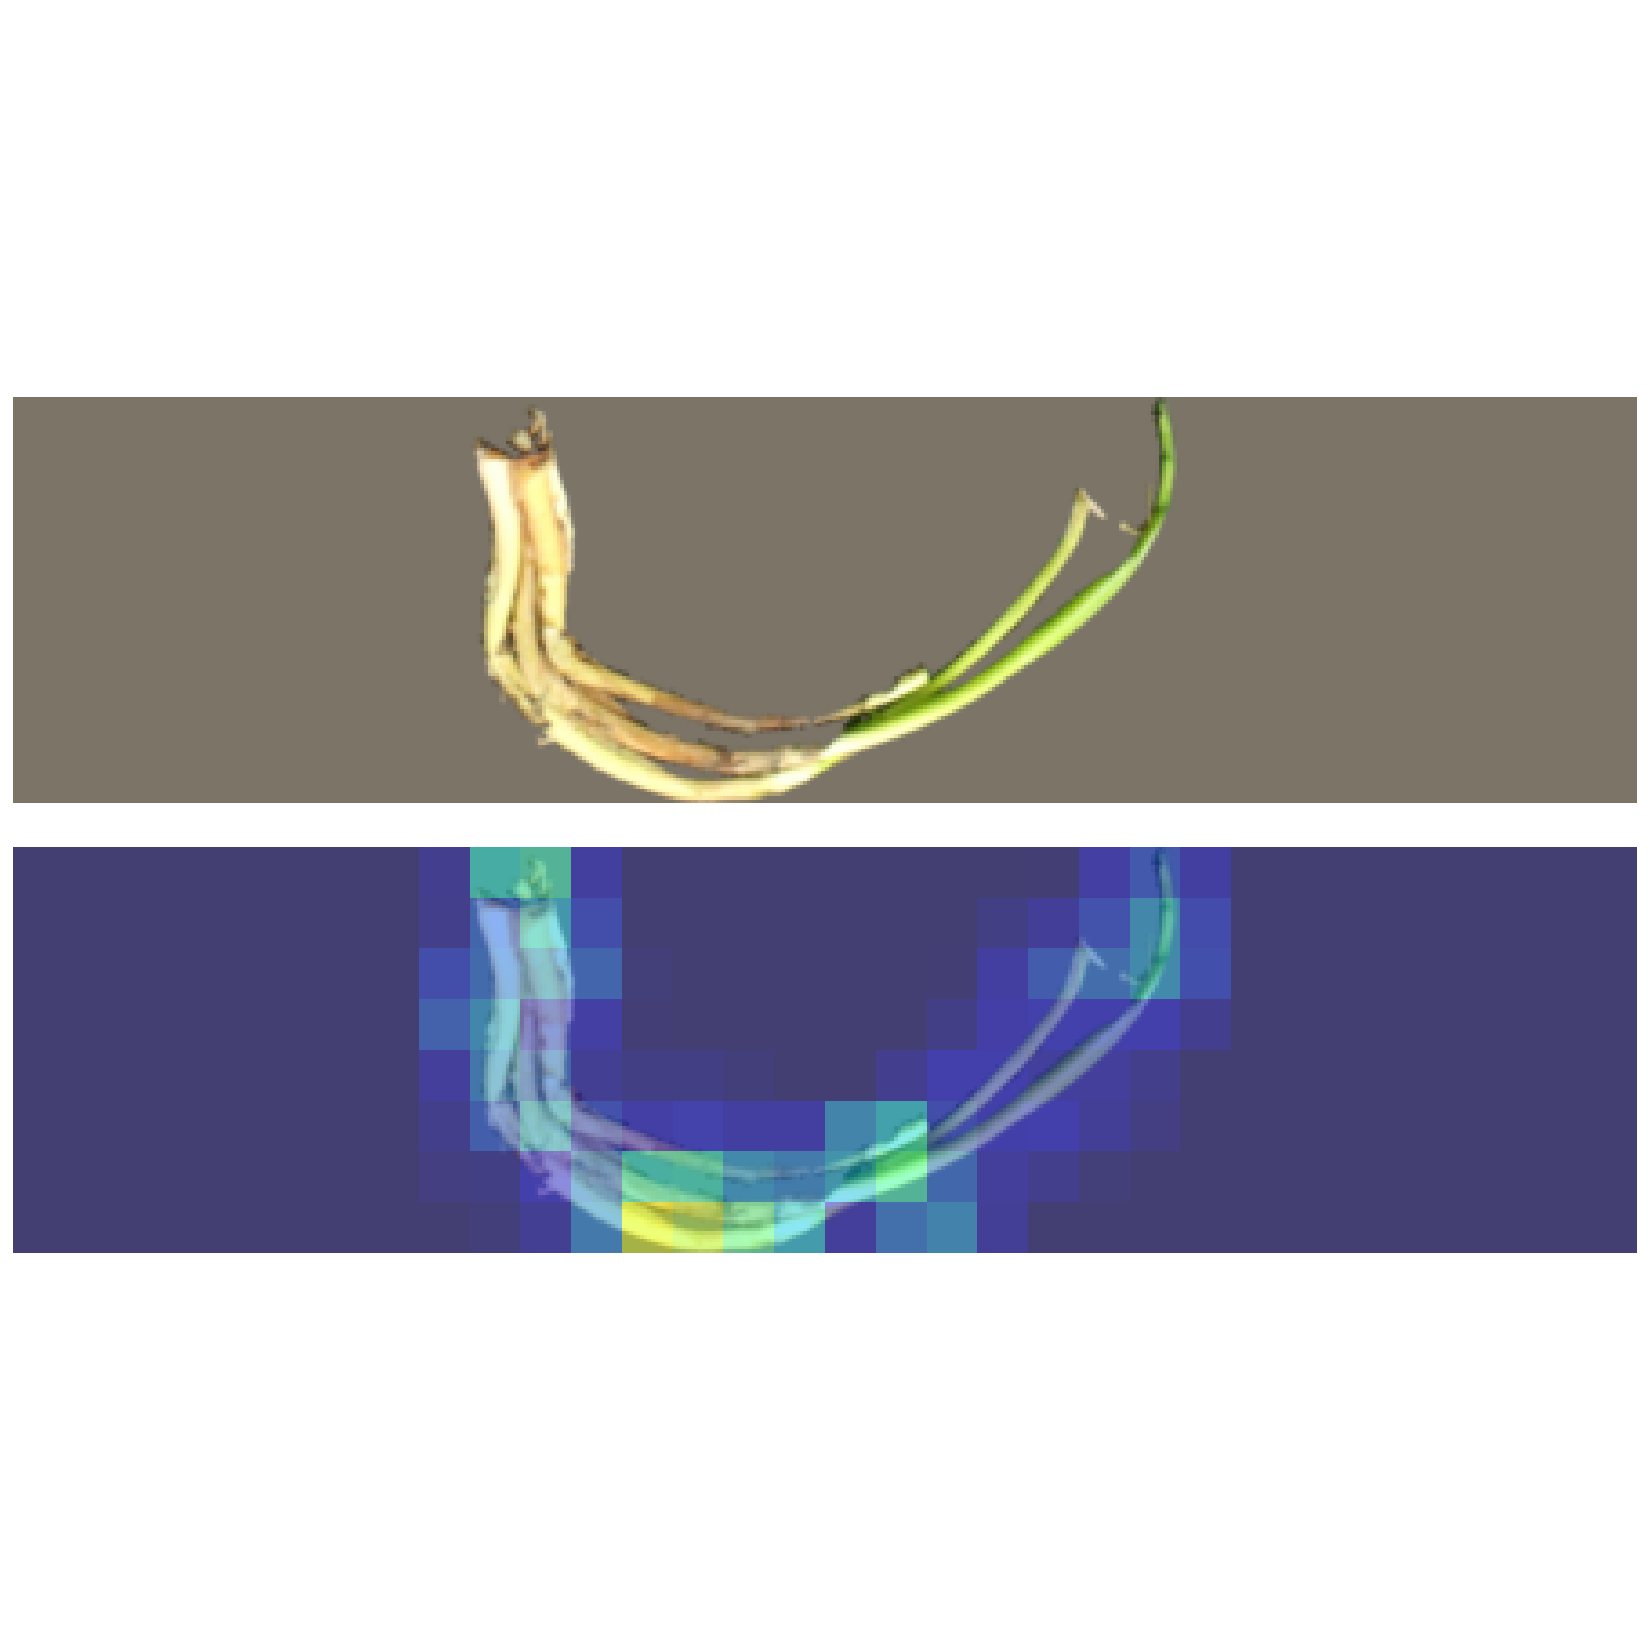

Fig. S3, panel E:
  · test photograph of 91400070 at 10 DAH (Minor defects); CNN-ridge estimate 11.0 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


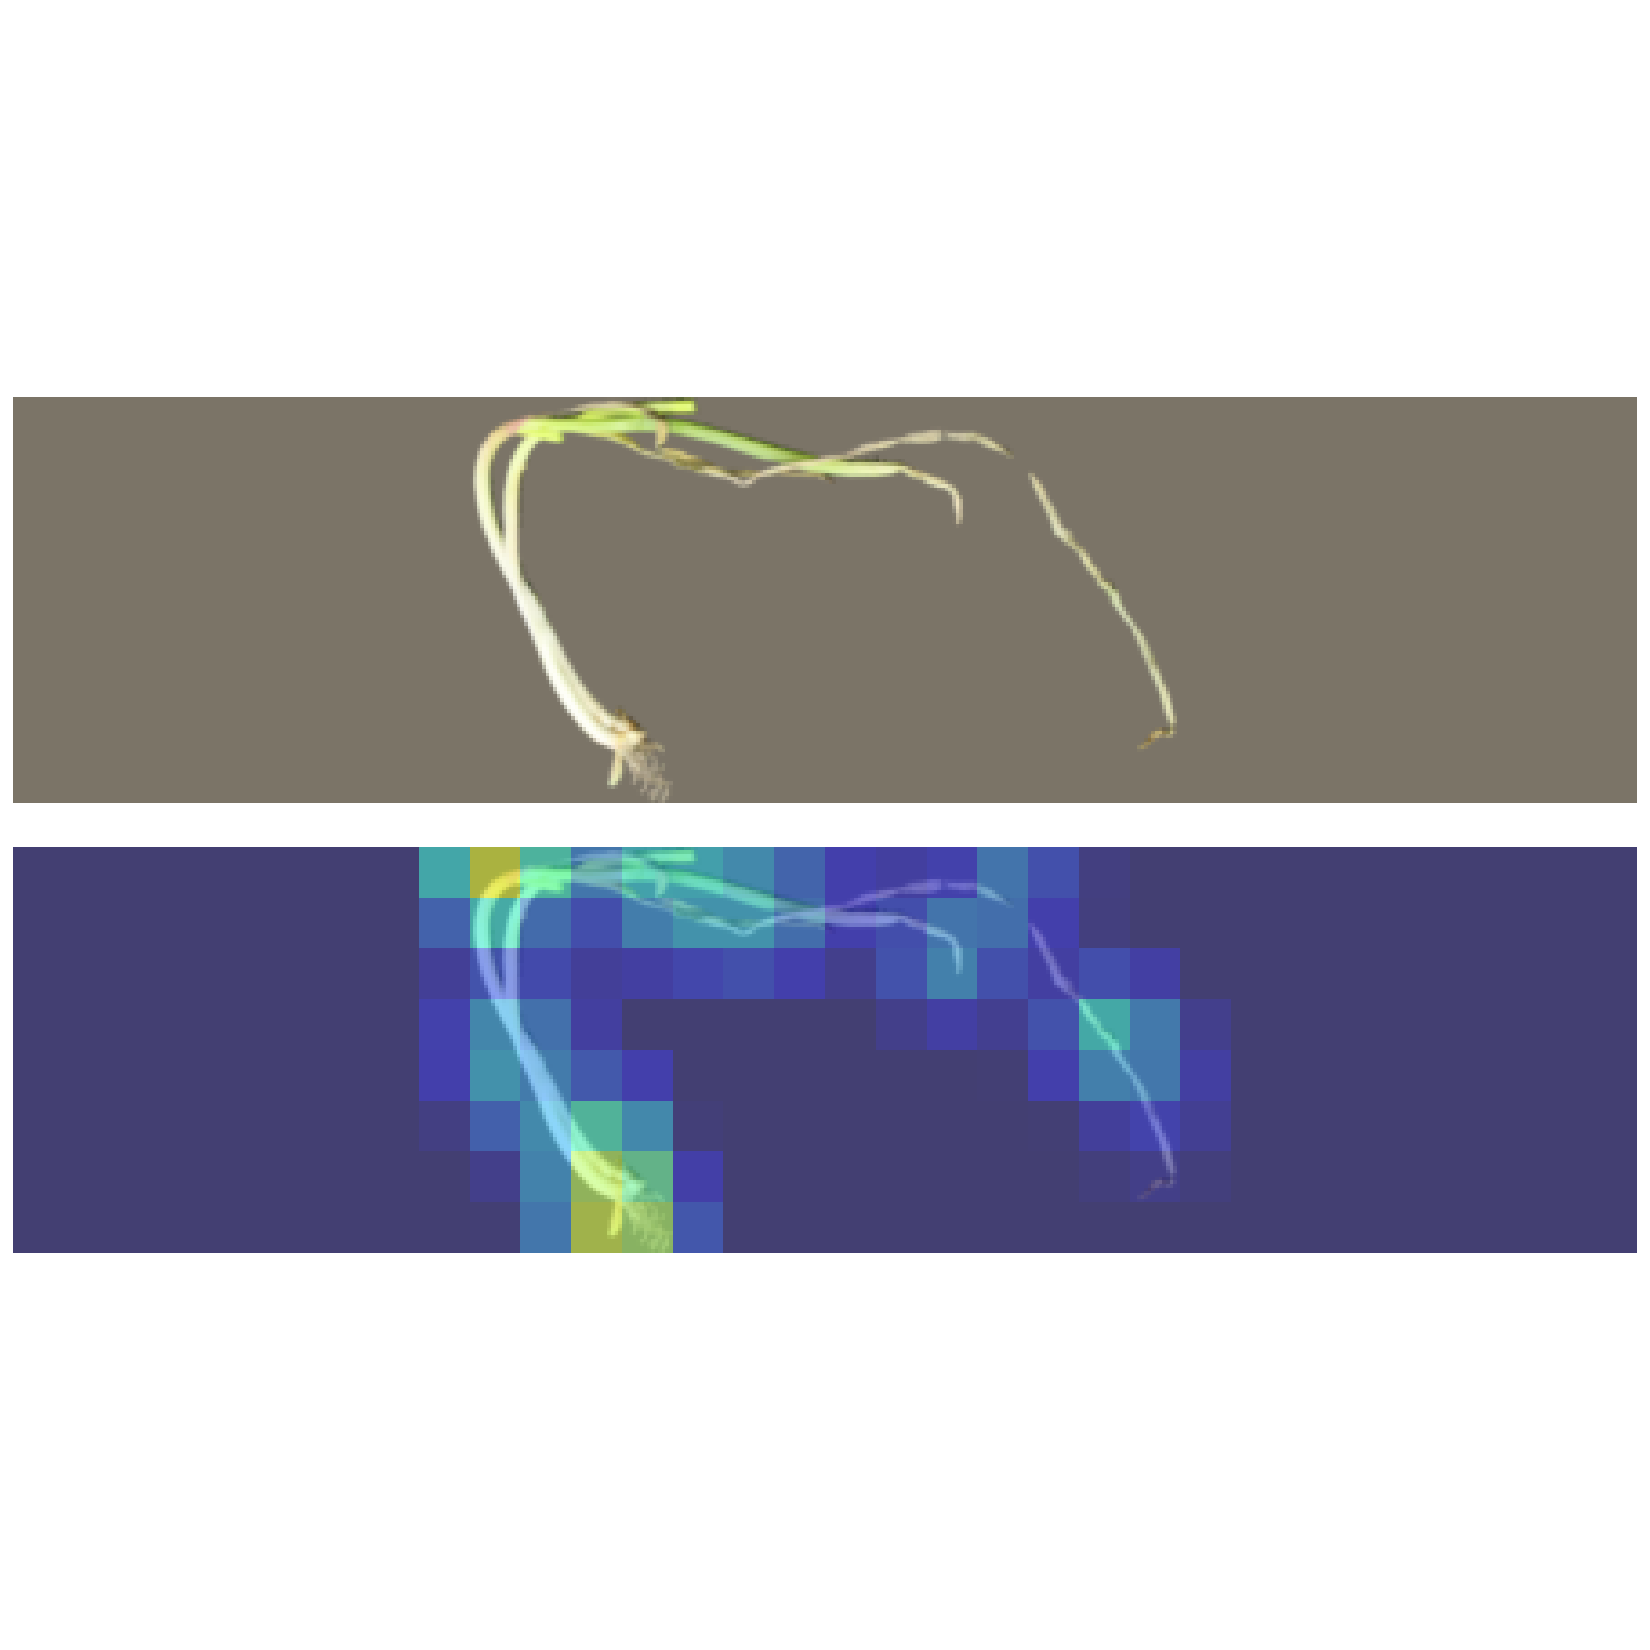

Fig. S3, panel F:
  · test photograph of CUNSBR048 at 10 DAH (On-Grade); CNN-ridge estimate 8.8 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


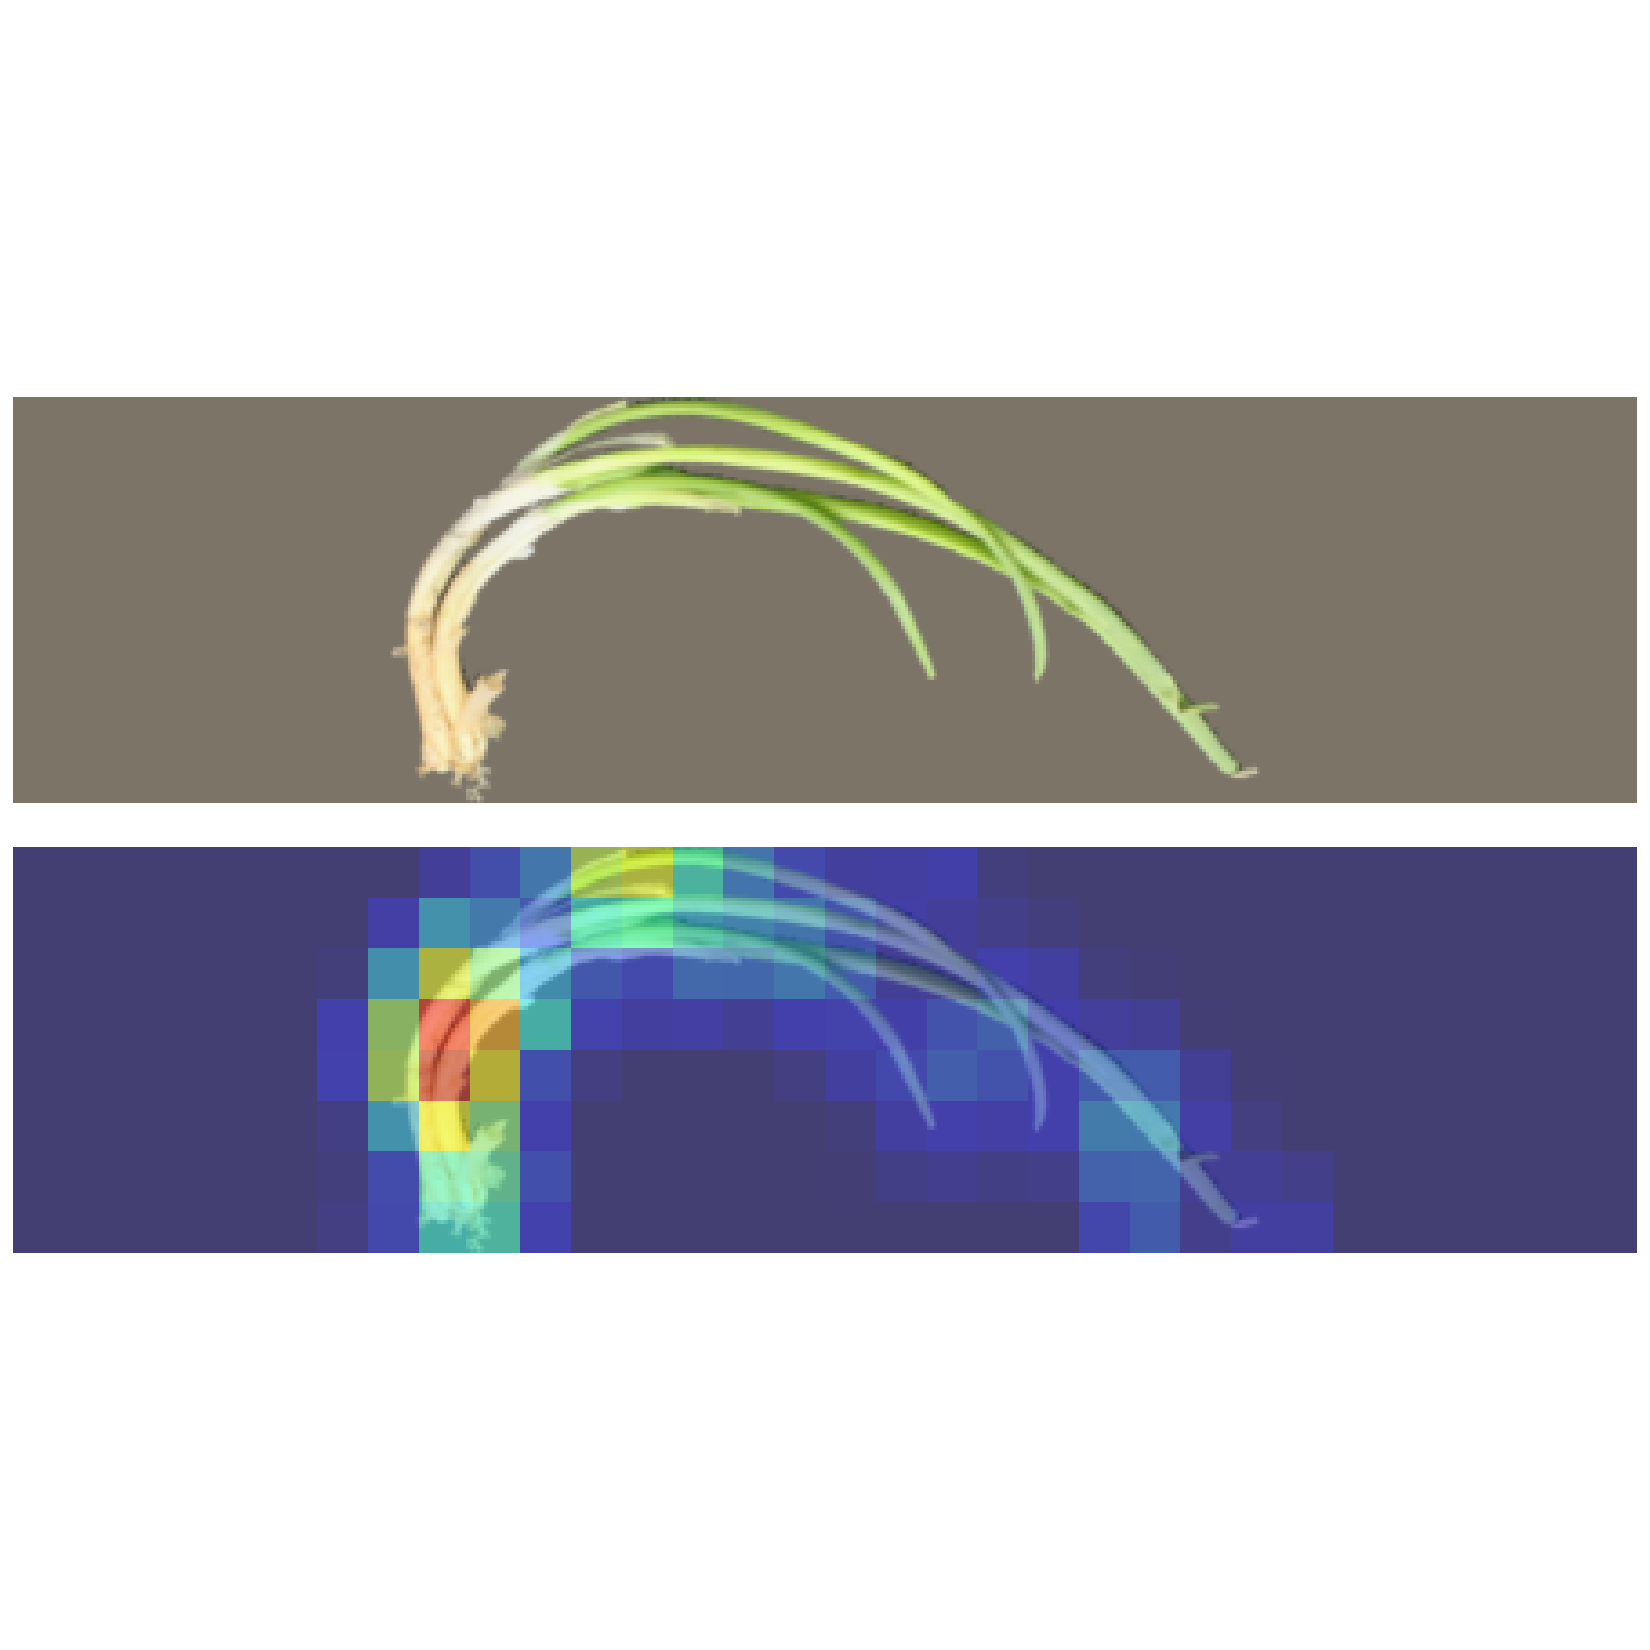

Fig. S3, panel G:
  · test photograph of ANTSRO030 at 14 DAH (Minor defects); CNN-ridge estimate 7.6 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


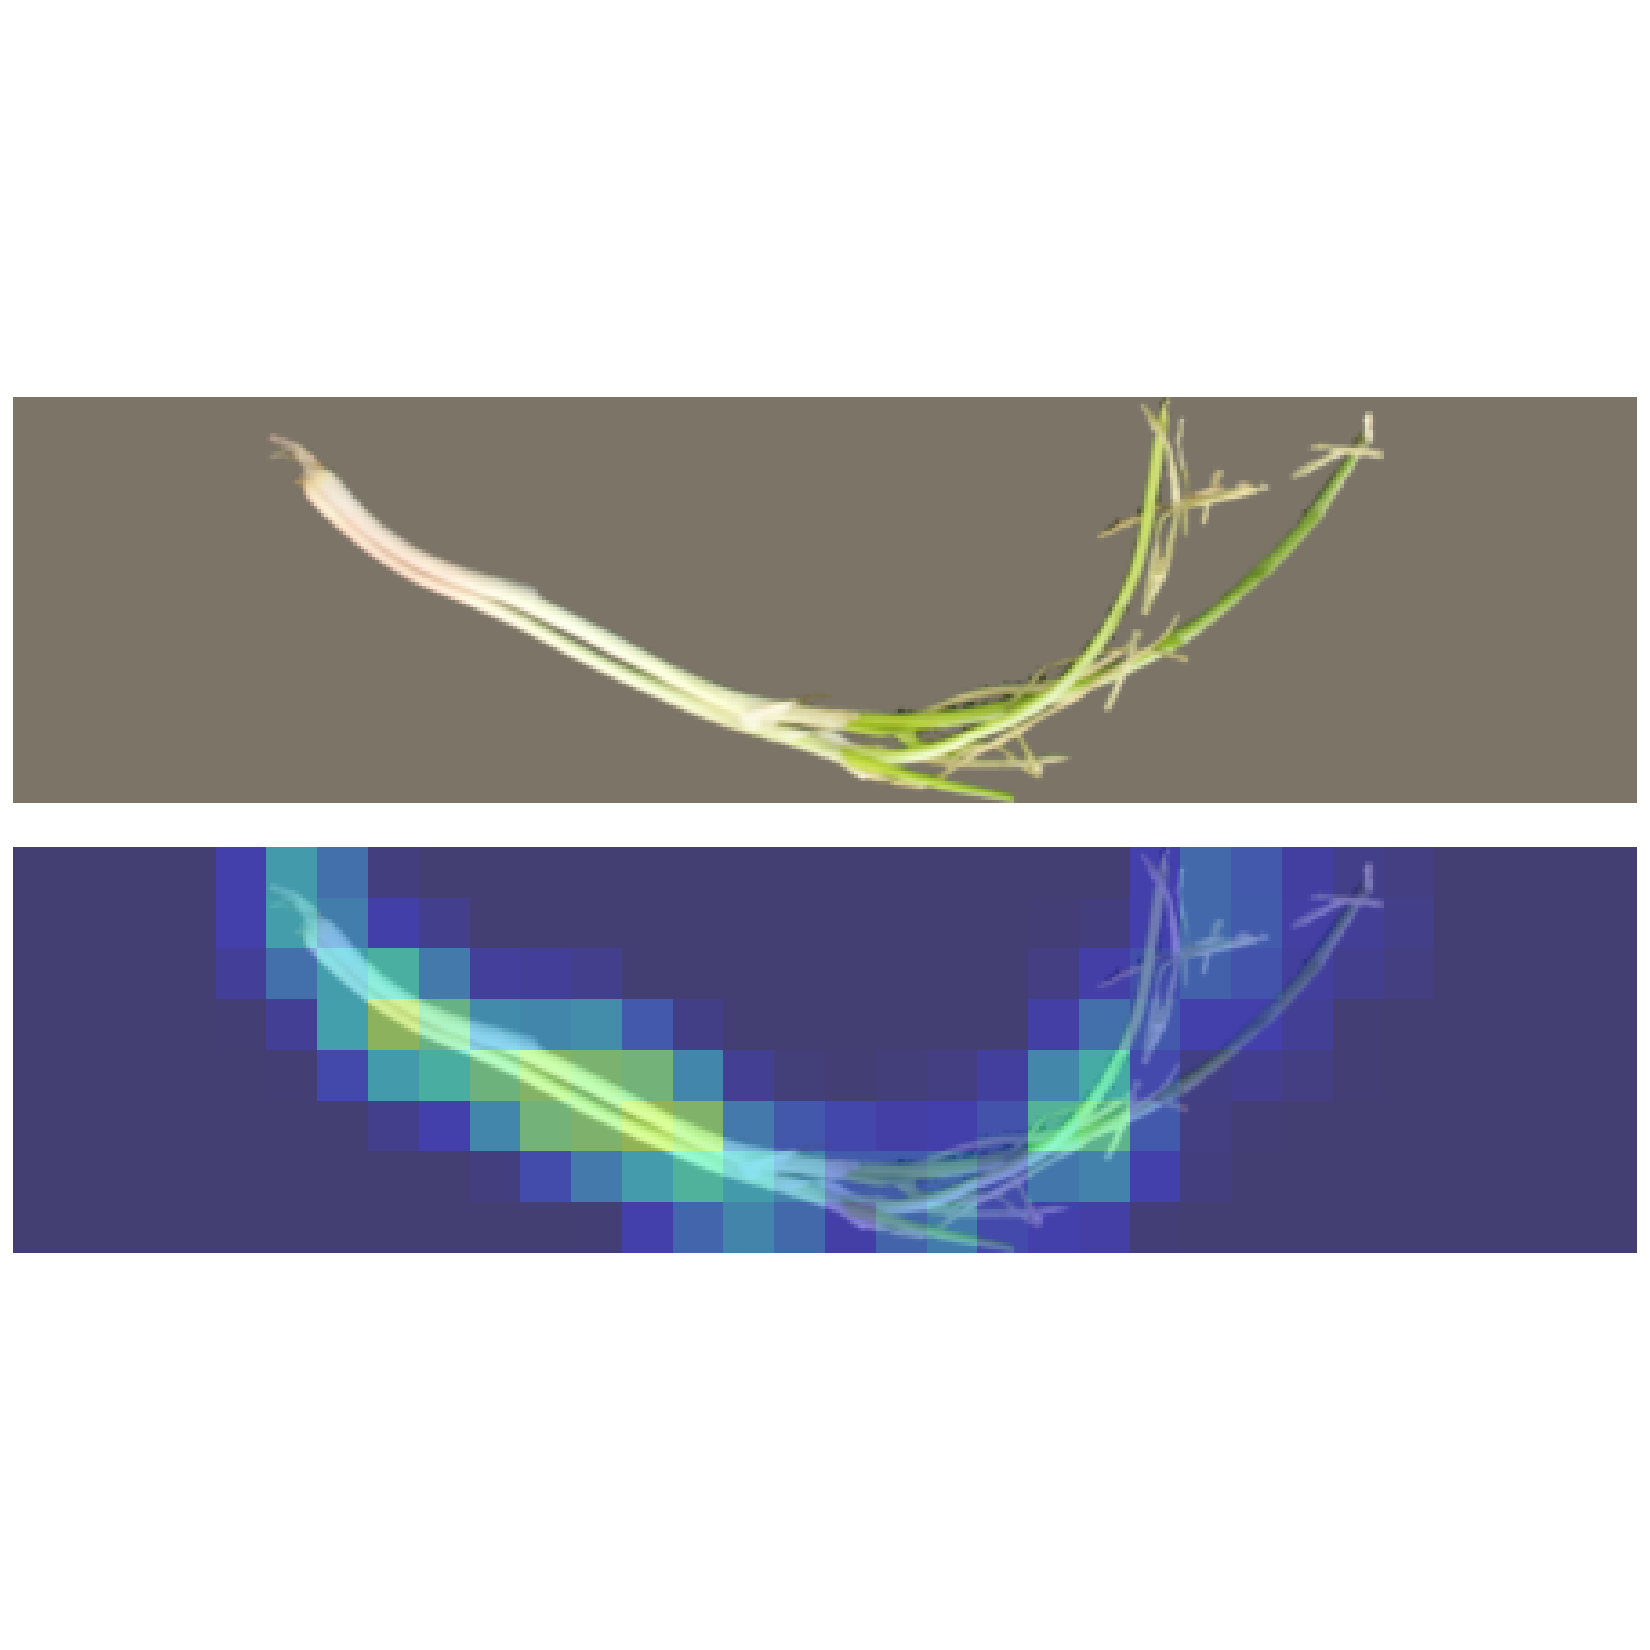

Fig. S3, panel H:
  · test photograph of 91400035 at 14 DAH (On-Grade); CNN-ridge estimate 8.6 d (model trained without this genotype)
  · top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; same colour scale in the eight panels)


In [28]:
OCC = np.load(V2 / "occlusion_v2.npz", allow_pickle=True)
for k in range(len(OCC["picked"])):
    i = int(OCC["picked"][k])
    fig, ax = panel()
    img = OCC["imgs"][k].astype(float) / 255
    heat = OCC["maps"][k] / max(OCC["maps"].max(), 1e-9)
    canvas = np.ones((2 * 112 + 12, 448, 3))
    canvas[:112] = img
    over = img.copy(); hm = plt.get_cmap("jet")(heat)[..., :3]
    canvas[124:] = 0.55 * over + 0.45 * hm
    ax.imshow(canvas); ax.axis("off")
    titulo(ax, f"S3{'ABCDEFGH'[k]}")
    mostrar(fig)
    nota(f"test photograph of {df['geno'].iloc[i]} at {df['dah'].iloc[i]} DAH ({df['class'].iloc[i]}); CNN-ridge estimate "
         f"{OCC['preds'][k]:.1f} d (model trained without this genotype)",
         "top = crop received by the network (base on the left); bottom = occlusion map (red = covering this area changes the estimate most; "
         "same colour scale in the eight panels)")

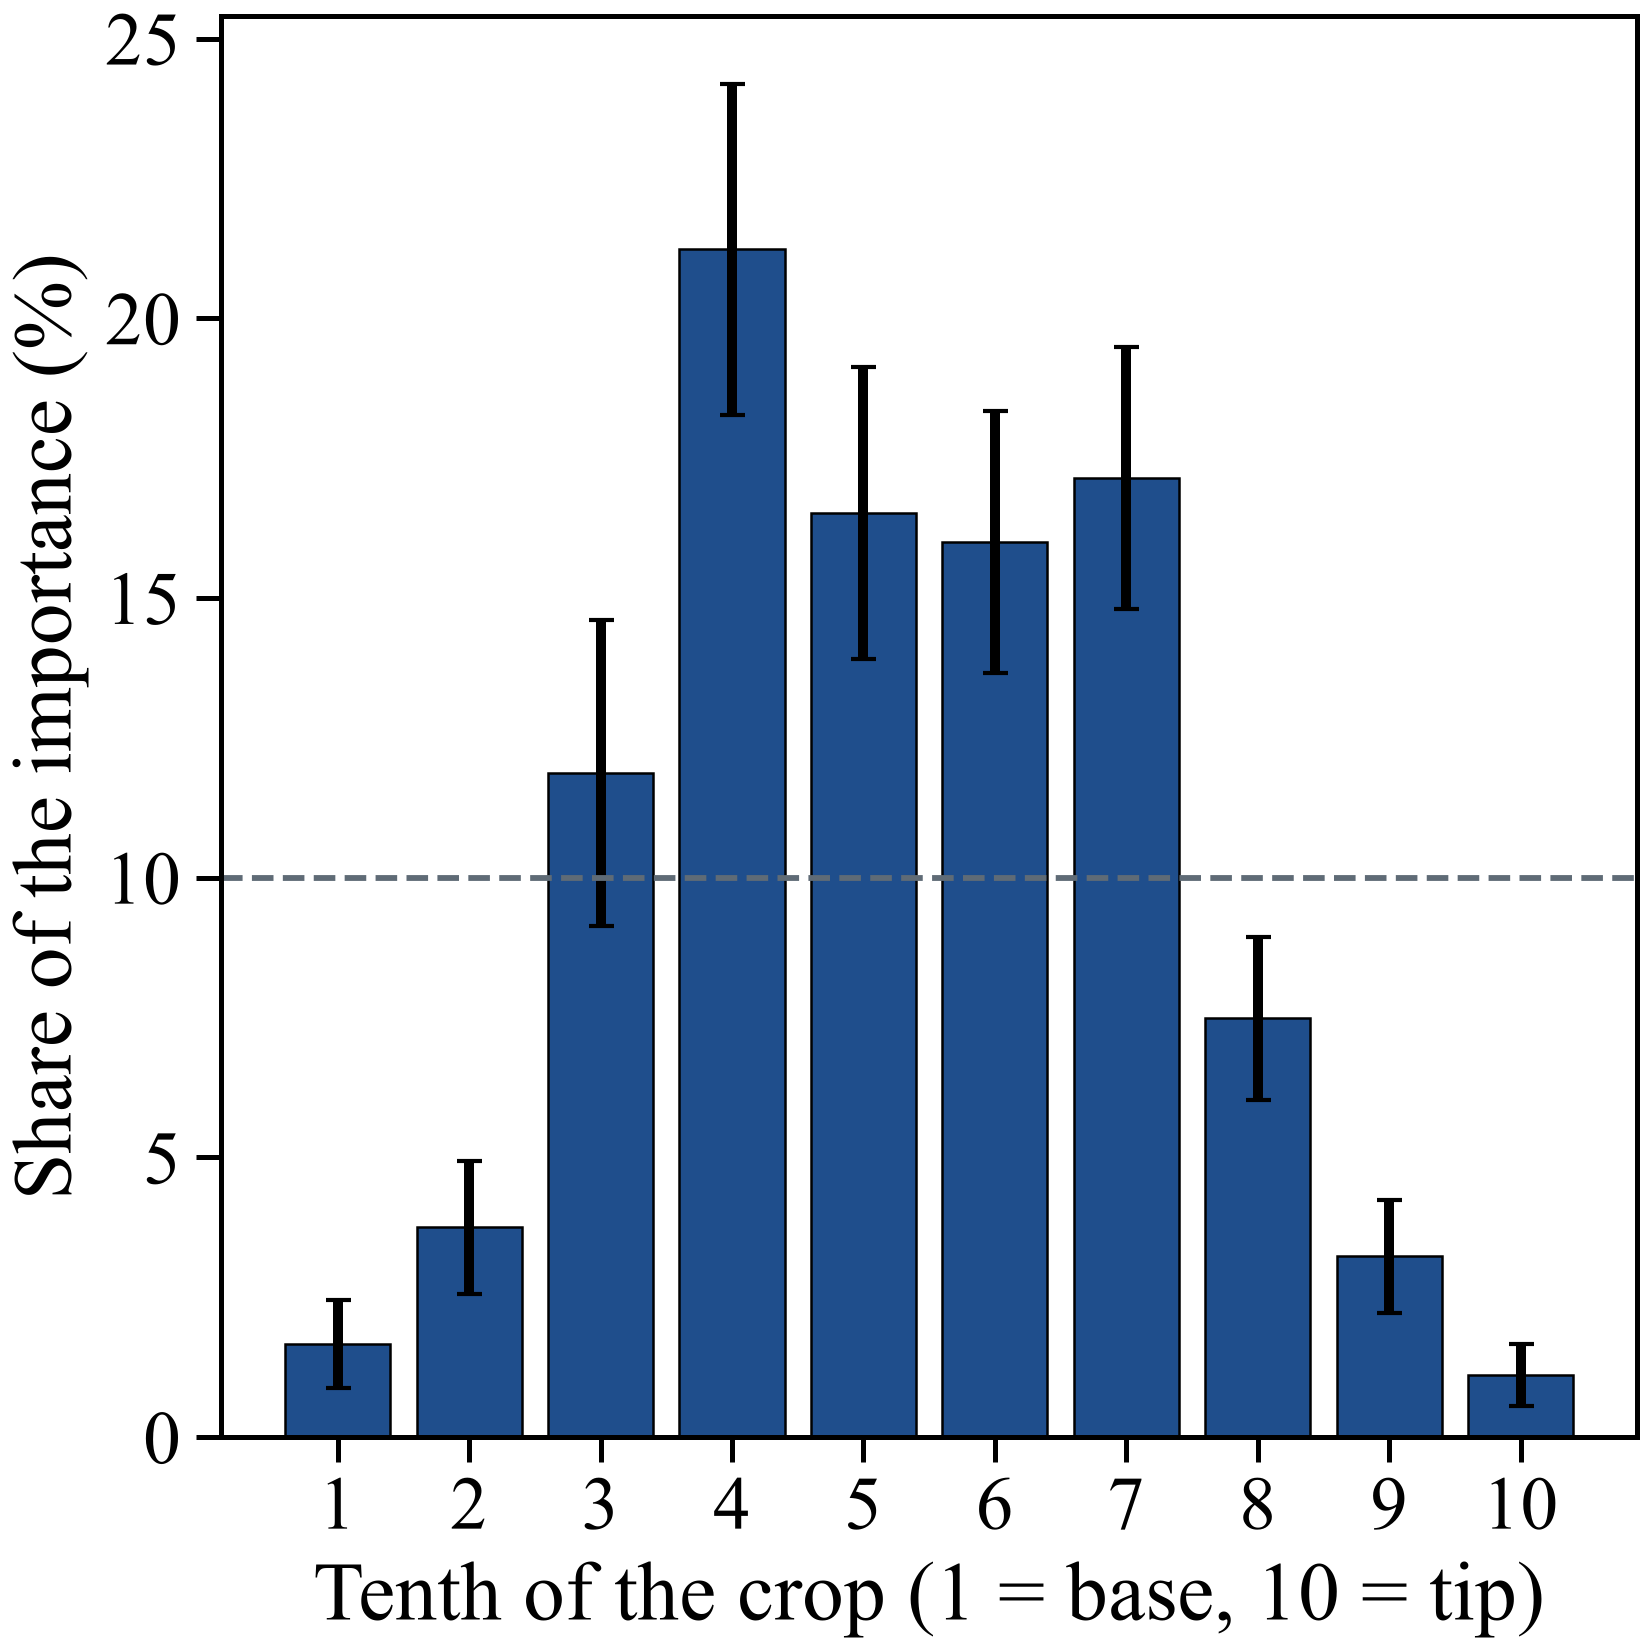

Fig. S3, panel I:
  · mean share of the change in the days-after-harvest estimate when each tenth of the crop is covered (120 test photographs, genotype left out); whiskers = 95% CI of the mean; dashed line = equal share
  · the crops are padded to 4:1, so the first and last tenths can contain background grey in short or curved plants


In [29]:
# ---- Fig. S3I: importancia por décimo del recorte (base → punta)
fig, ax = panel()
sh = OCC["column_share"]
ax.bar(np.arange(1, 11), 100 * sh.mean(0), color="#1F4E8C", edgecolor="black", lw=0.6)
ax.errorbar(np.arange(1, 11), 100 * sh.mean(0), yerr=100 * sh.std(0) / np.sqrt(len(sh)) * 1.96, fmt="none", ecolor="black", capsize=3)
ax.axhline(10, color=MUTED, ls="--", lw=1.4)
ax.set_xticks(range(1, 11)); ax.set_xlabel("Tenth of the crop (1 = base, 10 = tip)"); ax.set_ylabel("Share of the importance (%)")
titulo(ax, "S3I")
mostrar(fig)
nota(f"mean share of the change in the days-after-harvest estimate when each tenth of the crop is covered ({len(sh)} test photographs, "
     "genotype left out); whiskers = 95% CI of the mean; dashed line = equal share",
     "the crops are padded to 4:1, so the first and last tenths can contain background grey in short or curved plants")

**Lectura.** Con el fondo eliminado, los cambios de la estimación al tapar zonas aparecen sobre el tejido: el
pseudotallo y sus curvaturas, la zona donde se separan las hojas y, en algunas fotos, la base. La importancia
se concentra en los décimos centrales del recorte (Fig. S3I), que es donde está la mayor parte de la planta
(los extremos son a menudo relleno gris en plantas cortas o curvas); por eso esta figura no permite comparar
la base con la punta. En una foto (Fig. S3C) se ve un objeto oscuro junto a la planta que la segmentación no
quitó; el mapa no le asigna importancia.

# 7. Limitaciones y ensayo con etiquetas individuales

**Limitaciones de los datos actuales** (no se resuelven con el análisis):
- El **GQI y la vida útil restante son de la celda** genotipo × tiempo, no del pseudotallo fotografiado
  (análisis de laboratorio destructivo sobre otras plantas de la misma cosecha). Por eso se evalúan por celda
  y siempre contra *solo DAH* y *genotipo + DAH*.
- Dentro de cada grupo de fotografía, el **día de captura coincide con el tiempo de almacenamiento**: un cambio de luz o de
  montaje entre días no se puede separar del deterioro con estos datos. P1 por día de captura y P4 (genotipos y días de
  foto no vistos) miden cuánto pesa; la corrección de color con la mesa lo reduce, pero no hubo carta de color.
- **No hay referencia de escala**: el tamaño absoluto (largo, diámetro) no se puede medir en las fotos; los
  descriptores son relativos al largo de la planta.
- Las **clases visuales están balanceadas por diseño** y las asignó quien fotografió (criterio en Métodos);
  no reflejan la frecuencia natural del deterioro.
- La identidad de cada pseudotallo se reconstruyó después (tramos de fotos contiguas); no interviene en la
  validación, que deja fuera sesiones completas.
- La segmentación no siempre incluye las raíces finas ni las puntas de hoja muy delgadas y secas.
- Las fechas EXIF de T2 y T3 no coinciden con 6 y 10 DAH (sección 1.1); se usan los DAH de las carpetas.

**Ensayo con etiquetas individuales.** Para que una foto pronostique **cuántos días le quedan a ese
pseudotallo** antes del rechazo:

- **Pseudotallos marcados** (etiqueta no visible en la foto) de varios genotipos, fotografiados **a diario**
  desde la cosecha hasta su rechazo, con su identificador registrado en cada toma.
- **Rechazo por un panel** que acepta o rechaza cada pseudotallo marcado el día de la foto; el tiempo hasta el
  rechazo es la etiqueta individual (con censura a la derecha si no se rechaza antes del final).
- **Al menos dos temperaturas** de almacenamiento, para que el tiempo desde la cosecha no determine solo el
  estado del producto, y **orden de captura aleatorio** entre genotipos y temperaturas cada día.
- **Fotos con celular en condiciones reales** (luz y fondo de punto de venta), con **carta de color y
  referencia de escala en cada toma**.
- **Modelos de supervivencia** con covariables de la imagen (Cox o tiempo de falla acelerado), y validación
  que deje fuera pseudotallos, días, temperaturas y genotipos completos.

# 8. Tablas del artículo — Material suplementario 6, Tablas 1–3

**Qué responde.** Qué números van al artículo. Las tablas de detalle D1–D14, que salen en la sección donde se
calculan, se resumen en **tres tablas**, en el mismo lugar que el manuscrito ya da a las tablas de la Fase 3
(Material suplementario 6). Los valores son los mismos; aquí solo se reúnen.

| Tabla | Qué reúne | Viene de |
|---|---|---|
| **1. Muestras, etiquetas y fotos por genotipo** | grupo de fotografía, vida útil del consumidor, desde qué tiempo se rechaza, sesiones, fotos válidas y pseudotallos; en las notas, fechas de foto, segmentación, corrección de color y colorímetro | D1–D5 (secciones 1–2) |
| **2. Validación en los cinco protocolos** | cada salida con los tres modelos, + DAH, las referencias y la diferencia frente a solo DAH; en la nota, la estabilidad de P1 | D6, D7, D9 (sección 4) |
| **3. Controles y uso de la estimación** | (a) escalera de fuga junto al control con solo el fondo; (b) decisión de aceptar o rechazar e intervalos conformales; en la nota, el número de pseudotallos | D10–D14 (secciones 3 y 5) |

Quedan solo en el notebook la D8 (cada modelo de la versión anterior, por foto; la Tabla 3a ya hace esa comparación),
el detalle de la segmentación por tiempo y clase (D4) y la sensibilidad y especificidad de cada regla (D12; en la nota
de la Tabla 3 van las de P3). Al final se guarda `tables_v2.pkl`; con él, `scripts/phase3v2_tables_docx.py` escribe
el Word en inglés con las tres tablas y sus notas (`results/Phase3_tables_supplementary_material_6.docx`).

In [30]:
# ---- Tabla 1: muestras, etiquetas y fotos por genotipo (D2 + conteos; notas con D1, D3, D4, D5)
cnt = (df.assign(ok=OK).groupby("geno")
         .agg(photos=("ruta", "size"), valid=("ok", "sum"), sessions=("folder", "nunique"), pseudo=("pseudostem", "nunique")))
H1 = ["Genotype", "Photo group", "Consumer shelf life, t50 (d) [95% CI]", "Shelf life used (d)", "Rejected from (DAH)",
      "Sessions", "Photographs (valid)", "Pseudostems"]
rows = []
for _, r in TABLE_S5B.iterrows():
    g = str(r["Genotype"]); lo, hi = str(r["95% CI (d)"]).split("–"); c = cnt.loc[g]
    rows.append([g, "A" if g in LOT_A else "B", f"{r['t50 online (d)']:.2f} [{lo}, {hi}]", f"{r['Shelf life used (d)']:.2f}",
                 "—" if pd.isna(r["Rejected from (DAH)"]) else str(int(r["Rejected from (DAH)"])), str(int(c["sessions"])), f"{int(c['photos']):,} ({int(c['valid']):,})",
                 str(int(c["pseudo"]))])
rows.append(["Total", "", "", "", "", str(int(cnt["sessions"].sum())),
             f"{int(cnt['photos'].sum()):,} ({int(cnt['valid'].sum()):,})", str(int(cnt["pseudo"].sum()))])
SM6_1 = pd.DataFrame(rows, columns=H1)

# ---- Tabla 2: validación en los cinco protocolos (D6 + Ensemble + DAH + D7; nota con D9)
PROT = [SCHEME_LABEL[s] for s in SCH]


def res_cells(level, t, name, metric):
    x = RES[(RES.level == level) & (RES.output == t) & (RES.model == name)].set_index("scheme")
    return [cellfmt(x.loc[s].to_dict() | {"scheme": s}, metric) for s in SCH]


def d_cells(t, name):
    x = RES[(RES.level == "cell") & (RES.output == t) & (RES.model == name)].set_index("scheme")
    return [fmt_no_ci(x.loc[s, "dR2"]) if s == "P4_lot" else fmt(x.loc[s, "dR2"], x.loc[s, "dR2_ci"]) for s in SCH]


rows = []
for metric, mname in [("acc", "Accuracy"), ("qwk", "Weighted κ")]:
    for m in ["Ensemble", "CTD-GB v2", "CNN-ridge"]:
        rows.append(["Visual class (session)", m, mname] + res_cells("session", "class", m, metric))
for m in ["Ensemble", "CTD-GB v2", "CNN-ridge"]:
    rows.append(["Storage age, DAH (cell)", m, "R²"] + res_cells("cell", "dah", m, "R2"))
for t, lab_ in [("gqi_e2", "GQI (cell)"), ("rsl", "Remaining shelf life (cell)")]:
    for m in ["Ensemble", "CTD-GB v2", "CNN-ridge", "Ensemble + DAH", "DAH only", "Genotype + DAH"]:
        rows.append([lab_, m, "R²"] + res_cells("cell", t, m, "R2"))
    for m, lab_m in [("Ensemble", "Ensemble − DAH only"), ("Ensemble + DAH", "Ensemble + DAH − DAH only")]:
        rows.append([lab_, lab_m, "ΔR²"] + d_cells(t, m))
SM6_2 = pd.DataFrame(rows, columns=["Output (unit of evaluation)", "Model / reference", "Metric"] + PROT)

# ---- Tabla 3a: escalera de fuga (D10) y control con solo el fondo (D14, estadísticas de color)
LADDER_LABEL = {"Random photo": "Random photograph", "Pseudostem": "Pseudostem", "Session": "Session",
                "Block (genotype × time)": "Genotype × time block (P1)", "Capture day": "Capture day (P1 · capture day)",
                "Unseen time (P2)": "Storage time (P2)", "Unseen genotype (P3)": "Genotype (P3)"}
BGCOL = {"Random photo": "Random photographs", "Block (genotype × time)": "Genotype × time block left out",   # el control del fondo dejó fuera bloques, no sesiones
         "Capture day": "Capture day left out"}
bg = TABLE_S14[TABLE_S14["Background features"].str.startswith("Colour")].set_index("Target")
rows = []
for _, r in TABLE_S7D.iterrows():
    p = r["Partition"]
    rows.append([LADDER_LABEL[p]] + [f"{r[c]:.2f}" for c in ["R² DAH, v1", "R² DAH, v2", "R² GQI, v1", "R² GQI, v2", "Accuracy, v1", "Accuracy, v2"]]
                + [f"{bg.loc[t, BGCOL[p]]:.2f}" if p in BGCOL else "—" for t in ["Storage time", "Visual class", "Genotype"]])
SM6_3A = pd.DataFrame(rows, columns=["Unit left out of training", "R² DAH, v1", "R² DAH, v2", "R² GQI, v1", "R² GQI, v2",
                                     "Class accuracy, v1", "Class accuracy, v2", "Background only (v1): storage time",
                                     "Background only (v1): visual class", "Background only (v1): genotype"])

# ---- Tabla 3b: decisión (D12) e intervalos conformales del Ensemble (D13)
dec = TABLE_S8A.set_index(["Protocol", "Decision rule"])
rows = []
for rule in ["Days rule", "Ensemble", "Ensemble + conformal", "Ensemble + DAH", "Genotype + DAH"]:
    rows.append(["Decision: false acceptance / false rejection (% of photographs)", rule] +
                [f"{dec.loc[(p, rule), 'Accepted, should reject (%)']:.1f} / {dec.loc[(p, rule), 'Rejected, acceptable (%)']:.1f}" for p in PROT])
rows.append(["Decision: photographs left to the days rule (%)", "Ensemble + conformal"] +
            [f"{float(dec.loc[(p, 'Ensemble + conformal'), 'Uncertain → days rule (%)']):.1f}" for p in PROT])
cf = TABLE_S8B[TABLE_S8B["Model"] == "Ensemble"].set_index(["Protocol", "Output"])
for out, lab_ in [("Days after harvest (d)", "DAH (d)"), ("GQI", "GQI (points)"), ("Remaining shelf life (d)", "Remaining shelf life (d)")]:
    rows.append(["90% interval: coverage / mean width", lab_] +
                [f"{cf.loc[(p, out), 'Coverage (target 0.90)']:.2f} / {cf.loc[(p, out), 'Mean width']:.1f}" for p in PROT])
SM6_3B = pd.DataFrame(rows, columns=["Quantity", "Rule or output"] + PROT)

for cap, t in [("Table 1. Samples, labels and photographs of each genotype", SM6_1),
               ("Table 2. Validation of the photo models (plant only) and of the metadata references under the five protocols; "
                "95% CI by cluster bootstrap (none in P4)", SM6_2),
               ("Table 3a. Per-photograph performance when the unit left out of training goes from a random photograph to a whole "
                "genotype (v1 = previous version, v2 = plant only), and accuracy of a model that sees only the background (v1)", SM6_3A),
               ("Table 3b. Accept / reject decision and 90% split-conformal prediction intervals of the ensemble", SM6_3B)]:
    print("\n" + cap)
    with pd.option_context("display.max_colwidth", None, "display.width", 250):
        display(t)


Table 1. Samples, labels and photographs of each genotype


,Genotype,Photo group,"Consumer shelf life, t50 (d) [95% CI]",Shelf life used (d),Rejected from (DAH),Sessions,Photographs (valid),Pseudostems
0,91400035,A,"5.37 [4.3, 6.5]",5.37,6,16,"1,711 (1,707)",109
1,NDSCAR038,A,"5.96 [4.6, 7.4]",5.96,6,16,"1,590 (1,590)",88
2,ANTSON013,A,"6.29 [4.8, 7.6]",6.29,10,16,"1,639 (1,638)",112
3,91400071,B,"8.38 [7.0, 10.0]",8.38,10,16,"1,624 (1,624)",87
4,91400070,B,"10.14 [7.1, >14]",10.14,14,16,"1,627 (1,627)",105
5,ANTSRO030,B,"11.29 [9.6, >14]",11.29,14,16,"1,642 (1,642)",96
6,91400028,A,"12.31 [8.5, >14]",12.31,14,16,"1,626 (1,626)",102
7,CUNSBR048,A,"12.80 [9.8, >14]",12.80,14,16,"1,654 (1,651)",106
8,ANTSRO029,B,"14.14 [9.1, >14]",14.00,—,16,"1,643 (1,643)",98
9,ANTSNC003,B,"15.35 [10.9, >14]",14.00,—,16,"1,640 (1,640)",93



Table 2. Validation of the photo models (plant only) and of the metadata references under the five protocols; 95% CI by cluster bootstrap (none in P4)


,Output (unit of evaluation),Model / reference,Metric,P1 · session,P1 · capture day,P2 · unseen time,P3 · unseen genotype,P4 · unseen genotypes and photo days
0,Visual class (session),Ensemble,Accuracy,"0.57 [0.49, 0.65]","0.51 [0.43, 0.57]","0.51 [0.44, 0.57]","0.56 [0.46, 0.66]",0.40
1,Visual class (session),CTD-GB v2,Accuracy,"0.52 [0.45, 0.59]","0.44 [0.38, 0.51]","0.47 [0.40, 0.55]","0.52 [0.45, 0.59]",0.38
2,Visual class (session),CNN-ridge,Accuracy,"0.54 [0.46, 0.62]","0.51 [0.44, 0.59]","0.51 [0.44, 0.57]","0.52 [0.43, 0.61]",0.40
3,Visual class (session),Ensemble,Weighted κ,"0.60 [0.46, 0.72]","0.48 [0.32, 0.62]","0.45 [0.29, 0.59]","0.57 [0.41, 0.73]",0.16
4,Visual class (session),CTD-GB v2,Weighted κ,"0.53 [0.39, 0.65]","0.37 [0.22, 0.51]","0.39 [0.25, 0.54]","0.47 [0.33, 0.61]",0.08
5,Visual class (session),CNN-ridge,Weighted κ,"0.56 [0.44, 0.68]","0.53 [0.39, 0.66]","0.57 [0.45, 0.69]","0.53 [0.38, 0.66]",0.36
6,"Storage age, DAH (cell)",Ensemble,R²,"0.68 [0.57, 0.75]","0.41 [0.29, 0.48]","0.06 [-0.09, 0.13]","0.71 [0.63, 0.78]",0.48
7,"Storage age, DAH (cell)",CTD-GB v2,R²,"0.73 [0.61, 0.80]","0.46 [0.32, 0.54]","0.12 [-0.05, 0.21]","0.76 [0.69, 0.82]",0.53
8,"Storage age, DAH (cell)",CNN-ridge,R²,"0.60 [0.48, 0.68]","0.32 [0.18, 0.41]","-0.03 [-0.20, 0.06]","0.62 [0.53, 0.70]",0.39
9,GQI (cell),Ensemble,R²,"0.67 [0.56, 0.75]","0.58 [0.49, 0.65]","0.58 [0.48, 0.64]","0.57 [0.37, 0.73]",0.08



Table 3a. Per-photograph performance when the unit left out of training goes from a random photograph to a whole genotype (v1 = previous version, v2 = plant only), and accuracy of a model that sees only the background (v1)


,Unit left out of training,"R² DAH, v1","R² DAH, v2","R² GQI, v1","R² GQI, v2","Class accuracy, v1","Class accuracy, v2",Background only (v1): storage time,Background only (v1): visual class,Background only (v1): genotype
0,Random photograph,0.90,0.86,0.90,0.85,0.94,0.96,0.97,0.90,0.93
1,Pseudostem,0.73,0.77,0.74,0.76,0.68,0.79,—,—,—
2,Session,0.58,0.63,0.62,0.63,0.42,0.44,—,—,—
3,Genotype × time block (P1),0.47,0.56,0.55,0.56,0.49,0.50,0.61,0.30,0.05
4,Capture day (P1 · capture day),0.14,0.29,0.33,0.46,0.48,0.47,0.09,0.28,0.14
5,Storage time (P2),-0.25,-0.05,0.26,0.46,0.49,0.48,—,—,—
6,Genotype (P3),0.50,0.59,0.48,0.45,0.48,0.52,—,—,—



Table 3b. Accept / reject decision and 90% split-conformal prediction intervals of the ensemble


,Quantity,Rule or output,P1 · session,P1 · capture day,P2 · unseen time,P3 · unseen genotype,P4 · unseen genotypes and photo days
0,Decision: false acceptance / false rejection (% of photographs),Days rule,15.5 / 5.0,15.5 / 5.0,15.5 / 5.0,15.5 / 5.0,15.5 / 5.0
1,Decision: false acceptance / false rejection (% of photographs),Ensemble,12.6 / 9.2,13.3 / 9.7,16.4 / 9.7,13.7 / 8.5,24.4 / 11.9
2,Decision: false acceptance / false rejection (% of photographs),Ensemble + conformal,15.5 / 5.2,15.5 / 5.0,14.8 / 4.9,15.5 / 5.0,15.6 / 5.1
3,Decision: false acceptance / false rejection (% of photographs),Ensemble + DAH,9.5 / 10.4,8.5 / 11.7,13.3 / 3.4,10.6 / 10.2,12.9 / 15.2
4,Decision: false acceptance / false rejection (% of photographs),Genotype + DAH,0.0 / 0.0,0.0 / 5.0,0.0 / 0.0,15.5 / 17.4,13.0 / 14.9
5,Decision: photographs left to the days rule (%),Ensemble + conformal,83.1,86.6,88.8,84.5,83.2
6,90% interval: coverage / mean width,DAH (d),0.89 / 9.8,0.62 / 9.4,0.57 / 9.8,0.89 / 9.5,0.82 / 10.2
7,90% interval: coverage / mean width,GQI (points),0.86 / 33.5,0.85 / 42.3,0.85 / 36.5,0.89 / 38.6,0.64 / 40.6
8,90% interval: coverage / mean width,Remaining shelf life (d),0.86 / 12.2,0.76 / 12.8,0.71 / 10.5,0.90 / 12.8,0.81 / 12.4


In [31]:
# ---- tablas para el Word en inglés: las tres del artículo y las de detalle que usan sus notas
TABLES = {"SM6_1": SM6_1, "SM6_2": SM6_2, "SM6_3A": SM6_3A, "SM6_3B": SM6_3B,
          "D1": TABLE_S5A, "D2": TABLE_S5B, "D3": TABLE_S5C, "D4": TABLE_S6A.reset_index(), "D5": TABLE_S6B, "D6": TABLE_1,
          "D7": TABLE_S7A, "D8": TABLE_S7B, "D9": TABLE_S7C, "D10": TABLE_S7D, "D11": TABLE_LOT.reset_index(),
          "D12": TABLE_S8A, "D13": TABLE_S8B, "D14": TABLE_S14}
with open(V2 / "tables_v2.pkl", "wb") as fh:
    pickle.dump(TABLES, fh)
print("tablas guardadas en", (V2 / "tables_v2.pkl").relative_to(ROOT) if V2.is_relative_to(ROOT) else V2.name, ":", ", ".join(TABLES))
print("Word: python scripts/phase3v2_tables_docx.py")

tablas guardadas en data\phase3\cache_v2\tables_v2.pkl : SM6_1, SM6_2, SM6_3A, SM6_3B, D1, D2, D3, D4, D5, D6, D7, D8, D9, D10, D11, D12, D13, D14
Word: python scripts/phase3v2_tables_docx.py
